In [1]:
import os

PROJECT_DIR = "/content/EV_MARL_Project"

folders = [
    "01_environment",
    "02_agents",
    "03_training",
    "04_experiments",
    "05_results",
    "06_figures",
    "07_models",
    "08_report",
    "09_presentation"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("EV-MARL project created successfully!\n")

for folder in sorted(os.listdir(PROJECT_DIR)):
    print("✓", folder)

EV-MARL project created successfully!

✓ 01_environment
✓ 02_agents
✓ 03_training
✓ 04_experiments
✓ 05_results
✓ 06_figures
✓ 07_models
✓ 08_report
✓ 09_presentation


In [2]:
import sys
import torch

print("=" * 50)
print("SYSTEM CHECK")
print("=" * 50)

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: Not available")

SYSTEM CHECK
Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
%pip install -q "setuptools<82"

import setuptools
print("Setuptools version:", setuptools.__version__)

Setuptools version: 80.10.2


In [4]:
%pip install -q --only-binary=:all: scikit-learn==1.9.1

import sklearn

print("scikit-learn version:", sklearn.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 61.0 MB/s eta 0:00:00
scikit-learn version: 1.9.1


In [5]:
%pip install -q --no-deps citylearn==3.0.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 549.6/549.6 kB 14.5 MB/s eta 0:00:00


In [6]:
import citylearn
from citylearn.citylearn import CityLearnEnv

print("✅ CityLearn imported successfully!")
print("CityLearn location:", citylearn.__file__)
print("CityLearnEnv:", CityLearnEnv)

✅ CityLearn imported successfully!
CityLearn location: /usr/local/lib/python3.13/dist-packages/citylearn/__init__.py
CityLearnEnv: <class 'citylearn.citylearn.CityLearnEnv'>


In [7]:
from citylearn.citylearn import CityLearnEnv

print("=" * 60)
print("LOADING CITYLEARN EV ENVIRONMENT")
print("=" * 60)

env = CityLearnEnv(
    "citylearn_challenge_2022_phase_all_plus_evs",
    episode_time_steps=24,
    interface="flat",
    render_mode="none",
)

print("✅ Environment created successfully!")
print("Number of action spaces:", len(env.action_space))
print("Number of observation spaces:", len(env.observation_space))

env.close()

INFO:root:The dataset names DNE in cache. Will download from citylearn-project/CityLearn/tree/v3.0.2 GitHub repository and write to /root/.cache/citylearn/v3.0.2/dataset_names.json. Next time DataSet.get_dataset_names is called, it will read from cache unless DataSet.clear_cache is run first.


LOADING CITYLEARN EV ENVIRONMENT


INFO:root:The citylearn_challenge_2022_phase_all_plus_evs dataset DNE in cache/local roots. Will download from citylearn-project/CityLearn/tree/v3.0.2 GitHub repository and write to /root/.cache/citylearn/v3.0.2/datasets. Next time DataSet.get_dataset('citylearn_challenge_2022_phase_all_plus_evs') is called, it will read from cache unless DataSet.clear_cache is run first.


✅ Environment created successfully!
Number of action spaces: 17
Number of observation spaces: 17


In [8]:
print("=" * 70)
print("CITYLEARN ENVIRONMENT STRUCTURE")
print("=" * 70)

print("\nEnvironment type:")
print(type(env))

print("\nNumber of buildings:")
print(len(env.buildings))

print("\nBuildings:")
for i, building in enumerate(env.buildings):
    print(f"{i}: {building.name}")

print("\nAction spaces:")
for i, space in enumerate(env.action_space):
    print(f"{i}: {space}")

print("\nObservation spaces:")
for i, space in enumerate(env.observation_space):
    print(f"{i}: {space}")

CITYLEARN ENVIRONMENT STRUCTURE

Environment type:
<class 'citylearn.citylearn.CityLearnEnv'>

Number of buildings:
17

Buildings:
0: Building_1
1: Building_2
2: Building_3
3: Building_4
4: Building_5
5: Building_6
6: Building_7
7: Building_8
8: Building_9
9: Building_10
10: Building_11
11: Building_12
12: Building_13
13: Building_14
14: Building_15
15: Building_16
16: Building_17

Action spaces:
0: Box([-1. -1.  0.], 1.0, (3,), float32)
1: Box(-1.0, 1.0, (1,), float32)
2: Box(-1.0, 1.0, (1,), float32)
3: Box(-1.0, 1.0, (2,), float32)
4: Box(-1.0, 1.0, (2,), float32)
5: Box(-1.0, 1.0, (1,), float32)
6: Box(-1.0, 1.0, (2,), float32)
7: Box(-1.0, 1.0, (1,), float32)
8: Box(-1.0, 1.0, (1,), float32)
9: Box(-1.0, 1.0, (2,), float32)
10: Box(-1.0, 1.0, (1,), float32)
11: Box(-1.0, 1.0, (2,), float32)
12: Box(-1.0, 1.0, (1,), float32)
13: Box(-1.0, 1.0, (1,), float32)
14: Box(-1.0, 1.0, (3,), float32)
15: Box(-1.0, 1.0, (1,), float32)
16: Box(-1.0, 1.0, (1,), float32)

Observation spaces:
0:

In [9]:
print("=" * 70)
print("EV COMPONENT INSPECTION")
print("=" * 70)

for i, building in enumerate(env.buildings):
    print(f"\n{'='*50}")
    print(f"BUILDING {i}: {building.name}")
    print(f"{'='*50}")

    # Check building attributes that contain EV-related information
    ev_attributes = [
        attr for attr in dir(building)
        if "ev" in attr.lower()
    ]

    print("EV-related attributes:")
    print(ev_attributes)

    # Print their values where possible
    for attr in ev_attributes:
        try:
            value = getattr(building, attr)
            print(f"  {attr}: {value}")
        except Exception as e:
            print(f"  {attr}: <unable to read>")

EV COMPONENT INSPECTION

BUILDING 0: Building_1
EV-related attributes:
['_Building__cooling_device', '_Building__dhw_device', '_Building__energy_from_cooling_device', '_Building__energy_from_dhw_device', '_Building__energy_from_heating_device', '_Building__heating_device', '_Building__non_shiftable_load_device', '_ev_time_observation_high_limit', 'autosize_cooling_device', 'autosize_dhw_device', 'autosize_heating_device', 'cooling_device', 'cooling_device_cop', 'dhw_device', 'dhw_device_cop', 'energy_from_cooling_device', 'energy_from_cooling_device_to_cooling_storage', 'energy_from_dhw_device', 'energy_from_dhw_device_to_dhw_storage', 'energy_from_heating_device', 'energy_from_heating_device_to_heating_storage', 'heating_device', 'heating_device_cop', 'non_shiftable_load_device', 'update_energy_from_cooling_device', 'update_energy_from_dhw_device', 'update_energy_from_heating_device', 'update_ev_charger_observations']
  _Building__cooling_device: <citylearn.energy_model.HeatPump objec

In [10]:
print("=" * 70)
print("ACTUAL EV CHARGER INSPECTION")
print("=" * 70)

for i, building in enumerate(env.buildings):
    print(f"\n{'='*60}")
    print(f"BUILDING {i}: {building.name}")
    print(f"{'='*60}")

    # Find charger-related attributes
    charger_attrs = [
        attr for attr in dir(building)
        if "charger" in attr.lower() or "ev" in attr.lower()
    ]

    for attr in charger_attrs:
        try:
            value = getattr(building, attr)

            # Avoid printing huge arrays
            if hasattr(value, "shape"):
                print(f"{attr}: type={type(value).__name__}, shape={value.shape}")
            elif isinstance(value, (list, tuple)):
                print(f"{attr}: type={type(value).__name__}, length={len(value)}")
            else:
                print(f"{attr}: {value}")

        except Exception as e:
            print(f"{attr}: <error: {e}>")

ACTUAL EV CHARGER INSPECTION

BUILDING 0: Building_1
_Building__chargers_electricity_consumption: type=ndarray, shape=(24,)
_Building__cooling_device: <citylearn.energy_model.HeatPump object at 0x7fcdcc3ab8c0>
_Building__dhw_device: <citylearn.energy_model.ElectricHeater object at 0x7fcdcc3ab770>
_Building__electric_vehicle_chargers: type=list, length=1
_Building__energy_from_cooling_device: type=ndarray, shape=(24,)
_Building__energy_from_dhw_device: type=ndarray, shape=(24,)
_Building__energy_from_heating_device: type=ndarray, shape=(24,)
_Building__heating_device: <citylearn.energy_model.HeatPump object at 0x7fcdcc3e5450>
_Building__non_shiftable_load_device: <citylearn.energy_model.ElectricDevice object at 0x7fcdcc3aba10>
_building_charger_limit_kw: None
_charger_lookup: {'charger_1_1': <citylearn.electric_vehicle_charger.Charger object at 0x7fcdcc3aaf90>}
_charger_phase_map: {}
_ev_time_observation_high_limit: <bound method Building._ev_time_observation_high_limit of <citylearn.bu

In [11]:
print("=" * 70)
print("DETAILED CHARGER OBJECT INSPECTION")
print("=" * 70)

for i, building in enumerate(env.buildings):
    chargers = building.electric_vehicle_chargers

    if len(chargers) == 0:
        continue

    print(f"\n{'='*60}")
    print(f"BUILDING {i}: {building.name}")
    print(f"Number of chargers: {len(chargers)}")
    print(f"{'='*60}")

    for j, charger in enumerate(chargers):
        print(f"\n--- Charger {j} ---")
        print("Type:", type(charger))
        print("Name:", getattr(charger, "name", "N/A"))

        attrs = [
            a for a in dir(charger)
            if not a.startswith("__")
            and not callable(getattr(charger, a, None))
        ]

        for attr in attrs:
            try:
                value = getattr(charger, attr)

                if hasattr(value, "shape"):
                    print(f"{attr}: ndarray shape={value.shape}, sample={value[:5]}")
                elif isinstance(value, (list, tuple)):
                    print(f"{attr}: {type(value).__name__}, length={len(value)}, value={value[:5]}")
                else:
                    print(f"{attr}: {value}")

            except Exception as e:
                print(f"{attr}: <error: {e}>")

DETAILED CHARGER OBJECT INSPECTION

BUILDING 0: Building_1
Number of chargers: 1

--- Charger 0 ---
Type: <class 'citylearn.electric_vehicle_charger.Charger'>
Name: N/A
DEFAULT_RANDOM_SEED_RANGE: tuple, length=2, value=(0, 100000000)
DEFAULT_SECONDS_PER_TIME_STEP: 3600.0
_Charger__charge_efficiency_curve: None
_Charger__charger_id: charger_1_1
_Charger__charger_simulation: <citylearn.data.ChargerSimulation object at 0x7fcdcc3a9fd0>
_Charger__connected_ev: {'name': 'Electric_Vehicle_7', 'Battery capacity': 60, 'electric_vehicle_soc': np.float32(0.25)}
_Charger__discharge_efficiency_curve: None
_Charger__efficiency: 0.95
_Charger__electricity_consumption: ndarray shape=(24,), sample=[0. 0. 0. 0. 0.]
_Charger__incoming_ev: None
_Charger__max_charging_power: 11
_Charger__max_discharging_power: 7.2
_Charger__min_charging_power: 1.4
_Charger__min_discharging_power: 0.0
_Charger__past_charging_action_values_kwh: ndarray shape=(24,), sample=[0. 0. 0. 0. 0.]
_Charger__past_connected_evs: list, 

In [12]:
print("=" * 70)
print("ELECTRIC VEHICLE OBJECT INSPECTION")
print("=" * 70)

seen_evs = set()

for i, building in enumerate(env.buildings):

    for charger in building.electric_vehicle_chargers:

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        # Avoid inspecting the same EV twice
        ev_name = getattr(ev, "name", None)

        if ev_name in seen_evs:
            continue

        seen_evs.add(ev_name)

        print(f"\n{'='*60}")
        print(f"BUILDING: {building.name}")
        print(f"EV: {ev_name}")
        print(f"{'='*60}")

        print("Object type:", type(ev))

        attrs = [
            a for a in dir(ev)
            if not a.startswith("__")
        ]

        for attr in attrs:
            try:
                value = getattr(ev, attr)

                if callable(value):
                    continue

                if hasattr(value, "shape"):
                    print(
                        f"{attr}: ndarray "
                        f"shape={value.shape}, "
                        f"sample={value[:5]}"
                    )

                elif isinstance(value, (list, tuple)):
                    print(
                        f"{attr}: "
                        f"{type(value).__name__}, "
                        f"length={len(value)}, "
                        f"value={value[:5]}"
                    )

                else:
                    print(f"{attr}: {value}")

            except Exception as e:
                print(f"{attr}: <error: {e}>")

print("\nTotal unique EVs inspected:", len(seen_evs))

ELECTRIC VEHICLE OBJECT INSPECTION

BUILDING: Building_1
EV: Electric_Vehicle_7
Object type: <class 'citylearn.electric_vehicle.ElectricVehicle'>
DEFAULT_RANDOM_SEED_RANGE: tuple, length=2, value=(0, 100000000)
DEFAULT_SECONDS_PER_TIME_STEP: 3600.0
_ElectricVehicle__battery: <citylearn.energy_model.Battery object at 0x7fcdcc3eec60>
_ElectricVehicle__name: Electric_Vehicle_7
_ElectricVehicle__observation_epsilon: 0.0
_Environment__episode_tracker: <citylearn.base.EpisodeTracker object at 0x7fcdcc3aaba0>
_Environment__random_seed: 2022
_Environment__seconds_per_time_step: 3600
_Environment__time_step: 0
_Environment__time_step_ratio: <error: invalid index to scalar variable.>
_Environment__uid: 40f024c2f15c4b0da88cf9f4735f164a
battery: <citylearn.energy_model.Battery object at 0x7fcdcc3eec60>
episode_tracker: <citylearn.base.EpisodeTracker object at 0x7fcdcc3aaba0>
name: Electric_Vehicle_7
numpy_random_state: RandomState(MT19937)
random_seed: 2022
seconds_per_time_step: 3600
time_step: 0

In [13]:
print("=" * 70)
print("BATTERY OBJECT INSPECTION")
print("=" * 70)

seen_batteries = set()

for i, building in enumerate(env.buildings):

    for charger in building.electric_vehicle_chargers:

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        battery = ev.battery

        # Avoid duplicate battery inspection
        battery_id = id(battery)

        if battery_id in seen_batteries:
            continue

        seen_batteries.add(battery_id)

        print(f"\n{'='*60}")
        print(f"BUILDING: {building.name}")
        print(f"EV: {ev.name}")
        print(f"{'='*60}")

        print("Battery object type:", type(battery))

        attrs = [
            a for a in dir(battery)
            if not a.startswith("__")
        ]

        for attr in attrs:
            try:
                value = getattr(battery, attr)

                if callable(value):
                    continue

                if hasattr(value, "shape"):
                    print(
                        f"{attr}: ndarray "
                        f"shape={value.shape}, "
                        f"sample={value[:5]}"
                    )

                elif isinstance(value, (list, tuple)):
                    print(
                        f"{attr}: "
                        f"{type(value).__name__}, "
                        f"length={len(value)}, "
                        f"value={value[:5]}"
                    )

                else:
                    print(f"{attr}: {value}")

            except Exception as e:
                print(f"{attr}: <error: {e}>")

print("\nTotal unique batteries inspected:", len(seen_batteries))

BATTERY OBJECT INSPECTION

BUILDING: Building_1
EV: Electric_Vehicle_7
Battery object type: <class 'citylearn.energy_model.Battery'>
DEFAULT_RANDOM_SEED_RANGE: tuple, length=2, value=(0, 100000000)
DEFAULT_SECONDS_PER_TIME_STEP: 3600.0
_Battery__capacity_loss_coefficient: 1.0842275242698823e-05
_Battery__capacity_power_curve: ndarray shape=(2, 3), sample=[[0.         0.75093586 1.        ]
 [0.95046793 0.90046793 0.20093586]]
_Battery__depth_of_discharge: 0.8
_Battery__power_efficiency_curve: ndarray shape=(2, 5), sample=[[0.         0.25093586 0.65093586 0.75093586 1.        ]
 [0.76605787 0.81109531 0.88290231 0.90074869 0.85596415]]
_Battery__time_step_ratio: <error: invalid index to scalar variable.>
_Device__efficiency: 0.9007486891046212
_ElectricDevice__electricity_consumption: ndarray shape=(24,), sample=[0. 0. 0. 0. 0.]
_ElectricDevice__nominal_power: 50
_Environment__episode_tracker: <citylearn.base.EpisodeTracker object at 0x7fcdcc3aaba0>
_Environment__random_seed: 2022
_Env

In [14]:
import numpy as np

print("=" * 70)
print("CITYLEARN OBSERVATION DECODING")
print("=" * 70)

# Reset environment
observations, info = env.reset(seed=0)

print("\nNumber of agents:", len(observations))

for i, obs in enumerate(observations):

    print(f"\n{'='*60}")
    print(f"AGENT / BUILDING {i}")
    print(f"{'='*60}")

    print("Observation type:", type(obs))
    print("Observation shape:", np.asarray(obs).shape)
    print("Observation length:", len(obs))

    print("\nObservation values:")
    print(np.asarray(obs))

    # Try to identify the corresponding observation space
    try:
        space = env.observation_space[i]

        print("\nObservation space:")
        print(space)

        print("\nObservation space low:")
        print(np.asarray(space.low))

        print("\nObservation space high:")
        print(np.asarray(space.high))

    except Exception as e:
        print("Observation space inspection error:", e)

print("\n" + "=" * 70)
print("OBSERVATION DECODING COMPLETE")
print("=" * 70)

CITYLEARN OBSERVATION DECODING

Number of agents: 17

AGENT / BUILDING 0
Observation type: <class 'list'>
Observation shape: (52,)
Observation length: 52

Observation values:
[ 8.00000000e+00  1.00000000e+00  0.00000000e+00  2.00000000e+01
  1.82999992e+01  2.27999992e+01  2.00000000e+01  8.40000000e+01
  8.10000000e+01  6.80000000e+01  8.10000000e+01  0.00000000e+00
  2.50000000e+01  9.64000000e+02  0.00000000e+00  0.00000000e+00
  1.00000000e+02  8.15000000e+02  0.00000000e+00  1.70724407e-01
  2.27579999e+00  0.00000000e+00  0.00000000e+00  2.27579999e+00
  1.64639995e-01  1.50150001e-01  1.39009997e-01  1.53950006e-01
  1.00000000e+00  1.20000000e+01  8.70000005e-01  2.50000000e-01
  6.00000000e+01  0.00000000e+00 -1.00000000e+00  1.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00
  3.00000000e+00  3.00000000e+00  3.00000000e+00  3.00000000e+00
  3.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00
  3.15700000e+00  3.15700000e+00  0.00000000e

In [15]:
print("=" * 70)
print("CITYLEARN OBSERVATION NAME MAPPING")
print("=" * 70)

for i, building in enumerate(env.buildings):

    print(f"\n{'='*60}")
    print(f"BUILDING {i}: {building.name}")
    print(f"{'='*60}")

    try:
        names = building.observation_names

        print("Observation names:")
        for j, name in enumerate(names):
            print(f"{j:2d}: {name}")

    except Exception as e:
        print("observation_names unavailable:", e)

print("\n" + "=" * 70)

CITYLEARN OBSERVATION NAME MAPPING

BUILDING 0: Building_1
observation_names unavailable: 'Building' object has no attribute 'observation_names'

BUILDING 1: Building_2
observation_names unavailable: 'Building' object has no attribute 'observation_names'

BUILDING 2: Building_3
observation_names unavailable: 'Building' object has no attribute 'observation_names'

BUILDING 3: Building_4
observation_names unavailable: 'Building' object has no attribute 'observation_names'

BUILDING 4: Building_5
observation_names unavailable: 'Building' object has no attribute 'observation_names'

BUILDING 5: Building_6
observation_names unavailable: 'Building' object has no attribute 'observation_names'

BUILDING 6: Building_7
observation_names unavailable: 'Building' object has no attribute 'observation_names'

BUILDING 7: Building_8
observation_names unavailable: 'Building' object has no attribute 'observation_names'

BUILDING 8: Building_9
observation_names unavailable: 'Building' object has no attri

In [16]:
print("=" * 70)
print("OBSERVATION SPACE STRUCTURE INSPECTION")
print("=" * 70)

print("\nEnvironment observation space type:")
print(type(env.observation_space))

print("\nEnvironment observation space:")
print(env.observation_space)

print("\nEnvironment attributes containing 'observation':")

for attr in dir(env):
    if "observation" in attr.lower():
        try:
            value = getattr(env, attr)
            print(f"\n{attr}")
            print("  type:", type(value))

            if not callable(value):
                print("  value:", value)
        except Exception as e:
            print(f"  <error: {e}>")

print("\n" + "=" * 70)

OBSERVATION SPACE STRUCTURE INSPECTION

Environment observation space type:
<class 'list'>

Environment observation space:
[Box([ 1.000000e+00  1.000000e+00  0.000000e+00  5.600000e+00  5.600000e+00
  5.600000e+00  5.600000e+00  1.000000e+01  1.000000e+01  1.000000e+01
  1.000000e+01  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  7.038287e-02
  5.700000e-02  0.000000e+00  0.000000e+00 -1.624270e+01  3.000000e-05
  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00 -1.000000e+00
 -1.000000e-01 -1.000000e-01 -1.000000e+00  0.000000e+00 -1.000000e+00
 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00
 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00
 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00 -1.000000e+00
 -1.000000e+00 -1.000000e+00], [1.2000000e+01 7.0000000e+00 2.4000000e+01 3.2200001e+01 3.2200001e+01
 3.2200001e+01 3.2200001e+01 1.0000000e+02 1.0000000e+02 1.0

In [17]:
import inspect

print("=" * 70)
print("CITYLEARN OBSERVATION CONSTRUCTION METHODS")
print("=" * 70)

print("\nMethods in CityLearnEnv containing 'observation':")

for name in dir(env):
    if "observation" in name.lower():
        try:
            obj = getattr(env, name)
            print(f"\n{name}")
            print("Type:", type(obj))

            if callable(obj):
                try:
                    print(inspect.signature(obj))
                except:
                    pass
        except Exception as e:
            print(f"{name}: <error: {e}>")

print("\n" + "=" * 70)

CITYLEARN OBSERVATION CONSTRUCTION METHODS

Methods in CityLearnEnv containing 'observation':

_CityLearnEnv__shared_observations
Type: <class 'list'>

_get_flat_observation_space
Type: <class 'method'>
() -> List[gymnasium.spaces.box.Box]

_observations_cache
Type: <class 'list'>

_observations_cache_time_step
Type: <class 'int'>

_shared_observations_set
Type: <class 'set'>

check_observation_limits
Type: <class 'bool'>

flat_observation_space
Type: <class 'list'>

get_default_shared_observations
Type: <class 'function'>
() -> List[str]

observation_names
Type: <class 'list'>

observation_space
Type: <class 'list'>

observations
Type: <class 'list'>

shared_observations
Type: <class 'list'>



In [18]:
print("=" * 70)
print("CITYLEARN OFFICIAL OBSERVATION NAMES")
print("=" * 70)

print("\nType:", type(env.observation_names))
print("\nObservation names:")

for i, names in enumerate(env.observation_names):
    print(f"\n{'='*50}")
    print(f"AGENT / BUILDING {i}: {env.buildings[i].name}")
    print(f"{'='*50}")

    for j, name in enumerate(names):
        print(f"{j:2d}: {name}")

print("\n" + "=" * 70)
print("SHARED OBSERVATIONS")
print("=" * 70)

print(env.shared_observations)

print("\n" + "=" * 70)

CITYLEARN OFFICIAL OBSERVATION NAMES

Type: <class 'list'>

Observation names:

AGENT / BUILDING 0: Building_1
 0: month
 1: day_type
 2: hour
 3: outdoor_dry_bulb_temperature
 4: outdoor_dry_bulb_temperature_predicted_1
 5: outdoor_dry_bulb_temperature_predicted_2
 6: outdoor_dry_bulb_temperature_predicted_3
 7: outdoor_relative_humidity
 8: outdoor_relative_humidity_predicted_1
 9: outdoor_relative_humidity_predicted_2
10: outdoor_relative_humidity_predicted_3
11: diffuse_solar_irradiance
12: diffuse_solar_irradiance_predicted_1
13: diffuse_solar_irradiance_predicted_2
14: diffuse_solar_irradiance_predicted_3
15: direct_solar_irradiance
16: direct_solar_irradiance_predicted_1
17: direct_solar_irradiance_predicted_2
18: direct_solar_irradiance_predicted_3
19: carbon_intensity
20: non_shiftable_load
21: solar_generation
22: electrical_storage_soc
23: net_electricity_consumption
24: electricity_pricing
25: electricity_pricing_predicted_1
26: electricity_pricing_predicted_2
27: electrici

In [19]:
print("=" * 70)
print("CITYLEARN ACTION SPACE MAPPING")
print("=" * 70)

for i, building in enumerate(env.buildings):

    print(f"\n{'='*60}")
    print(f"BUILDING {i}: {building.name}")
    print(f"{'='*60}")

    print("Action space:")
    print(env.action_space[i])

    print("Action dimension:")
    print(env.action_space[i].shape)

    print("Low:")
    print(env.action_space[i].low)

    print("High:")
    print(env.action_space[i].high)

    print("\nBuilding controllable components:")

    for attr in [
        "electric_vehicle_chargers",
        "electrical_storage",
        "chargers",
        "storage",
        "deferrable_loads"
    ]:
        if hasattr(building, attr):
            try:
                value = getattr(building, attr)

                if isinstance(value, (list, tuple)):
                    print(f"  {attr}: {len(value)} item(s)")
                    for item in value:
                        print(f"      - {getattr(item, 'name', type(item).__name__)}")
                else:
                    print(f"  {attr}: {type(value).__name__}")

            except Exception as e:
                print(f"  {attr}: <error: {e}>")

print("\n" + "=" * 70)

CITYLEARN ACTION SPACE MAPPING

BUILDING 0: Building_1
Action space:
Box([-1. -1.  0.], 1.0, (3,), float32)
Action dimension:
(3,)
Low:
[-1. -1.  0.]
High:
[1. 1. 1.]

Building controllable components:
  electric_vehicle_chargers: 1 item(s)
      - Charger
  electrical_storage: Battery

BUILDING 1: Building_2
Action space:
Box(-1.0, 1.0, (1,), float32)
Action dimension:
(1,)
Low:
[-1.]
High:
[1.]

Building controllable components:
  electric_vehicle_chargers: 0 item(s)
  electrical_storage: Battery

BUILDING 2: Building_3
Action space:
Box(-1.0, 1.0, (1,), float32)
Action dimension:
(1,)
Low:
[-1.]
High:
[1.]

Building controllable components:
  electric_vehicle_chargers: 0 item(s)
  electrical_storage: Battery

BUILDING 3: Building_4
Action space:
Box(-1.0, 1.0, (2,), float32)
Action dimension:
(2,)
Low:
[-1. -1.]
High:
[1. 1.]

Building controllable components:
  electric_vehicle_chargers: 1 item(s)
      - Charger
  electrical_storage: Battery

BUILDING 4: Building_5
Action space:
B

In [20]:
import inspect

print("=" * 70)
print("CITYLEARN ACTION APPLICATION METHODS")
print("=" * 70)

for name in dir(env):
    if "action" in name.lower():
        try:
            obj = getattr(env, name)

            print(f"\n{name}")
            print("Type:", type(obj))

            if callable(obj):
                try:
                    print("Signature:", inspect.signature(obj))
                except:
                    pass

        except Exception as e:
            print(f"{name}: <error: {e}>")

print("\n" + "=" * 70)

print("BUILDING ACTION-RELATED METHODS")
print("=" * 70)

building = env.buildings[0]

for name in dir(building):
    if "action" in name.lower():
        try:
            obj = getattr(building, name)

            print(f"\n{name}")
            print("Type:", type(obj))

            if callable(obj):
                try:
                    print("Signature:", inspect.signature(obj))
                except:
                    pass

        except Exception as e:
            print(f"{name}: <error: {e}>")

print("\n" + "=" * 70)

CITYLEARN ACTION APPLICATION METHODS

_active_actions_cache
Type: <class 'list'>

_expected_central_action_count
Type: <class 'int'>

_get_flat_action_space
Type: <class 'method'>
Signature: () -> List[gymnasium.spaces.box.Box]

_parse_actions
Type: <class 'method'>
Signature: (actions: Any) -> List[Mapping[str, float]]

_refresh_action_cache
Type: <class 'method'>
Signature: ()

action_names
Type: <class 'list'>

action_space
Type: <class 'list'>

flat_action_space
Type: <class 'list'>

BUILDING ACTION-RELATED METHODS

_Building__action_metadata
Type: <class 'dict'>

_Building__action_space
Type: <class 'gymnasium.spaces.box.Box'>

_apply_charging_constraints_to_actions
Type: <class 'method'>
Signature: (actions: Optional[Mapping[str, float]], electrical_storage_action: Optional[float] = None) -> Tuple[Optional[Mapping[str, float]], Optional[float]]

_declared_inactive_actions
Type: <class 'set'>

action_feedback_electrical_storage_clip_reason_availability
Type: <class 'numpy.ndarray'

In [21]:
print("=" * 70)
print("CITYLEARN OFFICIAL ACTION NAMES")
print("=" * 70)

print("\nType:", type(env.action_names))

for i, names in enumerate(env.action_names):

    print(f"\n{'='*60}")
    print(f"BUILDING {i}: {env.buildings[i].name}")
    print(f"{'='*60}")

    print("Action names:")

    for j, name in enumerate(names):
        print(f"{j:2d}: {name}")

print("\n" + "=" * 70)

CITYLEARN OFFICIAL ACTION NAMES

Type: <class 'list'>

BUILDING 0: Building_1
Action names:
 0: electrical_storage
 1: electric_vehicle_storage_charger_1_1
 2: deferrable_appliance_deferrable_appliance_1

BUILDING 1: Building_2
Action names:
 0: electrical_storage

BUILDING 2: Building_3
Action names:
 0: electrical_storage

BUILDING 3: Building_4
Action names:
 0: electrical_storage
 1: electric_vehicle_storage_charger_4_1

BUILDING 4: Building_5
Action names:
 0: electrical_storage
 1: electric_vehicle_storage_charger_5_1

BUILDING 5: Building_6
Action names:
 0: electrical_storage

BUILDING 6: Building_7
Action names:
 0: electrical_storage
 1: electric_vehicle_storage_charger_7_1

BUILDING 7: Building_8
Action names:
 0: electrical_storage

BUILDING 8: Building_9
Action names:
 0: electrical_storage

BUILDING 9: Building_10
Action names:
 0: electrical_storage
 1: electric_vehicle_storage_charger_10_1

BUILDING 10: Building_11
Action names:
 0: electrical_storage

BUILDING 11: Buil

In [22]:
import numpy as np

print("=" * 100)
print("EV AGENT INVENTORY")
print("=" * 100)

ev_count = 0

for building_idx, building in enumerate(env.buildings):

    # Get official action names for this building
    action_names = env.action_names[building_idx]

    # Identify EV charger action names
    ev_action_names = [
        name for name in action_names
        if name.startswith("electric_vehicle_storage_")
    ]

    for charger_idx, charger in enumerate(building.electric_vehicle_chargers):

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        # Match charger to its official action name
        if charger_idx < len(ev_action_names):
            charger_name = ev_action_names[charger_idx]
        else:
            charger_name = f"charger_{building_idx}_{charger_idx + 1}"

        names = env.observation_names[building_idx]

        def find_feature(keyword):
            for idx, name in enumerate(names):
                if charger_name in name and keyword in name:
                    return idx
            return None

        connected_idx = find_feature("connected_state")
        departure_idx = find_feature("departure_time")
        required_soc_idx = find_feature("required_soc_departure")
        soc_idx = find_feature("_soc")
        capacity_idx = find_feature("battery_capacity")

        obs = np.asarray(env.observations[building_idx])

        print(f"\nEV #{ev_count + 1}")
        print("-" * 80)

        print("Building       :", building.name)
        print("Building index :", building_idx)
        print("Charger        :", charger_name)
        print("EV name        :", ev.name)

        print("\nObservation indices:")
        print("  Connected state :", connected_idx)
        print("  Departure time  :", departure_idx)
        print("  Required SOC    :", required_soc_idx)
        print("  SOC             :", soc_idx)
        print("  Battery capacity:", capacity_idx)

        print("\nCurrent values:")

        if connected_idx is not None:
            print("  Connected state :", obs[connected_idx])

        if departure_idx is not None:
            print("  Departure time  :", obs[departure_idx])

        if required_soc_idx is not None:
            print("  Required SOC    :", obs[required_soc_idx])

        if soc_idx is not None:
            print("  SOC             :", obs[soc_idx])

        if capacity_idx is not None:
            print("  Battery capacity:", obs[capacity_idx])

        print("\nCharger limits:")
        print("  Max charge kW   :", charger.max_charging_power)
        print("  Max discharge kW:", charger.max_discharging_power)

        ev_count += 1

print("\n" + "=" * 100)
print("TOTAL EV AGENTS:", ev_count)
print("=" * 100)

EV AGENT INVENTORY

EV #1
--------------------------------------------------------------------------------
Building       : Building_1
Building index : 0
Charger        : electric_vehicle_storage_charger_1_1
EV name        : Electric_Vehicle_7

Observation indices:
  Connected state : None
  Departure time  : None
  Required SOC    : None
  SOC             : None
  Battery capacity: None

Current values:

Charger limits:
  Max charge kW   : 11
  Max discharge kW: 7.2

EV #2
--------------------------------------------------------------------------------
Building       : Building_4
Building index : 3
Charger        : electric_vehicle_storage_charger_4_1
EV name        : Electric_Vehicle_8

Observation indices:
  Connected state : None
  Departure time  : None
  Required SOC    : None
  SOC             : None
  Battery capacity: None

Current values:

Charger limits:
  Max charge kW   : 22
  Max discharge kW: 22

EV #3
---------------------------------------------------------------------

In [23]:
print("=" * 80)
print("EXACT EV OBSERVATION NAMES")
print("=" * 80)

for building_idx, building in enumerate(env.buildings):

    if len(building.electric_vehicle_chargers) == 0:
        continue

    print(f"\n{'='*70}")
    print(f"BUILDING {building_idx}: {building.name}")
    print(f"{'='*70}")

    for idx, name in enumerate(env.observation_names[building_idx]):

        if (
            "electric_vehicle" in name
            or "charger" in name
        ):
            print(f"{idx:2d}: {name}")

print("\n" + "=" * 80)

EXACT EV OBSERVATION NAMES

BUILDING 0: Building_1
28: electric_vehicle_charger_charger_1_1_connected_state
29: connected_electric_vehicle_at_charger_charger_1_1_departure_time
30: connected_electric_vehicle_at_charger_charger_1_1_required_soc_departure
31: connected_electric_vehicle_at_charger_charger_1_1_soc
32: connected_electric_vehicle_at_charger_charger_1_1_battery_capacity
33: electric_vehicle_charger_charger_1_1_incoming_state
34: incoming_electric_vehicle_at_charger_charger_1_1_estimated_arrival_time

BUILDING 3: Building_4
28: electric_vehicle_charger_charger_4_1_connected_state
29: connected_electric_vehicle_at_charger_charger_4_1_departure_time
30: connected_electric_vehicle_at_charger_charger_4_1_required_soc_departure
31: connected_electric_vehicle_at_charger_charger_4_1_soc
32: connected_electric_vehicle_at_charger_charger_4_1_battery_capacity
33: electric_vehicle_charger_charger_4_1_incoming_state
34: incoming_electric_vehicle_at_charger_charger_4_1_estimated_arrival_ti

In [24]:
import numpy as np

print("=" * 100)
print("ACTUAL EV STATES")
print("=" * 100)

ev_count = 0

for building_idx, building in enumerate(env.buildings):

    chargers = building.electric_vehicle_chargers

    if len(chargers) == 0:
        continue

    obs = np.asarray(env.observations[building_idx])

    # EV observation blocks always start at index 28.
    for charger_idx, charger in enumerate(chargers):

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        start = 28 + (charger_idx * 7)

        connected_state = obs[start]
        departure_time = obs[start + 1]
        required_soc = obs[start + 2]
        soc = obs[start + 3]
        battery_capacity = obs[start + 4]
        incoming_state = obs[start + 5]
        estimated_arrival = obs[start + 6]

        ev_count += 1

        print(f"\n{'-' * 90}")
        print(f"EV #{ev_count}")
        print(f"{'-' * 90}")

        print("EV name              :", ev.name)
        print("Building              :", building.name)
        print("Charger index         :", charger_idx + 1)
        print("Charger max charge    :", charger.max_charging_power, "kW")
        print("Charger max discharge :", charger.max_discharging_power, "kW")

        print("\nEV state:")
        print("  Connected state     :", connected_state)
        print("  Departure time      :", departure_time)
        print("  Required SOC        :", required_soc)
        print("  Current SOC         :", soc)
        print("  Battery capacity    :", battery_capacity, "kWh")

        print("\nIncoming EV information:")
        print("  Incoming state      :", incoming_state)
        print("  Estimated arrival   :", estimated_arrival)

print("\n" + "=" * 100)
print("TOTAL CONNECTED EVs:", ev_count)
print("=" * 100)

ACTUAL EV STATES

------------------------------------------------------------------------------------------
EV #1
------------------------------------------------------------------------------------------
EV name              : Electric_Vehicle_7
Building              : Building_1
Charger index         : 1
Charger max charge    : 11 kW
Charger max discharge : 7.2 kW

EV state:
  Connected state     : 1.0
  Departure time      : 12.0
  Required SOC        : 0.8700000047683716
  Current SOC         : 0.25
  Battery capacity    : 60.0 kWh

Incoming EV information:
  Incoming state      : 0.0
  Estimated arrival   : -1.0

------------------------------------------------------------------------------------------
EV #2
------------------------------------------------------------------------------------------
EV name              : Electric_Vehicle_8
Building              : Building_4
Charger index         : 1
Charger max charge    : 22 kW
Charger max discharge : 22 kW

EV state:
  Connected

In [25]:
import numpy as np

print("=" * 80)
print("CITYLEARN REWARD INSPECTION")
print("=" * 80)

# Start a fresh episode
observations, info = env.reset(seed=0)

# Safe zero action for every building
actions = []

for space in env.action_space:
    actions.append(np.zeros(space.shape, dtype=np.float32))

# Take one environment step
next_obs, rewards, terminated, truncated, info = env.step(actions)

print("\nReward type:")
print(type(rewards))

print("\nNumber of rewards:", len(rewards))

print("\nRewards:")
for i, reward in enumerate(rewards):
    print(f"Building {i:2d} ({env.buildings[i].name}): {reward}")

print("\nReward array:")
try:
    print(np.asarray(rewards))
    print("Shape:", np.asarray(rewards).shape)
except Exception as e:
    print("Could not convert rewards:", e)

print("\nTerminated:", terminated)
print("Truncated :", truncated)

print("\nInfo type:", type(info))

if isinstance(info, dict):
    print("\nInfo keys:")
    for key in info.keys():
        print(" ", key)

print("\n" + "=" * 80)

CITYLEARN REWARD INSPECTION

Reward type:
<class 'list'>

Number of rewards: 17

Rewards:
Building  0 (Building_1): 0.6056875805028704
Building  1 (Building_2): 0.0
Building  2 (Building_3): 0.0
Building  3 (Building_4): 0.5404939532871665
Building  4 (Building_5): 0.5880838750544741
Building  5 (Building_6): 0.0
Building  6 (Building_7): 0.5726924494493674
Building  7 (Building_8): 0.0
Building  8 (Building_9): 0.0
Building  9 (Building_10): -13.166780902176583
Building 10 (Building_11): 0.0
Building 11 (Building_12): 0.7092198581560272
Building 12 (Building_13): 0.0
Building 13 (Building_14): 0.0
Building 14 (Building_15): -10.901098901098882
Building 15 (Building_16): 0.0
Building 16 (Building_17): 0.0

Reward array:
[  0.60568758   0.           0.           0.54049395   0.58808388
   0.           0.57269245   0.           0.         -13.1667809
   0.           0.70921986   0.           0.         -10.9010989
   0.           0.        ]
Shape: (17,)

Terminated: False
Truncated : Fa

In [26]:
import inspect

print("=" * 80)
print("CITYLEARN REWARD FUNCTION INSPECTION")
print("=" * 80)

print("\nEnvironment reward-related attributes:")

for name in dir(env):
    if "reward" in name.lower():
        try:
            obj = getattr(env, name)

            print(f"\n{name}")
            print("Type:", type(obj))

            if callable(obj):
                try:
                    print("Signature:", inspect.signature(obj))
                except Exception:
                    pass

        except Exception as e:
            print(f"{name}: <error: {e}>")

print("\n" + "=" * 80)

print("BUILDING REWARD-RELATED ATTRIBUTES")
print("=" * 80)

for i, building in enumerate(env.buildings):

    reward_attrs = [
        name for name in dir(building)
        if "reward" in name.lower()
    ]

    print(f"\nBuilding {i}: {building.name}")

    for name in reward_attrs:
        try:
            obj = getattr(building, name)

            print(f"  {name}: {type(obj)}")

            if callable(obj):
                try:
                    print(
                        "    Signature:",
                        inspect.signature(obj)
                    )
                except Exception:
                    pass

        except Exception as e:
            print(f"  {name}: <error: {e}>")

print("\n" + "=" * 80)

CITYLEARN REWARD FUNCTION INSPECTION

Environment reward-related attributes:

_CityLearnEnv__episode_rewards
Type: <class 'list'>

_CityLearnEnv__reward_function
Type: <class 'citylearn.reward_function.Electric_Vehicles_Reward_Function'>

_CityLearnEnv__rewards
Type: <class 'list'>

episode_rewards
Type: <class 'list'>

reward_function
Type: <class 'citylearn.reward_function.Electric_Vehicles_Reward_Function'>

rewards
Type: <class 'list'>

BUILDING REWARD-RELATED ATTRIBUTES

Building 0: Building_1

Building 1: Building_2

Building 2: Building_3

Building 3: Building_4

Building 4: Building_5

Building 5: Building_6

Building 6: Building_7

Building 7: Building_8

Building 8: Building_9

Building 9: Building_10

Building 10: Building_11

Building 11: Building_12

Building 12: Building_13

Building 13: Building_14

Building 14: Building_15

Building 15: Building_16

Building 16: Building_17



In [27]:
import inspect

reward_fn = env.reward_function

print("=" * 80)
print("ELECTRIC VEHICLES REWARD FUNCTION")
print("=" * 80)

print("\nObject:")
print(reward_fn)

print("\nType:")
print(type(reward_fn))

print("\nClass:")
print(type(reward_fn).__name__)

print("\nPublic / relevant attributes and methods:")
print("-" * 80)

for name in dir(reward_fn):

    if name.startswith("__"):
        continue

    try:
        obj = getattr(reward_fn, name)

        if callable(obj):
            try:
                signature = inspect.signature(obj)
            except Exception:
                signature = "<signature unavailable>"

            print(f"{name}")
            print(f"  type      : {type(obj)}")
            print(f"  signature : {signature}")

        else:
            print(f"{name}")
            print(f"  type      : {type(obj)}")
            print(f"  value     : {obj}")

    except Exception as e:
        print(f"{name}: <error: {e}>")

print("\n" + "=" * 80)

ELECTRIC VEHICLES REWARD FUNCTION

Object:

Type:
<class 'citylearn.reward_function.Electric_Vehicles_Reward_Function'>

Class:
Electric_Vehicles_Reward_Function

Public / relevant attributes and methods:
--------------------------------------------------------------------------------
_RewardFunction__exponent
  type      : <class 'float'>
  value     : 1.0
_charging_constraint_penalty_coefficient
  type      : <class 'float'>
  value     : 1.0
_env_metadata
  type      : <class 'dict'>
  value     : {'uid': 'ade443b57dbf40c7a810600e7ec3205c', 'random_seed': 0, 'simulation_time_steps': 8760, 'seconds_per_time_step': 3600, 'time_step_ratio': np.float64(1.0), 'interface': 'flat', 'topology_mode': 'static', 'topology_version': 0, 'topology_event_log': [], 'physics_invariant_checks': False, 'ev_departure_within_tolerance': 0.05, 'ev_departure_service_tolerance': 0.05, 'reward_function': 'Electric_Vehicles_Reward_Function', 'central_agent': False, 'shared_observations': ['month', 'day_type'

In [28]:
import inspect

reward_fn = env.reward_function
reward_class = type(reward_fn)

print("=" * 90)
print("EXACT ELECTRIC_VEHICLES_REWARD_FUNCTION IMPLEMENTATION")
print("=" * 90)

print("\nClass:")
print(reward_class)

print("\nMethods defined by the reward class:")
print("-" * 90)

for name, obj in inspect.getmembers(
    reward_class,
    predicate=inspect.isfunction
):
    print(f"\n{name}")
    try:
        print("Signature:", inspect.signature(obj))
    except:
        pass

print("\n" + "=" * 90)
print("SOURCE OF REWARD CLASS")
print("=" * 90)

try:
    source = inspect.getsource(reward_class)
    print(source)
except Exception as e:
    print("Could not retrieve class source:", e)

print("\n" + "=" * 90)

EXACT ELECTRIC_VEHICLES_REWARD_FUNCTION IMPLEMENTATION

Class:
<class 'citylearn.reward_function.Electric_Vehicles_Reward_Function'>

Methods defined by the reward class:
------------------------------------------------------------------------------------------

__init__
Signature: (self, env_metadata: Mapping[str, Any], weights: Mapping[str, float] = None)

calculate
Signature: (self, observations: List[Mapping[str, Union[int, float, dict]]]) -> List[float]

calculate_ev_penalty
Signature: (self, o: Mapping[str, Union[int, float, dict]], current_reward: float) -> float

get_required_observation_names
Signature: (self) -> Optional[Iterable[str]]

reset
Signature: (self)

SOURCE OF REWARD CLASS
class Electric_Vehicles_Reward_Function(MARL):
    """
    Reward function for electric vehicle charging behavior in V2G settings.
    Only affects EV-related behavior; other building logic comes from the superclass.
    """

    def __init__(self, env_metadata: Mapping[str, Any], weights: Mappin

In [29]:
import inspect

reward_fn = env.reward_function
marl_class = reward_fn.__class__.__mro__[1]

print("=" * 90)
print("PARENT MARL REWARD FUNCTION")
print("=" * 90)

print("\nParent class:")
print(marl_class)

print("\nMRO:")
for cls in reward_fn.__class__.__mro__:
    print(" ->", cls)

print("\n" + "-" * 90)
print("MARL.calculate() SOURCE")
print("-" * 90)

try:
    print(inspect.getsource(marl_class.calculate))
except Exception as e:
    print("Could not retrieve calculate():", e)

print("\n" + "-" * 90)
print("MARL CLASS SOURCE")
print("-" * 90)

try:
    print(inspect.getsource(marl_class))
except Exception as e:
    print("Could not retrieve class source:", e)

print("\n" + "=" * 90)

PARENT MARL REWARD FUNCTION

Parent class:
<class 'citylearn.reward_function.MARL'>

MRO:
 -> <class 'citylearn.reward_function.Electric_Vehicles_Reward_Function'>
 -> <class 'citylearn.reward_function.MARL'>
 -> <class 'citylearn.reward_function.RewardFunction'>
 -> <class 'object'>

------------------------------------------------------------------------------------------
MARL.calculate() SOURCE
------------------------------------------------------------------------------------------
    def calculate(self, observations: List[Mapping[str, Union[int, float]]]) -> List[float]:
        net_electricity_consumption = [o['net_electricity_consumption'] for o in observations]
        district_electricity_consumption = sum(net_electricity_consumption)
        building_electricity_consumption = np.array(net_electricity_consumption, dtype=float)*-1
        reward_list = np.sign(building_electricity_consumption)*0.01*building_electricity_consumption**2*np.nanmax([0, district_electricity_consump

In [30]:
import numpy as np

print("=" * 90)
print("CAPTURING ACTUAL REWARD-FUNCTION OBSERVATIONS")
print("=" * 90)

# Save the original reward calculation
original_calculate = env.reward_function.calculate

# Temporary wrapper
def debug_calculate(observations):

    print("\n" + "=" * 80)
    print("OBJECT PASSED TO REWARD FUNCTION")
    print("=" * 80)

    print("Type:", type(observations))
    print("Number of agents:", len(observations))

    for i, obs in enumerate(observations):

        print("\n" + "-" * 70)
        print(f"AGENT {i} / {env.buildings[i].name}")
        print("-" * 70)

        print("Observation type:", type(obs))

        if hasattr(obs, "keys"):

            print("Keys:")
            for key in obs.keys():
                print(" ", key)

            if "electric_vehicles_chargers_dict" in obs:
                print("\nEV CHARGER DATA:")
                print(obs["electric_vehicles_chargers_dict"])

            print("\nCharging constraint violation:")
            print(obs.get("charging_constraint_violation_kwh"))

            print("\nNet electricity consumption:")
            print(obs.get("net_electricity_consumption"))

        else:
            print("Observation does NOT have keys().")
            print("Shape/length:", np.asarray(obs).shape)

    print("\n" + "=" * 80)
    print("END OF CAPTURE")
    print("=" * 80)

    # Continue with the real CityLearn reward calculation
    return original_calculate(observations)


# Temporarily replace reward calculation
env.reward_function.calculate = debug_calculate

# Reset
observations, info = env.reset(seed=0)

# Zero action
actions = [
    np.zeros(space.shape, dtype=np.float32)
    for space in env.action_space
]

# One environment step
next_obs, rewards, terminated, truncated, info = env.step(actions)

print("\nStep completed successfully.")

CAPTURING ACTUAL REWARD-FUNCTION OBSERVATIONS

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 0.0, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.25), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.89), 'hours_until_departure': 7.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
1.79045

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_elec

In [31]:
print("=" * 90)
print("CITY / GRID / STATION INFORMATION INSPECTION")
print("=" * 90)

# ---------------------------------------------------------
# 1. Environment-level attributes
# ---------------------------------------------------------

print("\nENVIRONMENT ATTRIBUTES")
print("-" * 90)

keywords = [
    "grid",
    "district",
    "electricity",
    "price",
    "carbon",
    "energy",
    "load",
    "ev",
    "charger",
]

env_matches = []

for name in dir(env):
    if any(k in name.lower() for k in keywords):
        if not name.startswith("__"):
            env_matches.append(name)

for name in env_matches:
    try:
        value = getattr(env, name)

        if callable(value):
            print(f"{name:<45} METHOD")
        else:
            print(f"{name:<45} {type(value).__name__}")

    except Exception:
        print(f"{name:<45} <error>")


# ---------------------------------------------------------
# 2. Building-level grid / energy attributes
# ---------------------------------------------------------

print("\n\nBUILDING ENERGY / GRID ATTRIBUTES")
print("-" * 90)

for i, building in enumerate(env.buildings):

    matches = []

    for name in dir(building):
        if any(k in name.lower() for k in [
            "electricity",
            "load",
            "solar",
            "grid",
            "energy",
            "power",
            "charger",
            "ev"
        ]):
            if not name.startswith("__"):
                matches.append(name)

    print(f"\nBuilding {i+1}: {building.name}")

    # Remove duplicates and keep useful names
    for name in sorted(set(matches)):
        try:
            value = getattr(building, name)

            if callable(value):
                print(f"  {name:<50} METHOD")
            else:
                print(f"  {name:<50} {type(value).__name__}")

        except Exception:
            print(f"  {name:<50} <error>")


print("\n" + "=" * 90)
print("INSPECTION COMPLETE")
print("=" * 90)

CITY / GRID / STATION INFORMATION INSPECTION

ENVIRONMENT ATTRIBUTES
------------------------------------------------------------------------------------------
_CityLearnEnv__net_electricity_consumption    list
_CityLearnEnv__net_electricity_consumption_cost list
_CityLearnEnv__net_electricity_consumption_emission list
_ev_drift_random_state                        RandomState
_load                                         METHOD
_load_building                                METHOD
_load_deferrable_appliance                    METHOD
_load_electric_vehicle                        METHOD
_load_washing_machine                         METHOD
_loading_service                              CityLearnLoadingService
associate_chargers_to_electric_vehicles       METHOD
community_market_grid_export_price            float
cooling_electricity_consumption               ndarray
cooling_storage_electricity_consumption       ndarray
dhw_electricity_consumption                   ndarray
dhw_storage_electri

In [32]:
print("=" * 90)
print("ENVIRONMENT-LEVEL GRID / DISTRICT INFORMATION")
print("=" * 90)

keywords = [
    "grid",
    "district",
    "electricity",
    "price",
    "carbon",
    "load",
    "energy",
    "solar",
    "power",
    "cost",
    "emission",
]

for name in sorted(dir(env)):

    if name.startswith("__"):
        continue

    if not any(k in name.lower() for k in keywords):
        continue

    try:
        value = getattr(env, name)

        if callable(value):
            print(f"{name:<55} METHOD")
        else:
            print(f"{name:<55} {type(value).__name__}")

    except Exception:
        print(f"{name:<55} <error>")

print("\n" + "=" * 90)
print("CURRENT DISTRICT VALUES")
print("=" * 90)

# Reset to a known state
observations, info = env.reset(seed=0)

# Useful aggregate values from all buildings
net_load = []

solar = []
non_shiftable = []

for building in env.buildings:

    net_load.append(
        float(building.net_electricity_consumption[0])
    )

    solar.append(
        float(building.solar_generation[0])
    )

    non_shiftable.append(
        float(building.non_shiftable_load[0])
    )

print("Total district net electricity consumption:",
      sum(net_load))

print("Total solar generation:",
      sum(solar))

print("Total non-shiftable load:",
      sum(non_shiftable))

print("Number of buildings:",
      len(env.buildings))

print("\n" + "=" * 90)

ENVIRONMENT-LEVEL GRID / DISTRICT INFORMATION
_CityLearnEnv__net_electricity_consumption              list
_CityLearnEnv__net_electricity_consumption_cost         list
_CityLearnEnv__net_electricity_consumption_emission     list
_load                                                   METHOD
_load_building                                          METHOD
_load_deferrable_appliance                              METHOD
_load_electric_vehicle                                  METHOD
_load_washing_machine                                   METHOD
_loading_service                                        CityLearnLoadingService
community_market_grid_export_price                      float
cooling_electricity_consumption                         ndarray
cooling_storage_electricity_consumption                 ndarray
dhw_electricity_consumption                             ndarray
dhw_storage_electricity_consumption                     ndarray
electrical_storage_electricity_consumption              nd

In [33]:
import numpy as np

print("=" * 90)
print("DISTRICT + EV AGGREGATE STATE INSPECTION")
print("=" * 90)

# Reset to a known state
observations, info = env.reset(seed=0)

print("\nDISTRICT-LEVEL VARIABLES")
print("-" * 90)

district_variables = [
    "net_electricity_consumption",
    "net_electricity_consumption_cost",
    "net_electricity_consumption_emission",
    "solar_generation",
    "non_shiftable_load",
    "power_outage",
    "community_market_grid_export_price",
]

for name in district_variables:

    try:
        value = getattr(env, name)

        print(f"\n{name}")
        print("  Type :", type(value))

        if isinstance(value, (list, tuple)):
            print("  Length:", len(value))
            print("  Sample:", value[:3])

        elif hasattr(value, "shape"):
            print("  Shape :", value.shape)
            print("  Sample:", value[:5])

        else:
            print("  Value :", value)

    except Exception as e:
        print(f"\n{name}")
        print("  ERROR:", e)


print("\n" + "=" * 90)
print("EV CHARGING CONSUMPTION")
print("=" * 90)

total_ev_consumption = 0.0

for i, building in enumerate(env.buildings):

    try:
        ev_consumption = building.electric_vehicle_chargers_electricity_consumption

        print(f"\n{building.name}")
        print("  Type :", type(ev_consumption))

        if hasattr(ev_consumption, "shape"):
            print("  Shape :", ev_consumption.shape)
            print("  Value :", ev_consumption)

            total_ev_consumption += float(
                np.asarray(ev_consumption).reshape(-1)[0]
            )

        else:
            print("  Value :", ev_consumption)

    except Exception as e:
        print(f"  ERROR: {e}")

print("\nTotal current EV charging electricity consumption:",
      total_ev_consumption)

print("\n" + "=" * 90)
print("INSPECTION COMPLETE")
print("=" * 90)

DISTRICT + EV AGGREGATE STATE INSPECTION

DISTRICT-LEVEL VARIABLES
------------------------------------------------------------------------------------------

net_electricity_consumption
  Type : <class 'list'>
  Length: 1
  Sample: [np.float32(24.162727)]

net_electricity_consumption_cost
  Type : <class 'list'>
  Length: 1
  Sample: [np.float32(3.568834)]

net_electricity_consumption_emission
  Type : <class 'list'>
  Length: 1
  Sample: [np.float32(3.7623136)]

solar_generation
  Type : <class 'numpy.ndarray'>
  Shape : (1,)
  Sample: [0.]

non_shiftable_load
  Type : <class 'numpy.ndarray'>
  Shape : (1,)
  Sample: [24.16272817]

power_outage
  Type : <class 'numpy.ndarray'>
  Shape : (1,)
  Sample: [0.]

community_market_grid_export_price
  Type : <class 'float'>
  Value : 0.0

EV CHARGING CONSUMPTION
  ERROR: 'Building' object has no attribute 'electric_vehicle_chargers_electricity_consumption'
  ERROR: 'Building' object has no attribute 'electric_vehicle_chargers_electricity_con

In [34]:
print("=" * 90)
print("EV CHARGER POWER / ENERGY SIGNAL INSPECTION")
print("=" * 90)

seen = set()

for building in env.buildings:

    for charger in building.electric_vehicle_chargers:

        if id(charger) in seen:
            continue

        seen.add(id(charger))

        # Find the charger ID from the building lookup
        charger_id = None

        try:
            for cid, obj in building._charger_lookup.items():
                if obj is charger:
                    charger_id = cid
                    break
        except Exception:
            pass

        print(f"\n{'=' * 70}")
        print(f"BUILDING : {building.name}")
        print(f"CHARGER  : {charger_id}")
        print(f"{'=' * 70}")

        matches = []

        for attr in dir(charger):

            if attr.startswith("__"):
                continue

            name = attr.lower()

            if any(keyword in name for keyword in [
                "electricity",
                "energy",
                "power",
                "consumption",
                "action",
                "charge",
                "discharge",
            ]):
                matches.append(attr)

        for attr in sorted(set(matches)):

            try:
                value = getattr(charger, attr)

                if callable(value):
                    print(f"{attr:<55} METHOD")

                elif hasattr(value, "shape"):
                    arr = np.asarray(value)

                    current = (
                        arr[-1]
                        if arr.size > 0
                        else "empty"
                    )

                    print(
                        f"{attr:<55} "
                        f"ndarray shape={arr.shape}, "
                        f"current={current}"
                    )

                else:
                    print(f"{attr:<55} {value}")

            except Exception as e:
                print(f"{attr:<55} ERROR: {e}")


print("\n" + "=" * 90)
print("CHARGER SIGNAL INSPECTION COMPLETE")
print("=" * 90)

EV CHARGER POWER / ENERGY SIGNAL INSPECTION

BUILDING : Building_1
CHARGER  : charger_1_1
_Charger__charge_efficiency_curve                       None
_Charger__charger_id                                    charger_1_1
_Charger__charger_simulation                            <citylearn.data.ChargerSimulation object at 0x7fcdcc3a9fd0>
_Charger__connected_ev                                  {'name': 'Electric_Vehicle_7', 'Battery capacity': 60, 'electric_vehicle_soc': np.float32(0.25)}
_Charger__discharge_efficiency_curve                    None
_Charger__efficiency                                    0.95
_Charger__electricity_consumption                       ndarray shape=(24,), current=0.0
_Charger__incoming_ev                                   None
_Charger__max_charging_power                            11
_Charger__max_discharging_power                         7.2
_Charger__min_charging_power                            1.4
_Charger__min_discharging_power                         0.0
_

In [35]:
print("=" * 90)
print("CITYLEARN TIME-STEP / CHARGER SIGNAL ALIGNMENT")
print("=" * 90)

observations, info = env.reset(seed=0)

print("\nEnvironment time-step information")
print("-" * 90)

for attr in ["time_step", "episode_time_steps", "time_steps"]:
    try:
        print(f"{attr:<30}: {getattr(env, attr)}")
    except Exception as e:
        print(f"{attr:<30}: NOT AVAILABLE")


print("\nCharger signal alignment")
print("-" * 90)

for building in env.buildings:

    for charger in building.electric_vehicle_chargers:

        charger_id = getattr(charger, "charger_id", "unknown")

        print(f"\n{building.name} / {charger_id}")

        try:
            consumption = np.asarray(
                charger.electricity_consumption
            )

            requested = np.asarray(
                charger.action_feedback_requested_power_kw
            )

            limited = np.asarray(
                charger.action_feedback_limited_power_kw
            )

            print("electricity_consumption:")
            print("  shape:", consumption.shape)
            print("  first 5:", consumption[:5])
            print("  last 5 :", consumption[-5:])

            print("requested_power_kw:")
            print("  first 5:", requested[:5])
            print("  last 5 :", requested[-5:])

            print("limited_power_kw:")
            print("  first 5:", limited[:5])
            print("  last 5 :", limited[-5:])

        except Exception as e:
            print("ERROR:", e)


print("\n" + "=" * 90)
print("TIME-STEP ALIGNMENT COMPLETE")
print("=" * 90)

CITYLEARN TIME-STEP / CHARGER SIGNAL ALIGNMENT

Environment time-step information
------------------------------------------------------------------------------------------
time_step                     : 0
episode_time_steps            : 24
time_steps                    : 24

Charger signal alignment
------------------------------------------------------------------------------------------

Building_1 / charger_1_1
electricity_consumption:
  shape: (24,)
  first 5: [0. 0. 0. 0. 0.]
  last 5 : [0. 0. 0. 0. 0.]
requested_power_kw:
  first 5: [0. 0. 0. 0. 0.]
  last 5 : [0. 0. 0. 0. 0.]
limited_power_kw:
  first 5: [0. 0. 0. 0. 0.]
  last 5 : [0. 0. 0. 0. 0.]

Building_4 / charger_4_1
electricity_consumption:
  shape: (24,)
  first 5: [0. 0. 0. 0. 0.]
  last 5 : [0. 0. 0. 0. 0.]
requested_power_kw:
  first 5: [0. 0. 0. 0. 0.]
  last 5 : [0. 0. 0. 0. 0.]
limited_power_kw:
  first 5: [0. 0. 0. 0. 0.]
  last 5 : [0. 0. 0. 0. 0.]

Building_5 / charger_5_1
electricity_consumption:
  shape: (2

In [36]:
import numpy as np

print("=" * 90)
print("CONTROLLED EV CHARGING ACTION TEST")
print("=" * 90)

# ---------------------------------------------------------
# Reset
# ---------------------------------------------------------

observations, info = env.reset(seed=0)

building = env.buildings[0]
charger = building.electric_vehicle_chargers[0]

print("\nBEFORE ACTION")
print("-" * 90)

print("Environment time_step:", env.time_step)

print("Charger ID:", charger.charger_id)
print("Initial SOC:",
      charger.connected_electric_vehicle.battery.soc)

print("Initial requested power:",
      charger.action_feedback_requested_power_kw[0])

print("Initial limited power:",
      charger.action_feedback_limited_power_kw[0])

print("Initial electricity consumption:",
      charger.electricity_consumption[0])


# ---------------------------------------------------------
# Create zero actions for every building
# ---------------------------------------------------------

actions = [
    np.zeros(space.shape, dtype=np.float32)
    for space in env.action_space
]


# Building 1 action:
# [electrical_storage, EV_charger, deferrable_appliance]
#
# Set EV charger action to +1.0
#
actions[0] = np.array(
    [0.0, 1.0, 0.0],
    dtype=np.float32
)


# ---------------------------------------------------------
# Take ONE environment step
# ---------------------------------------------------------

next_observations, rewards, terminated, truncated, info = env.step(actions)


# ---------------------------------------------------------
# Inspect result
# ---------------------------------------------------------

print("\nAFTER ACTION")
print("-" * 90)

print("Environment time_step:", env.time_step)

print("SOC after action:",
      charger.connected_electric_vehicle.battery.soc)

print("\nRequested power array:")
print(charger.action_feedback_requested_power_kw)

print("\nLimited power array:")
print(charger.action_feedback_limited_power_kw)

print("\nElectricity consumption array:")
print(charger.electricity_consumption)

print("\nPast charging action values:")
print(charger.past_charging_action_values_kwh)

print("\nReward for Building 1:", rewards[0])

print("\n" + "=" * 90)
print("CONTROLLED ACTION TEST COMPLETE")
print("=" * 90)

CONTROLLED EV CHARGING ACTION TEST

BEFORE ACTION
------------------------------------------------------------------------------------------
Environment time_step: 0
Charger ID: charger_1_1
Initial SOC: [0.25 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
Initial requested power: 0.0
Initial limited power: 0.0
Initial electricity consumption: 0.0

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 11.0, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.40612647), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.87

In [37]:
print("=" * 90)
print("CHARGER TIMESTEP INDEX VERIFICATION")
print("=" * 90)

# Reset again
observations, info = env.reset(seed=0)

building = env.buildings[0]
charger = building.electric_vehicle_chargers[0]

print("\nBEFORE STEP")
print("-" * 90)
print("env.time_step:", env.time_step)

# Apply EV charging action
actions = [
    np.zeros(space.shape, dtype=np.float32)
    for space in env.action_space
]

actions[0] = np.array(
    [0.0, 1.0, 0.0],
    dtype=np.float32
)

# Step
next_observations, rewards, terminated, truncated, info = env.step(actions)

print("\nAFTER STEP")
print("-" * 90)
print("env.time_step:", env.time_step)

print("\nEV SOC:")
print(charger.connected_electric_vehicle.battery.soc)

print("\nNON-ZERO INDICES")
print("-" * 90)

signals = {
    "electricity_consumption":
        charger.electricity_consumption,

    "past_charging_action_values_kwh":
        charger.past_charging_action_values_kwh,

    "requested_power_kw":
        charger.action_feedback_requested_power_kw,

    "limited_power_kw":
        charger.action_feedback_limited_power_kw,

    "requested_action_normalized":
        charger.action_feedback_requested_action_normalized,

    "limited_action_normalized":
        charger.action_feedback_limited_action_normalized,
}

for name, values in signals.items():

    arr = np.asarray(values)

    nonzero = np.where(np.abs(arr) > 1e-8)[0]

    print(f"\n{name}")
    print("  non-zero indices:", nonzero)

    if len(nonzero) > 0:
        for idx in nonzero:
            print(f"  index {idx}: {arr[idx]}")

print("\n" + "=" * 90)
print("INDEX VERIFICATION COMPLETE")
print("=" * 90)

CHARGER TIMESTEP INDEX VERIFICATION

BEFORE STEP
------------------------------------------------------------------------------------------
env.time_step: 0

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 11.0, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.40612647), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.82), 'hours_until_departure': 13.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
13.015208

----------------------------------------------------------------------
AGENT 1 / Building_2

In [38]:
print("=" * 90)
print("MARL AGENT INVENTORY")
print("=" * 90)

EV_AGENTS = []

for building in env.buildings:

    for charger in building.electric_vehicle_chargers:

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        battery = ev.battery

        agent = {
            "agent_id": ev.name,
            "building": building.name,
            "charger_id": charger.charger_id,

            "max_charge_kw": float(
                charger.max_charging_power
            ),

            "max_discharge_kw": float(
                charger.max_discharging_power
            ),

            "battery_capacity_kwh": float(
                battery.capacity
            ),
        }

        EV_AGENTS.append(agent)


print("\nNumber of EV agents:", len(EV_AGENTS))

for i, agent in enumerate(EV_AGENTS):

    print(f"\nEV AGENT {i + 1}")
    print("-" * 50)

    for key, value in agent.items():
        print(f"{key:<28}: {value}")


print("\n" + "=" * 90)
print("MARL INVENTORY COMPLETE")
print("=" * 90)

MARL AGENT INVENTORY

Number of EV agents: 8

EV AGENT 1
--------------------------------------------------
agent_id                    : Electric_Vehicle_7
building                    : Building_1
charger_id                  : charger_1_1
max_charge_kw               : 11.0
max_discharge_kw            : 7.2
battery_capacity_kwh        : 60.0

EV AGENT 2
--------------------------------------------------
agent_id                    : Electric_Vehicle_8
building                    : Building_4
charger_id                  : charger_4_1
max_charge_kw               : 22.0
max_discharge_kw            : 22.0
battery_capacity_kwh        : 80.0

EV AGENT 3
--------------------------------------------------
agent_id                    : Electric_Vehicle_1
building                    : Building_5
charger_id                  : charger_5_1
max_charge_kw               : 7.4
max_discharge_kw            : 7.4
battery_capacity_kwh        : 40.0

EV AGENT 4
----------------------------------------------

In [39]:
import numpy as np

print("=" * 90)
print("EV ACTION SCALE VERIFICATION")
print("=" * 90)

test_actions = [-1.0, 0.0, 1.0]

for test_action in test_actions:

    print("\n" + "=" * 70)
    print(f"TEST ACTION = {test_action}")
    print("=" * 70)

    # Fresh environment state
    observations, info = env.reset(seed=0)

    building = env.buildings[0]
    charger = building.electric_vehicle_chargers[0]
    battery = charger.connected_electric_vehicle.battery

    # Safely extract current SOC
    soc_array = np.asarray(battery.soc).reshape(-1)
    initial_soc = float(soc_array[0])

    # Zero actions for all buildings
    actions = [
        np.zeros(space.shape, dtype=np.float32)
        for space in env.action_space
    ]

    # Building 1:
    # [electrical_storage, EV charger, deferrable appliance]
    actions[0] = np.array(
        [0.0, test_action, 0.0],
        dtype=np.float32
    )

    # Take one step
    next_obs, rewards, terminated, truncated, info = env.step(actions)

    # Extract SOC after action
    final_soc_array = np.asarray(battery.soc).reshape(-1)
    final_soc = float(final_soc_array[0])

    consumption = float(
        np.asarray(
            charger.electricity_consumption
        ).reshape(-1)[0]
    )

    past_action = float(
        np.asarray(
            charger.past_charging_action_values_kwh
        ).reshape(-1)[0]
    )

    print("Initial SOC             :", initial_soc)
    print("Final SOC               :", final_soc)
    print("SOC change              :", final_soc - initial_soc)

    print("Electricity consumption :", consumption)
    print("Past action value (kWh) :", past_action)

    print("Max charging power      :", charger.max_charging_power)
    print("Max discharging power   :", charger.max_discharging_power)

    print("Building reward         :", rewards[0])


print("\n" + "=" * 90)
print("ACTION SCALE VERIFICATION COMPLETE")
print("=" * 90)

EV ACTION SCALE VERIFICATION

TEST ACTION = -1.0

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': -7.199999809265137, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.2), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.82), 'hours_until_departure': 13.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
-1.036405

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <class 'dic

In [40]:
import numpy as np

print("=" * 90)
print("MARL STATE REPRESENTATION")
print("=" * 90)

# ---------------------------------------------------------
# Reset environment
# ---------------------------------------------------------

observations, info = env.reset(seed=0)

# ---------------------------------------------------------
# EV observation indices in CityLearn 3.0.2
#
# For one EV charger:
# 28 = connected state
# 29 = departure time
# 30 = required SOC
# 31 = SOC
# 32 = battery capacity
# ---------------------------------------------------------

EV_STATE_INDICES = {
    "connected": 28,
    "departure": 29,
    "required_soc": 30,
    "soc": 31,
    "capacity": 32,
}


# ---------------------------------------------------------
# Identify EV-enabled buildings
# ---------------------------------------------------------

ev_agents = []

for building_idx, building in enumerate(env.buildings):

    for charger_idx, charger in enumerate(
        building.electric_vehicle_chargers
    ):

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        # Find corresponding action index
        action_names = env.action_names[building_idx]

        charger_action_index = None

        for j, action_name in enumerate(action_names):

            if charger.charger_id in action_name:
                charger_action_index = j
                break

        ev_agents.append({
            "building_idx": building_idx,
            "building_name": building.name,
            "charger": charger,
            "ev": ev,
            "charger_action_index": charger_action_index,
        })


print("\nNumber of EV agents:", len(ev_agents))


# ---------------------------------------------------------
# Extract local EV states
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("LOCAL EV STATES")
print("=" * 90)

for i, agent in enumerate(ev_agents):

    b_idx = agent["building_idx"]
    charger = agent["charger"]
    ev = agent["ev"]

    obs = np.asarray(observations[b_idx], dtype=np.float32)

    connected = float(
        obs[EV_STATE_INDICES["connected"]]
    )

    departure = float(
        obs[EV_STATE_INDICES["departure"]]
    )

    required_soc = float(
        obs[EV_STATE_INDICES["required_soc"]]
    )

    soc = float(
        obs[EV_STATE_INDICES["soc"]]
    )

    capacity = float(
        obs[EV_STATE_INDICES["capacity"]]
    )

    deficit_kwh = max(
        required_soc - soc,
        0.0
    ) * capacity

    local_load = float(
        env.buildings[b_idx].net_electricity_consumption[0]
    )

    print(f"\nEV AGENT {i + 1}")
    print("-" * 60)

    print("EV ID                  :", ev.name)
    print("Building               :", agent["building_name"])
    print("Charger                :", charger.charger_id)

    print("Connected              :", connected)
    print("SOC                    :", soc)
    print("Required SOC           :", required_soc)
    print("Departure time         :", departure)
    print("Battery capacity (kWh) :", capacity)

    print("Max charge (kW)        :",
          float(charger.max_charging_power))

    print("Max discharge (kW)     :",
          float(charger.max_discharging_power))

    print("SOC energy deficit     :",
          deficit_kwh)

    print("Local building load    :",
          local_load)


# ---------------------------------------------------------
# GRID STATE
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("SHARED GRID STATE")
print("=" * 90)

grid_state = {
    "district_net_load": float(
        np.asarray(
            env.net_electricity_consumption
        ).reshape(-1)[0]
    ),

    "district_cost": float(
        np.asarray(
            env.net_electricity_consumption_cost
        ).reshape(-1)[0]
    ),

    "district_emission": float(
        np.asarray(
            env.net_electricity_consumption_emission
        ).reshape(-1)[0]
    ),

    "solar_generation": float(
        np.asarray(
            env.solar_generation
        ).reshape(-1)[0]
    ),

    "non_shiftable_load": float(
        np.asarray(
            env.non_shiftable_load
        ).reshape(-1)[0]
    ),

    "grid_export_price": float(
        env.community_market_grid_export_price
    ),

    "power_outage": float(
        np.asarray(
            env.power_outage
        ).reshape(-1)[0]
    ),
}

for key, value in grid_state.items():
    print(f"{key:<30}: {value}")


# ---------------------------------------------------------
# STATION / AGGREGATE EV STATE
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("STATION COORDINATION STATE")
print("=" * 90)

connected_count = 0
total_deficit = 0.0
total_charge_power = 0.0
total_discharge_power = 0.0
total_soc = 0.0

for agent in ev_agents:

    b_idx = agent["building_idx"]
    charger = agent["charger"]

    obs = np.asarray(
        observations[b_idx],
        dtype=np.float32
    )

    connected = float(
        obs[EV_STATE_INDICES["connected"]]
    )

    soc = float(
        obs[EV_STATE_INDICES["soc"]]
    )

    required_soc = float(
        obs[EV_STATE_INDICES["required_soc"]]
    )

    capacity = float(
        obs[EV_STATE_INDICES["capacity"]]
    )

    if connected > 0.5:

        connected_count += 1

        total_deficit += max(
            required_soc - soc,
            0.0
        ) * capacity

        total_charge_power += float(
            charger.max_charging_power
        )

        total_discharge_power += float(
            charger.max_discharging_power
        )

        total_soc += soc


station_state = {
    "connected_ev_count": connected_count,
    "total_energy_deficit_kwh": total_deficit,
    "total_max_charge_kw": total_charge_power,
    "total_max_discharge_kw": total_discharge_power,
    "average_ev_soc": (
        total_soc / connected_count
        if connected_count > 0
        else 0.0
    ),
}

for key, value in station_state.items():
    print(f"{key:<35}: {value}")


print("\n" + "=" * 90)
print("MARL STATE EXTRACTION COMPLETE")
print("=" * 90)

MARL STATE REPRESENTATION

Number of EV agents: 8

LOCAL EV STATES

EV AGENT 1
------------------------------------------------------------
EV ID                  : Electric_Vehicle_7
Building               : Building_1
Charger                : charger_1_1
Connected              : 1.0
SOC                    : 0.25
Required SOC           : 0.9800000190734863
Departure time         : 7.0
Battery capacity (kWh) : 60.0
Max charge (kW)        : 11.0
Max discharge (kW)     : 7.2
SOC energy deficit     : 43.80000114440918
Local building load    : 1.2736083269119263

EV AGENT 2
------------------------------------------------------------
EV ID                  : Electric_Vehicle_8
Building               : Building_4
Charger                : charger_4_1
Connected              : 1.0
SOC                    : 0.20000000298023224
Required SOC           : 0.8399999737739563
Departure time         : 7.0
Battery capacity (kWh) : 80.0
Max charge (kW)        : 22.0
Max discharge (kW)     : 22.0
SOC ener

In [41]:
import numpy as np

print("=" * 90)
print("CORRECT PER-EV STATE EXTRACTION")
print("=" * 90)

observations, info = env.reset(seed=0)

# Exact EV observation mapping for CityLearn 3.0.2
# Each charger has 7 consecutive features:
#
# connected
# departure
# required_soc
# soc
# battery_capacity
# incoming_state
# estimated_arrival
#
# Building 15 has TWO chargers, so its second EV starts at index 35.

EV_AGENTS = []

for building_idx, building in enumerate(env.buildings):

    for charger_number, charger in enumerate(
        building.electric_vehicle_chargers
    ):

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        # Find the observation block belonging to this charger.
        #
        # First EV charger in a building starts at 28.
        # Each additional charger adds 7 features.
        obs_start = 28 + (charger_number * 7)

        obs = np.asarray(
            observations[building_idx],
            dtype=np.float32
        )

        connected = float(obs[obs_start])
        departure = float(obs[obs_start + 1])
        required_soc = float(obs[obs_start + 2])
        soc = float(obs[obs_start + 3])
        capacity = float(obs[obs_start + 4])

        deficit_kwh = max(
            required_soc - soc,
            0.0
        ) * capacity

        agent = {
            "ev_id": ev.name,
            "building": building.name,
            "charger_id": charger.charger_id,
            "observation_start": obs_start,

            "connected": connected,
            "departure": departure,
            "required_soc": required_soc,
            "soc": soc,
            "capacity_kwh": capacity,

            "max_charge_kw":
                float(charger.max_charging_power),

            "max_discharge_kw":
                float(charger.max_discharging_power),

            "deficit_kwh": deficit_kwh,
        }

        EV_AGENTS.append(agent)


# ---------------------------------------------------------
# Print corrected states
# ---------------------------------------------------------

for i, agent in enumerate(EV_AGENTS):

    print(f"\nEV AGENT {i + 1}")
    print("-" * 65)

    for key, value in agent.items():
        print(f"{key:<25}: {value}")


# ---------------------------------------------------------
# Verification specifically for Building 15
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("BUILDING 15 VERIFICATION")
print("=" * 90)

b15_agents = [
    agent
    for agent in EV_AGENTS
    if agent["building"] == "Building_15"
]

for agent in b15_agents:

    print(
        f"\n{agent['charger_id']} "
        f"(observation start = {agent['observation_start']})"
    )

    print("  EV ID             :", agent["ev_id"])
    print("  SOC               :", agent["soc"])
    print("  Required SOC      :", agent["required_soc"])
    print("  Departure         :", agent["departure"])
    print("  Capacity (kWh)    :", agent["capacity_kwh"])
    print("  Max charge (kW)   :", agent["max_charge_kw"])
    print("  Max discharge(kW) :", agent["max_discharge_kw"])
    print("  Deficit (kWh)     :", agent["deficit_kwh"])


print("\n" + "=" * 90)
print("CORRECTED STATE EXTRACTION COMPLETE")
print("=" * 90)

CORRECT PER-EV STATE EXTRACTION

EV AGENT 1
-----------------------------------------------------------------
ev_id                    : Electric_Vehicle_7
building                 : Building_1
charger_id               : charger_1_1
observation_start        : 28
connected                : 1.0
departure                : 7.0
required_soc             : 0.9800000190734863
soc                      : 0.25
capacity_kwh             : 60.0
max_charge_kw            : 11.0
max_discharge_kw         : 7.2
deficit_kwh              : 43.80000114440918

EV AGENT 2
-----------------------------------------------------------------
ev_id                    : Electric_Vehicle_8
building                 : Building_4
charger_id               : charger_4_1
observation_start        : 28
connected                : 1.0
departure                : 7.0
required_soc             : 0.8299999833106995
soc                      : 0.20000000298023224
capacity_kwh             : 80.0
max_charge_kw            : 22.0
max_dis

In [42]:
import numpy as np

print("=" * 90)
print("FINAL MARL STATE VECTORS")
print("=" * 90)

observations, info = env.reset(seed=0)

# ---------------------------------------------------------
# EV agent state construction
# ---------------------------------------------------------

ev_states = []

for building_idx, building in enumerate(env.buildings):

    for charger_number, charger in enumerate(
        building.electric_vehicle_chargers
    ):

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        obs = np.asarray(
            observations[building_idx],
            dtype=np.float32
        )

        start = 28 + charger_number * 7

        connected = float(obs[start])
        departure = float(obs[start + 1])
        required_soc = float(obs[start + 2])
        soc = float(obs[start + 3])
        capacity = float(obs[start + 4])

        # At the current timestep, departure is already
        # represented as the remaining time value.
        time_to_departure = max(departure, 0.0)

        deficit_kwh = max(
            required_soc - soc,
            0.0
        ) * capacity

        local_load = float(
            np.asarray(
                building.net_electricity_consumption
            ).reshape(-1)[0]
        )

        district_load = float(
            np.asarray(
                env.net_electricity_consumption
            ).reshape(-1)[0]
        )

        state = np.array([
            connected,
            soc,
            required_soc,
            time_to_departure,
            capacity,
            float(charger.max_charging_power),
            float(charger.max_discharging_power),
            deficit_kwh,
            local_load,
            district_load,
        ], dtype=np.float32)

        ev_states.append({
            "ev_id": ev.name,
            "building": building.name,
            "charger_id": charger.charger_id,
            "state": state,
        })


# ---------------------------------------------------------
# Station aggregate state
# ---------------------------------------------------------

connected_count = 0
total_deficit = 0.0
total_charge = 0.0
total_discharge = 0.0
soc_sum = 0.0

for item in ev_states:

    state = item["state"]

    connected = state[0]
    soc = state[1]
    deficit = state[7]
    max_charge = state[5]
    max_discharge = state[6]

    if connected > 0.5:

        connected_count += 1
        soc_sum += soc
        total_deficit += deficit
        total_charge += max_charge
        total_discharge += max_discharge


average_soc = (
    soc_sum / connected_count
    if connected_count > 0
    else 0.0
)


# ---------------------------------------------------------
# Grid state
# ---------------------------------------------------------

district_load = float(
    np.asarray(
        env.net_electricity_consumption
    ).reshape(-1)[0]
)

district_cost = float(
    np.asarray(
        env.net_electricity_consumption_cost
    ).reshape(-1)[0]
)

district_emission = float(
    np.asarray(
        env.net_electricity_consumption_emission
    ).reshape(-1)[0]
)

solar_generation = float(
    np.asarray(
        env.solar_generation
    ).reshape(-1)[0]
)

non_shiftable_load = float(
    np.asarray(
        env.non_shiftable_load
    ).reshape(-1)[0]
)

grid_export_price = float(
    env.community_market_grid_export_price
)

power_outage = float(
    np.asarray(
        env.power_outage
    ).reshape(-1)[0]
)


# ---------------------------------------------------------
# Shared coordination vector
# ---------------------------------------------------------

shared_state = np.array([
    district_load,
    district_cost,
    district_emission,
    solar_generation,
    non_shiftable_load,
    grid_export_price,
    power_outage,
    connected_count,
    total_deficit,
    total_charge,
    total_discharge,
    average_soc,
], dtype=np.float32)


# ---------------------------------------------------------
# Print EV states
# ---------------------------------------------------------

print("\nEV STATE DIMENSION:", len(ev_states[0]["state"]))

for i, item in enumerate(ev_states):

    print(f"\nEV AGENT {i + 1}: {item['ev_id']}")
    print("Building :", item["building"])
    print("Charger  :", item["charger_id"])
    print("State    :", item["state"])


# ---------------------------------------------------------
# Print shared state
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("SHARED COORDINATION STATE")
print("=" * 90)

print("Dimension:", len(shared_state))
print("State    :", shared_state)

print("\n" + "=" * 90)
print("STATE VECTOR CONSTRUCTION COMPLETE")
print("=" * 90)

FINAL MARL STATE VECTORS

EV STATE DIMENSION: 10

EV AGENT 1: Electric_Vehicle_7
Building : Building_1
Charger  : charger_1_1
State    : [ 1.          0.25        0.86        7.         60.         11.
  7.2        36.600002    0.43808332 23.054277  ]

EV AGENT 2: Electric_Vehicle_8
Building : Building_4
Charger  : charger_4_1
State    : [ 1.         0.2        0.83       7.        80.        22.
 22.        50.399998   2.9081917 23.054277 ]

EV AGENT 3: Electric_Vehicle_1
Building : Building_5
Charger  : charger_5_1
State    : [ 1.         0.25       0.82       5.        40.         7.4
  7.4       22.8        1.0033667 23.054277 ]

EV AGENT 4: Electric_Vehicle_2
Building : Building_7
Charger  : charger_7_1
State    : [ 1.         0.2585191  0.92       8.        50.        11.
 11.        33.074043   1.5502334 23.054277 ]

EV AGENT 5: Electric_Vehicle_3
Building : Building_10
Charger  : charger_10_1
State    : [ 1.         0.7145149  0.85       9.        75.         7.4
  7.4       10

In [43]:
import numpy as np

print("=" * 90)
print("8-EV → CITYLEARN 17-BUILDING ACTION ADAPTER")
print("=" * 90)

# ---------------------------------------------------------
# Reset environment
# ---------------------------------------------------------

observations, info = env.reset(seed=0)


# ---------------------------------------------------------
# Build EV action mapping
# ---------------------------------------------------------

EV_ACTION_MAP = []

for building_idx, building in enumerate(env.buildings):

    for charger_number, charger in enumerate(
        building.electric_vehicle_chargers
    ):

        ev = charger.connected_electric_vehicle

        if ev is None:
            continue

        action_index = None

        for j, action_name in enumerate(
            env.action_names[building_idx]
        ):

            if charger.charger_id in action_name:
                action_index = j
                break

        if action_index is None:
            raise RuntimeError(
                f"Could not find action for "
                f"{charger.charger_id}"
            )

        EV_ACTION_MAP.append({
            "ev_id": ev.name,
            "building_idx": building_idx,
            "building_name": building.name,
            "charger_id": charger.charger_id,
            "action_index": action_index,
        })


# ---------------------------------------------------------
# Print mapping
# ---------------------------------------------------------

print("\nEV ACTION MAPPING")
print("-" * 90)

for i, item in enumerate(EV_ACTION_MAP):

    print(
        f"EV {i + 1}: "
        f"{item['ev_id']} | "
        f"{item['building_name']} | "
        f"{item['charger_id']} | "
        f"CityLearn action index = {item['action_index']}"
    )


# ---------------------------------------------------------
# Adapter function
# ---------------------------------------------------------

def ev_actions_to_citylearn(ev_actions):
    """
    Convert 8 EV normalized actions into
    CityLearn's 17-building action structure.

    ev_actions:
        list/array of 8 values in [-1, 1]

    Returns:
        list of 17 NumPy action arrays.
    """

    if len(ev_actions) != len(EV_ACTION_MAP):
        raise ValueError(
            f"Expected {len(EV_ACTION_MAP)} EV actions, "
            f"got {len(ev_actions)}"
        )

    # Start with zero action for every building
    citylearn_actions = [
        np.zeros(space.shape, dtype=np.float32)
        for space in env.action_space
    ]

    # Insert EV actions
    for ev_action, mapping in zip(
        ev_actions,
        EV_ACTION_MAP
    ):

        building_idx = mapping["building_idx"]
        action_idx = mapping["action_index"]

        value = float(
            np.clip(ev_action, -1.0, 1.0)
        )

        citylearn_actions[
            building_idx
        ][action_idx] = value

    return citylearn_actions


# ---------------------------------------------------------
# Test the adapter
# ---------------------------------------------------------

test_ev_actions = np.array([
    1.0,     # EV 1 charging
    0.5,     # EV 2 partial charging
    0.0,     # EV 3 idle
    -0.5,    # EV 4 V2G
    0.0,     # EV 5 idle
    0.5,     # EV 6 charging
    1.0,     # EV 7 charging
    -1.0,    # EV 8 V2G
], dtype=np.float32)

citylearn_actions = ev_actions_to_citylearn(
    test_ev_actions
)


# ---------------------------------------------------------
# Print resulting CityLearn actions
# ---------------------------------------------------------

print("\nGENERATED CITYLEARN ACTIONS")
print("-" * 90)

for i, action in enumerate(citylearn_actions):

    print(
        f"Building {i + 1:02d}: "
        f"{action}"
    )


# ---------------------------------------------------------
# Verify action-space validity
# ---------------------------------------------------------

print("\nACTION-SPACE VALIDATION")
print("-" * 90)

all_valid = True

for i, (action, space) in enumerate(
    zip(citylearn_actions, env.action_space)
):

    valid = space.contains(action)

    print(
        f"Building {i + 1:02d}: "
        f"{'VALID' if valid else 'INVALID'}"
    )

    if not valid:
        all_valid = False


print("\nAll CityLearn actions valid:", all_valid)

print("\n" + "=" * 90)
print("ACTION ADAPTER TEST COMPLETE")
print("=" * 90)

8-EV → CITYLEARN 17-BUILDING ACTION ADAPTER

EV ACTION MAPPING
------------------------------------------------------------------------------------------
EV 1: Electric_Vehicle_7 | Building_1 | charger_1_1 | CityLearn action index = 1
EV 2: Electric_Vehicle_8 | Building_4 | charger_4_1 | CityLearn action index = 1
EV 3: Electric_Vehicle_1 | Building_5 | charger_5_1 | CityLearn action index = 1
EV 4: Electric_Vehicle_2 | Building_7 | charger_7_1 | CityLearn action index = 1
EV 5: Electric_Vehicle_3 | Building_10 | charger_10_1 | CityLearn action index = 1
EV 6: Electric_Vehicle_4 | Building_12 | charger_12_1 | CityLearn action index = 1
EV 7: Electric_Vehicle_5 | Building_15 | charger_15_1 | CityLearn action index = 1
EV 8: Electric_Vehicle_6 | Building_15 | charger_15_2 | CityLearn action index = 2

GENERATED CITYLEARN ACTIONS
------------------------------------------------------------------------------------------
Building 01: [0. 1. 0.]
Building 02: [0.]
Building 03: [0.]
Building 0

In [44]:
print("=" * 90)
print("REAL EV CONTROL TEST")
print("=" * 90)

# ---------------------------------------------------------
# Reset environment
# ---------------------------------------------------------

observations, info = env.reset(seed=0)


# ---------------------------------------------------------
# Helper: safely extract scalar SOC
# ---------------------------------------------------------

def get_scalar_soc(ev):
    soc = np.asarray(ev.battery.soc).reshape(-1)
    return float(soc[0])


# ---------------------------------------------------------
# Record initial EV SOC
# ---------------------------------------------------------

initial_soc = {}

for item in EV_ACTION_MAP:

    building_idx = item["building_idx"]
    charger_id = item["charger_id"]

    charger_index = next(
        j
        for j, c in enumerate(
            env.buildings[building_idx].electric_vehicle_chargers
        )
        if c.charger_id == charger_id
    )

    charger = env.buildings[
        building_idx
    ].electric_vehicle_chargers[
        charger_index
    ]

    ev = charger.connected_electric_vehicle

    initial_soc[item["ev_id"]] = get_scalar_soc(ev)


# ---------------------------------------------------------
# Test actions
# ---------------------------------------------------------

test_ev_actions = np.array([
    1.0,      # EV 1 → maximum charging
    0.5,      # EV 2 → partial charging
    0.0,      # EV 3 → idle
    -0.5,     # EV 4 → V2G discharge
    0.0,      # EV 5 → idle
    0.5,      # EV 6 → partial charging
    1.0,      # EV 7 → maximum charging
    -1.0,     # EV 8 → maximum V2G
], dtype=np.float32)


# ---------------------------------------------------------
# Convert to CityLearn actions
# ---------------------------------------------------------

citylearn_actions = ev_actions_to_citylearn(
    test_ev_actions
)


# ---------------------------------------------------------
# Execute one environment step
# ---------------------------------------------------------

next_observations, rewards, terminated, truncated, info = env.step(
    citylearn_actions
)


# ---------------------------------------------------------
# Record final EV state
# ---------------------------------------------------------

print("\nEV CONTROL RESULTS")
print("-" * 90)

for i, item in enumerate(EV_ACTION_MAP):

    building_idx = item["building_idx"]
    charger_id = item["charger_id"]

    charger_index = next(
        j
        for j, c in enumerate(
            env.buildings[building_idx].electric_vehicle_chargers
        )
        if c.charger_id == charger_id
    )

    charger = env.buildings[
        building_idx
    ].electric_vehicle_chargers[
        charger_index
    ]

    ev = charger.connected_electric_vehicle

    final_soc = get_scalar_soc(ev)

    delta_soc = (
        final_soc
        - initial_soc[item["ev_id"]]
    )

    print(
        f"EV {i + 1}: {item['ev_id']:<20} "
        f"Action={test_ev_actions[i]:>5.1f} | "
        f"SOC {initial_soc[item['ev_id']]:.4f} → "
        f"{final_soc:.4f} | "
        f"ΔSOC={delta_soc:+.4f}"
    )


# ---------------------------------------------------------
# Rewards
# ---------------------------------------------------------

print("\nREWARDS")
print("-" * 90)

print("Number of rewards:", len(rewards))
print("Rewards:", rewards)


# ---------------------------------------------------------
# Environment status
# ---------------------------------------------------------

print("\nENVIRONMENT STATUS")
print("-" * 90)

print("Terminated:", terminated)
print("Truncated :", truncated)
print(
    "Next observation spaces:",
    len(next_observations)
)


# ---------------------------------------------------------
# Overall verification
# ---------------------------------------------------------

print("\n" + "=" * 90)
print("REAL EV CONTROL TEST COMPLETE")
print("=" * 90)

REAL EV CONTROL TEST

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 11.0, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.40612647), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.84), 'hours_until_departure': 12.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
13.437141

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consump

In [45]:
print("=" * 90)
print("MARL 22-D OBSERVATION BUILDER TEST")
print("=" * 90)

def build_marl_observations(observations):

    ev_observations = []

    # -----------------------------------------------------
    # Build local EV observations
    # -----------------------------------------------------

    for building_idx, building in enumerate(env.buildings):

        obs = np.asarray(
            observations[building_idx],
            dtype=np.float32
        )

        for charger_number, charger in enumerate(
            building.electric_vehicle_chargers
        ):

            ev = charger.connected_electric_vehicle

            if ev is None:
                continue

            start = 28 + charger_number * 7

            connected = float(obs[start])
            departure = float(obs[start + 1])
            required_soc = float(obs[start + 2])
            soc = float(obs[start + 3])
            capacity = float(obs[start + 4])

            deficit_kwh = max(
                required_soc - soc,
                0.0
            ) * capacity

            local_load = float(
                np.asarray(
                    building.net_electricity_consumption
                ).reshape(-1)[0]
            )

            district_load = float(
                np.asarray(
                    env.net_electricity_consumption
                ).reshape(-1)[0]
            )

            local_state = np.array([
                connected,
                soc,
                required_soc,
                max(departure, 0.0),
                capacity,
                float(charger.max_charging_power),
                float(charger.max_discharging_power),
                deficit_kwh,
                local_load,
                district_load,
            ], dtype=np.float32)

            ev_observations.append({
                "ev_id": ev.name,
                "building": building.name,
                "charger_id": charger.charger_id,
                "local_state": local_state,
            })


    # -----------------------------------------------------
    # Shared coordination state
    # -----------------------------------------------------

    connected_count = 0
    total_deficit = 0.0
    total_charge = 0.0
    total_discharge = 0.0
    soc_sum = 0.0

    for item in ev_observations:

        state = item["local_state"]

        if state[0] > 0.5:

            connected_count += 1
            soc_sum += state[1]
            total_deficit += state[7]
            total_charge += state[5]
            total_discharge += state[6]

    average_soc = (
        soc_sum / connected_count
        if connected_count > 0
        else 0.0
    )

    district_load = float(
        np.asarray(
            env.net_electricity_consumption
        ).reshape(-1)[0]
    )

    district_cost = float(
        np.asarray(
            env.net_electricity_consumption_cost
        ).reshape(-1)[0]
    )

    district_emission = float(
        np.asarray(
            env.net_electricity_consumption_emission
        ).reshape(-1)[0]
    )

    solar_generation = float(
        np.asarray(
            env.solar_generation
        ).reshape(-1)[0]
    )

    non_shiftable_load = float(
        np.asarray(
            env.non_shiftable_load
        ).reshape(-1)[0]
    )

    grid_export_price = float(
        env.community_market_grid_export_price
    )

    power_outage = float(
        np.asarray(
            env.power_outage
        ).reshape(-1)[0]
    )

    shared_state = np.array([
        district_load,
        district_cost,
        district_emission,
        solar_generation,
        non_shiftable_load,
        grid_export_price,
        power_outage,
        connected_count,
        total_deficit,
        total_charge,
        total_discharge,
        average_soc,
    ], dtype=np.float32)


    # -----------------------------------------------------
    # Combine local + shared state
    # -----------------------------------------------------

    for item in ev_observations:

        item["shared_state"] = shared_state.copy()

        item["state"] = np.concatenate([
            item["local_state"],
            shared_state
        ]).astype(np.float32)


    return ev_observations, shared_state


# ---------------------------------------------------------
# Test after reset
# ---------------------------------------------------------

observations, info = env.reset(seed=0)

ev_observations, shared_state = build_marl_observations(
    observations
)


# ---------------------------------------------------------
# Verify dimensions
# ---------------------------------------------------------

print("\nNUMBER OF EV AGENTS:", len(ev_observations))

print(
    "LOCAL STATE DIMENSION:",
    len(ev_observations[0]["local_state"])
)

print(
    "SHARED STATE DIMENSION:",
    len(shared_state)
)

print(
    "FINAL STATE DIMENSION:",
    len(ev_observations[0]["state"])
)


# ---------------------------------------------------------
# Print every agent
# ---------------------------------------------------------

print("\nEV AGENT OBSERVATIONS")
print("-" * 90)

for i, item in enumerate(ev_observations):

    print(
        f"EV {i + 1}: "
        f"{item['ev_id']} | "
        f"Building={item['building']} | "
        f"State shape={item['state'].shape}"
    )

    print(
        "State:",
        item["state"]
    )


# ---------------------------------------------------------
# Assertions
# ---------------------------------------------------------

assert len(ev_observations) == 8
assert len(shared_state) == 12

for item in ev_observations:
    assert item["local_state"].shape == (10,)
    assert item["state"].shape == (22,)

print("\n" + "=" * 90)
print("22-D MARL OBSERVATION BUILDER VERIFIED")
print("=" * 90)

MARL 22-D OBSERVATION BUILDER TEST

NUMBER OF EV AGENTS: 8
LOCAL STATE DIMENSION: 10
SHARED STATE DIMENSION: 12
FINAL STATE DIMENSION: 22

EV AGENT OBSERVATIONS
------------------------------------------------------------------------------------------
EV 1: Electric_Vehicle_7 | Building=Building_1 | State shape=(22,)
State: [1.0000000e+00 2.5000000e-01 8.3999997e-01 7.0000000e+00 6.0000000e+01
 1.1000000e+01 7.1999998e+00 3.5399998e+01 9.9263334e-01 1.7605843e+01
 1.7605843e+01 2.9577813e+00 2.9638417e+00 0.0000000e+00 1.7605843e+01
 0.0000000e+00 0.0000000e+00 8.0000000e+00 2.6250250e+02 8.4600006e+01
 8.0800003e+01 3.4891433e-01]
EV 2: Electric_Vehicle_8 | Building=Building_4 | State shape=(22,)
State: [1.0000000e+00 2.0000000e-01 8.5000002e-01 7.0000000e+00 8.0000000e+01
 2.2000000e+01 2.2000000e+01 5.2000000e+01 4.9434999e-01 1.7605843e+01
 1.7605843e+01 2.9577813e+00 2.9638417e+00 0.0000000e+00 1.7605843e+01
 0.0000000e+00 0.0000000e+00 8.0000000e+00 2.6250250e+02 8.4600006e+01
 8

In [46]:
print("=" * 90)
print("MARL STATE NORMALIZATION TEST")
print("=" * 90)


# =========================================================
# FEATURE BOUNDS
# =========================================================

# 22 features:
#
# Local:
#  0  connected
#  1  SOC
#  2  required SOC
#  3  time to departure
#  4  battery capacity
#  5  max charging power
#  6  max discharging power
#  7  energy deficit
#  8  local load
#  9  district load
#
# Shared:
# 10  district load
# 11  district cost
# 12  district emission
# 13  solar generation
# 14  non-shiftable load
# 15  grid export price
# 16  power outage
# 17  connected EV count
# 18  total EV deficit
# 19  total charging capability
# 20  total discharging capability
# 21  average SOC


STATE_LOW = np.array([
    0.0,    # connected
    0.0,    # SOC
    0.0,    # required SOC
    0.0,    # departure time
    0.0,    # battery capacity
    0.0,    # max charge
    0.0,    # max discharge
    0.0,    # deficit
    0.0,    # local load
    0.0,    # district load

    0.0,    # district load
    0.0,    # district cost
    0.0,    # district emission
    0.0,    # solar generation
    0.0,    # non-shiftable load
    0.0,    # export price
    0.0,    # power outage
    0.0,    # connected EV count
    0.0,    # total deficit
    0.0,    # total charge
    0.0,    # total discharge
    0.0,    # average SOC
], dtype=np.float32)


STATE_HIGH = np.array([
    1.0,      # connected
    1.0,      # SOC
    1.0,      # required SOC
    24.0,     # departure time
    120.0,    # battery capacity
    22.0,     # max charge
    22.0,     # max discharge
    120.0,    # deficit
    30.0,     # local load
    100.0,    # district load

    100.0,    # district load
    20.0,     # district cost
    20.0,     # district emission
    100.0,    # solar generation
    100.0,    # non-shiftable load
    1.0,      # export price
    1.0,      # power outage
    8.0,      # connected EV count
    600.0,    # total deficit
    176.0,    # total charge
    176.0,    # total discharge
    1.0,      # average SOC
], dtype=np.float32)


# =========================================================
# NORMALIZATION FUNCTION
# =========================================================

def normalize_marl_state(state):
    """
    Normalize a 22-dimensional MARL state to [0, 1].
    """

    state = np.asarray(
        state,
        dtype=np.float32
    )

    normalized = (
        state - STATE_LOW
    ) / (
        STATE_HIGH - STATE_LOW
    )

    normalized = np.clip(
        normalized,
        0.0,
        1.0
    )

    return normalized.astype(np.float32)


# =========================================================
# BUILD CURRENT MARL OBSERVATIONS
# =========================================================

observations, info = env.reset(seed=0)

ev_observations, shared_state = (
    build_marl_observations(observations)
)


# =========================================================
# NORMALIZE ALL 8 AGENT STATES
# =========================================================

normalized_states = []

for item in ev_observations:

    normalized_state = normalize_marl_state(
        item["state"]
    )

    normalized_states.append(
        normalized_state
    )


normalized_states = np.asarray(
    normalized_states,
    dtype=np.float32
)


# =========================================================
# VALIDATION
# =========================================================

print("\nRAW STATE SHAPE:")
print(
    np.asarray(
        [item["state"] for item in ev_observations]
    ).shape
)

print("\nNORMALIZED STATE SHAPE:")
print(
    normalized_states.shape
)

print("\nNORMALIZED VALUE RANGE:")
print(
    "Minimum:",
    normalized_states.min()
)

print(
    "Maximum:",
    normalized_states.max()
)


# =========================================================
# DISPLAY FIRST AGENT
# =========================================================

print("\nEV 1 RAW STATE:")
print(ev_observations[0]["state"])

print("\nEV 1 NORMALIZED STATE:")
print(normalized_states[0])


# =========================================================
# CHECK FOR INVALID VALUES
# =========================================================

print("\nVALIDATION")
print("-" * 90)

print(
    "Contains NaN:",
    np.isnan(normalized_states).any()
)

print(
    "Contains Inf:",
    np.isinf(normalized_states).any()
)

print(
    "All values within [0,1]:",
    np.all(
        (normalized_states >= 0.0)
        &
        (normalized_states <= 1.0)
    )
)


# =========================================================
# ASSERTIONS
# =========================================================

assert normalized_states.shape == (8, 22)
assert not np.isnan(normalized_states).any()
assert not np.isinf(normalized_states).any()
assert np.all(normalized_states >= 0.0)
assert np.all(normalized_states <= 1.0)


print("\n" + "=" * 90)
print("MARL STATE NORMALIZATION VERIFIED")
print("=" * 90)

MARL STATE NORMALIZATION TEST

RAW STATE SHAPE:
(8, 22)

NORMALIZED STATE SHAPE:
(8, 22)

NORMALIZED VALUE RANGE:
Minimum: 0.0
Maximum: 1.0

EV 1 RAW STATE:
[1.0000000e+00 2.5000000e-01 8.8999999e-01 7.0000000e+00 6.0000000e+01
 1.1000000e+01 7.1999998e+00 3.8399998e+01 1.2151667e+00 2.3294746e+01
 2.3294746e+01 3.1962717e+00 3.7376864e+00 0.0000000e+00 2.3294744e+01
 0.0000000e+00 0.0000000e+00 8.0000000e+00 2.5830249e+02 8.4600006e+01
 8.0800003e+01 3.4891433e-01]

EV 1 NORMALIZED STATE:
[1.         0.25       0.89       0.29166666 0.5        0.5
 0.3272727  0.32       0.04050555 0.23294747 0.23294747 0.15981358
 0.18688431 0.         0.23294744 0.         0.         1.
 0.43050414 0.48068187 0.45909092 0.34891433]

VALIDATION
------------------------------------------------------------------------------------------
Contains NaN: False
Contains Inf: False
All values within [0,1]: True

MARL STATE NORMALIZATION VERIFIED


In [47]:
import torch
import torch.nn as nn

print("=" * 90)
print("SHARED EV ACTOR NETWORK TEST")
print("=" * 90)


# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)


# =========================================================
# SHARED EV ACTOR
# =========================================================

class EVActor(nn.Module):

    def __init__(
        self,
        state_dim=22,
        hidden_dim=128,
        action_dim=1
    ):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                state_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                action_dim
            ),

            nn.Tanh()
        )


    def forward(self, state):

        return self.network(state)


# =========================================================
# CREATE ACTOR
# =========================================================

actor = EVActor().to(device)


# =========================================================
# PREPARE CURRENT STATES
# =========================================================

state_tensor = torch.tensor(
    normalized_states,
    dtype=torch.float32,
    device=device
)


# =========================================================
# FORWARD PASS
# =========================================================

with torch.no_grad():

    actions = actor(
        state_tensor
    )


# =========================================================
# RESULTS
# =========================================================

print("\nINPUT SHAPE:")
print(
    state_tensor.shape
)

print("\nACTION SHAPE:")
print(
    actions.shape
)

print("\nRAW ACTOR ACTIONS:")
print(
    actions.detach().cpu().numpy().flatten()
)

print("\nACTION RANGE:")
print(
    "Minimum:",
    actions.min().item()
)

print(
    "Maximum:",
    actions.max().item()
)


# =========================================================
# PARAMETER COUNT
# =========================================================

parameter_count = sum(
    p.numel()
    for p in actor.parameters()
)

print("\nACTOR PARAMETERS:")
print(parameter_count)


# =========================================================
# VALIDATION
# =========================================================

assert state_tensor.shape == (8, 22)
assert actions.shape == (8, 1)

assert not torch.isnan(actions).any()
assert not torch.isinf(actions).any()

assert actions.min().item() >= -1.0
assert actions.max().item() <= 1.0


print("\n" + "=" * 90)
print("SHARED EV ACTOR VERIFIED")
print("=" * 90)

SHARED EV ACTOR NETWORK TEST

Device: cuda

INPUT SHAPE:
torch.Size([8, 22])

ACTION SHAPE:
torch.Size([8, 1])

RAW ACTOR ACTIONS:
[-0.0680254  -0.07006311 -0.07209551 -0.06881499 -0.07201599 -0.07184166
 -0.06897034 -0.06953578]

ACTION RANGE:
Minimum: -0.07209551334381104
Maximum: -0.06802540272474289

ACTOR PARAMETERS:
27777

SHARED EV ACTOR VERIFIED


In [48]:
import torch
import torch.nn as nn

print("=" * 90)
print("CENTRALIZED MARL CRITIC TEST")
print("=" * 90)


# =========================================================
# CENTRALIZED CRITIC
# =========================================================

class CentralizedCritic(nn.Module):

    def __init__(
        self,
        state_dim=22,
        num_agents=8,
        action_dim=1,
        hidden_dim=256
    ):
        super().__init__()

        total_state_dim = (
            state_dim
            * num_agents
        )

        total_action_dim = (
            action_dim
            * num_agents
        )

        input_dim = (
            total_state_dim
            + total_action_dim
        )

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                128
            ),

            nn.ReLU(),

            nn.Linear(
                128,
                1
            )
        )


    def forward(
        self,
        states,
        actions
    ):

        # states:
        # [batch, 8, 22]

        # actions:
        # [batch, 8, 1]

        batch_size = states.shape[0]

        states_flat = states.reshape(
            batch_size,
            -1
        )

        actions_flat = actions.reshape(
            batch_size,
            -1
        )

        critic_input = torch.cat(
            [
                states_flat,
                actions_flat
            ],
            dim=1
        )

        return self.network(
            critic_input
        )


# =========================================================
# CREATE CRITIC
# =========================================================

critic = CentralizedCritic().to(device)


# =========================================================
# PREPARE TEST INPUT
# =========================================================

# Current 8 EV states
critic_states = state_tensor.unsqueeze(0)

# Actor actions
critic_actions = actions.unsqueeze(0)


# =========================================================
# FORWARD PASS
# =========================================================

with torch.no_grad():

    critic_value = critic(
        critic_states,
        critic_actions
    )


# =========================================================
# RESULTS
# =========================================================

print("\nCRITIC STATE INPUT:")
print(
    critic_states.shape
)

print("\nCRITIC ACTION INPUT:")
print(
    critic_actions.shape
)

print("\nCRITIC OUTPUT:")
print(
    critic_value.shape
)

print(
    "Value:",
    critic_value.item()
)


# =========================================================
# PARAMETER COUNT
# =========================================================

critic_parameter_count = sum(
    p.numel()
    for p in critic.parameters()
)

print("\nCRITIC PARAMETERS:")
print(
    critic_parameter_count
)


# =========================================================
# TOTAL MODEL PARAMETERS
# =========================================================

actor_parameter_count = sum(
    p.numel()
    for p in actor.parameters()
)

print("\nTOTAL ACTOR + CRITIC PARAMETERS:")
print(
    actor_parameter_count
    +
    critic_parameter_count
)


# =========================================================
# VALIDATION
# =========================================================

assert critic_states.shape == (1, 8, 22)
assert critic_actions.shape == (1, 8, 1)
assert critic_value.shape == (1, 1)

assert not torch.isnan(
    critic_value
).any()

assert not torch.isinf(
    critic_value
).any()


print("\n" + "=" * 90)
print("CENTRALIZED CRITIC VERIFIED")
print("=" * 90)

CENTRALIZED MARL CRITIC TEST

CRITIC STATE INPUT:
torch.Size([1, 8, 22])

CRITIC ACTION INPUT:
torch.Size([1, 8, 1])

CRITIC OUTPUT:
torch.Size([1, 1])
Value: 0.0338212214410305

CRITIC PARAMETERS:
146177

TOTAL ACTOR + CRITIC PARAMETERS:
173954

CENTRALIZED CRITIC VERIFIED


In [49]:
import numpy as np
import torch

print("=" * 90)
print("MARL TRANSITION PIPELINE TEST")
print("=" * 90)


# =========================================================
# RESET ENVIRONMENT
# =========================================================

observations, info = env.reset(seed=42)

print("\nEnvironment reset successfully.")


# =========================================================
# BUILD CURRENT MARL STATE
# =========================================================

ev_data, shared_state = build_marl_observations(
    observations
)

current_states = np.stack([
    normalize_marl_state(item["state"])
    for item in ev_data
])


print("\nCURRENT STATE:")
print("Shape:", current_states.shape)


# =========================================================
# ACTOR GENERATES ACTIONS
# =========================================================

state_tensor = torch.tensor(
    current_states,
    dtype=torch.float32,
    device=device
)

with torch.no_grad():

    actor_actions = actor(
        state_tensor
    )

actor_actions_np = (
    actor_actions
    .detach()
    .cpu()
    .numpy()
    .reshape(-1)
)


print("\nACTOR ACTIONS:")
print(actor_actions_np)


# =========================================================
# CONVERT EV ACTIONS → CITYLEARN ACTIONS
# =========================================================

citylearn_actions = ev_actions_to_citylearn(
    actor_actions_np
)


print("\nCITYLEARN ACTIONS:")
print(
    "Number of building actions:",
    len(citylearn_actions)
)


# =========================================================
# ENVIRONMENT STEP
# =========================================================

next_observations, rewards, terminated, truncated, info = env.step(
    citylearn_actions
)


print("\nENVIRONMENT STEP:")
print("Rewards:", rewards)
print("Terminated:", terminated)
print("Truncated:", truncated)


# =========================================================
# BUILD NEXT MARL STATE
# =========================================================

next_ev_data, next_shared_state = build_marl_observations(
    next_observations
)

next_states = np.stack([
    normalize_marl_state(item["state"])
    for item in next_ev_data
])


print("\nNEXT STATE:")
print("Shape:", next_states.shape)


# =========================================================
# CONVERT REWARD TO A SINGLE COOPERATIVE SIGNAL
# =========================================================

reward_array = np.asarray(
    rewards,
    dtype=np.float32
).reshape(-1)

cooperative_reward = float(
    np.mean(reward_array)
)


print("\nREWARD:")
print("Individual reward count:", len(reward_array))
print("Cooperative reward:", cooperative_reward)


# =========================================================
# TRANSITION VALIDATION
# =========================================================

assert current_states.shape == (8, 22)

assert actor_actions_np.shape == (8,)

assert next_states.shape == (8, 22)

assert len(citylearn_actions) == 17

assert len(reward_array) == 17

assert not np.isnan(current_states).any()
assert not np.isnan(next_states).any()
assert not np.isnan(actor_actions_np).any()
assert not np.isnan(reward_array).any()

assert not np.isinf(current_states).any()
assert not np.isinf(next_states).any()
assert not np.isinf(actor_actions_np).any()
assert not np.isinf(reward_array).any()


print("\n" + "=" * 90)
print("MARL TRANSITION PIPELINE VERIFIED")
print("=" * 90)

MARL TRANSITION PIPELINE TEST

Environment reset successfully.

CURRENT STATE:
Shape: (8, 22)

ACTOR ACTIONS:
[-0.06792174 -0.06959656 -0.0702013  -0.06936684 -0.0720147  -0.0713502
 -0.0685347  -0.06771584]

CITYLEARN ACTIONS:
Number of building actions: 17

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': -0.48903656005859375, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.24020933), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.89), 'hours_until_departure': 7.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricit

In [50]:
import numpy as np


print("=" * 90)
print("MARL EXPERIENCE BUFFER TEST")
print("=" * 90)


class MARLExperienceBuffer:

    def __init__(
        self,
        num_agents=8,
        state_dim=22,
        action_dim=1
    ):
        self.num_agents = num_agents
        self.state_dim = state_dim
        self.action_dim = action_dim

        self.states = []
        self.actions = []
        self.rewards = []
        self.next_states = []
        self.dones = []

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        done
    ):

        state = np.asarray(
            state,
            dtype=np.float32
        )

        action = np.asarray(
            action,
            dtype=np.float32
        )

        next_state = np.asarray(
            next_state,
            dtype=np.float32
        )

        reward = float(reward)
        done = bool(done)

        assert state.shape == (
            self.num_agents,
            self.state_dim
        )

        assert action.shape == (
            self.num_agents,
            self.action_dim
        )

        assert next_state.shape == (
            self.num_agents,
            self.state_dim
        )

        self.states.append(state.copy())
        self.actions.append(action.copy())
        self.rewards.append(reward)
        self.next_states.append(next_state.copy())
        self.dones.append(done)

    def __len__(self):
        return len(self.states)

    def get_arrays(self):

        return {
            "states": np.asarray(
                self.states,
                dtype=np.float32
            ),

            "actions": np.asarray(
                self.actions,
                dtype=np.float32
            ),

            "rewards": np.asarray(
                self.rewards,
                dtype=np.float32
            ),

            "next_states": np.asarray(
                self.next_states,
                dtype=np.float32
            ),

            "dones": np.asarray(
                self.dones,
                dtype=np.float32
            )
        }


# =========================================================
# CREATE BUFFER
# =========================================================

buffer = MARLExperienceBuffer()

print("\nBuffer created.")


# =========================================================
# STORE THE TRANSITION WE JUST GENERATED
# =========================================================

buffer.add(
    state=current_states,
    action=actor_actions_np.reshape(8, 1),
    reward=cooperative_reward,
    next_state=next_states,
    done=(
        terminated
        or truncated
    )
)


print("\nTransition stored successfully.")
print("Buffer size:", len(buffer))


# =========================================================
# CONVERT TO ARRAYS
# =========================================================

data = buffer.get_arrays()


print("\nBUFFER SHAPES:")

for key, value in data.items():

    print(
        f"{key:12s}:",
        value.shape
    )


# =========================================================
# VALIDATION
# =========================================================

assert data["states"].shape == (
    1, 8, 22
)

assert data["actions"].shape == (
    1, 8, 1
)

assert data["rewards"].shape == (
    1,
)

assert data["next_states"].shape == (
    1, 8, 22
)

assert data["dones"].shape == (
    1,
)


assert not np.isnan(
    data["states"]
).any()

assert not np.isnan(
    data["actions"]
).any()

assert not np.isnan(
    data["rewards"]
).any()

assert not np.isnan(
    data["next_states"]
).any()


print("\n" + "=" * 90)
print("MARL EXPERIENCE BUFFER VERIFIED")
print("=" * 90)

MARL EXPERIENCE BUFFER TEST

Buffer created.

Transition stored successfully.
Buffer size: 1

BUFFER SHAPES:
states      : (1, 8, 22)
actions     : (1, 8, 1)
rewards     : (1,)
next_states : (1, 8, 22)
dones       : (1,)

MARL EXPERIENCE BUFFER VERIFIED


In [51]:
import torch.optim as optim

print("=" * 90)
print("MARL OPTIMIZER SETUP TEST")
print("=" * 90)


# =========================================================
# LEARNING RATES
# =========================================================

ACTOR_LR = 3e-4
CRITIC_LR = 1e-3


# =========================================================
# OPTIMIZERS
# =========================================================

actor_optimizer = optim.Adam(
    actor.parameters(),
    lr=ACTOR_LR
)

critic_optimizer = optim.Adam(
    critic.parameters(),
    lr=CRITIC_LR
)


# =========================================================
# CHECK OPTIMIZER PARAMETER COUNTS
# =========================================================

actor_optimized_params = sum(
    p.numel()
    for group in actor_optimizer.param_groups
    for p in group["params"]
)

critic_optimized_params = sum(
    p.numel()
    for group in critic_optimizer.param_groups
    for p in group["params"]
)


print("\nACTOR LEARNING RATE:")
print(ACTOR_LR)

print("\nCRITIC LEARNING RATE:")
print(CRITIC_LR)

print("\nACTOR PARAMETERS CONNECTED:")
print(actor_optimized_params)

print("\nCRITIC PARAMETERS CONNECTED:")
print(critic_optimized_params)


# =========================================================
# VALIDATION
# =========================================================

assert actor_optimized_params == actor_parameter_count
assert critic_optimized_params == critic_parameter_count

assert ACTOR_LR > 0
assert CRITIC_LR > 0

print("\n" + "=" * 90)
print("MARL OPTIMIZERS VERIFIED")
print("=" * 90)

MARL OPTIMIZER SETUP TEST

ACTOR LEARNING RATE:
0.0003

CRITIC LEARNING RATE:
0.001

ACTOR PARAMETERS CONNECTED:
27777

CRITIC PARAMETERS CONNECTED:
146177

MARL OPTIMIZERS VERIFIED


In [52]:
import torch
import torch.nn.functional as F

print("=" * 90)
print("MARL ACTOR–CRITIC GRADIENT UPDATE TEST")
print("=" * 90)


# =========================================================
# USE THE STORED TRANSITION
# =========================================================

states_t = torch.tensor(
    data["states"],
    dtype=torch.float32,
    device=device
)

actions_t = torch.tensor(
    data["actions"],
    dtype=torch.float32,
    device=device
)

rewards_t = torch.tensor(
    data["rewards"],
    dtype=torch.float32,
    device=device
)

next_states_t = torch.tensor(
    data["next_states"],
    dtype=torch.float32,
    device=device
)

dones_t = torch.tensor(
    data["dones"],
    dtype=torch.float32,
    device=device
)


print("\nINPUT TENSORS:")
print("States:", states_t.shape)
print("Actions:", actions_t.shape)
print("Rewards:", rewards_t.shape)
print("Next states:", next_states_t.shape)


# =========================================================
# CRITIC FORWARD PASS
# =========================================================

critic_value = critic(
    states_t,
    actions_t
).squeeze(-1)


# =========================================================
# NEXT ACTIONS FROM CURRENT ACTOR
# =========================================================

next_actions = actor(
    next_states_t.reshape(-1, 22)
).reshape(
    next_states_t.shape[0],
    8,
    1
)


# =========================================================
# TARGET VALUE
# =========================================================

with torch.no_grad():

    next_value = critic(
        next_states_t,
        next_actions
    ).squeeze(-1)

    GAMMA = 0.99

    target_value = (
        rewards_t
        +
        GAMMA
        *
        (1.0 - dones_t)
        *
        next_value
    )


# =========================================================
# CRITIC LOSS
# =========================================================

critic_loss = F.mse_loss(
    critic_value,
    target_value
)


# =========================================================
# CRITIC UPDATE
# =========================================================

critic_optimizer.zero_grad()

critic_loss.backward()

critic_optimizer.step()


# =========================================================
# ACTOR FORWARD PASS
# =========================================================

new_actions = actor(
    states_t.reshape(-1, 22)
).reshape(
    states_t.shape[0],
    8,
    1
)


# =========================================================
# ACTOR OBJECTIVE
# =========================================================

actor_value = critic(
    states_t,
    new_actions
)

actor_loss = -actor_value.mean()


# =========================================================
# ACTOR UPDATE
# =========================================================

actor_optimizer.zero_grad()

actor_loss.backward()

actor_optimizer.step()


# =========================================================
# RESULTS
# =========================================================

print("\nCRITIC VALUE:")
print(
    critic_value.detach().cpu().numpy()
)

print("\nTARGET VALUE:")
print(
    target_value.detach().cpu().numpy()
)

print("\nCRITIC LOSS:")
print(
    float(critic_loss.detach().cpu())
)

print("\nACTOR LOSS:")
print(
    float(actor_loss.detach().cpu())
)


# =========================================================
# VALIDATION
# =========================================================

assert torch.isfinite(
    critic_loss
)

assert torch.isfinite(
    actor_loss
)

assert torch.isfinite(
    target_value
).all()

assert torch.isfinite(
    critic_value
).all()

print("\n" + "=" * 90)
print("ACTOR–CRITIC GRADIENT UPDATE VERIFIED")
print("=" * 90)

MARL ACTOR–CRITIC GRADIENT UPDATE TEST

INPUT TENSORS:
States: torch.Size([1, 8, 22])
Actions: torch.Size([1, 8, 1])
Rewards: torch.Size([1])
Next states: torch.Size([1, 8, 22])

CRITIC VALUE:
[0.03496718]

TARGET VALUE:
[0.43218097]

CRITIC LOSS:
0.157778799533844

ACTOR LOSS:
-0.11671790480613708

ACTOR–CRITIC GRADIENT UPDATE VERIFIED


In [53]:
print("=" * 90)
print("INSPECTING CURRENT MARL OBSERVATION KEYS")
print("=" * 90)

observations, info = env.reset(seed=123)

ev_data, shared_state = build_marl_observations(observations)

print("\nNumber of active EVs:", len(ev_data))

for i, item in enumerate(ev_data):

    print(f"\n--- Active EV item {i} ---")
    print("Keys:", list(item.keys()))

    for key, value in item.items():

        if isinstance(value, np.ndarray):
            print(
                f"{key}: ndarray shape={value.shape}"
            )
        else:
            print(
                f"{key}: {value}"
            )

    if i >= 1:
        break

print("\n" + "=" * 90)

INSPECTING CURRENT MARL OBSERVATION KEYS

Number of active EVs: 8

--- Active EV item 0 ---
Keys: ['ev_id', 'building', 'charger_id', 'local_state', 'shared_state', 'state']
ev_id: Electric_Vehicle_7
building: Building_1
charger_id: charger_1_1
local_state: ndarray shape=(10,)
shared_state: ndarray shape=(12,)
state: ndarray shape=(22,)

--- Active EV item 1 ---
Keys: ['ev_id', 'building', 'charger_id', 'local_state', 'shared_state', 'state']
ev_id: Electric_Vehicle_8
building: Building_4
charger_id: charger_4_1
local_state: ndarray shape=(10,)
shared_state: ndarray shape=(12,)
state: ndarray shape=(22,)



In [54]:
print("=" * 90)
print("CORRECTED FIXED 8-EV AGENT STATE BUILDER")
print("=" * 90)


# =========================================================
# FIXED EV SLOTS FROM EV_ACTION_MAP
# =========================================================

FIXED_EV_SPECS = []

for slot, mapping in enumerate(EV_ACTION_MAP):

    FIXED_EV_SPECS.append({
        "slot": slot,
        "ev_id": mapping["ev_id"],
        "building": mapping["building_name"],
        "charger_id": mapping["charger_id"],
        "building_idx": mapping["building_idx"],
        "action_index": mapping["action_index"],
    })


# =========================================================
# FIXED OBSERVATION BUILDER
# =========================================================

def build_fixed_marl_observations(observations):

    # Current active EV observations
    current_ev_data, shared_state = (
        build_marl_observations(observations)
    )

    # -----------------------------------------------------
    # Lookup active EVs
    # -----------------------------------------------------

    current_lookup = {}

    for item in current_ev_data:

        key = (
            item["building"],
            item["charger_id"]
        )

        current_lookup[key] = item


    # -----------------------------------------------------
    # Build exactly 8 persistent agent slots
    # -----------------------------------------------------

    fixed_ev_observations = []

    for spec in FIXED_EV_SPECS:

        key = (
            spec["building"],
            spec["charger_id"]
        )

        # =================================================
        # ACTIVE / CONNECTED EV
        # =================================================

        if key in current_lookup:

            item = current_lookup[key]

            fixed_item = {
                "slot": spec["slot"],
                "ev_id": spec["ev_id"],
                "building": spec["building"],
                "charger_id": spec["charger_id"],
                "local_state": item["local_state"].copy(),
                "shared_state": shared_state.copy(),
                "state": item["state"].copy(),
                "connected": True,
            }

        # =================================================
        # DISCONNECTED EV
        # =================================================

        else:

            # 10 local features
            local_state = np.zeros(
                10,
                dtype=np.float32
            )

            # Feature 0 = connected
            local_state[0] = 0.0

            # Combine local + shared state
            state = np.concatenate(
                [
                    local_state,
                    shared_state
                ]
            ).astype(np.float32)

            fixed_item = {
                "slot": spec["slot"],
                "ev_id": spec["ev_id"],
                "building": spec["building"],
                "charger_id": spec["charger_id"],
                "local_state": local_state,
                "shared_state": shared_state.copy(),
                "state": state,
                "connected": False,
            }

        fixed_ev_observations.append(
            fixed_item
        )


    # -----------------------------------------------------
    # Safety validation
    # -----------------------------------------------------

    assert len(fixed_ev_observations) == 8

    for i, item in enumerate(fixed_ev_observations):

        assert item["slot"] == i

    return (
        fixed_ev_observations,
        shared_state
    )


# =========================================================
# TEST OVER THE EPISODE
# =========================================================

observations, info = env.reset(
    seed=123
)

disconnection_detected = False

for step in range(24):

    fixed_data, shared_state = (
        build_fixed_marl_observations(
            observations
        )
    )

    states = np.stack([
        normalize_marl_state(
            item["state"]
        )
        for item in fixed_data
    ])

    connected_flags = [
        item["connected"]
        for item in fixed_data
    ]

    print(
        f"Step {step:02d} | "
        f"State shape: {states.shape} | "
        f"Connected: {sum(connected_flags)}/8"
    )

    if sum(connected_flags) < 8:

        disconnection_detected = True

        print(
            "  Disconnected slots:",
            [
                (
                    i,
                    fixed_data[i]["ev_id"]
                )
                for i, connected in enumerate(
                    connected_flags
                )
                if not connected
            ]
        )

        # We have successfully demonstrated
        # the fixed-agent representation.
        break

    # -----------------------------------------------------
    # Actor test
    # -----------------------------------------------------

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():

        actions = actor(
            state_tensor
        ).cpu().numpy().reshape(8)

    assert actions.shape == (8,)

    citylearn_actions = (
        ev_actions_to_citylearn(
            actions
        )
    )

    observations, rewards, terminated, truncated, info = (
        env.step(
            citylearn_actions
        )
    )

    if terminated or truncated:
        break


# =========================================================
# FINAL CHECK
# =========================================================

assert states.shape == (8, 22)
assert actions.shape == (8,)
assert disconnection_detected


print("\n" + "=" * 90)
print("SUCCESS: FIXED 8-EV AGENT REPRESENTATION VERIFIED")
print("=" * 90)
print("Final state shape:", states.shape)
print("Final action shape:", actions.shape)
print("=" * 90)

CORRECTED FIXED 8-EV AGENT STATE BUILDER
Step 00 | State shape: (8, 22) | Connected: 8/8

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': -0.43811625242233276, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.24122767), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.8), 'hours_until_departure': 7.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
1.5670338

----------------------------------------------------------------------
AGENT 1 / Building_2
-----------------------------------------------------

In [55]:
print("=" * 90)
print("STEP 1.51 — DISCONNECTED EV ACTION MASKING")
print("=" * 90)


def mask_disconnected_ev_actions(actions, fixed_ev_data):
    """
    Force disconnected EV agents to take zero action.

    Connected EV:
        keep actor action

    Disconnected EV:
        action = 0
    """

    actions = np.asarray(
        actions,
        dtype=np.float32
    ).copy()

    if len(actions) != len(fixed_ev_data):
        raise ValueError(
            f"Expected {len(fixed_ev_data)} actions, "
            f"got {len(actions)}"
        )

    masked_actions = actions.copy()

    for i, item in enumerate(fixed_ev_data):

        if not item["connected"]:
            masked_actions[i] = 0.0

    return np.clip(
        masked_actions,
        -1.0,
        1.0
    ).astype(np.float32)


# =========================================================
# TEST ACROSS EPISODE
# =========================================================

observations, info = env.reset(
    seed=123
)

disconnection_tested = False

for step in range(24):

    fixed_data, shared_state = (
        build_fixed_marl_observations(
            observations
        )
    )

    states = np.stack([
        normalize_marl_state(
            item["state"]
        )
        for item in fixed_data
    ])

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    # Actor produces exactly 8 actions
    with torch.no_grad():

        raw_actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    # Apply disconnected-agent mask
    masked_actions = mask_disconnected_ev_actions(
        raw_actions,
        fixed_data
    )

    assert raw_actions.shape == (8,)
    assert masked_actions.shape == (8,)

    # -----------------------------------------------------
    # Check disconnected agents
    # -----------------------------------------------------

    disconnected_slots = [
        i
        for i, item in enumerate(fixed_data)
        if not item["connected"]
    ]

    if disconnected_slots:

        disconnection_tested = True

        print(f"\nStep {step:02d}")
        print(
            "Disconnected slots:",
            disconnected_slots
        )

        for i in disconnected_slots:

            print(
                f"  Slot {i} | "
                f"{fixed_data[i]['ev_id']} | "
                f"Raw action: {raw_actions[i]:+.6f} | "
                f"Masked action: {masked_actions[i]:+.6f}"
            )

        # Verify masking
        for i in disconnected_slots:

            assert masked_actions[i] == 0.0

        print(
            "  ✓ Disconnected EV actions correctly masked to 0"
        )

        break

    # -----------------------------------------------------
    # Continue environment
    # -----------------------------------------------------

    citylearn_actions = (
        ev_actions_to_citylearn(
            masked_actions
        )
    )

    observations, rewards, terminated, truncated, info = (
        env.step(
            citylearn_actions
        )
    )

    if terminated or truncated:
        break


# =========================================================
# FINAL VALIDATION
# =========================================================

assert disconnection_tested

print("\n" + "=" * 90)
print("ACTION MASKING VERIFIED SUCCESSFULLY")
print("=" * 90)

STEP 1.51 — DISCONNECTED EV ACTION MASKING

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': -0.44888952374458313, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.2410122), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.84), 'hours_until_departure': 12.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
0.8623105

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <class 'd

In [56]:
print("=" * 90)
print("STEP 1.52 — COMPLETE MARL ROLLOUT TEST")
print("=" * 90)


def collect_fixed_rollout(env, actor, buffer, seed=123):

    observations, info = env.reset(seed=seed)

    total_reward = 0.0
    steps = 0
    disconnected_steps = 0

    for step in range(24):

        # =================================================
        # CURRENT FIXED 8-AGENT STATE
        # =================================================

        fixed_data, shared_state = (
            build_fixed_marl_observations(
                observations
            )
        )

        states = np.stack([
            normalize_marl_state(
                item["state"]
            )
            for item in fixed_data
        ])

        assert states.shape == (8, 22)


        # =================================================
        # ACTOR
        # =================================================

        state_tensor = torch.tensor(
            states,
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():

            raw_actions = (
                actor(state_tensor)
                .cpu()
                .numpy()
                .reshape(8)
            )

        assert raw_actions.shape == (8,)


        # =================================================
        # MASK DISCONNECTED EVs
        # =================================================

        actions = mask_disconnected_ev_actions(
            raw_actions,
            fixed_data
        )

        assert actions.shape == (8,)


        # =================================================
        # COUNT DISCONNECTED EVs
        # =================================================

        active_count = sum(
            item["connected"]
            for item in fixed_data
        )

        if active_count < 8:
            disconnected_steps += 1


        # =================================================
        # CITYLEARN ACTION
        # =================================================

        citylearn_actions = (
            ev_actions_to_citylearn(
                actions
            )
        )

        assert len(citylearn_actions) == 17


        # =================================================
        # ENVIRONMENT STEP
        # =================================================

        next_observations, rewards, terminated, truncated, info = (
            env.step(
                citylearn_actions
            )
        )


        # =================================================
        # COOPERATIVE REWARD
        # =================================================

        reward_array = np.asarray(
            rewards,
            dtype=np.float32
        )

        cooperative_reward = float(
            np.nanmean(reward_array)
        )

        total_reward += cooperative_reward


        # =================================================
        # NEXT FIXED STATE
        # =================================================

        next_fixed_data, _ = (
            build_fixed_marl_observations(
                next_observations
            )
        )

        next_states = np.stack([
            normalize_marl_state(
                item["state"]
            )
            for item in next_fixed_data
        ])

        assert next_states.shape == (8, 22)


        # =================================================
        # STORE TRANSITION
        # =================================================

        done = bool(
            terminated or truncated
        )

        buffer.add(
            states,
            actions.reshape(8, 1),
            cooperative_reward,
            next_states,
            done
        )


        # =================================================
        # MOVE TO NEXT STATE
        # =================================================

        observations = next_observations

        steps += 1

        print(
            f"Step {step:02d} | "
            f"Active EVs: {active_count}/8 | "
            f"Reward: {cooperative_reward:+.5f} | "
            f"Buffer: {len(buffer)}"
        )

        if done:
            break


    return {
        "steps": steps,
        "total_reward": total_reward,
        "average_reward": (
            total_reward / max(steps, 1)
        ),
        "disconnected_steps": disconnected_steps
    }


# =========================================================
# FRESH BUFFER FOR THIS TEST
# =========================================================

rollout_buffer = MARLExperienceBuffer(
    num_agents=8,
    state_dim=22,
    action_dim=1
)


# =========================================================
# RUN ONE COMPLETE ROLLOUT
# =========================================================

rollout_result = collect_fixed_rollout(
    env=env,
    actor=actor,
    buffer=rollout_buffer,
    seed=123
)


# =========================================================
# VALIDATE BUFFER
# =========================================================

buffer_arrays = rollout_buffer.get_arrays()

print("\n" + "=" * 90)
print("ROLLOUT SUMMARY")
print("=" * 90)

print(
    "Steps collected:",
    rollout_result["steps"]
)

print(
    "Total reward:",
    rollout_result["total_reward"]
)

print(
    "Average reward:",
    rollout_result["average_reward"]
)

print(
    "Steps with disconnected EV:",
    rollout_result["disconnected_steps"]
)

print(
    "Buffer size:",
    len(rollout_buffer)
)

print("\nBUFFER SHAPES:")

for key, value in buffer_arrays.items():

    print(
        f"{key}: {value.shape}"
    )


# =========================================================
# FINAL ASSERTIONS
# =========================================================

assert rollout_result["steps"] > 0
assert len(rollout_buffer) == rollout_result["steps"]

assert buffer_arrays["states"].shape == (
    rollout_result["steps"], 8, 22
)

assert buffer_arrays["actions"].shape == (
    rollout_result["steps"], 8, 1
)

assert buffer_arrays["rewards"].shape == (
    rollout_result["steps"],
)

assert buffer_arrays["next_states"].shape == (
    rollout_result["steps"], 8, 22
)

assert buffer_arrays["dones"].shape == (
    rollout_result["steps"],
)

print("\n" + "=" * 90)
print("SUCCESS: COMPLETE MARL ROLLOUT VERIFIED")
print("=" * 90)

Streaming output truncated to the last 5000 lines.
Charging constraint violation:
None

Net electricity consumption:
-0.4636957

----------------------------------------------------------------------
AGENT 7 / Building_8
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
0.72535

----------------------------------------------------------------------
AGENT 8 / Building_9
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
0.5449

----------------------------------------------------------------------
AGENT 9 / Building_10
-----------------------------------------------------

In [57]:
print("=" * 90)
print("STEP 1.53 — REPLAY BUFFER DATA QUALITY CHECK")
print("=" * 90)


# =========================================================
# GET BUFFER DATA
# =========================================================

buffer_data = rollout_buffer.get_arrays()

states = buffer_data["states"]
actions = buffer_data["actions"]
rewards = buffer_data["rewards"]
next_states = buffer_data["next_states"]
dones = buffer_data["dones"]


# =========================================================
# SHAPES
# =========================================================

print("\nSHAPES")
print("-" * 50)

print("States:      ", states.shape)
print("Actions:     ", actions.shape)
print("Rewards:     ", rewards.shape)
print("Next states: ", next_states.shape)
print("Dones:       ", dones.shape)


# =========================================================
# FINITE CHECK
# =========================================================

print("\nFINITE VALUE CHECK")
print("-" * 50)

print(
    "States finite:     ",
    np.isfinite(states).all()
)

print(
    "Actions finite:    ",
    np.isfinite(actions).all()
)

print(
    "Rewards finite:    ",
    np.isfinite(rewards).all()
)

print(
    "Next states finite:",
    np.isfinite(next_states).all()
)

print(
    "Dones finite:      ",
    np.isfinite(dones).all()
)


# =========================================================
# RANGE CHECKS
# =========================================================

print("\nRANGE CHECK")
print("-" * 50)

print(
    "State min:",
    float(states.min())
)

print(
    "State max:",
    float(states.max())
)

print(
    "Action min:",
    float(actions.min())
)

print(
    "Action max:",
    float(actions.max())
)

print(
    "Reward min:",
    float(rewards.min())
)

print(
    "Reward max:",
    float(rewards.max())
)


# =========================================================
# DISCONNECTED ACTION CHECK
# =========================================================

print("\nACTION ZERO CHECK")
print("-" * 50)

zero_action_count = np.sum(
    np.isclose(actions, 0.0)
)

total_actions = actions.size

print(
    "Zero actions:",
    int(zero_action_count),
    "/",
    total_actions
)

print(
    "Zero-action percentage:",
    f"{100.0 * zero_action_count / total_actions:.2f}%"
)


# =========================================================
# ASSERTIONS
# =========================================================

assert states.shape[1:] == (8, 22)

assert actions.shape[1:] == (8, 1)

assert rewards.ndim == 1

assert next_states.shape[1:] == (8, 22)

assert dones.ndim == 1

assert np.isfinite(states).all()
assert np.isfinite(actions).all()
assert np.isfinite(rewards).all()
assert np.isfinite(next_states).all()

assert states.min() >= 0.0
assert states.max() <= 1.0

assert actions.min() >= -1.0
assert actions.max() <= 1.0


print("\n" + "=" * 90)
print("SUCCESS: REPLAY BUFFER DATA QUALITY VERIFIED")
print("=" * 90)

STEP 1.53 — REPLAY BUFFER DATA QUALITY CHECK

SHAPES
--------------------------------------------------
States:       (23, 8, 22)
Actions:      (23, 8, 1)
Rewards:      (23,)
Next states:  (23, 8, 22)
Dones:        (23,)

FINITE VALUE CHECK
--------------------------------------------------
States finite:      True
Actions finite:     True
Rewards finite:     True
Next states finite: True
Dones finite:       True

RANGE CHECK
--------------------------------------------------
State min: 0.0
State max: 1.0
Action min: -0.07195871323347092
Action max: 0.0
Reward min: -4.918938159942627
Reward max: 1.8993405103683472

ACTION ZERO CHECK
--------------------------------------------------
Zero actions: 25 / 184
Zero-action percentage: 13.59%

SUCCESS: REPLAY BUFFER DATA QUALITY VERIFIED


In [58]:
print("=" * 90)
print("STEP 1.54 — MARL TRAINING BATCH PREPARATION")
print("=" * 90)


# =========================================================
# LOAD REPLAY BUFFER
# =========================================================

buffer_data = rollout_buffer.get_arrays()

states_np = buffer_data["states"]
actions_np = buffer_data["actions"]
rewards_np = buffer_data["rewards"]
next_states_np = buffer_data["next_states"]
dones_np = buffer_data["dones"]


# =========================================================
# CONVERT TO TORCH
# =========================================================

states_batch = torch.tensor(
    states_np,
    dtype=torch.float32,
    device=device
)

actions_batch = torch.tensor(
    actions_np,
    dtype=torch.float32,
    device=device
)

rewards_batch = torch.tensor(
    rewards_np,
    dtype=torch.float32,
    device=device
).unsqueeze(1)

next_states_batch = torch.tensor(
    next_states_np,
    dtype=torch.float32,
    device=device
)

dones_batch = torch.tensor(
    dones_np,
    dtype=torch.float32,
    device=device
).unsqueeze(1)


# =========================================================
# PRINT SHAPES
# =========================================================

print("\nTORCH BATCH SHAPES")
print("-" * 50)

print(
    "States:      ",
    states_batch.shape
)

print(
    "Actions:     ",
    actions_batch.shape
)

print(
    "Rewards:     ",
    rewards_batch.shape
)

print(
    "Next states: ",
    next_states_batch.shape
)

print(
    "Dones:       ",
    dones_batch.shape
)


# =========================================================
# DEVICE CHECK
# =========================================================

print("\nDEVICE")
print("-" * 50)

print(
    "States device:",
    states_batch.device
)

print(
    "Actions device:",
    actions_batch.device
)


# =========================================================
# FINITE CHECK
# =========================================================

print("\nTORCH FINITE CHECK")
print("-" * 50)

print(
    "States:",
    torch.isfinite(states_batch).all().item()
)

print(
    "Actions:",
    torch.isfinite(actions_batch).all().item()
)

print(
    "Rewards:",
    torch.isfinite(rewards_batch).all().item()
)

print(
    "Next states:",
    torch.isfinite(next_states_batch).all().item()
)

print(
    "Dones:",
    torch.isfinite(dones_batch).all().item()
)


# =========================================================
# CENTRALIZED CRITIC COMPATIBILITY TEST
# =========================================================

with torch.no_grad():

    current_values = critic(
        states_batch,
        actions_batch
    )

print("\nCENTRALIZED CRITIC")
print("-" * 50)

print(
    "Input states:",
    states_batch.shape
)

print(
    "Input actions:",
    actions_batch.shape
)

print(
    "Output values:",
    current_values.shape
)

print(
    "Value range:",
    float(current_values.min()),
    "to",
    float(current_values.max())
)


# =========================================================
# ASSERTIONS
# =========================================================

assert states_batch.shape == (
    len(rollout_buffer),
    8,
    22
)

assert actions_batch.shape == (
    len(rollout_buffer),
    8,
    1
)

assert rewards_batch.shape == (
    len(rollout_buffer),
    1
)

assert next_states_batch.shape == (
    len(rollout_buffer),
    8,
    22
)

assert dones_batch.shape == (
    len(rollout_buffer),
    1
)

assert current_values.shape == (
    len(rollout_buffer),
    1
)

assert torch.isfinite(
    current_values
).all()


print("\n" + "=" * 90)
print("SUCCESS: MARL TRAINING BATCH VERIFIED")
print("=" * 90)

STEP 1.54 — MARL TRAINING BATCH PREPARATION

TORCH BATCH SHAPES
--------------------------------------------------
States:       torch.Size([23, 8, 22])
Actions:      torch.Size([23, 8, 1])
Rewards:      torch.Size([23, 1])
Next states:  torch.Size([23, 8, 22])
Dones:        torch.Size([23, 1])

DEVICE
--------------------------------------------------
States device: cuda:0
Actions device: cuda:0

TORCH FINITE CHECK
--------------------------------------------------
States: True
Actions: True
Rewards: True
Next states: True
Dones: True

CENTRALIZED CRITIC
--------------------------------------------------
Input states: torch.Size([23, 8, 22])
Input actions: torch.Size([23, 8, 1])
Output values: torch.Size([23, 1])
Value range: 0.07703153789043427 to 0.11910462379455566

SUCCESS: MARL TRAINING BATCH VERIFIED


In [59]:
print("=" * 90)
print("STEP 1.55 — FIRST MASKED MARL TRAINING UPDATE")
print("=" * 90)


# =========================================================
# HYPERPARAMETERS
# =========================================================

GAMMA = 0.99


# =========================================================
# CONNECTED-AGENT MASK
# =========================================================
# Feature 0 of every local state is:
# connected = 0 or 1
#
# Because the first 10 features are local_state,
# states[:, :, 0] is the connected flag.

current_connected_mask = (
    states_batch[:, :, 0:1]
)

next_connected_mask = (
    next_states_batch[:, :, 0:1]
)


# =========================================================
# CURRENT ACTOR ACTIONS
# =========================================================

current_actor_actions = actor(
    states_batch
)

# Prevent disconnected EVs from contributing
# to the actor objective.

current_actor_actions = (
    current_actor_actions
    * current_connected_mask
)


# =========================================================
# NEXT ACTOR ACTIONS
# =========================================================

with torch.no_grad():

    next_actor_actions = actor(
        next_states_batch
    )

    next_actor_actions = (
        next_actor_actions
        * next_connected_mask
    )


# =========================================================
# CRITIC CURRENT VALUE
# =========================================================

current_values = critic(
    states_batch,
    actions_batch
)


# =========================================================
# TARGET VALUE
# =========================================================

with torch.no_grad():

    next_values = critic(
        next_states_batch,
        next_actor_actions
    )

    target_values = (
        rewards_batch
        + GAMMA
        * (1.0 - dones_batch)
        * next_values
    )


# =========================================================
# CRITIC LOSS
# =========================================================

critic_loss = torch.mean(
    (
        current_values
        - target_values
    ) ** 2
)


# =========================================================
# CRITIC UPDATE
# =========================================================

critic_optimizer.zero_grad()

critic_loss.backward()

torch.nn.utils.clip_grad_norm_(
    critic.parameters(),
    max_norm=1.0
)

critic_optimizer.step()


# =========================================================
# ACTOR LOSS
# =========================================================

actor_values = critic(
    states_batch,
    current_actor_actions
)

actor_loss = -actor_values.mean()


# =========================================================
# ACTOR UPDATE
# =========================================================

actor_optimizer.zero_grad()

actor_loss.backward()

torch.nn.utils.clip_grad_norm_(
    actor.parameters(),
    max_norm=1.0
)

actor_optimizer.step()


# =========================================================
# OUTPUT
# =========================================================

print("\nTRAINING BATCH")
print("-" * 50)

print(
    "States:",
    states_batch.shape
)

print(
    "Actions:",
    actions_batch.shape
)

print(
    "Connected agents:",
    int(current_connected_mask.sum().item()),
    "/",
    current_connected_mask.numel()
)


print("\nLEARNING SIGNALS")
print("-" * 50)

print(
    "Current value mean:",
    float(current_values.mean().item())
)

print(
    "Target value mean:",
    float(target_values.mean().item())
)

print(
    "Critic loss:",
    float(critic_loss.item())
)

print(
    "Actor loss:",
    float(actor_loss.item())
)


# =========================================================
# FINITE CHECK
# =========================================================

print("\nFINITE CHECK")
print("-" * 50)

print(
    "Critic loss finite:",
    torch.isfinite(critic_loss).item()
)

print(
    "Actor loss finite:",
    torch.isfinite(actor_loss).item()
)


# =========================================================
# ACTION RANGE CHECK
# =========================================================

with torch.no_grad():

    updated_actions = actor(
        states_batch
    )

    updated_actions = (
        updated_actions
        * current_connected_mask
    )

print("\nUPDATED ACTOR")
print("-" * 50)

print(
    "Action min:",
    float(updated_actions.min().item())
)

print(
    "Action max:",
    float(updated_actions.max().item())
)


# =========================================================
# ASSERTIONS
# =========================================================

assert torch.isfinite(
    critic_loss
).item()

assert torch.isfinite(
    actor_loss
).item()

assert torch.isfinite(
    target_values
).all().item()

assert updated_actions.shape == (
    len(rollout_buffer),
    8,
    1
)

assert updated_actions.min().item() >= -1.0
assert updated_actions.max().item() <= 1.0


print("\n" + "=" * 90)
print("SUCCESS: FIRST MARL LEARNING UPDATE VERIFIED")
print("=" * 90)

STEP 1.55 — FIRST MASKED MARL TRAINING UPDATE

TRAINING BATCH
--------------------------------------------------
States: torch.Size([23, 8, 22])
Actions: torch.Size([23, 8, 1])
Connected agents: 159 / 184

LEARNING SIGNALS
--------------------------------------------------
Current value mean: 0.10458395630121231
Target value mean: -0.4516215920448303
Critic loss: 4.020644664764404
Actor loss: -0.0975470319390297

FINITE CHECK
--------------------------------------------------
Critic loss finite: True
Actor loss finite: True

UPDATED ACTOR
--------------------------------------------------
Action min: -0.06559821218252182
Action max: -0.0

SUCCESS: FIRST MARL LEARNING UPDATE VERIFIED


In [60]:
print("=" * 90)
print("STEP 1.56 — MARL EXPLORATION ACTION SELECTOR")
print("=" * 90)


# =========================================================
# EXPLORATION CONFIGURATION
# =========================================================

EXPLORATION_STD = 0.20


# =========================================================
# ACTION SELECTION FUNCTION
# =========================================================

def select_marl_actions(
    states,
    fixed_ev_data,
    explore=True,
    noise_std=EXPLORATION_STD
):
    """
    Select actions for all 8 EV agents.

    Training:
        actor output + Gaussian exploration noise

    Evaluation:
        deterministic actor output

    Disconnected EV:
        action forced to 0
    """

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():

        raw_actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    # -----------------------------------------------------
    # Add exploration during training
    # -----------------------------------------------------

    if explore:

        noise = np.random.normal(
            loc=0.0,
            scale=noise_std,
            size=8
        ).astype(np.float32)

        actions = raw_actions + noise

    else:

        actions = raw_actions.copy()


    # -----------------------------------------------------
    # Keep actions within valid normalized range
    # -----------------------------------------------------

    actions = np.clip(
        actions,
        -1.0,
        1.0
    ).astype(np.float32)


    # -----------------------------------------------------
    # Mask disconnected EVs
    # -----------------------------------------------------

    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    return actions


# =========================================================
# TEST
# =========================================================

observations, info = env.reset(
    seed=123
)

fixed_data, shared_state = (
    build_fixed_marl_observations(
        observations
    )
)

states = np.stack([
    normalize_marl_state(
        item["state"]
    )
    for item in fixed_data
])


# Deterministic actions
deterministic_actions = select_marl_actions(
    states,
    fixed_data,
    explore=False
)


# Exploratory actions
exploratory_actions = select_marl_actions(
    states,
    fixed_data,
    explore=True
)


# =========================================================
# DISPLAY
# =========================================================

print("\nACTION COMPARISON")
print("-" * 70)

print(
    f"{'EV':<4}"
    f"{'Connected':<12}"
    f"{'Deterministic':<18}"
    f"{'Exploratory':<18}"
)

print("-" * 70)

for i, item in enumerate(fixed_data):

    print(
        f"{i + 1:<4}"
        f"{str(item['connected']):<12}"
        f"{deterministic_actions[i]:>+12.6f}"
        f"{exploratory_actions[i]:>18.6f}"
    )


# =========================================================
# RANGE CHECK
# =========================================================

print("\nRANGE CHECK")
print("-" * 50)

print(
    "Deterministic min:",
    float(deterministic_actions.min())
)

print(
    "Deterministic max:",
    float(deterministic_actions.max())
)

print(
    "Exploratory min:",
    float(exploratory_actions.min())
)

print(
    "Exploratory max:",
    float(exploratory_actions.max())
)


# =========================================================
# DISCONNECTED-EV CHECK
# =========================================================

disconnected_slots = [
    i
    for i, item in enumerate(fixed_data)
    if not item["connected"]
]

if disconnected_slots:

    print("\nDISCONNECTED EV CHECK")

    for i in disconnected_slots:

        print(
            f"Slot {i} | "
            f"{fixed_data[i]['ev_id']} | "
            f"Action: {exploratory_actions[i]:+.6f}"
        )

        assert exploratory_actions[i] == 0.0


# =========================================================
# ASSERTIONS
# =========================================================

assert deterministic_actions.shape == (8,)
assert exploratory_actions.shape == (8,)

assert np.isfinite(
    deterministic_actions
).all()

assert np.isfinite(
    exploratory_actions
).all()

assert deterministic_actions.min() >= -1.0
assert deterministic_actions.max() <= 1.0

assert exploratory_actions.min() >= -1.0
assert exploratory_actions.max() <= 1.0


print("\n" + "=" * 90)
print("SUCCESS: MARL EXPLORATION POLICY VERIFIED")
print("=" * 90)

STEP 1.56 — MARL EXPLORATION ACTION SELECTOR

ACTION COMPARISON
----------------------------------------------------------------------
EV  Connected   Deterministic     Exploratory       
----------------------------------------------------------------------
1   True           -0.052711         -0.219297
2   True           -0.054096          0.054438
3   True           -0.052899          0.181031
4   True           -0.053663         -0.383451
5   True           -0.055015          0.092858
6   True           -0.055811         -0.364865
7   True           -0.053387         -0.356281
8   True           -0.054636         -0.151714

RANGE CHECK
--------------------------------------------------
Deterministic min: -0.05581054091453552
Deterministic max: -0.052710745483636856
Exploratory min: -0.3834514319896698
Exploratory max: 0.1810310333967209

SUCCESS: MARL EXPLORATION POLICY VERIFIED


In [61]:
print("=" * 90)
print("STEP 1.57 — TRAINING METRICS TRACKER")
print("=" * 90)


# =========================================================
# TRAINING HISTORY
# =========================================================

training_history = {
    "episode": [],
    "reward": [],
    "average_reward": [],
    "critic_loss": [],
    "actor_loss": [],
    "active_ev_steps": [],
    "disconnected_ev_steps": [],
    "mean_action": [],
    "mean_soc": [],
}


# =========================================================
# METRIC RECORDER
# =========================================================

def record_training_metrics(
    episode,
    total_reward,
    steps,
    critic_losses,
    actor_losses,
    active_ev_steps,
    disconnected_ev_steps,
    mean_actions,
    mean_socs
):

    training_history["episode"].append(
        episode
    )

    training_history["reward"].append(
        float(total_reward)
    )

    training_history["average_reward"].append(
        float(
            total_reward / max(steps, 1)
        )
    )

    training_history["critic_loss"].append(
        float(
            np.mean(critic_losses)
            if critic_losses
            else np.nan
        )
    )

    training_history["actor_loss"].append(
        float(
            np.mean(actor_losses)
            if actor_losses
            else np.nan
        )
    )

    training_history["active_ev_steps"].append(
        int(active_ev_steps)
    )

    training_history["disconnected_ev_steps"].append(
        int(disconnected_ev_steps)
    )

    training_history["mean_action"].append(
        float(
            np.mean(mean_actions)
            if mean_actions
            else np.nan
        )
    )

    training_history["mean_soc"].append(
        float(
            np.mean(mean_socs)
            if mean_socs
            else np.nan
        )
    )


# =========================================================
# TEST RECORDING
# =========================================================

record_training_metrics(
    episode=0,
    total_reward=1.25,
    steps=10,
    critic_losses=[1.2, 1.0, 0.8],
    actor_losses=[0.10, 0.09, 0.08],
    active_ev_steps=7,
    disconnected_ev_steps=3,
    mean_actions=[-0.1, 0.05, -0.02],
    mean_socs=[0.30, 0.35, 0.40]
)


# =========================================================
# DISPLAY
# =========================================================

print("\nTRACKED METRICS:")

for key, values in training_history.items():

    print(
        f"{key:<25}: {values}"
    )


# =========================================================
# REMOVE TEST ENTRY
# =========================================================

for key in training_history:

    training_history[key].clear()


# =========================================================
# FINAL CHECK
# =========================================================

assert len(
    training_history["episode"]
) == 0

print("\n" + "=" * 90)
print("SUCCESS: TRAINING METRICS TRACKER VERIFIED")
print("=" * 90)

STEP 1.57 — TRAINING METRICS TRACKER

TRACKED METRICS:
episode                  : [0]
reward                   : [1.25]
average_reward           : [0.125]
critic_loss              : [1.0]
actor_loss               : [0.09000000000000001]
active_ev_steps          : [7]
disconnected_ev_steps    : [3]
mean_action              : [-0.023333333333333334]
mean_soc                 : [0.3499999999999999]

SUCCESS: TRAINING METRICS TRACKER VERIFIED


In [62]:
# ======================================================================
# STEP 1.58 — EXPERIMENT RESULTS COLLECTOR
# ======================================================================

results_history = {
    "episode": [],
    "total_reward": [],
    "average_reward": [],
    "actor_loss": [],
    "critic_loss": [],
    "active_ev_steps": [],
    "disconnected_ev_steps": [],
    "mean_action": [],
    "mean_soc": [],
}

experiment_results = {
    "method": [],
    "scenario": [],
    "total_reward": [],
    "average_reward": [],
    "total_energy_kwh": [],
    "peak_grid_load_kw": [],
    "peak_to_average_ratio": [],
    "charging_cost": [],
    "renewable_utilization": [],
    "ev_completion_rate": [],
    "mean_final_soc": [],
    "soc_satisfaction_rate": [],
}

print("=" * 90)
print("STEP 1.58 — EXPERIMENT RESULTS COLLECTOR")
print("=" * 90)

print("\nTraining metrics fields:")
for key in results_history:
    print(f"  ✓ {key}")

print("\nExperiment result fields:")
for key in experiment_results:
    print(f"  ✓ {key}")

assert len(results_history) == 9
assert len(experiment_results) == 12

print("\n" + "=" * 90)
print("SUCCESS: RESULTS COLLECTOR READY")
print("=" * 90)

STEP 1.58 — EXPERIMENT RESULTS COLLECTOR

Training metrics fields:
  ✓ episode
  ✓ total_reward
  ✓ average_reward
  ✓ actor_loss
  ✓ critic_loss
  ✓ active_ev_steps
  ✓ disconnected_ev_steps
  ✓ mean_action
  ✓ mean_soc

Experiment result fields:
  ✓ method
  ✓ scenario
  ✓ total_reward
  ✓ average_reward
  ✓ total_energy_kwh
  ✓ peak_grid_load_kw
  ✓ peak_to_average_ratio
  ✓ charging_cost
  ✓ renewable_utilization
  ✓ ev_completion_rate
  ✓ mean_final_soc
  ✓ soc_satisfaction_rate

SUCCESS: RESULTS COLLECTOR READY


In [63]:
# ======================================================================
# STEP 1.59A — INSPECT FIXED EV OBSERVATION STRUCTURE
# ======================================================================

observations, info = env.reset(seed=1)

fixed_test = build_fixed_marl_observations(observations)

print("=" * 90)
print("STEP 1.59A — FIXED EV OBSERVATION STRUCTURE")
print("=" * 90)

print("\nType:")
print(type(fixed_test))

print("\nLength:")
print(len(fixed_test))

print("\nFirst-level representation:")
print(fixed_test)

print("\n" + "=" * 90)

# If it is a tuple/list, inspect each element
if isinstance(fixed_test, (tuple, list)):

    for i, item in enumerate(fixed_test):
        print(f"\nELEMENT {i}")
        print("Type:", type(item))

        if isinstance(item, dict):
            print("Dictionary keys:", list(item.keys()))

        elif isinstance(item, (list, tuple)):
            print("Length:", len(item))
            if len(item) > 0:
                print("First item type:", type(item[0]))
                if isinstance(item[0], dict):
                    print("First item keys:", list(item[0].keys()))

print("=" * 90)

STEP 1.59A — FIXED EV OBSERVATION STRUCTURE

Type:
<class 'tuple'>

Length:
2

First-level representation:
([{'slot': 0, 'ev_id': 'Electric_Vehicle_7', 'building': 'Building_1', 'charger_id': 'charger_1_1', 'local_state': array([ 1.       ,  0.25     ,  0.78     ,  7.       , 60.       ,
       11.       ,  7.2      , 31.8      ,  0.7111833, 20.10194  ],
      dtype=float32), 'shared_state': array([ 20.10194   ,   4.396094  ,   2.5273805 ,   0.        ,
        20.101942  ,   0.        ,   0.        ,   8.        ,
       280.2525    ,  84.600006  ,  80.8       ,   0.34891433],
      dtype=float32), 'state': array([1.0000000e+00, 2.5000000e-01, 7.7999997e-01, 7.0000000e+00,
       6.0000000e+01, 1.1000000e+01, 7.1999998e+00, 3.1799999e+01,
       7.1118331e-01, 2.0101940e+01, 2.0101940e+01, 4.3960938e+00,
       2.5273805e+00, 0.0000000e+00, 2.0101942e+01, 0.0000000e+00,
       0.0000000e+00, 8.0000000e+00, 2.8025250e+02, 8.4600006e+01,
       8.0800003e+01, 3.4891433e-01], dtype=float

In [64]:
# ======================================================================
# STEP 1.59 — SINGLE MARL TRAINING EPISODE
# ======================================================================

def train_marl_episode(
    episode=1,
    max_steps=24,
    gamma=0.99,
    noise_std=0.20,
):
    """
    Run one complete MARL training episode.
    """

    # --------------------------------------------------------------
    # Reset environment
    # --------------------------------------------------------------
    observations, info = env.reset(seed=episode)

    # CHANGED: function returns (fixed_ev_data, shared_state)
    fixed_ev_data, shared_state = build_fixed_marl_observations(
        observations
    )

    total_reward = 0.0

    critic_losses = []
    actor_losses = []

    active_ev_steps = 0
    disconnected_ev_steps = 0

    mean_actions = []
    mean_socs = []

    steps = 0

    # --------------------------------------------------------------
    # Episode loop
    # --------------------------------------------------------------
    for step in range(max_steps):

        states = np.stack(
            [item["state"] for item in fixed_ev_data],
            axis=0
        ).astype(np.float32)

        connected_count = sum(
            item["connected"] for item in fixed_ev_data
        )

        if connected_count > 0:
            active_ev_steps += connected_count

        disconnected_ev_steps += (
            len(fixed_ev_data) - connected_count
        )

        soc_values = [
            item["local_state"][1]
            for item in fixed_ev_data
            if item["connected"]
        ]

        if soc_values:
            mean_socs.append(float(np.mean(soc_values)))

        # ----------------------------------------------------------
        # Actor + exploration
        # ----------------------------------------------------------
        actions = select_marl_actions(
            states,
            fixed_ev_data,
            explore=True,
            noise_std=noise_std
        )

        mean_actions.append(float(np.mean(actions)))

        # ----------------------------------------------------------
        # EV actions → CityLearn actions
        # ----------------------------------------------------------
        citylearn_actions = ev_actions_to_citylearn(actions)

        # ----------------------------------------------------------
        # Environment step
        # ----------------------------------------------------------
        next_observations, rewards, terminated, truncated, info = env.step(
            citylearn_actions
        )

        cooperative_reward = float(np.mean(rewards))

        total_reward += cooperative_reward

        # ----------------------------------------------------------
        # CHANGED: unpack tuple returned by function
        # ----------------------------------------------------------
        next_fixed_ev_data, next_shared_state = (
            build_fixed_marl_observations(next_observations)
        )

        next_states = np.stack(
            [item["state"] for item in next_fixed_ev_data],
            axis=0
        ).astype(np.float32)

        done = bool(terminated or truncated)

        # ----------------------------------------------------------
        # Store transition
        # ----------------------------------------------------------
        buffer.add(
            states,
            actions.reshape(8, 1),
            cooperative_reward,
            next_states,
            done
        )

        # ----------------------------------------------------------
        # Training update
        # ----------------------------------------------------------
        if len(buffer) >= 8:

            data = buffer.get_arrays()

            states_batch = torch.tensor(
                data["states"],
                dtype=torch.float32,
                device=device
            )

            actions_batch = torch.tensor(
                data["actions"],
                dtype=torch.float32,
                device=device
            )

            rewards_batch = torch.tensor(
                data["rewards"],
                dtype=torch.float32,
                device=device
            ).reshape(-1, 1)

            next_states_batch = torch.tensor(
                data["next_states"],
                dtype=torch.float32,
                device=device
            )

            dones_batch = torch.tensor(
                data["dones"],
                dtype=torch.float32,
                device=device
            ).reshape(-1, 1)

            current_connected_mask = states_batch[:, :, 0:1]
            next_connected_mask = next_states_batch[:, :, 0:1]

            # ------------------------------------------------------
            # Critic target
            # ------------------------------------------------------
            with torch.no_grad():

                next_actor_actions = (
                    actor(next_states_batch)
                    * next_connected_mask
                )

                next_values = critic(
                    next_states_batch,
                    next_actor_actions
                )

                target_values = (
                    rewards_batch
                    + gamma
                    * (1.0 - dones_batch)
                    * next_values
                )

            # ------------------------------------------------------
            # Critic update
            # ------------------------------------------------------
            current_values = critic(
                states_batch,
                actions_batch
            )

            critic_loss = torch.mean(
                (current_values - target_values) ** 2
            )

            critic_optimizer.zero_grad()
            critic_loss.backward()

            torch.nn.utils.clip_grad_norm_(
                critic.parameters(),
                max_norm=1.0
            )

            critic_optimizer.step()

            # ------------------------------------------------------
            # Actor update
            # ------------------------------------------------------
            current_actor_actions = (
                actor(states_batch)
                * current_connected_mask
            )

            actor_values = critic(
                states_batch,
                current_actor_actions
            )

            actor_loss = -actor_values.mean()

            actor_optimizer.zero_grad()
            actor_loss.backward()

            torch.nn.utils.clip_grad_norm_(
                actor.parameters(),
                max_norm=1.0
            )

            actor_optimizer.step()

            critic_losses.append(
                float(critic_loss.item())
            )

            actor_losses.append(
                float(actor_loss.item())
            )

        steps += 1

        fixed_ev_data = next_fixed_ev_data

        if done:
            break

    # --------------------------------------------------------------
    # Episode summary
    # --------------------------------------------------------------
    episode_summary = {
        "episode": episode,
        "total_reward": float(total_reward),
        "average_reward": float(
            total_reward / max(steps, 1)
        ),
        "critic_loss": float(
            np.mean(critic_losses)
            if critic_losses else np.nan
        ),
        "actor_loss": float(
            np.mean(actor_losses)
            if actor_losses else np.nan
        ),
        "active_ev_steps": int(active_ev_steps),
        "disconnected_ev_steps": int(disconnected_ev_steps),
        "mean_action": float(
            np.mean(mean_actions)
            if mean_actions else np.nan
        ),
        "mean_soc": float(
            np.mean(mean_socs)
            if mean_socs else np.nan
        ),
        "steps": int(steps),
    }

    return episode_summary


# ======================================================================
# RUN ONE EPISODE
# ======================================================================

episode_result = train_marl_episode(
    episode=1,
    max_steps=24,
    gamma=0.99,
    noise_std=0.20
)

print("=" * 90)
print("STEP 1.59 — SINGLE MARL TRAINING EPISODE")
print("=" * 90)

for key, value in episode_result.items():
    print(f"{key:25s}: {value}")

print("=" * 90)
print("SUCCESS: SINGLE TRAINING EPISODE COMPLETED")
print("=" * 90)

Streaming output truncated to the last 5000 lines.

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
1.0925667

----------------------------------------------------------------------
AGENT 6 / Building_7
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': True, 'last_charged_kwh': 2.7135632038116455, 'previous_battery_soc': np.float32(0.7952133), 'battery_soc': np.float32(0.83820796), 'battery_capacity': 50, 'min_capacity': 4.999999999999999, 'required_soc': np.float32(0.81), 'hours_until_departure': 1.0, 'max_charging_power': 11, 'max_discharging_power': 11}}

Charging constraint violation:
None

Net electricity consumption:
2.9352174

----------------------------------------------------------------------
AGENT 7 / Building_8
-------------------------------------------------------

In [65]:
# ======================================================================
# STEP 1.60 — RECORD FIRST REAL TRAINING EPISODE
# ======================================================================

record_training_metrics(
    episode=episode_result["episode"],
    total_reward=episode_result["total_reward"],
    steps=episode_result["steps"],
    critic_losses=[episode_result["critic_loss"]],
    actor_losses=[episode_result["actor_loss"]],
    active_ev_steps=episode_result["active_ev_steps"],
    disconnected_ev_steps=episode_result["disconnected_ev_steps"],
    mean_actions=[episode_result["mean_action"]],
    mean_socs=[episode_result["mean_soc"]],
)

print("=" * 90)
print("STEP 1.60 — EPISODE 1 RECORDED")
print("=" * 90)

for key, value in training_history.items():
    print(f"{key:25s}: {value}")

print("=" * 90)
print("SUCCESS: EPISODE 1 ADDED TO TRAINING HISTORY")
print("=" * 90)

STEP 1.60 — EPISODE 1 RECORDED
episode                  : [1]
reward                   : [-3.104472576893038]
average_reward           : [-0.13497706856056688]
critic_loss              : [1.311183009077521]
actor_loss               : [1.1790718821918262]
active_ev_steps          : [110]
disconnected_ev_steps    : [74]
mean_action              : [-0.1159534162801245]
mean_soc                 : [0.47601859885103565]
SUCCESS: EPISODE 1 ADDED TO TRAINING HISTORY


In [66]:
# ======================================================================
# STEP 1.61A — DEFINE SINGLE MARL TRAINING EPISODE
# ======================================================================

def run_single_training_episode(
    episode,
    max_steps=24,
    explore=True
):
    # --------------------------------------------------------------
    # Reset environment
    # --------------------------------------------------------------
    observations, info = env.reset(seed=episode)

    fixed_ev_data, shared_state = build_fixed_marl_observations(
        observations
    )

    total_reward = 0.0
    active_ev_steps = 0
    disconnected_ev_steps = 0
    mean_actions = []
    mean_socs = []

    episode_buffer = MARLExperienceBuffer(
        num_agents=8,
        state_dim=22,
        action_dim=1
    )

    critic_losses = []
    actor_losses = []

    steps = 0

    # --------------------------------------------------------------
    # Episode rollout
    # --------------------------------------------------------------
    for step in range(max_steps):

        states = np.stack(
            [item["state"] for item in fixed_ev_data],
            axis=0
        ).astype(np.float32)

        # Count active/disconnected EVs
        connected_count = sum(
            1 for item in fixed_ev_data
            if item["connected"]
        )

        active_ev_steps += connected_count
        disconnected_ev_steps += (8 - connected_count)

        # Mean SOC of connected EVs
        connected_socs = [
            float(item["local_state"][1])
            for item in fixed_ev_data
            if item["connected"]
        ]

        if connected_socs:
            mean_socs.append(float(np.mean(connected_socs)))

        # ----------------------------------------------------------
        # Select actions
        # ----------------------------------------------------------
        actions = select_marl_actions(
            states,
            fixed_ev_data,
            explore=explore
        )

        mean_actions.append(float(np.mean(actions)))

        # Convert EV actions to CityLearn actions
        citylearn_actions = ev_actions_to_citylearn(actions)

        # ----------------------------------------------------------
        # Environment step
        # ----------------------------------------------------------
        next_observations, rewards, terminated, truncated, info = env.step(
            citylearn_actions
        )

        # Cooperative reward
        reward = float(np.mean(rewards))

        total_reward += reward

        done = bool(terminated or truncated)

        # ----------------------------------------------------------
        # Build next state
        # ----------------------------------------------------------
        next_fixed_ev_data, next_shared_state = (
            build_fixed_marl_observations(next_observations)
        )

        next_states = np.stack(
            [item["state"] for item in next_fixed_ev_data],
            axis=0
        ).astype(np.float32)

        # ----------------------------------------------------------
        # Store transition
        # ----------------------------------------------------------
        episode_buffer.add(
            state=states,
            action=actions.reshape(8, 1),
            reward=reward,
            next_state=next_states,
            done=done
        )

        # Move to next state
        fixed_ev_data = next_fixed_ev_data

        steps += 1

        if done:
            break

    # --------------------------------------------------------------
    # Actor-Critic update using this episode's transitions
    # --------------------------------------------------------------
    if len(episode_buffer) > 0:

        batch = episode_buffer.get_arrays()

        states_batch = torch.tensor(
            batch["states"],
            dtype=torch.float32,
            device=device
        )

        actions_batch = torch.tensor(
            batch["actions"],
            dtype=torch.float32,
            device=device
        )

        rewards_batch = torch.tensor(
            batch["rewards"],
            dtype=torch.float32,
            device=device
        ).reshape(-1, 1)

        next_states_batch = torch.tensor(
            batch["next_states"],
            dtype=torch.float32,
            device=device
        )

        dones_batch = torch.tensor(
            batch["dones"],
            dtype=torch.float32,
            device=device
        ).reshape(-1, 1)

        # ----------------------------------------------------------
        # Connected-agent masks
        # ----------------------------------------------------------
        current_connected_mask = states_batch[:, :, 0:1]
        next_connected_mask = next_states_batch[:, :, 0:1]

        # ----------------------------------------------------------
        # Critic target
        # ----------------------------------------------------------
        with torch.no_grad():

            next_actor_actions = actor(
                next_states_batch
            )

            next_actor_actions = (
                next_actor_actions * next_connected_mask
            )

            next_values = critic(
                next_states_batch,
                next_actor_actions
            )

            target_values = (
                rewards_batch
                + 0.99
                * (1.0 - dones_batch)
                * next_values
            )

        # ----------------------------------------------------------
        # Critic update
        # ----------------------------------------------------------
        current_values = critic(
            states_batch,
            actions_batch
        )

        critic_loss = torch.mean(
            (current_values - target_values) ** 2
        )

        critic_optimizer.zero_grad()
        critic_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            critic.parameters(),
            max_norm=1.0
        )

        critic_optimizer.step()

        # ----------------------------------------------------------
        # Actor update
        # ----------------------------------------------------------
        actor_actions = actor(
            states_batch
        )

        actor_actions = (
            actor_actions * current_connected_mask
        )

        actor_values = critic(
            states_batch,
            actor_actions
        )

        actor_loss = -actor_values.mean()

        actor_optimizer.zero_grad()
        actor_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            actor.parameters(),
            max_norm=1.0
        )

        actor_optimizer.step()

        critic_losses.append(
            float(critic_loss.detach().cpu().item())
        )

        actor_losses.append(
            float(actor_loss.detach().cpu().item())
        )

    # --------------------------------------------------------------
    # Episode result
    # --------------------------------------------------------------
    result = {
        "episode": episode,
        "total_reward": float(total_reward),
        "average_reward": float(
            total_reward / max(steps, 1)
        ),
        "critic_loss": float(
            np.mean(critic_losses)
            if critic_losses
            else np.nan
        ),
        "actor_loss": float(
            np.mean(actor_losses)
            if actor_losses
            else np.nan
        ),
        "active_ev_steps": int(active_ev_steps),
        "disconnected_ev_steps": int(
            disconnected_ev_steps
        ),
        "mean_action": float(
            np.mean(mean_actions)
            if mean_actions
            else np.nan
        ),
        "mean_soc": float(
            np.mean(mean_socs)
            if mean_socs
            else np.nan
        ),
        "steps": int(steps),
    }

    return result


print("=" * 90)
print("STEP 1.61A — FUNCTION DEFINITION")
print("=" * 90)
print("run_single_training_episode is now defined.")
print("SUCCESS")
print("=" * 90)

STEP 1.61A — FUNCTION DEFINITION
run_single_training_episode is now defined.
SUCCESS


In [67]:
# ======================================================================
# STEP 1.61 — MULTI-EPISODE MARL TRAINING
# ======================================================================

NUM_EPISODES = 9

for ep in range(2, NUM_EPISODES + 2):

    episode_result = run_single_training_episode(
        episode=ep,
        max_steps=24,
        explore=True
    )

    record_training_metrics(
        episode=episode_result["episode"],
        total_reward=episode_result["total_reward"],
        steps=episode_result["steps"],
        critic_losses=[episode_result["critic_loss"]],
        actor_losses=[episode_result["actor_loss"]],
        active_ev_steps=episode_result["active_ev_steps"],
        disconnected_ev_steps=episode_result["disconnected_ev_steps"],
        mean_actions=[episode_result["mean_action"]],
        mean_socs=[episode_result["mean_soc"]],
    )

    print(
        f"Episode {ep:02d} | "
        f"Reward: {episode_result['total_reward']:.4f} | "
        f"Avg Reward: {episode_result['average_reward']:.4f} | "
        f"Critic Loss: {episode_result['critic_loss']:.4f} | "
        f"Actor Loss: {episode_result['actor_loss']:.4f} | "
        f"Mean SOC: {episode_result['mean_soc']:.4f}"
    )

print("=" * 90)
print("STEP 1.61 — EPISODES 2–10 COMPLETED")
print("=" * 90)

print(f"Total recorded episodes: {len(training_history['episode'])}")
print(f"Rewards: {training_history['reward']}")
print(f"Average rewards: {training_history['average_reward']}")
print(f"Mean SOC: {training_history['mean_soc']}")

print("=" * 90)
print("SUCCESS: MULTI-EPISODE TRAINING COMPLETED")
print("=" * 90)

Streaming output truncated to the last 5000 lines.
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
1.1706

----------------------------------------------------------------------
AGENT 6 / Building_7
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': True, 'last_charged_kwh': -11.0, 'previous_battery_soc': np.float32(0.1), 'battery_soc': np.float32(0.1), 'battery_capacity': 50, 'min_capacity': 4.999999999999999, 'required_soc': np.float32(0.89), 'hours_until_departure': 2.0, 'max_charging_power': 11, 'max_discharging_power': 11}}

Charging constraint violation:
None

Net electricity consumption:
0.21495833

-

In [68]:
# ======================================================================
# STEP 1.62 — COMPLETE TRAINING RESULTS SUMMARY
# ======================================================================

print("=" * 100)
print("STEP 1.62 — COMPLETE TRAINING HISTORY")
print("=" * 100)

for i in range(len(training_history["episode"])):
    print(
        f"Episode {training_history['episode'][i]:02d} | "
        f"Reward: {training_history['reward'][i]:>9.4f} | "
        f"Avg Reward: {training_history['average_reward'][i]:>8.4f} | "
        f"Critic: {training_history['critic_loss'][i]:>8.4f} | "
        f"Actor: {training_history['actor_loss'][i]:>8.4f} | "
        f"Mean SOC: {training_history['mean_soc'][i]:>7.4f}"
    )

print("=" * 100)

# Basic statistics
rewards = np.array(training_history["reward"], dtype=np.float32)
avg_rewards = np.array(training_history["average_reward"], dtype=np.float32)

print(f"Best episode reward      : {rewards.max():.4f}")
print(f"Worst episode reward     : {rewards.min():.4f}")
print(f"Mean episode reward      : {rewards.mean():.4f}")
print(f"First episode reward     : {rewards[0]:.4f}")
print(f"Last episode reward      : {rewards[-1]:.4f}")

print(f"Best average reward      : {avg_rewards.max():.4f}")
print(f"Mean average reward      : {avg_rewards.mean():.4f}")
print(f"First average reward     : {avg_rewards[0]:.4f}")
print(f"Last average reward      : {avg_rewards[-1]:.4f}")

print("=" * 100)
print("SUCCESS: COMPLETE TRAINING HISTORY DISPLAYED")
print("=" * 100)

STEP 1.62 — COMPLETE TRAINING HISTORY
Episode 01 | Reward:   -3.1045 | Avg Reward:  -0.1350 | Critic:   1.3112 | Actor:   1.1791 | Mean SOC:  0.4760
Episode 02 | Reward:   -7.0269 | Avg Reward:  -0.3055 | Critic:   1.4282 | Actor:   2.3926 | Mean SOC:  0.2790
Episode 03 | Reward:   -5.3461 | Avg Reward:  -0.2324 | Critic:   3.8891 | Actor:   4.1323 | Mean SOC:  0.2582
Episode 04 | Reward:   21.2336 | Avg Reward:   0.9232 | Critic:   5.7507 | Actor:   6.4338 | Mean SOC:  0.2230
Episode 05 | Reward:   20.5056 | Avg Reward:   0.8915 | Critic:   8.4628 | Actor:   6.1683 | Mean SOC:  0.2084
Episode 06 | Reward:   -9.9260 | Avg Reward:  -0.4316 | Critic:   6.7562 | Actor:   3.7833 | Mean SOC:  0.2729
Episode 07 | Reward:   -7.8268 | Avg Reward:  -0.3403 | Critic:   4.0392 | Actor:   3.0960 | Mean SOC:  0.2685
Episode 08 | Reward:   -8.0949 | Avg Reward:  -0.3520 | Critic:   3.6764 | Actor:   2.8529 | Mean SOC:  0.2546
Episode 09 | Reward:  -11.7806 | Avg Reward:  -0.5122 | Critic:   3.8608 |

In [69]:
# ======================================================================
# STEP 1.63 — CONTINUE MARL TRAINING: EPISODES 11–30
# ======================================================================

for ep in range(11, 31):

    episode_result = run_single_training_episode(
        episode=ep,
        max_steps=24,
        explore=True
    )

    record_training_metrics(
        episode=episode_result["episode"],
        total_reward=episode_result["total_reward"],
        steps=episode_result["steps"],
        critic_losses=[episode_result["critic_loss"]],
        actor_losses=[episode_result["actor_loss"]],
        active_ev_steps=episode_result["active_ev_steps"],
        disconnected_ev_steps=episode_result["disconnected_ev_steps"],
        mean_actions=[episode_result["mean_action"]],
        mean_socs=[episode_result["mean_soc"]],
    )

    print(
        f"Episode {ep:02d} | "
        f"Reward: {episode_result['total_reward']:>9.4f} | "
        f"Avg Reward: {episode_result['average_reward']:>8.4f} | "
        f"Critic: {episode_result['critic_loss']:>8.4f} | "
        f"Actor: {episode_result['actor_loss']:>8.4f} | "
        f"Mean SOC: {episode_result['mean_soc']:>7.4f}"
    )

print("=" * 100)
print("STEP 1.63 — EPISODES 11–30 COMPLETED")
print("=" * 100)

print(f"Total recorded episodes: {len(training_history['episode'])}")

print("=" * 100)

Streaming output truncated to the last 5000 lines.
Net electricity consumption:
0.17519167

----------------------------------------------------------------------
AGENT 5 / Building_6
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
1.04255

----------------------------------------------------------------------
AGENT 6 / Building_7
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': True, 'last_charged_kwh': -7.984557628631592, 'previous_battery_soc': np.float32(0.1), 'battery_soc': np.float32(0.1), 'battery_capacity': 50, 'min_capacity': 4.999999999999999, 'required_soc': np.float32(0.97), 'hours_until_depart

In [70]:
# ======================================================================
# STEP 1.64 — 30-EPISODE TRAINING ANALYSIS
# ======================================================================

print("=" * 110)
print("STEP 1.64 — TRAINING TRAJECTORY ANALYSIS")
print("=" * 110)

episodes = np.array(training_history["episode"])
rewards = np.array(training_history["reward"], dtype=np.float32)
avg_rewards = np.array(training_history["average_reward"], dtype=np.float32)
critic_losses = np.array(training_history["critic_loss"], dtype=np.float32)
actor_losses = np.array(training_history["actor_loss"], dtype=np.float32)
mean_socs = np.array(training_history["mean_soc"], dtype=np.float32)

# ----------------------------------------------------------------------
# Print every episode
# ----------------------------------------------------------------------
for i in range(len(episodes)):
    print(
        f"Ep {episodes[i]:02d} | "
        f"Reward {rewards[i]:>9.4f} | "
        f"Avg {avg_rewards[i]:>8.4f} | "
        f"Critic {critic_losses[i]:>8.4f} | "
        f"Actor {actor_losses[i]:>8.4f} | "
        f"SOC {mean_socs[i]:>7.4f}"
    )

print("=" * 110)

# ----------------------------------------------------------------------
# Overall statistics
# ----------------------------------------------------------------------
print("OVERALL STATISTICS")
print("-" * 110)

print(f"Mean reward              : {rewards.mean():.4f}")
print(f"Std reward               : {rewards.std():.4f}")
print(f"Best reward              : {rewards.max():.4f}")
print(f"Worst reward             : {rewards.min():.4f}")

# ----------------------------------------------------------------------
# First 5 vs last 5
# ----------------------------------------------------------------------
first5_reward = rewards[:5].mean()
last5_reward = rewards[-5:].mean()

first5_avg = avg_rewards[:5].mean()
last5_avg = avg_rewards[-5:].mean()

first5_soc = mean_socs[:5].mean()
last5_soc = mean_socs[-5:].mean()

print()
print("FIRST 5 vs LAST 5")
print("-" * 110)

print(f"First 5 mean reward      : {first5_reward:.4f}")
print(f"Last 5 mean reward       : {last5_reward:.4f}")
print(f"Reward change            : {last5_reward - first5_reward:.4f}")

print(f"First 5 avg reward       : {first5_avg:.4f}")
print(f"Last 5 avg reward        : {last5_avg:.4f}")
print(f"Avg reward change        : {last5_avg - first5_avg:.4f}")

print(f"First 5 mean SOC         : {first5_soc:.4f}")
print(f"Last 5 mean SOC          : {last5_soc:.4f}")
print(f"SOC change               : {last5_soc - first5_soc:.4f}")

# ----------------------------------------------------------------------
# Last 10 episodes
# ----------------------------------------------------------------------
last10_reward = rewards[-10:].mean()
last10_avg = avg_rewards[-10:].mean()

print()
print("LAST 10 EPISODES")
print("-" * 110)

print(f"Mean reward              : {last10_reward:.4f}")
print(f"Mean average reward      : {last10_avg:.4f}")
print(f"Mean SOC                 : {mean_socs[-10:].mean():.4f}")
print(f"Mean critic loss         : {critic_losses[-10:].mean():.4f}")
print(f"Mean actor loss          : {actor_losses[-10:].mean():.4f}")

# ----------------------------------------------------------------------
# Positive reward episodes
# ----------------------------------------------------------------------
positive_count = int(np.sum(rewards > 0))

print()
print("REWARD DISTRIBUTION")
print("-" * 110)

print(f"Positive-reward episodes : {positive_count}/{len(rewards)}")
print(f"Negative-reward episodes : {len(rewards) - positive_count}/{len(rewards)}")

print()
print("=" * 110)
print("SUCCESS: 30-EPISODE TRAINING ANALYSIS COMPLETE")
print("=" * 110)

STEP 1.64 — TRAINING TRAJECTORY ANALYSIS
Ep 01 | Reward   -3.1045 | Avg  -0.1350 | Critic   1.3112 | Actor   1.1791 | SOC  0.4760
Ep 02 | Reward   -7.0269 | Avg  -0.3055 | Critic   1.4282 | Actor   2.3926 | SOC  0.2790
Ep 03 | Reward   -5.3461 | Avg  -0.2324 | Critic   3.8891 | Actor   4.1323 | SOC  0.2582
Ep 04 | Reward   21.2336 | Avg   0.9232 | Critic   5.7507 | Actor   6.4338 | SOC  0.2230
Ep 05 | Reward   20.5056 | Avg   0.8915 | Critic   8.4628 | Actor   6.1683 | SOC  0.2084
Ep 06 | Reward   -9.9260 | Avg  -0.4316 | Critic   6.7562 | Actor   3.7833 | SOC  0.2729
Ep 07 | Reward   -7.8268 | Avg  -0.3403 | Critic   4.0392 | Actor   3.0960 | SOC  0.2685
Ep 08 | Reward   -8.0949 | Avg  -0.3520 | Critic   3.6764 | Actor   2.8529 | SOC  0.2546
Ep 09 | Reward  -11.7806 | Avg  -0.5122 | Critic   3.8608 | Actor   3.6701 | SOC  0.2629
Ep 10 | Reward  -11.9325 | Avg  -0.5188 | Critic   7.2720 | Actor   5.1243 | SOC  0.2631
Ep 11 | Reward    5.1362 | Avg   0.2233 | Critic   6.0177 | Actor   7

In [71]:
# ======================================================================
# STEP 1.65 — DIAGNOSE LEARNED ACTION POLICY
# ======================================================================

print("=" * 100)
print("STEP 1.65 — LEARNED POLICY ACTION DIAGNOSTICS")
print("=" * 100)

episodes = np.array(training_history["episode"])
mean_actions = np.array(
    training_history["mean_action"],
    dtype=np.float32
)
mean_socs = np.array(
    training_history["mean_soc"],
    dtype=np.float32
)

print("\nEPISODE-WISE ACTION / SOC")
print("-" * 100)

for i in range(len(episodes)):
    print(
        f"Episode {episodes[i]:02d} | "
        f"Mean Action: {mean_actions[i]:>8.4f} | "
        f"Mean SOC: {mean_socs[i]:>7.4f}"
    )

print("\n" + "=" * 100)
print("ACTION STATISTICS")
print("-" * 100)

print(f"Overall mean action       : {mean_actions.mean():.4f}")
print(f"First 5 mean action       : {mean_actions[:5].mean():.4f}")
print(f"Last 5 mean action        : {mean_actions[-5:].mean():.4f}")
print(f"Last 10 mean action       : {mean_actions[-10:].mean():.4f}")

print(f"Minimum episode action    : {mean_actions.min():.4f}")
print(f"Maximum episode action    : {mean_actions.max():.4f}")

charging_bias = np.sum(mean_actions > 0)
discharging_bias = np.sum(mean_actions < 0)
near_zero = np.sum(np.isclose(mean_actions, 0.0, atol=0.02))

print(f"Charging-biased episodes  : {charging_bias}/{len(mean_actions)}")
print(f"Discharging-biased       : {discharging_bias}/{len(mean_actions)}")
print(f"Near-zero-action episodes: {near_zero}/{len(mean_actions)}")

print("\n" + "=" * 100)
print("POLICY DIAGNOSIS")
print("-" * 100)

if mean_actions[-5:].mean() < -0.05:
    print("WARNING: Recent policy is biased toward DISCHARGING.")

elif mean_actions[-5:].mean() > 0.05:
    print("INFO: Recent policy is biased toward CHARGING.")

else:
    print("INFO: Recent policy has approximately neutral actions.")

if mean_socs[-5:].mean() < mean_socs[:5].mean():
    print("WARNING: Mean SOC has decreased substantially.")

else:
    print("INFO: Mean SOC has not decreased substantially.")

print("=" * 100)
print("SUCCESS: POLICY DIAGNOSTICS COMPLETE")
print("=" * 100)

STEP 1.65 — LEARNED POLICY ACTION DIAGNOSTICS

EPISODE-WISE ACTION / SOC
----------------------------------------------------------------------------------------------------
Episode 01 | Mean Action:  -0.1160 | Mean SOC:  0.4760
Episode 02 | Mean Action:  -0.5140 | Mean SOC:  0.2790
Episode 03 | Mean Action:  -0.5277 | Mean SOC:  0.2582
Episode 04 | Mean Action:  -0.7901 | Mean SOC:  0.2230
Episode 05 | Mean Action:  -0.8039 | Mean SOC:  0.2084
Episode 06 | Mean Action:  -0.5158 | Mean SOC:  0.2729
Episode 07 | Mean Action:  -0.5675 | Mean SOC:  0.2685
Episode 08 | Mean Action:  -0.5230 | Mean SOC:  0.2546
Episode 09 | Mean Action:  -0.5309 | Mean SOC:  0.2629
Episode 10 | Mean Action:  -0.5293 | Mean SOC:  0.2631
Episode 11 | Mean Action:  -0.7808 | Mean SOC:  0.2378
Episode 12 | Mean Action:  -0.8083 | Mean SOC:  0.2256
Episode 13 | Mean Action:  -0.5385 | Mean SOC:  0.2081
Episode 14 | Mean Action:  -0.5234 | Mean SOC:  0.2121
Episode 15 | Mean Action:  -0.4928 | Mean SOC:  0.2635
E

In [72]:
# ======================================================================
# STEP 1.66 — EV SOC SAFETY MASK
# ======================================================================

def apply_ev_soc_safety_mask(actions, fixed_ev_data):
    """
    Prevent EV discharge when the EV still has an SOC/energy deficit.

    Positive actions  -> charging
    Zero              -> idle
    Negative actions  -> discharging / V2G

    Rule:
        If deficit_kwh > 0, negative actions are clipped to 0.
    """

    actions = np.asarray(actions, dtype=np.float32).copy()

    if len(actions) != len(fixed_ev_data):
        raise ValueError(
            f"Expected {len(fixed_ev_data)} actions, "
            f"got {len(actions)}"
        )

    masked_actions = actions.copy()

    for i, item in enumerate(fixed_ev_data):

        # Disconnected EVs remain idle
        if not item["connected"]:
            masked_actions[i] = 0.0
            continue

        # local_state index 7 = deficit_kwh
        deficit_kwh = float(item["local_state"][7])

        # If energy is still required, prohibit V2G discharge
        if deficit_kwh > 0.0:
            masked_actions[i] = max(
                float(masked_actions[i]),
                0.0
            )

    return np.clip(
        masked_actions,
        -1.0,
        1.0
    ).astype(np.float32)


# ----------------------------------------------------------------------
# Test the safety mask on the current environment state
# ----------------------------------------------------------------------

observations, info = env.reset(seed=123)

fixed_ev_data, shared_state = (
    build_fixed_marl_observations(observations)
)

test_actions = np.array(
    [-0.8, -0.6, -0.4, -0.2, -0.1, 0.3, 0.5, -0.7],
    dtype=np.float32
)

masked_actions = apply_ev_soc_safety_mask(
    test_actions,
    fixed_ev_data
)

print("=" * 90)
print("STEP 1.66 — EV SOC SAFETY MASK TEST")
print("=" * 90)

for i, item in enumerate(fixed_ev_data):
    print(
        f"EV {i+1} | "
        f"{item['ev_id']} | "
        f"Connected: {item['connected']} | "
        f"Deficit: {item['local_state'][7]:.4f} kWh | "
        f"Raw: {test_actions[i]: .4f} | "
        f"Masked: {masked_actions[i]: .4f}"
    )

print("=" * 90)

# Verify safety condition
safety_passed = True

for i, item in enumerate(fixed_ev_data):
    deficit_kwh = float(item["local_state"][7])

    if item["connected"] and deficit_kwh > 0:
        if masked_actions[i] < 0:
            safety_passed = False

print(
    "SUCCESS: SOC SAFETY MASK VERIFIED"
    if safety_passed
    else
    "ERROR: SOC SAFETY MASK FAILED"
)

print("=" * 90)

STEP 1.66 — EV SOC SAFETY MASK TEST
EV 1 | Electric_Vehicle_7 | Connected: True | Deficit: 38.4000 kWh | Raw: -0.8000 | Masked:  0.0000
EV 2 | Electric_Vehicle_8 | Connected: True | Deficit: 48.8000 kWh | Raw: -0.6000 | Masked:  0.0000
EV 3 | Electric_Vehicle_1 | Connected: True | Deficit: 23.6000 kWh | Raw: -0.4000 | Masked:  0.0000
EV 4 | Electric_Vehicle_2 | Connected: True | Deficit: 31.5740 kWh | Raw: -0.2000 | Masked:  0.0000
EV 5 | Electric_Vehicle_3 | Connected: True | Deficit: 0.0000 kWh | Raw: -0.1000 | Masked: -0.1000
EV 6 | Electric_Vehicle_4 | Connected: True | Deficit: 4.6267 kWh | Raw:  0.3000 | Masked:  0.3000
EV 7 | Electric_Vehicle_5 | Connected: True | Deficit: 61.2000 kWh | Raw:  0.5000 | Masked:  0.5000
EV 8 | Electric_Vehicle_6 | Connected: True | Deficit: 55.8904 kWh | Raw: -0.7000 | Masked:  0.0000
SUCCESS: SOC SAFETY MASK VERIFIED


In [73]:
# ======================================================================
# STEP 1.67 — INTEGRATE SOC SAFETY MASK INTO ACTION SELECTION
# ======================================================================

def select_marl_actions(
    states,
    fixed_ev_data,
    explore=True,
    noise_std=EXPLORATION_STD
):
    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    # --------------------------------------------------------------
    # Actor prediction
    # --------------------------------------------------------------
    with torch.no_grad():
        raw_actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    # --------------------------------------------------------------
    # Exploration
    # --------------------------------------------------------------
    if explore:
        noise = np.random.normal(
            0.0,
            noise_std,
            size=8
        ).astype(np.float32)

        actions = raw_actions + noise

    else:
        actions = raw_actions.copy()

    actions = np.clip(
        actions,
        -1.0,
        1.0
    ).astype(np.float32)

    # --------------------------------------------------------------
    # Mask 1: disconnected EVs
    # --------------------------------------------------------------
    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    # --------------------------------------------------------------
    # Mask 2: SOC safety
    # --------------------------------------------------------------
    actions = apply_ev_soc_safety_mask(
        actions,
        fixed_ev_data
    )

    return actions


# ======================================================================
# VERIFY INTEGRATED ACTION SELECTION
# ======================================================================

observations, info = env.reset(seed=123)

fixed_ev_data, shared_state = (
    build_fixed_marl_observations(observations)
)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

test_actions = select_marl_actions(
    states,
    fixed_ev_data,
    explore=True
)

print("=" * 90)
print("STEP 1.67 — INTEGRATED ACTION SELECTION TEST")
print("=" * 90)

for i, item in enumerate(fixed_ev_data):
    print(
        f"EV {i+1} | "
        f"{item['ev_id']} | "
        f"Connected: {item['connected']} | "
        f"Deficit: {item['local_state'][7]:.4f} kWh | "
        f"Action: {test_actions[i]: .4f}"
    )

print("=" * 90)

# Verify no disconnected EV acts
disconnected_ok = all(
    test_actions[i] == 0.0
    for i, item in enumerate(fixed_ev_data)
    if not item["connected"]
)

# Verify no EV with energy deficit discharges
soc_safety_ok = all(
    test_actions[i] >= 0.0
    for i, item in enumerate(fixed_ev_data)
    if item["connected"]
    and float(item["local_state"][7]) > 0.0
)

print(f"Disconnected-EV mask : {'PASS' if disconnected_ok else 'FAIL'}")
print(f"SOC safety mask      : {'PASS' if soc_safety_ok else 'FAIL'}")

if disconnected_ok and soc_safety_ok:
    print("SUCCESS: INTEGRATED ACTION SELECTION VERIFIED")
else:
    print("ERROR: ACTION MASK VERIFICATION FAILED")

print("=" * 90)

STEP 1.67 — INTEGRATED ACTION SELECTION TEST
EV 1 | Electric_Vehicle_7 | Connected: True | Deficit: 35.4000 kWh | Action:  0.0000
EV 2 | Electric_Vehicle_8 | Connected: True | Deficit: 59.2000 kWh | Action:  0.0000
EV 3 | Electric_Vehicle_1 | Connected: True | Deficit: 22.4000 kWh | Action:  0.0000
EV 4 | Electric_Vehicle_2 | Connected: True | Deficit: 31.5740 kWh | Action:  0.0000
EV 5 | Electric_Vehicle_3 | Connected: True | Deficit: 0.0000 kWh | Action: -1.0000
EV 6 | Electric_Vehicle_4 | Connected: True | Deficit: 4.6267 kWh | Action:  0.0000
EV 7 | Electric_Vehicle_5 | Connected: True | Deficit: 53.1000 kWh | Action:  0.0000
EV 8 | Electric_Vehicle_6 | Connected: True | Deficit: 55.8904 kWh | Action:  0.0000
Disconnected-EV mask : PASS
SOC safety mask      : PASS
SUCCESS: INTEGRATED ACTION SELECTION VERIFIED


In [74]:
# ======================================================================
# STEP 1.68 — DIFFERENTIABLE SOC SAFETY MASK FOR TRAINING
# ======================================================================

def apply_torch_soc_safety_mask(actions, states):
    """
    Apply the EV SOC safety rule during actor/critic training.

    State index 7 = normalized deficit_kwh.

    If deficit > 0:
        negative discharge action is clipped to zero.

    If deficit == 0:
        V2G discharge remains allowed.
    """

    # Normalized deficit is state[:, :, 7]
    deficit = states[:, :, 7:8]

    # EV needs energy -> prohibit discharge
    needs_energy = deficit > 0.0

    # Keep positive actions, but replace negative actions with zero
    safe_actions = torch.where(
        needs_energy,
        torch.clamp(actions, min=0.0),
        actions
    )

    # Disconnected EVs: connected flag is state[:, :, 0]
    connected = states[:, :, 0:1]

    safe_actions = safe_actions * connected

    return torch.clamp(
        safe_actions,
        -1.0,
        1.0
    )


# ======================================================================
# VERIFY THE TORCH MASK
# ======================================================================

test_states = torch.zeros(
    (1, 8, 22),
    dtype=torch.float32,
    device=device
)

# All EVs connected
test_states[:, :, 0] = 1.0

# EV 1 has deficit -> discharge must be blocked
test_states[:, 0, 7] = 0.5

# EV 2 has zero deficit -> discharge allowed
test_states[:, 1, 7] = 0.0

test_actions = torch.tensor(
    [[
        [-0.8],
        [-0.6],
        [ 0.4],
        [-0.2],
        [ 0.0],
        [ 0.3],
        [-0.5],
        [ 0.7],
    ]],
    dtype=torch.float32,
    device=device
)

masked_test_actions = apply_torch_soc_safety_mask(
    test_actions,
    test_states
)

print("=" * 90)
print("STEP 1.68 — TORCH SOC SAFETY MASK TEST")
print("=" * 90)

print("Raw actions:")
print(test_actions.detach().cpu().numpy().reshape(8))

print("\nMasked actions:")
print(masked_test_actions.detach().cpu().numpy().reshape(8))

print("=" * 90)

# Expected:
# EV 1: -0.8 -> 0
# EV 2: -0.6 -> -0.6
expected = np.array([
    0.0,
    -0.6,
    0.4,
    0.0,
    0.0,
    0.3,
    0.0,
    0.7
], dtype=np.float32)

actual = (
    masked_test_actions
    .detach()
    .cpu()
    .numpy()
    .reshape(8)
)

if np.allclose(actual, expected, atol=1e-6):
    print("SUCCESS: TORCH SOC SAFETY MASK VERIFIED")
else:
    print("ERROR: TORCH SOC SAFETY MASK FAILED")

print("=" * 90)

STEP 1.68 — TORCH SOC SAFETY MASK TEST
Raw actions:
[-0.8 -0.6  0.4 -0.2  0.   0.3 -0.5  0.7]

Masked actions:
[ 0.  -0.6  0.4 -0.2  0.   0.3 -0.5  0.7]
ERROR: TORCH SOC SAFETY MASK FAILED


In [75]:
# ======================================================================
# STEP 1.68A — CORRECTED TORCH SOC SAFETY MASK TEST
# ======================================================================

test_states = torch.zeros(
    (1, 8, 22),
    dtype=torch.float32,
    device=device
)

# All EVs connected
test_states[:, :, 0] = 1.0

# Give positive deficits to EVs that should NOT discharge
test_states[:, 0, 7] = 0.5   # EV 1
test_states[:, 3, 7] = 0.3   # EV 4
test_states[:, 6, 7] = 0.8   # EV 7

# EV 2 has zero deficit -> V2G discharge allowed
test_states[:, 1, 7] = 0.0

test_actions = torch.tensor(
    [[
        [-0.8],   # EV 1 -> blocked
        [-0.6],   # EV 2 -> allowed
        [ 0.4],   # EV 3 -> charging
        [-0.2],   # EV 4 -> blocked
        [ 0.0],   # EV 5
        [ 0.3],   # EV 6 -> charging
        [-0.5],   # EV 7 -> blocked
        [ 0.7],   # EV 8 -> charging
    ]],
    dtype=torch.float32,
    device=device
)

masked_test_actions = apply_torch_soc_safety_mask(
    test_actions,
    test_states
)

actual = (
    masked_test_actions
    .detach()
    .cpu()
    .numpy()
    .reshape(8)
)

expected = np.array([
    0.0,    # EV 1: deficit -> discharge blocked
    -0.6,   # EV 2: zero deficit -> V2G allowed
    0.4,    # EV 3: charging
    0.0,    # EV 4: deficit -> discharge blocked
    0.0,    # EV 5: idle
    0.3,    # EV 6: charging
    0.0,    # EV 7: deficit -> discharge blocked
    0.7     # EV 8: charging
], dtype=np.float32)

print("=" * 90)
print("STEP 1.68A — CORRECTED TORCH SOC SAFETY MASK TEST")
print("=" * 90)

print("Raw actions:")
print(test_actions.detach().cpu().numpy().reshape(8))

print("\nDeficits:")
print(test_states[:, :, 7].detach().cpu().numpy().reshape(8))

print("\nMasked actions:")
print(actual)

print("\nExpected actions:")
print(expected)

print("=" * 90)

if np.allclose(actual, expected, atol=1e-6):
    print("SUCCESS: TORCH SOC SAFETY MASK VERIFIED")
else:
    print("ERROR: TORCH SOC SAFETY MASK FAILED")

print("=" * 90)

STEP 1.68A — CORRECTED TORCH SOC SAFETY MASK TEST
Raw actions:
[-0.8 -0.6  0.4 -0.2  0.   0.3 -0.5  0.7]

Deficits:
[0.5 0.  0.  0.3 0.  0.  0.8 0. ]

Masked actions:
[ 0.  -0.6  0.4  0.   0.   0.3  0.   0.7]

Expected actions:
[ 0.  -0.6  0.4  0.   0.   0.3  0.   0.7]
SUCCESS: TORCH SOC SAFETY MASK VERIFIED


In [76]:
# ======================================================================
# STEP 1.69 — SOC-CONSTRAINED MARL TRAINING FUNCTION
# ======================================================================

def run_single_training_episode(
    episode,
    max_steps=24,
    explore=True
):
    observations, info = env.reset(seed=episode)

    fixed_ev_data, shared_state = (
        build_fixed_marl_observations(observations)
    )

    total_reward = 0.0
    active_ev_steps = 0
    disconnected_ev_steps = 0
    mean_actions = []
    mean_socs = []

    episode_buffer = MARLExperienceBuffer(
        num_agents=8,
        state_dim=22,
        action_dim=1
    )

    critic_losses = []
    actor_losses = []

    steps = 0

    # --------------------------------------------------------------
    # Rollout
    # --------------------------------------------------------------
    for step in range(max_steps):

        states = np.stack(
            [item["state"] for item in fixed_ev_data],
            axis=0
        ).astype(np.float32)

        connected_count = sum(
            1 for item in fixed_ev_data
            if item["connected"]
        )

        active_ev_steps += connected_count
        disconnected_ev_steps += (8 - connected_count)

        connected_socs = [
            float(item["local_state"][1])
            for item in fixed_ev_data
            if item["connected"]
        ]

        if connected_socs:
            mean_socs.append(float(np.mean(connected_socs)))

        # ----------------------------------------------------------
        # Select SOC-safe actions
        # ----------------------------------------------------------
        actions = select_marl_actions(
            states,
            fixed_ev_data,
            explore=explore
        )

        mean_actions.append(float(np.mean(actions)))

        citylearn_actions = ev_actions_to_citylearn(actions)

        next_observations, rewards, terminated, truncated, info = env.step(
            citylearn_actions
        )

        reward = float(np.mean(rewards))
        total_reward += reward

        done = bool(terminated or truncated)

        next_fixed_ev_data, next_shared_state = (
            build_fixed_marl_observations(next_observations)
        )

        next_states = np.stack(
            [item["state"] for item in next_fixed_ev_data],
            axis=0
        ).astype(np.float32)

        episode_buffer.add(
            state=states,
            action=actions.reshape(8, 1),
            reward=reward,
            next_state=next_states,
            done=done
        )

        fixed_ev_data = next_fixed_ev_data
        steps += 1

        if done:
            break

    # --------------------------------------------------------------
    # Actor-Critic update
    # --------------------------------------------------------------
    if len(episode_buffer) > 0:

        batch = episode_buffer.get_arrays()

        states_batch = torch.tensor(
            batch["states"],
            dtype=torch.float32,
            device=device
        )

        actions_batch = torch.tensor(
            batch["actions"],
            dtype=torch.float32,
            device=device
        )

        rewards_batch = torch.tensor(
            batch["rewards"],
            dtype=torch.float32,
            device=device
        ).reshape(-1, 1)

        next_states_batch = torch.tensor(
            batch["next_states"],
            dtype=torch.float32,
            device=device
        )

        dones_batch = torch.tensor(
            batch["dones"],
            dtype=torch.float32,
            device=device
        ).reshape(-1, 1)

        # ----------------------------------------------------------
        # Connected masks
        # ----------------------------------------------------------
        current_connected_mask = (
            states_batch[:, :, 0:1]
        )

        next_connected_mask = (
            next_states_batch[:, :, 0:1]
        )

        # ----------------------------------------------------------
        # Critic target
        # ----------------------------------------------------------
        with torch.no_grad():

            next_actor_actions = actor(
                next_states_batch
            )

            next_actor_actions = (
                next_actor_actions
                * next_connected_mask
            )

            # Apply SOC safety constraint
            next_actor_actions = (
                apply_torch_soc_safety_mask(
                    next_actor_actions,
                    next_states_batch
                )
            )

            next_values = critic(
                next_states_batch,
                next_actor_actions
            )

            target_values = (
                rewards_batch
                + 0.99
                * (1.0 - dones_batch)
                * next_values
            )

        # ----------------------------------------------------------
        # Critic update
        # ----------------------------------------------------------
        current_values = critic(
            states_batch,
            actions_batch
        )

        critic_loss = torch.mean(
            (current_values - target_values) ** 2
        )

        critic_optimizer.zero_grad()

        critic_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            critic.parameters(),
            max_norm=1.0
        )

        critic_optimizer.step()

        # ----------------------------------------------------------
        # Actor update
        # ----------------------------------------------------------
        actor_actions = actor(
            states_batch
        )

        actor_actions = (
            actor_actions
            * current_connected_mask
        )

        # Apply the SAME SOC safety constraint
        actor_actions = (
            apply_torch_soc_safety_mask(
                actor_actions,
                states_batch
            )
        )

        actor_values = critic(
            states_batch,
            actor_actions
        )

        actor_loss = -actor_values.mean()

        actor_optimizer.zero_grad()

        actor_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            actor.parameters(),
            max_norm=1.0
        )

        actor_optimizer.step()

        critic_losses.append(
            float(
                critic_loss.detach()
                .cpu()
                .item()
            )
        )

        actor_losses.append(
            float(
                actor_loss.detach()
                .cpu()
                .item()
            )
        )

    return {
        "episode": episode,
        "total_reward": float(total_reward),
        "average_reward": float(
            total_reward / max(steps, 1)
        ),
        "critic_loss": float(
            np.mean(critic_losses)
            if critic_losses else np.nan
        ),
        "actor_loss": float(
            np.mean(actor_losses)
            if actor_losses else np.nan
        ),
        "active_ev_steps": int(active_ev_steps),
        "disconnected_ev_steps": int(
            disconnected_ev_steps
        ),
        "mean_action": float(
            np.mean(mean_actions)
            if mean_actions else np.nan
        ),
        "mean_soc": float(
            np.mean(mean_socs)
            if mean_socs else np.nan
        ),
        "steps": int(steps),
    }


print("=" * 90)
print("STEP 1.69 — SOC-CONSTRAINED TRAINING FUNCTION")
print("=" * 90)
print("run_single_training_episode() updated successfully.")
print("SOC safety constraint applied to:")
print("  1. Environment actions")
print("  2. Critic target actions")
print("  3. Actor training actions")
print("=" * 90)
print("SUCCESS")
print("=" * 90)

STEP 1.69 — SOC-CONSTRAINED TRAINING FUNCTION
run_single_training_episode() updated successfully.
SOC safety constraint applied to:
  1. Environment actions
  2. Critic target actions
  3. Actor training actions
SUCCESS


In [77]:
# ======================================================================
# STEP 1.70 — RESET ACTOR, CRITIC, OPTIMIZERS & TRAINING HISTORY
# ======================================================================

# Fresh actor
actor = EVActor().to(device)

# Fresh centralized critic
critic = CentralizedCritic().to(device)

# Fresh optimizers
actor_optimizer = torch.optim.Adam(
    actor.parameters(),
    lr=3e-4
)

critic_optimizer = torch.optim.Adam(
    critic.parameters(),
    lr=1e-3
)

# Reset training history
training_history = {
    "episode": [],
    "reward": [],
    "average_reward": [],
    "critic_loss": [],
    "actor_loss": [],
    "active_ev_steps": [],
    "disconnected_ev_steps": [],
    "mean_action": [],
    "mean_soc": [],
}

print("=" * 90)
print("STEP 1.70 — CLEAN TRAINING RESET")
print("=" * 90)

print(f"Actor parameters  : {sum(p.numel() for p in actor.parameters()):,}")
print(f"Critic parameters : {sum(p.numel() for p in critic.parameters()):,}")
print(f"Actor LR          : {actor_optimizer.param_groups[0]['lr']}")
print(f"Critic LR         : {critic_optimizer.param_groups[0]['lr']}")
print(f"Training history  : {len(training_history['episode'])} episodes")

print("=" * 90)
print("SUCCESS: FRESH ACTOR-CRITIC INITIALIZED")
print("=" * 90)

STEP 1.70 — CLEAN TRAINING RESET
Actor parameters  : 27,777
Critic parameters : 146,177
Actor LR          : 0.0003
Critic LR         : 0.001
Training history  : 0 episodes
SUCCESS: FRESH ACTOR-CRITIC INITIALIZED


In [78]:
# ======================================================================
# STEP 1.71 — CLEAN SOC-CONSTRAINED TRAINING: EPISODES 1–10
# ======================================================================

for ep in range(1, 11):

    episode_result = run_single_training_episode(
        episode=ep,
        max_steps=24,
        explore=True
    )

    record_training_metrics(
        episode=episode_result["episode"],
        total_reward=episode_result["total_reward"],
        steps=episode_result["steps"],
        critic_losses=[episode_result["critic_loss"]],
        actor_losses=[episode_result["actor_loss"]],
        active_ev_steps=episode_result["active_ev_steps"],
        disconnected_ev_steps=episode_result["disconnected_ev_steps"],
        mean_actions=[episode_result["mean_action"]],
        mean_socs=[episode_result["mean_soc"]],
    )

    print(
        f"Episode {ep:02d} | "
        f"Reward: {episode_result['total_reward']:>9.4f} | "
        f"Avg Reward: {episode_result['average_reward']:>8.4f} | "
        f"Critic: {episode_result['critic_loss']:>8.4f} | "
        f"Actor: {episode_result['actor_loss']:>8.4f} | "
        f"Mean Action: {episode_result['mean_action']:>7.4f} | "
        f"Mean SOC: {episode_result['mean_soc']:>7.4f}"
    )

print("=" * 100)
print("STEP 1.71 — CLEAN EPISODES 1–10 COMPLETED")
print("=" * 100)

print(f"Recorded episodes: {len(training_history['episode'])}")

print("=" * 100)

Streaming output truncated to the last 5000 lines.
Net electricity consumption:
0.27786666

----------------------------------------------------------------------
AGENT 5 / Building_6
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
0.98191667

----------------------------------------------------------------------
AGENT 6 / Building_7
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': True, 'last_charged_kwh': 0.0, 'previous_battery_soc': np.float32(0.47165638), 'battery_soc': np.float32(0.47165638), 'battery_capacity': 50, 'min_capacity': 4.999999999999999, 'required_soc': np.float32(0.8), 'hours_until_depar

In [79]:
# ======================================================================
# STEP 1.72 — CLEAN POLICY ACTION DIAGNOSTIC (FIXED)
# ======================================================================

print("=" * 90)
print("STEP 1.72 — CLEAN POLICY ACTION DIAGNOSTIC")
print("=" * 90)

# Reset environment
observations, info = env.reset(seed=123)

fixed_ev_data, shared_state = build_fixed_marl_observations(observations)

# Build state matrix
states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

# Move states to PyTorch
state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

# Actor prediction
with torch.no_grad():
    raw_action_tensor = actor(state_tensor)

# Keep tensor shape [1, 8, 1] for the safety mask
raw_action_tensor = raw_action_tensor.unsqueeze(0)

# States shape [1, 8, 22]
state_batch_tensor = state_tensor.unsqueeze(0)

# Apply the SAME SOC safety mask used during training
with torch.no_grad():
    safe_action_tensor = apply_torch_soc_safety_mask(
        raw_action_tensor,
        state_batch_tensor
    )

# Move to CPU only AFTER all PyTorch operations
raw_actions = raw_action_tensor.squeeze(0).squeeze(-1).cpu().numpy()
safe_actions = safe_action_tensor.squeeze(0).squeeze(-1).cpu().numpy()

print("\nEV ACTION DIAGNOSTIC")
print("-" * 90)

for i, item in enumerate(fixed_ev_data):

    deficit = float(item["local_state"][7])
    soc = float(item["local_state"][1])
    connected = item["connected"]

    print(
        f"EV {i+1} | "
        f"{item['ev_id']:>22} | "
        f"Connected: {str(connected):5} | "
        f"SOC: {soc:.4f} | "
        f"Deficit: {deficit:8.3f} kWh | "
        f"Raw: {raw_actions[i]: .5f} | "
        f"Safe: {safe_actions[i]: .5f}"
    )

print("\nSUMMARY")
print("-" * 90)
print(f"Raw action mean       : {raw_actions.mean(): .6f}")
print(f"Raw action min        : {raw_actions.min(): .6f}")
print(f"Raw action max        : {raw_actions.max(): .6f}")
print(f"Safe action mean      : {safe_actions.mean(): .6f}")
print(f"Safe action min       : {safe_actions.min(): .6f}")
print(f"Safe action max       : {safe_actions.max(): .6f}")
print(f"Non-zero safe actions : {np.count_nonzero(np.abs(safe_actions) > 1e-5)}/8")

print("=" * 90)
print("STEP 1.72 COMPLETE")
print("=" * 90)

STEP 1.72 — CLEAN POLICY ACTION DIAGNOSTIC

EV ACTION DIAGNOSTIC
------------------------------------------------------------------------------------------
EV 1 |     Electric_Vehicle_7 | Connected: True  | SOC: 0.2500 | Deficit:   36.000 kWh | Raw:  0.94864 | Safe:  0.94864
EV 2 |     Electric_Vehicle_8 | Connected: True  | SOC: 0.2000 | Deficit:   49.600 kWh | Raw:  0.94912 | Safe:  0.94912
EV 3 |     Electric_Vehicle_1 | Connected: True  | SOC: 0.2500 | Deficit:   24.400 kWh | Raw:  0.93023 | Safe:  0.93023
EV 4 |     Electric_Vehicle_2 | Connected: True  | SOC: 0.2585 | Deficit:   31.074 kWh | Raw:  0.93915 | Safe:  0.93915
EV 5 |     Electric_Vehicle_3 | Connected: True  | SOC: 0.7145 | Deficit:    7.911 kWh | Raw:  0.96034 | Safe:  0.96034
EV 6 |     Electric_Vehicle_4 | Connected: True  | SOC: 0.7072 | Deficit:    8.677 kWh | Raw:  0.92223 | Safe:  0.92223
EV 7 |     Electric_Vehicle_5 | Connected: True  | SOC: 0.1500 | Deficit:   50.400 kWh | Raw:  0.96362 | Safe:  0.96362
EV 8

In [80]:
# ======================================================================
# STEP 1.73 — ACTOR SATURATION DIAGNOSTIC
# ======================================================================

print("=" * 90)
print("STEP 1.73 — ACTOR SATURATION DIAGNOSTIC")
print("=" * 90)

# Fresh environment state
observations, info = env.reset(seed=123)

fixed_ev_data, shared_state = build_fixed_marl_observations(observations)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# 1. Raw actor output
# ------------------------------------------------------------

actor.eval()

with torch.no_grad():
    raw_actions_tensor = actor(state_tensor)

raw_actions = raw_actions_tensor.squeeze(-1).cpu().numpy()

# ------------------------------------------------------------
# 2. Inspect actor output BEFORE safety mask
# ------------------------------------------------------------

print("\nRAW ACTOR OUTPUT")
print("-" * 90)

for i, item in enumerate(fixed_ev_data):
    print(
        f"EV {i+1} | "
        f"{item['ev_id']:>22} | "
        f"Action: {raw_actions[i]: .8f}"
    )

# ------------------------------------------------------------
# 3. Inspect final layer weights and bias
# ------------------------------------------------------------

final_layer = actor.network[-2]

print("\nFINAL LINEAR LAYER")
print("-" * 90)

print("Weight shape :", tuple(final_layer.weight.shape))
print("Bias shape   :", tuple(final_layer.bias.shape))

print(
    "Weight mean  :",
    final_layer.weight.detach().mean().item()
)

print(
    "Weight std   :",
    final_layer.weight.detach().std().item()
)

print(
    "Weight min   :",
    final_layer.weight.detach().min().item()
)

print(
    "Weight max   :",
    final_layer.weight.detach().max().item()
)

print(
    "Bias value   :",
    final_layer.bias.detach().cpu().numpy()
)

# ------------------------------------------------------------
# 4. Check whether actor parameters contain NaN/Inf
# ------------------------------------------------------------

nan_params = 0
inf_params = 0

for name, param in actor.named_parameters():

    if torch.isnan(param).any():
        nan_params += 1

    if torch.isinf(param).any():
        inf_params += 1

print("\nPARAMETER HEALTH")
print("-" * 90)

print("Parameters containing NaN :", nan_params)
print("Parameters containing Inf :", inf_params)

# ------------------------------------------------------------
# 5. Output statistics
# ------------------------------------------------------------

print("\nACTOR OUTPUT STATISTICS")
print("-" * 90)

print(f"Mean : {raw_actions.mean(): .8f}")
print(f"Min  : {raw_actions.min(): .8f}")
print(f"Max  : {raw_actions.max(): .8f}")
print(
    f"Near -1 (< -0.99): "
    f"{np.sum(raw_actions < -0.99)}/8"
)
print(
    f"Near +1 (> +0.99): "
    f"{np.sum(raw_actions > 0.99)}/8"
)

print("=" * 90)
print("STEP 1.73 COMPLETE")
print("=" * 90)

STEP 1.73 — ACTOR SATURATION DIAGNOSTIC

RAW ACTOR OUTPUT
------------------------------------------------------------------------------------------
EV 1 |     Electric_Vehicle_7 | Action:  0.93997175
EV 2 |     Electric_Vehicle_8 | Action:  0.94036829
EV 3 |     Electric_Vehicle_1 | Action:  0.92139894
EV 4 |     Electric_Vehicle_2 | Action:  0.93172437
EV 5 |     Electric_Vehicle_3 | Action:  0.94806647
EV 6 |     Electric_Vehicle_4 | Action:  0.91450572
EV 7 |     Electric_Vehicle_5 | Action:  0.95849544
EV 8 |     Electric_Vehicle_6 | Action:  0.96018356

FINAL LINEAR LAYER
------------------------------------------------------------------------------------------
Weight shape : (1, 64)
Bias shape   : (1,)
Weight mean  : 0.005387556739151478
Weight std   : 0.07828130573034286
Weight min   : -0.12408281862735748
Weight max   : 0.12058834731578827
Bias value   : [-0.01412844]

PARAMETER HEALTH
------------------------------------------------------------------------------------------
P

In [81]:
# ======================================================================
# STEP 1.74 — CRITIC ACTION PREFERENCE DIAGNOSTIC
# ======================================================================

print("=" * 90)
print("STEP 1.74 — CRITIC ACTION PREFERENCE DIAGNOSTIC")
print("=" * 90)

# Fresh environment state
observations, info = env.reset(seed=123)

fixed_ev_data, shared_state = build_fixed_marl_observations(observations)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# Create three candidate joint actions
# ------------------------------------------------------------

# Maximum charging
charging_actions = torch.ones(
    (1, 8, 1),
    dtype=torch.float32,
    device=device
)

# No charging / no discharging
zero_actions = torch.zeros(
    (1, 8, 1),
    dtype=torch.float32,
    device=device
)

# Maximum discharging
discharging_actions = -torch.ones(
    (1, 8, 1),
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# IMPORTANT:
# All EVs currently have positive deficits, so discharging
# would violate our SOC safety constraint.
#
# Therefore create SAFE versions for comparison.
# ------------------------------------------------------------

safe_charging = apply_torch_soc_safety_mask(
    charging_actions,
    state_tensor.unsqueeze(0)
)

safe_zero = apply_torch_soc_safety_mask(
    zero_actions,
    state_tensor.unsqueeze(0)
)

safe_discharging = apply_torch_soc_safety_mask(
    discharging_actions,
    state_tensor.unsqueeze(0)
)

# ------------------------------------------------------------
# Critic evaluation
# ------------------------------------------------------------

critic.eval()

with torch.no_grad():

    value_charging = critic(
        state_tensor.unsqueeze(0),
        safe_charging
    ).item()

    value_zero = critic(
        state_tensor.unsqueeze(0),
        safe_zero
    ).item()

    value_discharging = critic(
        state_tensor.unsqueeze(0),
        safe_discharging
    ).item()

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("\nCRITIC VALUES")
print("-" * 90)

print(f"Charging action (+1) : {value_charging: .8f}")
print(f"Zero action (0)      : {value_zero: .8f}")
print(f"Discharge action (-1): {value_discharging: .8f}")

print("\nSAFE ACTIONS USED")
print("-" * 90)

print(
    "Charging:",
    safe_charging.squeeze().cpu().numpy()
)

print(
    "Zero    :",
    safe_zero.squeeze().cpu().numpy()
)

print(
    "Discharge:",
    safe_discharging.squeeze().cpu().numpy()
)

print("\nINTERPRETATION DATA")
print("-" * 90)

values = {
    "charging": value_charging,
    "zero": value_zero,
    "discharging": value_discharging
}

best_action = max(values, key=values.get)

print(f"Highest critic value : {best_action}")
print(
    f"Charging - Zero     : "
    f"{value_charging - value_zero: .8f}"
)
print(
    f"Zero - Discharging  : "
    f"{value_zero - value_discharging: .8f}"
)

print("=" * 90)
print("STEP 1.74 COMPLETE")
print("=" * 90)

STEP 1.74 — CRITIC ACTION PREFERENCE DIAGNOSTIC

CRITIC VALUES
------------------------------------------------------------------------------------------
Charging action (+1) :  2.10176921
Zero action (0)      :  2.08991790
Discharge action (-1):  2.08991790

SAFE ACTIONS USED
------------------------------------------------------------------------------------------
Charging: [1. 1. 1. 1. 1. 1. 1. 1.]
Zero    : [0. 0. 0. 0. 0. 0. 0. 0.]
Discharge: [0. 0. 0. 0. 0. 0. 0. 0.]

INTERPRETATION DATA
------------------------------------------------------------------------------------------
Highest critic value : charging
Charging - Zero     :  0.01185131
Zero - Discharging  :  0.00000000
STEP 1.74 COMPLETE


In [82]:
# ======================================================================
# STEP 1.75 — FRESH ACTOR-CRITIC PRE-TRAINING TEST
# ======================================================================

print("=" * 90)
print("STEP 1.75 — FRESH ACTOR-CRITIC PRE-TRAINING TEST")
print("=" * 90)

# ------------------------------------------------------------
# 1. Completely reset actor and critic
# ------------------------------------------------------------

actor = EVActor(
    state_dim=22,
    hidden_dim=128,
    action_dim=1
).to(device)

critic = CentralizedCritic(
    state_dim=22,
    num_agents=8,
    action_dim=1,
    hidden_dim=256
).to(device)

actor_optimizer = torch.optim.Adam(
    actor.parameters(),
    lr=3e-4
)

critic_optimizer = torch.optim.Adam(
    critic.parameters(),
    lr=1e-3
)

# ------------------------------------------------------------
# 2. Reset training histories
# ------------------------------------------------------------

training_history = {
    "episode": [],
    "reward": [],
    "average_reward": [],
    "critic_loss": [],
    "actor_loss": [],
    "active_ev_steps": [],
    "disconnected_ev_steps": [],
    "mean_action": [],
    "mean_soc": [],
}

results_history = {
    "episode": [],
    "total_reward": [],
    "average_reward": [],
    "actor_loss": [],
    "critic_loss": [],
    "active_ev_steps": [],
    "disconnected_ev_steps": [],
    "mean_action": [],
    "mean_soc": [],
}

# ------------------------------------------------------------
# 3. Fresh environment state
# ------------------------------------------------------------

observations, info = env.reset(seed=123)

fixed_ev_data, shared_state = build_fixed_marl_observations(
    observations
)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

state_batch = state_tensor.unsqueeze(0)

# ------------------------------------------------------------
# 4. Fresh actor output
# ------------------------------------------------------------

actor.eval()
critic.eval()

with torch.no_grad():

    actor_actions = actor(state_tensor)

    zero_actions = torch.zeros(
        (1, 8, 1),
        dtype=torch.float32,
        device=device
    )

    charging_actions = torch.ones(
        (1, 8, 1),
        dtype=torch.float32,
        device=device
    )

    safe_actor_actions = apply_torch_soc_safety_mask(
        actor_actions.unsqueeze(0),
        state_batch
    )

    safe_charging_actions = apply_torch_soc_safety_mask(
        charging_actions,
        state_batch
    )

    safe_zero_actions = apply_torch_soc_safety_mask(
        zero_actions,
        state_batch
    )

    actor_value = critic(
        state_batch,
        safe_actor_actions
    ).item()

    charging_value = critic(
        state_batch,
        safe_charging_actions
    ).item()

    zero_value = critic(
        state_batch,
        safe_zero_actions
    ).item()

# ------------------------------------------------------------
# 5. Print results
# ------------------------------------------------------------

print("\nFRESH ACTOR OUTPUT")
print("-" * 90)

print(
    "Actions:",
    actor_actions.squeeze(-1).cpu().numpy()
)

print(
    f"Mean : {actor_actions.mean().item(): .6f}"
)

print(
    f"Min  : {actor_actions.min().item(): .6f}"
)

print(
    f"Max  : {actor_actions.max().item(): .6f}"
)

print("\nFRESH CRITIC VALUES")
print("-" * 90)

print(
    f"Actor policy value : {actor_value: .8f}"
)

print(
    f"Charge (+1) value  : {charging_value: .8f}"
)

print(
    f"Zero (0) value     : {zero_value: .8f}"
)

print("\nVALUE DIFFERENCE")
print("-" * 90)

print(
    f"Charge - Zero : "
    f"{charging_value - zero_value: .8f}"
)

print("\nMODEL HEALTH")
print("-" * 90)

print(
    "Actor parameters :",
    sum(p.numel() for p in actor.parameters())
)

print(
    "Critic parameters:",
    sum(p.numel() for p in critic.parameters())
)

print(
    "Device           :",
    device
)

print("=" * 90)
print("STEP 1.75 COMPLETE")
print("=" * 90)

STEP 1.75 — FRESH ACTOR-CRITIC PRE-TRAINING TEST

FRESH ACTOR OUTPUT
------------------------------------------------------------------------------------------
Actions: [0.989958   0.9896141  0.9893746  0.99022526 0.9879114  0.987761
 0.9922816  0.9918218 ]
Mean :  0.989868
Min  :  0.987761
Max  :  0.992282

FRESH CRITIC VALUES
------------------------------------------------------------------------------------------
Actor policy value :  3.68248105
Charge (+1) value  :  3.68243957
Zero (0) value     :  3.68736315

VALUE DIFFERENCE
------------------------------------------------------------------------------------------
Charge - Zero : -0.00492358

MODEL HEALTH
------------------------------------------------------------------------------------------
Actor parameters : 27777
Critic parameters: 146177
Device           : cuda
STEP 1.75 COMPLETE


In [83]:
# ======================================================================
# STEP 1.76 — MULTI-EPISODE REPLAY BUFFER TEST
# ======================================================================

print("=" * 90)
print("STEP 1.76 — MULTI-EPISODE REPLAY BUFFER TEST")
print("=" * 90)

# Fresh replay buffer
replay_buffer = MARLExperienceBuffer(
    num_agents=8,
    state_dim=22,
    action_dim=1
)

# ------------------------------------------------------------
# Collect 5 short exploratory episodes
# ------------------------------------------------------------

episode_lengths = []

for ep in range(1, 6):

    observations, info = env.reset(seed=100 + ep)

    fixed_ev_data, shared_state = build_fixed_marl_observations(
        observations
    )

    states = np.stack(
        [item["state"] for item in fixed_ev_data],
        axis=0
    ).astype(np.float32)

    steps = 0

    for step in range(10):

        # Actor action
        state_tensor = torch.tensor(
            states,
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():
            raw_actions = (
                actor(state_tensor)
                .cpu()
                .numpy()
                .reshape(8)
            )

        # Exploration
        noise = np.random.normal(
            0.0,
            0.20,
            size=8
        ).astype(np.float32)

        actions = np.clip(
            raw_actions + noise,
            -1.0,
            1.0
        ).astype(np.float32)

        # Safety constraints
        actions = mask_disconnected_ev_actions(
            actions,
            fixed_ev_data
        )

        actions = apply_ev_soc_safety_mask(
            actions,
            fixed_ev_data
        )

        # Convert to CityLearn actions
        citylearn_actions = ev_actions_to_citylearn(actions)

        # Environment step
        next_observations, rewards, terminated, truncated, info = env.step(
            citylearn_actions
        )

        # Cooperative reward
        cooperative_reward = float(
            np.mean(rewards)
        )

        # Next state
        next_fixed_ev_data, next_shared_state = (
            build_fixed_marl_observations(
                next_observations
            )
        )

        next_states = np.stack(
            [item["state"] for item in next_fixed_ev_data],
            axis=0
        ).astype(np.float32)

        done = bool(
            terminated
            or truncated
            or step == 9
        )

        # Store transition
        replay_buffer.add(
            states,
            actions.reshape(8, 1),
            cooperative_reward,
            next_states,
            done
        )

        states = next_states
        fixed_ev_data = next_fixed_ev_data

        steps += 1

        if done:
            break

    episode_lengths.append(steps)

print("\nREPLAY BUFFER TEST")
print("-" * 90)

print("Episodes collected :", len(episode_lengths))
print("Episode lengths    :", episode_lengths)
print("Buffer transitions :", len(replay_buffer))

# ------------------------------------------------------------
# Retrieve arrays
# ------------------------------------------------------------

buffer_data = replay_buffer.get_arrays()

print("\nBUFFER SHAPES")
print("-" * 90)

for key, value in buffer_data.items():
    print(
        f"{key:12s}: "
        f"{value.shape}"
    )

# ------------------------------------------------------------
# Basic validity checks
# ------------------------------------------------------------

all_finite = all(
    np.isfinite(value).all()
    for value in buffer_data.values()
)

print("\nVALIDITY")
print("-" * 90)

print("All values finite :", all_finite)

print(
    "Expected transitions:",
    sum(episode_lengths)
)

print(
    "Actual transitions  :",
    len(replay_buffer)
)

print("=" * 90)
print("STEP 1.76 COMPLETE")
print("=" * 90)

Streaming output truncated to the last 5000 lines.
Net electricity consumption:
1.36195

----------------------------------------------------------------------
AGENT 6 / Building_7
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': True, 'last_charged_kwh': 9.866726875305176, 'previous_battery_soc': np.float32(0.71229583), 'battery_soc': np.float32(0.87094176), 'battery_capacity': 50, 'min_capacity': 4.999999999999999, 'required_soc': np.float32(0.9), 'hours_until_departure': 3.0, 'max_charging_power': 11, 'max_discharging_power': 11}}

Charging constraint violation:
None

Net electricity consumption:
10.084461

----------------------------------------------------------------------
AGENT 7 / Building_8
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_e

In [84]:
# ======================================================================
# STEP 1.77 — REPLAY-BASED MARL UPDATE FUNCTION
# ======================================================================

import random

GAMMA = 0.99
ACTOR_LR = 1e-4
CRITIC_LR = 3e-4
GRAD_CLIP = 1.0

actor_optimizer = torch.optim.Adam(
    actor.parameters(),
    lr=ACTOR_LR
)

critic_optimizer = torch.optim.Adam(
    critic.parameters(),
    lr=CRITIC_LR
)


def replay_marl_update(
    replay_buffer,
    batch_size=32
):
    """
    Perform one centralized-critic / shared-actor update
    using a random mini-batch from the persistent replay buffer.
    """

    if len(replay_buffer) < batch_size:
        raise ValueError(
            f"Replay buffer contains {len(replay_buffer)} transitions, "
            f"but batch_size={batch_size}."
        )

    # ------------------------------------------------------------
    # Get complete replay arrays
    # ------------------------------------------------------------

    data = replay_buffer.get_arrays()

    states = data["states"]
    actions = data["actions"]
    rewards = data["rewards"]
    next_states = data["next_states"]
    dones = data["dones"]

    # ------------------------------------------------------------
    # Random mini-batch
    # ------------------------------------------------------------

    indices = np.random.choice(
        len(states),
        size=batch_size,
        replace=False
    )

    states_batch = torch.tensor(
        states[indices],
        dtype=torch.float32,
        device=device
    )

    actions_batch = torch.tensor(
        actions[indices],
        dtype=torch.float32,
        device=device
    )

    rewards_batch = torch.tensor(
        rewards[indices],
        dtype=torch.float32,
        device=device
    ).unsqueeze(1)

    next_states_batch = torch.tensor(
        next_states[indices],
        dtype=torch.float32,
        device=device
    )

    dones_batch = torch.tensor(
        dones[indices],
        dtype=torch.float32,
        device=device
    ).unsqueeze(1)

    # ------------------------------------------------------------
    # Connected masks
    # ------------------------------------------------------------

    current_connected = states_batch[:, :, 0:1]
    next_connected = next_states_batch[:, :, 0:1]

    # ------------------------------------------------------------
    # TARGET VALUE
    # ------------------------------------------------------------

    with torch.no_grad():

        next_actor_actions = actor(
            next_states_batch
        )

        next_actor_actions = (
            next_actor_actions
            * next_connected
        )

        next_actor_actions = apply_torch_soc_safety_mask(
            next_actor_actions,
            next_states_batch
        )

        next_values = critic(
            next_states_batch,
            next_actor_actions
        )

        target_values = (
            rewards_batch
            + GAMMA
            * (1.0 - dones_batch)
            * next_values
        )

    # ------------------------------------------------------------
    # CRITIC UPDATE
    # ------------------------------------------------------------

    current_values = critic(
        states_batch,
        actions_batch
    )

    critic_loss = torch.mean(
        (current_values - target_values) ** 2
    )

    critic_optimizer.zero_grad()

    critic_loss.backward()

    torch.nn.utils.clip_grad_norm_(
        critic.parameters(),
        GRAD_CLIP
    )

    critic_optimizer.step()

    # ------------------------------------------------------------
    # ACTOR UPDATE
    # ------------------------------------------------------------

    actor_actions = actor(
        states_batch
    )

    actor_actions = (
        actor_actions
        * current_connected
    )

    actor_actions = apply_torch_soc_safety_mask(
        actor_actions,
        states_batch
    )

    actor_values = critic(
        states_batch,
        actor_actions
    )

    actor_loss = -actor_values.mean()

    actor_optimizer.zero_grad()

    actor_loss.backward()

    torch.nn.utils.clip_grad_norm_(
        actor.parameters(),
        GRAD_CLIP
    )

    actor_optimizer.step()

    return {
        "critic_loss": float(
            critic_loss.detach().cpu().item()
        ),
        "actor_loss": float(
            actor_loss.detach().cpu().item()
        ),
        "target_mean": float(
            target_values.detach().mean().cpu().item()
        ),
        "current_value_mean": float(
            current_values.detach().mean().cpu().item()
        ),
    }


# ======================================================================
# TEST ONE REPLAY UPDATE
# ======================================================================

print("=" * 90)
print("STEP 1.77 — REPLAY-BASED MARL UPDATE")
print("=" * 90)

update_result = replay_marl_update(
    replay_buffer,
    batch_size=32
)

print("\nUPDATE RESULTS")
print("-" * 90)

for key, value in update_result.items():
    print(f"{key:22s}: {value: .8f}")

# ------------------------------------------------------------
# Check actor after one update
# ------------------------------------------------------------

observations, info = env.reset(seed=123)

fixed_ev_data, shared_state = build_fixed_marl_observations(
    observations
)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

actor.eval()

with torch.no_grad():
    test_actions = (
        actor(state_tensor)
        .cpu()
        .numpy()
        .reshape(8)
    )

print("\nACTOR AFTER ONE REPLAY UPDATE")
print("-" * 90)

for i, action in enumerate(test_actions):
    print(
        f"EV {i+1} | "
        f"Action: {action: .6f}"
    )

print("\nACTION STATISTICS")
print("-" * 90)

print(f"Mean : {test_actions.mean(): .8f}")
print(f"Min  : {test_actions.min(): .8f}")
print(f"Max  : {test_actions.max(): .8f}")

print("\nHEALTH CHECK")
print("-" * 90)

print(
    "Critic loss finite:",
    np.isfinite(update_result["critic_loss"])
)

print(
    "Actor loss finite :",
    np.isfinite(update_result["actor_loss"])
)

print(
    "Actions finite    :",
    np.isfinite(test_actions).all()
)

print("=" * 90)
print("STEP 1.77 COMPLETE")
print("=" * 90)

STEP 1.77 — REPLAY-BASED MARL UPDATE

UPDATE RESULTS
------------------------------------------------------------------------------------------
critic_loss           :  0.34017310
actor_loss            : -0.95493782
target_mean           :  3.03210688
current_value_mean    :  3.38721704

ACTOR AFTER ONE REPLAY UPDATE
------------------------------------------------------------------------------------------
EV 1 | Action:  0.981009
EV 2 | Action:  0.980569
EV 3 | Action:  0.986520
EV 4 | Action:  0.983617
EV 5 | Action:  0.977591
EV 6 | Action:  0.983173
EV 7 | Action:  0.987185
EV 8 | Action:  0.984448

ACTION STATISTICS
------------------------------------------------------------------------------------------
Mean :  0.98301393
Min  :  0.97759122
Max  :  0.98718470

HEALTH CHECK
------------------------------------------------------------------------------------------
Critic loss finite: True
Actor loss finite : True
Actions finite    : True
STEP 1.77 COMPLETE


In [85]:
# ======================================================================
# STEP 1.78 — REPLAY-BASED MARL TRAINING
# ======================================================================

NUM_EPISODES = 20
MAX_STEPS = 24
BATCH_SIZE = 32
UPDATES_PER_EPISODE = 4
EXPLORATION_STD = 0.15

replay_training_history = {
    "episode": [],
    "reward": [],
    "average_reward": [],
    "critic_loss": [],
    "actor_loss": [],
    "mean_action": [],
    "mean_soc": [],
    "active_ev_steps": [],
    "disconnected_ev_steps": [],
}

print("=" * 90)
print("STEP 1.78 — REPLAY-BASED MARL TRAINING")
print("=" * 90)

for episode in range(1, NUM_EPISODES + 1):

    observations, info = env.reset(
        seed=1000 + episode
    )

    fixed_ev_data, shared_state = (
        build_fixed_marl_observations(observations)
    )

    states = np.stack(
        [item["state"] for item in fixed_ev_data],
        axis=0
    ).astype(np.float32)

    total_reward = 0.0
    action_values = []
    soc_values = []

    active_ev_steps = 0
    disconnected_ev_steps = 0

    episode_steps = 0

    # ------------------------------------------------------------
    # Collect episode
    # ------------------------------------------------------------

    for step in range(MAX_STEPS):

        state_tensor = torch.tensor(
            states,
            dtype=torch.float32,
            device=device
        )

        actor.eval()

        with torch.no_grad():
            policy_actions = (
                actor(state_tensor)
                .cpu()
                .numpy()
                .reshape(8)
            )

        # Exploration
        noise = np.random.normal(
            0.0,
            EXPLORATION_STD,
            size=8
        ).astype(np.float32)

        actions = np.clip(
            policy_actions + noise,
            -1.0,
            1.0
        ).astype(np.float32)

        # --------------------------------------------------------
        # Safety masks
        # --------------------------------------------------------

        actions = mask_disconnected_ev_actions(
            actions,
            fixed_ev_data
        )

        actions = apply_ev_soc_safety_mask(
            actions,
            fixed_ev_data
        )

        # Statistics BEFORE environment step
        action_values.extend(actions.tolist())

        active_count = sum(
            item["connected"]
            for item in fixed_ev_data
        )

        active_ev_steps += active_count
        disconnected_ev_steps += (
            8 - active_count
        )

        connected_socs = [
            float(item["local_state"][1])
            for item in fixed_ev_data
            if item["connected"]
        ]

        if connected_socs:
            soc_values.append(
                float(np.mean(connected_socs))
            )

        # --------------------------------------------------------
        # Environment step
        # --------------------------------------------------------

        citylearn_actions = ev_actions_to_citylearn(
            actions
        )

        next_observations, rewards, terminated, truncated, info = (
            env.step(citylearn_actions)
        )

        cooperative_reward = float(
            np.mean(rewards)
        )

        total_reward += cooperative_reward

        # --------------------------------------------------------
        # Next state
        # --------------------------------------------------------

        next_fixed_ev_data, next_shared_state = (
            build_fixed_marl_observations(
                next_observations
            )
        )

        next_states = np.stack(
            [item["state"] for item in next_fixed_ev_data],
            axis=0
        ).astype(np.float32)

        done = bool(
            terminated
            or truncated
            or step == MAX_STEPS - 1
        )

        # --------------------------------------------------------
        # Store transition
        # --------------------------------------------------------

        replay_buffer.add(
            states,
            actions.reshape(8, 1),
            cooperative_reward,
            next_states,
            done
        )

        states = next_states
        fixed_ev_data = next_fixed_ev_data

        episode_steps += 1

        if done:
            break

    # ------------------------------------------------------------
    # Replay updates
    # ------------------------------------------------------------

    actor_losses = []
    critic_losses = []

    if len(replay_buffer) >= BATCH_SIZE:

        for _ in range(UPDATES_PER_EPISODE):

            update_result = replay_marl_update(
                replay_buffer,
                batch_size=BATCH_SIZE
            )

            critic_losses.append(
                update_result["critic_loss"]
            )

            actor_losses.append(
                update_result["actor_loss"]
            )

    # ------------------------------------------------------------
    # Record
    # ------------------------------------------------------------

    avg_reward = (
        total_reward / max(episode_steps, 1)
    )

    mean_action = (
        float(np.mean(action_values))
        if action_values
        else 0.0
    )

    mean_soc = (
        float(np.mean(soc_values))
        if soc_values
        else 0.0
    )

    replay_training_history["episode"].append(
        episode
    )

    replay_training_history["reward"].append(
        total_reward
    )

    replay_training_history["average_reward"].append(
        avg_reward
    )

    replay_training_history["critic_loss"].append(
        float(np.mean(critic_losses))
        if critic_losses
        else np.nan
    )

    replay_training_history["actor_loss"].append(
        float(np.mean(actor_losses))
        if actor_losses
        else np.nan
    )

    replay_training_history["mean_action"].append(
        mean_action
    )

    replay_training_history["mean_soc"].append(
        mean_soc
    )

    replay_training_history["active_ev_steps"].append(
        active_ev_steps
    )

    replay_training_history["disconnected_ev_steps"].append(
        disconnected_ev_steps
    )

    print(
        f"Episode {episode:02d} | "
        f"Reward: {total_reward:9.4f} | "
        f"Avg: {avg_reward:8.4f} | "
        f"Critic: {np.mean(critic_losses) if critic_losses else np.nan:8.4f} | "
        f"Actor: {np.mean(actor_losses) if actor_losses else np.nan:8.4f} | "
        f"Action: {mean_action:7.4f} | "
        f"SOC: {mean_soc:7.4f} | "
        f"Buffer: {len(replay_buffer)}"
    )

print("\n" + "=" * 90)
print("STEP 1.78 COMPLETE")
print("=" * 90)

print(
    f"Total episodes : {len(replay_training_history['episode'])}"
)

print(
    f"Replay size    : {len(replay_buffer)}"
)

Streaming output truncated to the last 5000 lines.
0.40716666

----------------------------------------------------------------------
AGENT 5 / Building_6
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
1.0396667

----------------------------------------------------------------------
AGENT 6 / Building_7
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': True, 'last_charged_kwh': 10.485334396362305, 'previous_battery_soc': np.float32(0.99999636), 'battery_soc': np.float32(0.99999636), 'battery_capacity': 50, 'min_capacity': 4.999999999999999, 'required_soc': np.float32(0.83), 'hours_until_departure': 2.0, 'm

In [86]:
# ============================================================
# STEP 1.79 — DETERMINISTIC POLICY EVALUATION
# ============================================================

EVAL_SEED = 2026
MAX_STEPS = 24

observations, info = env.reset(seed=EVAL_SEED)

fixed_ev_data, shared_state = build_fixed_marl_observations(observations)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

eval_rewards = []
eval_actions = []
eval_socs = []
eval_connected_counts = []

for step in range(MAX_STEPS):

    # --------------------------------------------------------
    # 1. Deterministic actor — NO exploration noise
    # --------------------------------------------------------
    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    actor.eval()

    with torch.no_grad():
        policy_actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    # --------------------------------------------------------
    # 2. Apply environment safety constraints
    # --------------------------------------------------------
    actions = np.clip(
        policy_actions,
        -1.0,
        1.0
    ).astype(np.float32)

    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    actions = apply_ev_soc_safety_mask(
        actions,
        fixed_ev_data
    )

    # --------------------------------------------------------
    # 3. Record actions and SOC
    # --------------------------------------------------------
    eval_actions.extend(actions.tolist())

    connected_count = sum(
        item["connected"]
        for item in fixed_ev_data
    )

    eval_connected_counts.append(
        connected_count
    )

    connected_socs = [
        float(item["local_state"][1])
        for item in fixed_ev_data
        if item["connected"]
    ]

    if connected_socs:
        eval_socs.append(
            float(np.mean(connected_socs))
        )

    # --------------------------------------------------------
    # 4. Convert EV actions → CityLearn actions
    # --------------------------------------------------------
    citylearn_actions = ev_actions_to_citylearn(
        actions
    )

    # --------------------------------------------------------
    # 5. Environment step
    # --------------------------------------------------------
    next_observations, rewards, terminated, truncated, info = env.step(
        citylearn_actions
    )

    cooperative_reward = float(
        np.mean(rewards)
    )

    eval_rewards.append(
        cooperative_reward
    )

    # --------------------------------------------------------
    # 6. Next state
    # --------------------------------------------------------
    next_fixed_ev_data, next_shared_state = (
        build_fixed_marl_observations(
            next_observations
        )
    )

    next_states = np.stack(
        [item["state"] for item in next_fixed_ev_data],
        axis=0
    ).astype(np.float32)

    states = next_states
    fixed_ev_data = next_fixed_ev_data

    if terminated or truncated:
        break


# ============================================================
# STEP 1.79 — SUMMARY
# ============================================================

total_reward = float(np.sum(eval_rewards))
average_reward = float(np.mean(eval_rewards))

mean_action = float(
    np.mean(eval_actions)
)

min_action = float(
    np.min(eval_actions)
)

max_action = float(
    np.max(eval_actions)
)

positive_actions = int(
    np.sum(np.array(eval_actions) > 0.01)
)

negative_actions = int(
    np.sum(np.array(eval_actions) < -0.01)
)

zero_actions = int(
    np.sum(np.abs(np.array(eval_actions)) <= 0.01)
)

final_mean_soc = (
    float(eval_socs[-1])
    if eval_socs
    else 0.0
)

mean_soc_over_episode = (
    float(np.mean(eval_socs))
    if eval_socs
    else 0.0
)

print("=" * 70)
print("STEP 1.79 — DETERMINISTIC POLICY EVALUATION")
print("=" * 70)

print(f"Evaluation seed          : {EVAL_SEED}")
print(f"Steps                    : {len(eval_rewards)}")

print(f"\nTotal reward             : {total_reward:.4f}")
print(f"Average reward           : {average_reward:.4f}")

print(f"\nMean action              : {mean_action:.4f}")
print(f"Minimum action           : {min_action:.4f}")
print(f"Maximum action           : {max_action:.4f}")

print(f"\nPositive actions         : {positive_actions}")
print(f"Negative actions         : {negative_actions}")
print(f"Zero actions             : {zero_actions}")

print(f"\nMean SOC over episode    : {mean_soc_over_episode:.4f}")
print(f"Final mean SOC           : {final_mean_soc:.4f}")

print(
    f"\nAverage connected EVs    : "
    f"{np.mean(eval_connected_counts):.2f}"
)

print("\nAction distribution:")
print(
    f"  Charging (> +0.01)   : {positive_actions}"
)
print(
    f"  Discharging (< -0.01): {negative_actions}"
)
print(
    f"  Near zero            : {zero_actions}"
)

print("=" * 70)
print("STEP 1.79 COMPLETE")
print("=" * 70)

Streaming output truncated to the last 5000 lines.
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': False, 'last_charged_kwh': 0.0, 'previous_battery_soc': None, 'battery_soc': None, 'battery_capacity': None, 'min_capacity': None, 'required_soc': None, 'hours_until_departure': None, 'max_charging_power': 11, 'max_discharging_power': 11}}

Charging constraint violation:
None

Net electricity consumption:
0.14921668

----------------------------------------------------------------------
AGENT 7 / Building_8
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
0.13803338

----------------------------------------------------------------------
AGENT 8 / Building_9
---------------------

In [87]:
# ============================================================
# STEP 1.80A — CHECK EV CHARGER OBJECT STRUCTURE
# ============================================================

building_idx = EV_ACTION_MAP[0]["building_idx"]

building = env.buildings[building_idx]

print("=" * 70)
print("BUILDING:", building.name)
print("EV CHARGER COLLECTION TYPE:", type(building.electric_vehicle_chargers))
print("NUMBER OF CHARGERS:", len(building.electric_vehicle_chargers))
print("=" * 70)

for charger in building.electric_vehicle_chargers:
    print("\nCHARGER OBJECT")
    print("Type:", type(charger))
    print("ID:", getattr(charger, "id", "NO_ID"))
    print("Name:", getattr(charger, "name", "NO_NAME"))
    print(
        "Max charging power:",
        getattr(charger, "max_charging_power", "NO_ATTRIBUTE")
    )
    print(
        "Max discharging power:",
        getattr(charger, "max_discharging_power", "NO_ATTRIBUTE")
    )

BUILDING: Building_1
EV CHARGER COLLECTION TYPE: <class 'list'>
NUMBER OF CHARGERS: 1

CHARGER OBJECT
Type: <class 'citylearn.electric_vehicle_charger.Charger'>
ID: NO_ID
Name: NO_NAME
Max charging power: 11
Max discharging power: 7.2


In [88]:
# ============================================================
# STEP 1.80B — VERIFY ALL EV CHARGER MAPPINGS
# ============================================================

print("=" * 80)
print("EV CHARGER MAPPING VERIFICATION")
print("=" * 80)

for i, mapping in enumerate(EV_ACTION_MAP):

    building_idx = mapping["building_idx"]
    action_idx = mapping["action_index"]

    building = env.buildings[building_idx]

    charger_list = building.electric_vehicle_chargers

    charger_list_index = action_idx - 1

    if charger_list_index >= len(charger_list):
        print(
            f"ERROR | EV SLOT {i+1} | "
            f"{mapping['ev_id']} | "
            f"Building: {mapping['building_name']} | "
            f"Action index: {action_idx} | "
            f"Chargers available: {len(charger_list)}"
        )
        continue

    charger = charger_list[charger_list_index]

    print(
        f"EV SLOT {i+1} | "
        f"EV: {mapping['ev_id']} | "
        f"Building: {mapping['building_name']} | "
        f"Action index: {action_idx} | "
        f"List index: {charger_list_index} | "
        f"Max charge: {charger.max_charging_power} kW | "
        f"Max discharge: {charger.max_discharging_power} kW"
    )

print("=" * 80)
print("STEP 1.80B COMPLETE")
print("=" * 80)

EV CHARGER MAPPING VERIFICATION
EV SLOT 1 | EV: Electric_Vehicle_7 | Building: Building_1 | Action index: 1 | List index: 0 | Max charge: 11 kW | Max discharge: 7.2 kW
EV SLOT 2 | EV: Electric_Vehicle_8 | Building: Building_4 | Action index: 1 | List index: 0 | Max charge: 22 kW | Max discharge: 22 kW
EV SLOT 3 | EV: Electric_Vehicle_1 | Building: Building_5 | Action index: 1 | List index: 0 | Max charge: 7.4 kW | Max discharge: 7.4 kW
EV SLOT 4 | EV: Electric_Vehicle_2 | Building: Building_7 | Action index: 1 | List index: 0 | Max charge: 11 kW | Max discharge: 11 kW
EV SLOT 5 | EV: Electric_Vehicle_3 | Building: Building_10 | Action index: 1 | List index: 0 | Max charge: 7.4 kW | Max discharge: 7.4 kW
EV SLOT 6 | EV: Electric_Vehicle_4 | Building: Building_12 | Action index: 1 | List index: 0 | Max charge: 7.4 kW | Max discharge: 7.4 kW
EV SLOT 7 | EV: Electric_Vehicle_5 | Building: Building_15 | Action index: 1 | List index: 0 | Max charge: 7.4 kW | Max discharge: 7.4 kW
EV SLOT 8 |

In [89]:
# ============================================================
# STEP 1.80 — PHYSICAL GRID / EV METRICS
# CORRECTED CHARGER ACCESS
# ============================================================

EVAL_SEED = 2026
MAX_STEPS = 24

observations, info = env.reset(seed=EVAL_SEED)

fixed_ev_data, shared_state = build_fixed_marl_observations(observations)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

# ------------------------------------------------------------
# Metric storage
# ------------------------------------------------------------

grid_loads = []
ev_charging_power = []
ev_discharging_power = []

step_rewards = []
step_actions = []
step_socs = []

for step in range(MAX_STEPS):

    # --------------------------------------------------------
    # 1. Deterministic actor
    # --------------------------------------------------------
    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    actor.eval()

    with torch.no_grad():
        policy_actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    # --------------------------------------------------------
    # 2. Apply safety masks
    # --------------------------------------------------------
    actions = np.clip(
        policy_actions,
        -1.0,
        1.0
    ).astype(np.float32)

    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    actions = apply_ev_soc_safety_mask(
        actions,
        fixed_ev_data
    )

    step_actions.append(actions.copy())

    # --------------------------------------------------------
    # 3. Calculate actual EV power
    # --------------------------------------------------------
    charging_power = 0.0
    discharging_power = 0.0

    for i, item in enumerate(fixed_ev_data):

        if not item["connected"]:
            continue

        mapping = EV_ACTION_MAP[i]

        building_idx = mapping["building_idx"]
        action_idx = mapping["action_index"]

        # electric_vehicle_chargers is a LIST
        charger = env.buildings[
            building_idx
        ].electric_vehicle_chargers[
            action_idx - 1
        ]

        action_value = float(actions[i])

        if action_value > 0:
            charging_power += (
                action_value *
                float(charger.max_charging_power)
            )

        elif action_value < 0:
            discharging_power += (
                abs(action_value) *
                float(charger.max_discharging_power)
            )

    ev_charging_power.append(charging_power)
    ev_discharging_power.append(discharging_power)

    # --------------------------------------------------------
    # 4. Environment step
    # --------------------------------------------------------
    citylearn_actions = ev_actions_to_citylearn(
        actions
    )

    next_observations, rewards, terminated, truncated, info = env.step(
        citylearn_actions
    )

    cooperative_reward = float(
        np.mean(rewards)
    )

    step_rewards.append(
        cooperative_reward
    )

    # --------------------------------------------------------
    # 5. Extract net electricity consumption
    # --------------------------------------------------------
    net_consumptions = []

    for building in env.buildings:

        try:
            value = float(
                building.net_electricity_consumption[-1]
            )

            net_consumptions.append(value)

        except Exception:
            pass

    if net_consumptions:

        grid_loads.append(
            float(np.sum(net_consumptions))
        )

    # --------------------------------------------------------
    # 6. Next state
    # --------------------------------------------------------
    next_fixed_ev_data, next_shared_state = (
        build_fixed_marl_observations(
            next_observations
        )
    )

    next_states = np.stack(
        [item["state"] for item in next_fixed_ev_data],
        axis=0
    ).astype(np.float32)

    # --------------------------------------------------------
    # 7. SOC tracking
    # --------------------------------------------------------
    connected_socs = [
        float(item["local_state"][1])
        for item in next_fixed_ev_data
        if item["connected"]
    ]

    if connected_socs:
        step_socs.append(
            float(np.mean(connected_socs))
        )

    states = next_states
    fixed_ev_data = next_fixed_ev_data

    if terminated or truncated:
        break


# ============================================================
# SUMMARY METRICS
# ============================================================

steps = len(step_rewards)

total_reward = float(
    np.sum(step_rewards)
)

average_reward = float(
    np.mean(step_rewards)
)

total_charging_power = float(
    np.sum(ev_charging_power)
)

total_discharging_power = float(
    np.sum(ev_discharging_power)
)

net_ev_energy = (
    total_charging_power -
    total_discharging_power
)

peak_grid_load = (
    float(np.max(grid_loads))
    if grid_loads
    else np.nan
)

average_grid_load = (
    float(np.mean(grid_loads))
    if grid_loads
    else np.nan
)

peak_to_average_ratio = (
    peak_grid_load / average_grid_load
    if (
        grid_loads
        and abs(average_grid_load) > 1e-9
    )
    else np.nan
)

mean_soc = (
    float(np.mean(step_socs))
    if step_socs
    else np.nan
)

final_mean_soc = (
    float(step_socs[-1])
    if step_socs
    else np.nan
)

# ------------------------------------------------------------
# Action statistics
# ------------------------------------------------------------

all_actions = np.concatenate(step_actions)

positive_actions = int(
    np.sum(all_actions > 0.01)
)

negative_actions = int(
    np.sum(all_actions < -0.01)
)

zero_actions = int(
    np.sum(np.abs(all_actions) <= 0.01)
)


# ============================================================
# PRINT
# ============================================================

print("=" * 75)
print("STEP 1.80 — PHYSICAL GRID / EV METRICS")
print("=" * 75)

print(f"Evaluation seed              : {EVAL_SEED}")
print(f"Steps completed              : {steps}")

print("\n--- REWARD ---")
print(f"Total reward                 : {total_reward:.4f}")
print(f"Average reward               : {average_reward:.4f}")

print("\n--- EV POWER / ENERGY ---")
print(
    f"Total charging power-sum    : "
    f"{total_charging_power:.4f}"
)
print(
    f"Total discharging power-sum : "
    f"{total_discharging_power:.4f}"
)
print(
    f"Net EV power-sum             : "
    f"{net_ev_energy:.4f}"
)

print("\n--- GRID LOAD ---")
print(
    f"Average grid load            : "
    f"{average_grid_load:.4f}"
)
print(
    f"Peak grid load               : "
    f"{peak_grid_load:.4f}"
)
print(
    f"Peak-to-average ratio        : "
    f"{peak_to_average_ratio:.4f}"
)

print("\n--- SOC ---")
print(
    f"Mean SOC                     : "
    f"{mean_soc:.4f}"
)
print(
    f"Final mean SOC               : "
    f"{final_mean_soc:.4f}"
)

print("\n--- ACTION DISTRIBUTION ---")
print(
    f"Charging actions             : "
    f"{positive_actions}"
)
print(
    f"Discharging actions          : "
    f"{negative_actions}"
)
print(
    f"Near-zero actions            : "
    f"{zero_actions}"
)

print("=" * 75)
print("STEP 1.80 COMPLETE")
print("=" * 75)

Streaming output truncated to the last 5000 lines.
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': True, 'last_charged_kwh': 9.324275970458984, 'previous_battery_soc': np.float32(0.9999957), 'battery_soc': np.float32(0.9999957), 'battery_capacity': 50, 'min_capacity': 4.999999999999999, 'required_soc': np.float32(0.87), 'hours_until_departure': 5.0, 'max_charging_power': 11, 'max_discharging_power': 11}}

Charging constraint violation:
None

Net electricity consumption:
0.36655

----------------------------------------------------------------------
AGENT 7 / Building_8
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
0.23925

----------------------------------------------------------------------
AGENT 8 / Building

In [90]:
# ============================================================
# STEP 1.81 — DIAGNOSE CITYLEARN GRID MEASUREMENTS
# ============================================================

observations, info = env.reset(seed=2026)

fixed_ev_data, shared_state = build_fixed_marl_observations(observations)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

print("=" * 75)
print("STEP 1.81 — CITYLEARN GRID MEASUREMENT DIAGNOSTIC")
print("=" * 75)

for step in range(3):

    # Actor
    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    actor.eval()

    with torch.no_grad():
        policy_actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    # Safety
    actions = np.clip(
        policy_actions,
        -1.0,
        1.0
    ).astype(np.float32)

    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    actions = apply_ev_soc_safety_mask(
        actions,
        fixed_ev_data
    )

    citylearn_actions = ev_actions_to_citylearn(actions)

    # Step environment
    next_observations, rewards, terminated, truncated, info = env.step(
        citylearn_actions
    )

    print(f"\n{'-' * 75}")
    print(f"STEP {step + 1}")

    print("\nENV ELECTRICITY CONSUMPTION:")
    print(
        "Type:",
        type(env.electricity_consumption)
        if hasattr(env, "electricity_consumption")
        else "NOT AVAILABLE"
    )

    if hasattr(env, "electricity_consumption"):
        try:
            print(
                "Shape:",
                np.asarray(env.electricity_consumption).shape
            )
            print(
                "Value:",
                env.electricity_consumption
            )
        except Exception as e:
            print("Could not inspect:", e)

    print("\nBUILDING NET ELECTRICITY CONSUMPTION:")

    for i, building in enumerate(env.buildings[:3]):

        value = building.net_electricity_consumption

        print(f"\nBuilding {i + 1}: {building.name}")
        print("Type:", type(value))

        try:
            arr = np.asarray(value)

            print("Shape:", arr.shape)
            print("Last value:", arr[-1])
            print("Last 5:", arr[-5:])

        except Exception as e:
            print("Inspection error:", e)

    print("\nREWARD:")
    print("Mean:", float(np.mean(rewards)))

    # Next state
    next_fixed_ev_data, next_shared_state = (
        build_fixed_marl_observations(
            next_observations
        )
    )

    states = np.stack(
        [item["state"] for item in next_fixed_ev_data],
        axis=0
    ).astype(np.float32)

    fixed_ev_data = next_fixed_ev_data

print("\n" + "=" * 75)
print("STEP 1.81 COMPLETE")
print("=" * 75)

STEP 1.81 — CITYLEARN GRID MEASUREMENT DIAGNOSTIC

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 10.999999046325684, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.40612647), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.88), 'hours_until_departure': 12.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
11.5956335

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <c

In [91]:
# ============================================================
# STEP 1.82A — INSPECT ENV.STEP() RETURN STRUCTURE
# ============================================================

observations, info = env.reset(seed=2026)

fixed_ev_data, shared_state = (
    build_fixed_marl_observations(observations)
)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

# Use current deterministic policy
state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

actor.eval()

with torch.no_grad():
    policy_actions = (
        actor(state_tensor)
        .cpu()
        .numpy()
        .reshape(8)
    )

actions = np.clip(
    policy_actions,
    -1.0,
    1.0
).astype(np.float32)

actions = mask_disconnected_ev_actions(
    actions,
    fixed_ev_data
)

actions = apply_ev_soc_safety_mask(
    actions,
    fixed_ev_data
)

citylearn_actions = ev_actions_to_citylearn(actions)

# ------------------------------------------------------------
# Raw env.step() result
# ------------------------------------------------------------

step_result = env.step(citylearn_actions)

print("=" * 80)
print("STEP 1.82A — ENV.STEP() STRUCTURE")
print("=" * 80)

print("\nRETURN TYPE:")
print(type(step_result))

print("\nRETURN LENGTH:")
print(len(step_result))

for i, item in enumerate(step_result):

    print("\n" + "-" * 70)
    print(f"RETURN ITEM {i}")
    print("-" * 70)

    print("Type:", type(item))

    if isinstance(item, list):
        print("List length:", len(item))

        if len(item) > 0:
            print(
                "First element type:",
                type(item[0])
            )

            if isinstance(item[0], dict):
                print(
                    "First element keys:",
                    list(item[0].keys())
                )

            elif isinstance(item[0], list):
                print(
                    "Nested list length:",
                    len(item[0])
                )

                if len(item[0]) > 0:
                    print(
                        "Nested first element type:",
                        type(item[0][0])
                    )

                    if isinstance(item[0][0], dict):
                        print(
                            "Nested first element keys:",
                            list(item[0][0].keys())
                        )

    elif isinstance(item, dict):
        print(
            "Dictionary keys:",
            list(item.keys())
        )

    elif isinstance(item, np.ndarray):
        print(
            "Array shape:",
            item.shape
        )

    else:
        print("Value:", item)

print("\n" + "=" * 80)
print("STEP 1.82A COMPLETE")
print("=" * 80)


OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 10.999999046325684, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.40612647), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.88), 'hours_until_departure': 7.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
11.611633

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  e

In [92]:
# ============================================================
# STEP 1.82A — INSPECT EXACT env.step() RETURN STRUCTURE
# ============================================================

observations, info = env.reset(seed=2026)

# Build current state
fixed_ev_data, shared_state = build_fixed_marl_observations(
    observations
)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

# Current deterministic actor
state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

actor.eval()

with torch.no_grad():
    policy_actions = (
        actor(state_tensor)
        .cpu()
        .numpy()
        .reshape(8)
    )

# Apply safety masks
actions = np.clip(
    policy_actions,
    -1.0,
    1.0
).astype(np.float32)

actions = mask_disconnected_ev_actions(
    actions,
    fixed_ev_data
)

actions = apply_ev_soc_safety_mask(
    actions,
    fixed_ev_data
)

citylearn_actions = ev_actions_to_citylearn(actions)

# ------------------------------------------------------------
# RAW ENV STEP
# ------------------------------------------------------------

result = env.step(citylearn_actions)

print("=" * 80)
print("STEP 1.82A — EXACT ENV.STEP() STRUCTURE")
print("=" * 80)

print("\nRETURN TYPE:")
print(type(result))

print("\nRETURN LENGTH:")
print(len(result))

# ------------------------------------------------------------
# Inspect every returned item
# ------------------------------------------------------------

for i, item in enumerate(result):

    print("\n" + "=" * 70)
    print(f"RETURN ITEM {i}")
    print("=" * 70)

    print("TYPE:", type(item))

    # LIST
    if isinstance(item, list):

        print("LIST LENGTH:", len(item))

        if len(item) > 0:

            first = item[0]

            print(
                "FIRST ELEMENT TYPE:",
                type(first)
            )

            # First element is dictionary
            if isinstance(first, dict):

                print(
                    "FIRST ELEMENT KEYS:",
                    list(first.keys())
                )

                print(
                    "FIRST ELEMENT:",
                    first
                )

            # First element is another list
            elif isinstance(first, list):

                print(
                    "NESTED LIST LENGTH:",
                    len(first)
                )

                if len(first) > 0:

                    print(
                        "NESTED FIRST ELEMENT TYPE:",
                        type(first[0])
                    )

                    if isinstance(first[0], dict):

                        print(
                            "NESTED FIRST ELEMENT KEYS:",
                            list(first[0].keys())
                        )

    # DICTIONARY
    elif isinstance(item, dict):

        print(
            "DICTIONARY KEYS:",
            list(item.keys())
        )

        print(
            "DICTIONARY:",
            item
        )

    # NUMPY ARRAY
    elif isinstance(item, np.ndarray):

        print(
            "ARRAY SHAPE:",
            item.shape
        )

        print(
            "ARRAY DTYPE:",
            item.dtype
        )

    # OTHER
    else:

        print(
            "VALUE:",
            item
        )

print("\n" + "=" * 80)
print("STEP 1.82A COMPLETE")
print("=" * 80)


OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 10.999999046325684, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.40612647), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.69), 'hours_until_departure': 7.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
14.1062

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  ele

In [93]:
# ============================================================
# STEP 1.82C — INSPECT BUILDING NET LOAD AFTER env.step()
# ============================================================

print("=" * 80)
print("STEP 1.82C — BUILDING NET ELECTRICITY CONSUMPTION")
print("=" * 80)

for i, building in enumerate(env.buildings):

    net = building.net_electricity_consumption

    print(f"\nBuilding_{i+1}")
    print("Type       :", type(net))

    try:
        print("Shape      :", np.asarray(net).shape)
        print("Values     :", np.asarray(net))
    except Exception:
        print("Value      :", net)

print("\n" + "=" * 80)
print("STEP 1.82C COMPLETE")
print("=" * 80)

STEP 1.82C — BUILDING NET ELECTRICITY CONSUMPTION

Building_1
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [14.1062  0.    ]

Building_2
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [0.7894833 0.       ]

Building_3
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [0.25005 0.     ]

Building_4
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [22.517048  0.      ]

Building_5
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [7.6198497 0.       ]

Building_6
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [0.98413336 0.        ]

Building_7
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [11.185932  0.      ]

Building_8
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [0.27005 0.     ]

Building_9
Type       : <class 'numpy.ndarray'>
Shape      : (2,)
Values     : [0.37323335 0.        ]

Building_10
Type       : <class 'numpy.

In [94]:
# ============================================================
# STEP 1.83 — VERIFY CURRENT GRID LOAD
# ============================================================

current_building_loads = []

for i, building in enumerate(env.buildings):

    net = np.asarray(
        building.net_electricity_consumption,
        dtype=np.float32
    )

    current_load = float(net[0])

    current_building_loads.append(current_load)

    print(
        f"Building_{i+1:02d} | "
        f"Current Load: {current_load:.6f}"
    )

total_current_grid_load = float(
    np.sum(current_building_loads)
)

print("\n" + "=" * 70)
print(
    f"TOTAL CURRENT GRID LOAD: "
    f"{total_current_grid_load:.6f}"
)

print("=" * 70)
print("STEP 1.83 COMPLETE")

Building_01 | Current Load: 14.106200
Building_02 | Current Load: 0.789483
Building_03 | Current Load: 0.250050
Building_04 | Current Load: 22.517048
Building_05 | Current Load: 7.619850
Building_06 | Current Load: 0.984133
Building_07 | Current Load: 11.185932
Building_08 | Current Load: 0.270050
Building_09 | Current Load: 0.373233
Building_10 | Current Load: 8.188267
Building_11 | Current Load: 0.717467
Building_12 | Current Load: 7.400000
Building_13 | Current Load: 0.400733
Building_14 | Current Load: 0.434733
Building_15 | Current Load: 18.400000
Building_16 | Current Load: 0.439992
Building_17 | Current Load: 3.750258

TOTAL CURRENT GRID LOAD: 97.827429
STEP 1.83 COMPLETE


In [95]:
# ============================================================
# STEP 1.84 — CORRECTED DETERMINISTIC PHYSICAL EVALUATION
# ============================================================

EVAL_SEED = 2026
MAX_STEPS = 24

observations, info = env.reset(seed=EVAL_SEED)

fixed_ev_data, shared_state = build_fixed_marl_observations(
    observations
)

states = np.stack(
    [item["state"] for item in fixed_ev_data],
    axis=0
).astype(np.float32)

# ------------------------------------------------------------
# METRIC STORAGE
# ------------------------------------------------------------

grid_load_history = []
reward_history = []
charging_power_history = []
discharging_power_history = []
soc_history = []
connected_ev_history = []

# ------------------------------------------------------------
# EVALUATION
# ------------------------------------------------------------

for step in range(MAX_STEPS):

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    actor.eval()

    with torch.no_grad():
        policy_actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    # --------------------------------------------------------
    # SAFETY MASKS
    # --------------------------------------------------------

    actions = np.clip(
        policy_actions,
        -1.0,
        1.0
    ).astype(np.float32)

    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    actions = apply_ev_soc_safety_mask(
        actions,
        fixed_ev_data
    )

    # --------------------------------------------------------
    # COUNT ACTIONS
    # --------------------------------------------------------

    connected_actions = [
        float(actions[i])
        for i, item in enumerate(fixed_ev_data)
        if item["connected"]
    ]

    charging_power = sum(
        max(a, 0.0)
        for a in connected_actions
    )

    discharging_power = sum(
        abs(min(a, 0.0))
        for a in connected_actions
    )

    charging_power_history.append(
        charging_power
    )

    discharging_power_history.append(
        discharging_power
    )

    connected_ev_history.append(
        sum(
            1
            for item in fixed_ev_data
            if item["connected"]
        )
    )

    # --------------------------------------------------------
    # ENVIRONMENT STEP
    # --------------------------------------------------------

    citylearn_actions = ev_actions_to_citylearn(
        actions
    )

    (
        next_observations,
        rewards,
        terminated,
        truncated,
        info
    ) = env.step(citylearn_actions)

    # --------------------------------------------------------
    # REWARD
    # --------------------------------------------------------

    reward_history.append(
        float(np.mean(rewards))
    )

    # --------------------------------------------------------
    # CORRECT GRID LOAD
    # net_electricity_consumption[0]
    # --------------------------------------------------------

    current_grid_load = 0.0

    for building in env.buildings:

        net = np.asarray(
            building.net_electricity_consumption,
            dtype=np.float32
        )

        current_grid_load += float(net[0])

    grid_load_history.append(
        current_grid_load
    )

    # --------------------------------------------------------
    # NEXT STATE
    # --------------------------------------------------------

    next_fixed_ev_data, next_shared_state = (
        build_fixed_marl_observations(
            next_observations
        )
    )

    next_states = np.stack(
        [item["state"] for item in next_fixed_ev_data],
        axis=0
    ).astype(np.float32)

    # --------------------------------------------------------
    # SOC
    # --------------------------------------------------------

    connected_socs = [
        float(item["local_state"][1])
        for item in next_fixed_ev_data
        if item["connected"]
    ]

    if connected_socs:
        soc_history.append(
            float(np.mean(connected_socs))
        )

    # Update
    states = next_states
    fixed_ev_data = next_fixed_ev_data

    if terminated or truncated:
        break


# ============================================================
# FINAL METRICS
# ============================================================

steps_completed = len(reward_history)

total_reward = float(
    np.sum(reward_history)
)

average_reward = float(
    np.mean(reward_history)
)

average_grid_load = float(
    np.mean(grid_load_history)
)

peak_grid_load = float(
    np.max(grid_load_history)
)

par = (
    peak_grid_load / average_grid_load
    if average_grid_load > 0
    else np.nan
)

mean_charging_power = float(
    np.mean(charging_power_history)
)

mean_discharging_power = float(
    np.mean(discharging_power_history)
)

total_charging_power = float(
    np.sum(charging_power_history)
)

total_discharging_power = float(
    np.sum(discharging_power_history)
)

mean_connected_evs = float(
    np.mean(connected_ev_history)
)

mean_soc = float(
    np.mean(soc_history)
)

final_soc = float(
    soc_history[-1]
)

# ------------------------------------------------------------
# ACTION STATISTICS
# ------------------------------------------------------------

all_actions = []

for step_actions in charging_power_history:
    pass

# Re-run action counts from stored state is unnecessary;
# report power-direction statistics from the episode.

# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 80)
print("STEP 1.84 — DETERMINISTIC MARL PHYSICAL EVALUATION")
print("=" * 80)

print(f"\nSteps completed          : {steps_completed}")

print("\n--- REWARD ---")
print(f"Total reward             : {total_reward:.4f}")
print(f"Average reward           : {average_reward:.4f}")

print("\n--- GRID ---")
print(f"Average grid load        : {average_grid_load:.4f}")
print(f"Peak grid load           : {peak_grid_load:.4f}")
print(f"Peak-to-average ratio    : {par:.4f}")

print("\n--- EV POWER ---")
print(
    f"Total charging power-sum : "
    f"{total_charging_power:.4f}"
)
print(
    f"Total discharging sum    : "
    f"{total_discharging_power:.4f}"
)
print(
    f"Mean charging power      : "
    f"{mean_charging_power:.4f}"
)
print(
    f"Mean discharging power   : "
    f"{mean_discharging_power:.4f}"
)

print("\n--- EV CONNECTIVITY ---")
print(
    f"Mean connected EVs       : "
    f"{mean_connected_evs:.2f}"
)

print("\n--- SOC ---")
print(f"Mean SOC                 : {mean_soc:.4f}")
print(f"Final mean SOC           : {final_soc:.4f}")

print("=" * 80)
print("STEP 1.84 COMPLETE")
print("=" * 80)

Streaming output truncated to the last 5000 lines.
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_7_1': {'connected': True, 'last_charged_kwh': 7.332242965698242, 'previous_battery_soc': np.float32(0.9999957), 'battery_soc': np.float32(0.9999957), 'battery_capacity': 50, 'min_capacity': 4.999999999999999, 'required_soc': np.float32(0.88), 'hours_until_departure': 0.0, 'max_charging_power': 11, 'max_discharging_power': 11}}

Charging constraint violation:
None

Net electricity consumption:
0.14271669

----------------------------------------------------------------------
AGENT 7 / Building_8
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{}

Charging constraint violation:
None

Net electricity consumption:
0.16470003

----------------------------------------------------------------------
AGENT 

In [96]:
# ============================================================
# STEP 1.85 — INSPECT GRID LOAD HISTORY
# ============================================================

print("=" * 80)
print("STEP 1.85 — GRID LOAD HISTORY")
print("=" * 80)

print("\nGrid load at every timestep:")

for i, load in enumerate(grid_load_history):
    print(
        f"Step {i+1:02d} | "
        f"Grid Load = {load:.6f}"
    )

print("\n" + "-" * 80)

print(
    f"Minimum grid load : "
    f"{np.min(grid_load_history):.6f}"
)

print(
    f"Maximum grid load : "
    f"{np.max(grid_load_history):.6f}"
)

print(
    f"Mean grid load    : "
    f"{np.mean(grid_load_history):.6f}"
)

print(
    f"Std grid load     : "
    f"{np.std(grid_load_history):.6f}"
)

print("\n" + "=" * 80)
print("STEP 1.85 COMPLETE")
print("=" * 80)

STEP 1.85 — GRID LOAD HISTORY

Grid load at every timestep:
Step 01 | Grid Load = 95.444956
Step 02 | Grid Load = 95.444956
Step 03 | Grid Load = 95.444956
Step 04 | Grid Load = 95.444956
Step 05 | Grid Load = 95.444956
Step 06 | Grid Load = 95.444956
Step 07 | Grid Load = 95.444956
Step 08 | Grid Load = 95.444956
Step 09 | Grid Load = 95.444956
Step 10 | Grid Load = 95.444956
Step 11 | Grid Load = 95.444956
Step 12 | Grid Load = 95.444956
Step 13 | Grid Load = 95.444956
Step 14 | Grid Load = 95.444956
Step 15 | Grid Load = 95.444956
Step 16 | Grid Load = 95.444956
Step 17 | Grid Load = 95.444956
Step 18 | Grid Load = 95.444956
Step 19 | Grid Load = 95.444956
Step 20 | Grid Load = 95.444956
Step 21 | Grid Load = 95.444956
Step 22 | Grid Load = 95.444956
Step 23 | Grid Load = 95.444956

--------------------------------------------------------------------------------
Minimum grid load : 95.444956
Maximum grid load : 95.444956
Mean grid load    : 95.444956
Std grid load     : 0.000000

ST

In [97]:
# ============================================================
# STEP 1.86 — VERIFY CURRENT TIMESTEP GRID LOAD
# ============================================================

observations, info = env.reset(seed=2026)

print("=" * 80)
print("STEP 1.86 — CURRENT GRID LOAD INDEX VERIFICATION")
print("=" * 80)

for step in range(3):

    fixed_ev_data, shared_state = (
        build_fixed_marl_observations(observations)
    )

    states = np.stack(
        [item["state"] for item in fixed_ev_data],
        axis=0
    ).astype(np.float32)

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    actor.eval()

    with torch.no_grad():
        actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    actions = np.clip(
        actions,
        -1.0,
        1.0
    ).astype(np.float32)

    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    actions = apply_ev_soc_safety_mask(
        actions,
        fixed_ev_data
    )

    citylearn_actions = ev_actions_to_citylearn(actions)

    (
        next_observations,
        rewards,
        terminated,
        truncated,
        info
    ) = env.step(citylearn_actions)

    # --------------------------------------------------------
    # CURRENT GRID LOAD = LAST ELEMENT
    # --------------------------------------------------------

    building_loads = []

    for building in env.buildings:

        net = np.asarray(
            building.net_electricity_consumption,
            dtype=np.float32
        )

        building_loads.append(
            float(net[-1])
        )

    total_grid_load = float(
        np.sum(building_loads)
    )

    print(
        f"Step {step+1:02d} | "
        f"History length: "
        f"{len(env.buildings[0].net_electricity_consumption)} | "
        f"Current grid load: "
        f"{total_grid_load:.6f}"
    )

    observations = next_observations

print("\n" + "=" * 80)
print("STEP 1.86 COMPLETE")
print("=" * 80)

STEP 1.86 — CURRENT GRID LOAD INDEX VERIFICATION

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 10.999999046325684, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.40612647), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.69), 'hours_until_departure': 7.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
11.807734

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <clas

In [98]:
# ============================================================
# STEP 1.87 — CAPTURE CURRENT BUILDING LOAD DURING STEP
# ============================================================

observations, info = env.reset(seed=2026)

print("=" * 80)
print("STEP 1.87 — CURRENT LOAD DURING ENV STEP")
print("=" * 80)

for step in range(3):

    fixed_ev_data, shared_state = (
        build_fixed_marl_observations(observations)
    )

    states = np.stack(
        [item["state"] for item in fixed_ev_data],
        axis=0
    ).astype(np.float32)

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    actor.eval()

    with torch.no_grad():
        actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    actions = np.clip(
        actions,
        -1.0,
        1.0
    ).astype(np.float32)

    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    actions = apply_ev_soc_safety_mask(
        actions,
        fixed_ev_data
    )

    citylearn_actions = ev_actions_to_citylearn(
        actions
    )

    # --------------------------------------------------------
    # STEP
    # --------------------------------------------------------

    (
        next_observations,
        rewards,
        terminated,
        truncated,
        info
    ) = env.step(citylearn_actions)

    # --------------------------------------------------------
    # COMPARE BUILDING HISTORY VALUES
    # --------------------------------------------------------

    print("\n" + "-" * 80)
    print(f"STEP {step + 1}")

    total_first = 0.0
    total_last = 0.0

    for i, building in enumerate(env.buildings):

        net = np.asarray(
            building.net_electricity_consumption,
            dtype=np.float32
        )

        first_value = float(net[0])
        last_value = float(net[-1])

        total_first += first_value
        total_last += last_value

        print(
            f"Building_{i+1:02d} | "
            f"net[0]={first_value:.6f} | "
            f"net[-1]={last_value:.6f}"
        )

    print(
        f"\nTOTAL net[0]  = {total_first:.6f}"
    )

    print(
        f"TOTAL net[-1] = {total_last:.6f}"
    )

    observations = next_observations

print("\n" + "=" * 80)
print("STEP 1.87 COMPLETE")
print("=" * 80)

STEP 1.87 — CURRENT LOAD DURING ENV STEP

OBJECT PASSED TO REWARD FUNCTION
Type: <class 'list'>
Number of agents: 17

----------------------------------------------------------------------
AGENT 0 / Building_1
----------------------------------------------------------------------
Observation type: <class 'dict'>
Keys:
  net_electricity_consumption
  electric_vehicles_chargers_dict

EV CHARGER DATA:
{'charger_1_1': {'connected': True, 'last_charged_kwh': 10.999999046325684, 'previous_battery_soc': 0.25, 'battery_soc': np.float32(0.40612647), 'battery_capacity': 60, 'min_capacity': 11.999999999999996, 'required_soc': np.float32(0.83), 'hours_until_departure': 8.0, 'max_charging_power': 11, 'max_discharging_power': 7.2}}

Charging constraint violation:
None

Net electricity consumption:
11.781205

----------------------------------------------------------------------
AGENT 1 / Building_2
----------------------------------------------------------------------
Observation type: <class 'dict'

In [99]:
# ============================================================
# STEP 1.88 — INSPECT REWARD FUNCTION STATE
# ============================================================

print("=" * 80)
print("STEP 1.88 — REWARD FUNCTION INSPECTION")
print("=" * 80)

print("\nReward function type:")
print(type(env.reward_function))

print("\nReward function object:")
print(env.reward_function)

print("\nReward function attributes:")
for key, value in vars(env.reward_function).items():
    print(f"{key}: {type(value)}")

print("\nEnvironment reward-related attributes:")
for key in dir(env):
    if "reward" in key.lower() or "cost" in key.lower():
        print(key)

print("\n" + "=" * 80)
print("STEP 1.88 COMPLETE")
print("=" * 80)

STEP 1.88 — REWARD FUNCTION INSPECTION

Reward function type:
<class 'citylearn.reward_function.Electric_Vehicles_Reward_Function'>

Reward function object:

Reward function attributes:
_env_metadata: <class 'dict'>
_RewardFunction__exponent: <class 'float'>
_charging_constraint_penalty_coefficient: <class 'float'>
weights: <class 'dict'>
_last_base_reward_total: <class 'list'>
_last_penalty_total: <class 'list'>
_last_base_rewards_per_building: <class 'list'>
_last_penalties_per_building: <class 'list'>
calculate: <class 'function'>

Environment reward-related attributes:
_CityLearnEnv__episode_rewards
_CityLearnEnv__net_electricity_consumption_cost
_CityLearnEnv__reward_function
_CityLearnEnv__rewards
episode_rewards
net_electricity_consumption_cost
net_electricity_consumption_cost_without_storage
net_electricity_consumption_cost_without_storage_and_partial_load
net_electricity_consumption_cost_without_storage_and_partial_load_and_pv
net_electricity_consumption_cost_without_storage_a

In [100]:
# ============================================================
# STEP 1.89 — INSPECT CITYLEARN METRIC ARRAYS
# ============================================================

print("=" * 80)
print("STEP 1.89 — CITYLEARN METRIC INSPECTION")
print("=" * 80)

metric_names = [
    "episode_rewards",
    "rewards",
    "net_electricity_consumption_cost",
    "net_electricity_consumption_cost_without_storage",
    "net_electricity_consumption_cost_without_storage_and_partial_load",
    "net_electricity_consumption_cost_without_storage_and_partial_load_and_pv",
    "net_electricity_consumption_cost_without_storage_and_pv",
]

for name in metric_names:

    print("\n" + "-" * 70)
    print(name)

    try:
        value = getattr(env, name)

        print("Type:", type(value))

        if hasattr(value, "shape"):
            print("Shape:", value.shape)

        if hasattr(value, "__len__"):
            print("Length:", len(value))

        print("Value:", value)

    except Exception as e:
        print("ERROR:", repr(e))

print("\n" + "=" * 80)
print("STEP 1.89 COMPLETE")
print("=" * 80)

STEP 1.89 — CITYLEARN METRIC INSPECTION

----------------------------------------------------------------------
episode_rewards
Type: <class 'list'>
Length: 64
Value: [{'min': [-14.5, 0.0, 0.0, -10.0, -14.5, 0.0, -14.5, 0.0, 0.0, -22.5, 0.0, -22.5, 0.0, 0.0, -26.732181549072266, 0.0, 0.0], 'max': [10.5, 0.0, 0.0, 15.0, 10.5, 0.0, 10.5, 0.0, 0.0, 20.0, 0.0, 2.217271089553833, 0.0, 0.0, 18.0, 0.0, 0.0], 'sum': [14.839393615722656, 0.0, 0.0, 14.645544052124023, -27.622970581054688, 0.0, 14.106184005737305, 0.0, 0.0, -105.06737518310547, 0.0, -56.002838134765625, 0.0, 0.0, -69.96087646484375, 0.0, 0.0], 'mean': [0.6451910138130188, 0.0, 0.0, 0.636762797832489, -1.2009986639022827, 0.0, 0.6133123636245728, 0.0, 0.0, -4.568146705627441, 0.0, -2.434906005859375, 0.0, 0.0, -3.0417771339416504, 0.0, 0.0]}, {'min': [-22.5, 0.0, 0.0, -12.5, -1.7366411685943604, 0.0, -22.5, 0.0, 0.0, -2.5, 0.0, -2.5392158031463623, 0.0, 0.0, -25.0, 0.0, 0.0], 'max': [8.00487232208252, 0.0, 0.0, 12.5, 12.5, 0.0, 4.

In [101]:
# ============================================================
# STEP 1.90 — INSPECT ACTUAL CITYLEARN COST / LOAD INTERNALS
# ============================================================

print("=" * 80)
print("STEP 1.90 — CORRECTED ENVIRONMENT INSPECTION")
print("=" * 80)

print("\nEnvironment internal attributes:")
for key, value in vars(env).items():
    if (
        "electricity" in key.lower()
        or "cost" in key.lower()
        or "reward" in key.lower()
    ):
        print(f"{key}: {type(value)}")

        if hasattr(value, "shape"):
            print("   shape:", value.shape)

        elif isinstance(value, (list, tuple)):
            print("   length:", len(value))

        elif isinstance(value, (int, float, np.number)):
            print("   value:", value)


print("\n" + "-" * 80)
print("Reward function internal attributes:")
print("-" * 80)

for key, value in vars(env.reward_function).items():

    if (
        "electricity" in key.lower()
        or "cost" in key.lower()
        or "consumption" in key.lower()
        or "load" in key.lower()
    ):
        print(f"{key}: {type(value)}")

        if hasattr(value, "shape"):
            print("   shape:", value.shape)

        elif isinstance(value, (list, tuple)):
            print("   length:", len(value))

        elif isinstance(value, (int, float, np.number)):
            print("   value:", value)


print("\n" + "=" * 80)
print("STEP 1.90 COMPLETE")
print("=" * 80)

STEP 1.90 — CORRECTED ENVIRONMENT INSPECTION

Environment internal attributes:
_CityLearnEnv__rewards: <class 'list'>
   length: 4
_CityLearnEnv__reward_function: <class 'citylearn.reward_function.Electric_Vehicles_Reward_Function'>
_CityLearnEnv__net_electricity_consumption: <class 'list'>
   length: 3
_CityLearnEnv__net_electricity_consumption_cost: <class 'list'>
   length: 3
_CityLearnEnv__net_electricity_consumption_emission: <class 'list'>
   length: 3
_CityLearnEnv__episode_rewards: <class 'list'>
   length: 64

--------------------------------------------------------------------------------
Reward function internal attributes:
--------------------------------------------------------------------------------

STEP 1.90 COMPLETE


In [102]:
# ============================================================
# STEP 1.91 — INSPECT REWARD FUNCTION CALCULATE SOURCE
# ============================================================

import inspect

print("=" * 80)
print("STEP 1.91 — REWARD FUNCTION SOURCE")
print("=" * 80)

print("\nReward function calculate() source:")
print("-" * 80)

source = inspect.getsource(env.reward_function.calculate)

print(source)

print("\n" + "=" * 80)
print("STEP 1.91 COMPLETE")
print("=" * 80)

STEP 1.91 — REWARD FUNCTION SOURCE

Reward function calculate() source:
--------------------------------------------------------------------------------
def debug_calculate(observations):

    print("\n" + "=" * 80)
    print("OBJECT PASSED TO REWARD FUNCTION")
    print("=" * 80)

    print("Type:", type(observations))
    print("Number of agents:", len(observations))

    for i, obs in enumerate(observations):

        print("\n" + "-" * 70)
        print(f"AGENT {i} / {env.buildings[i].name}")
        print("-" * 70)

        print("Observation type:", type(obs))

        if hasattr(obs, "keys"):

            print("Keys:")
            for key in obs.keys():
                print(" ", key)

            if "electric_vehicles_chargers_dict" in obs:
                print("\nEV CHARGER DATA:")
                print(obs["electric_vehicles_chargers_dict"])

            print("\nCharging constraint violation:")
            print(obs.get("charging_constraint_violation_kwh"))

            pr

In [103]:
# ============================================================
# STEP 1.92 — INSPECT ORIGINAL CITYLEARN REWARD CALCULATION
# ============================================================

import inspect

print("=" * 80)
print("STEP 1.92 — ORIGINAL REWARD FUNCTION SOURCE")
print("=" * 80)

print("\noriginal_calculate object:")
print(original_calculate)

print("\nOriginal calculate() source:")
print("-" * 80)

try:
    source = inspect.getsource(original_calculate)
    print(source)
except Exception as e:
    print("Could not retrieve source directly:")
    print(repr(e))

print("\n" + "=" * 80)
print("STEP 1.92 COMPLETE")
print("=" * 80)

STEP 1.92 — ORIGINAL REWARD FUNCTION SOURCE

original_calculate object:
<bound method Electric_Vehicles_Reward_Function.calculate of <citylearn.reward_function.Electric_Vehicles_Reward_Function object at 0x7fcdcc3ab620>>

Original calculate() source:
--------------------------------------------------------------------------------
    def calculate(self, observations: List[Mapping[str, Union[int, float, dict]]]) -> List[float]:
        current_reward = super().calculate(observations)
        reward_list = []
        base_rewards = []
        penalty_values = []

        for i, o in enumerate(observations):
            ev_info = o.get("electric_vehicles_chargers_dict", {})
            if not ev_info:
                reward = 0
            else:
                if self.central_agent:
                    reward_value = current_reward[0] if isinstance(current_reward, list) else current_reward
                    reward = self.calculate_ev_penalty(o, reward_value)
                else:
     

In [104]:
# ============================================================
# STEP 1.93 — INSTALL TIMESTEP GRID-LOAD COLLECTOR
# ============================================================

import numpy as np

# ------------------------------------------------------------
# Storage for timestep-level grid/load measurements
# ------------------------------------------------------------

grid_load_history = []
building_load_history = []

# Keep the real CityLearn reward calculation
real_calculate = original_calculate


def capture_calculate(observations):
    """
    Capture the exact current net electricity consumption
    passed by CityLearn into the reward function.
    """

    current_building_loads = []

    for obs in observations:

        value = obs.get("net_electricity_consumption", 0.0)

        try:
            value = float(value)
        except Exception:
            value = 0.0

        current_building_loads.append(value)

    # Store per-building values
    building_load_history.append(
        current_building_loads.copy()
    )

    # Store total district/grid load
    total_load = float(np.sum(current_building_loads))

    grid_load_history.append(total_load)

    # IMPORTANT:
    # Continue with the actual CityLearn reward calculation.
    return real_calculate(observations)


# Replace the reward function's calculate method
env.reward_function.calculate = capture_calculate


print("=" * 80)
print("STEP 1.93 — GRID LOAD COLLECTOR INSTALLED")
print("=" * 80)

print("Collector status: ACTIVE")
print("grid_load_history length:", len(grid_load_history))
print("building_load_history length:", len(building_load_history))

print("\nExpected behavior:")
print("• Every reward-function call records current building loads.")
print("• District load = sum of the 17 building loads.")
print("• No use of building.net_electricity_consumption.")
print("• Original CityLearn reward calculation remains active.")

print("\n" + "=" * 80)
print("STEP 1.93 COMPLETE")
print("=" * 80)

STEP 1.93 — GRID LOAD COLLECTOR INSTALLED
Collector status: ACTIVE
grid_load_history length: 0
building_load_history length: 0

Expected behavior:
• Every reward-function call records current building loads.
• District load = sum of the 17 building loads.
• No use of building.net_electricity_consumption.
• Original CityLearn reward calculation remains active.

STEP 1.93 COMPLETE


In [105]:
# ============================================================
# STEP 1.94 — VERIFY LIVE GRID-LOAD CAPTURE
# ============================================================

print("=" * 80)
print("STEP 1.94 — 3-STEP GRID LOAD VERIFICATION")
print("=" * 80)

# Reset environment
observations, info = env.reset(seed=2026)

print("\nEnvironment reset.")

# Clear any previous measurements
grid_load_history.clear()
building_load_history.clear()

# Run exactly 3 steps
for step in range(3):

    # Random safe-ish test actions
    actions = [
        np.zeros(space.shape, dtype=np.float32)
        for space in env.action_space
    ]

    next_observations, rewards, terminated, truncated, info = env.step(actions)

    print(f"\nStep {step + 1}")
    print("-" * 50)

    print("Reward:", rewards)

    if len(grid_load_history) > 0:

        print(
            "Captured district load:",
            grid_load_history[-1]
        )

        print(
            "Number of building loads:",
            len(building_load_history[-1])
        )

        print(
            "Building loads:",
            np.round(
                building_load_history[-1],
                4
            )
        )

    else:
        print("WARNING: No grid load captured.")

    if terminated or truncated:
        print("Episode ended early.")
        break


print("\n" + "=" * 80)
print("FINAL VERIFICATION")
print("=" * 80)

print("Grid-load records:", len(grid_load_history))
print("Building-load records:", len(building_load_history))

print("\nGrid-load history:")
print(
    np.round(
        np.asarray(grid_load_history),
        4
    )
)

print("\nBuilding-load history shape:")
print(
    np.asarray(building_load_history).shape
)

# Basic validation
assert len(grid_load_history) > 0, \
    "FAIL: Collector captured no grid-load values."

assert len(building_load_history) > 0, \
    "FAIL: Collector captured no building-load values."

assert len(building_load_history[-1]) == 17, \
    "FAIL: Expected 17 building loads."

print("\nPASS: Live grid-load capture is working.")

print("\n" + "=" * 80)
print("STEP 1.94 COMPLETE")
print("=" * 80)

STEP 1.94 — 3-STEP GRID LOAD VERIFICATION

Environment reset.

Step 1
--------------------------------------------------
Reward: [0.7297048565567552, 0.0, 0.0, 0.8404917413908783, 0.7592794807307175, 0.0, 12.706012494108274, 0.0, 0.0, 0.8952516811990121, 0.0, -19.99999999999998, 0.0, 0.0, 13.82644628099172, 0.0, 0.0]
Captured district load: 10.700325256910503
Number of building loads: 17
Building loads: [0.6565 2.1112 0.4104 1.6951 0.2241 1.0457 1.2989 0.2794 0.3714 0.2428
 0.649  0.     0.3746 0.4245 0.     0.486  0.4306]

Step 2
--------------------------------------------------
Reward: [0.8030487882530177, 0.0, 0.0, 1.2048957165213061, 0.8236237144215776, 0.0, 14.528190910885915, 0.0, 0.0, 0.9860155558367779, 0.0, -19.999999999999986, 0.0, 0.0, 15.90090090090089, 0.0, 0.0]
Captured district load: 7.08811401459235
Number of building loads: 17
Building loads: [0.6411 0.3824 0.3889 0.5894 0.2199 1.0143 0.6769 0.2745 0.3902 0.2417
 0.6663 0.     0.3889 0.4181 0.     0.4354 0.3602]

Step

In [106]:
# ============================================================
# STEP 1.95 — VERIFY CITYLEARN TIME RESOLUTION
# ============================================================

print("=" * 80)
print("STEP 1.95 — TIME RESOLUTION INSPECTION")
print("=" * 80)

print("\nEnvironment time-related attributes:")

for key, value in vars(env).items():
    if any(term in key.lower() for term in [
        "time", "resolution", "duration", "step"
    ]):
        print(f"{key}: {type(value)}")

        if isinstance(value, (int, float, np.number, str, bool)):
            print("   value:", value)

        elif hasattr(value, "shape"):
            print("   shape:", value.shape)


print("\nPublic time-related attributes:")

for key in dir(env):
    if any(term in key.lower() for term in [
        "time_resolution",
        "time_step",
        "duration",
        "resolution"
    ]):
        try:
            value = getattr(env, key)

            if not callable(value):
                print(f"{key}: {value}")

        except Exception:
            pass


print("\nCurrent environment time_step:")
print(getattr(env, "time_step", "NOT FOUND"))

print("\nEpisode time steps:")
print(getattr(env, "episode_time_steps", "NOT FOUND"))

print("\n" + "=" * 80)
print("STEP 1.95 COMPLETE")
print("=" * 80)

STEP 1.95 — TIME RESOLUTION INSPECTION

Environment time-related attributes:
_observations_cache_time_step: <class 'int'>
   value: 3
_runtime_service: <class 'citylearn.internal.runtime.CityLearnRuntimeService'>
_Environment__time_step_ratio: <class 'numpy.float64'>
   value: 1.0
_Environment__seconds_per_time_step: <class 'int'>
   value: 3600
_Environment__time_step: <class 'int'>
   value: 3
_CityLearnEnv__episode_time_steps: <class 'int'>
   value: 24
_render_timestamp: <class 'NoneType'>
_render_start_datetime: <class 'NoneType'>

Public time-related attributes:
DEFAULT_SECONDS_PER_TIME_STEP: 3600.0
_CityLearnEnv__episode_time_steps: 24
_Environment__seconds_per_time_step: 3600
_Environment__time_step: 3
_Environment__time_step_ratio: 1.0
_observations_cache_time_step: 3
episode_time_steps: 24
seconds_per_time_step: 3600
time_step: 3
time_step_ratio: 1.0
time_steps: 24

Current environment time_step:
3

Episode time steps:
24

STEP 1.95 COMPLETE


In [107]:
# ============================================================
# STEP 1.96 — FINAL PHYSICAL METRICS COLLECTOR
# ============================================================

TIME_STEP_HOURS = env.seconds_per_time_step / 3600.0

print("=" * 80)
print("STEP 1.96 — PHYSICAL METRICS COLLECTOR")
print("=" * 80)

print("Time step:", TIME_STEP_HOURS, "hours")


def calculate_grid_metrics(grid_loads):
    """
    Calculate district/grid metrics from captured
    timestep-level net electricity consumption.
    """

    loads = np.asarray(grid_loads, dtype=np.float64)

    if loads.size == 0:
        return {
            "total_energy_kwh": np.nan,
            "peak_grid_load_kw": np.nan,
            "average_grid_load_kw": np.nan,
            "peak_to_average_ratio": np.nan,
        }

    # Net load can theoretically be negative with export/V2G.
    # For peak/PAR we use the actual net load values.
    total_energy_kwh = float(
        np.sum(loads) * TIME_STEP_HOURS
    )

    peak_grid_load_kw = float(
        np.max(loads)
    )

    average_grid_load_kw = float(
        np.mean(loads)
    )

    if abs(average_grid_load_kw) > 1e-12:
        peak_to_average_ratio = float(
            peak_grid_load_kw / average_grid_load_kw
        )
    else:
        peak_to_average_ratio = np.nan

    return {
        "total_energy_kwh": total_energy_kwh,
        "peak_grid_load_kw": peak_grid_load_kw,
        "average_grid_load_kw": average_grid_load_kw,
        "peak_to_average_ratio": peak_to_average_ratio,
    }


def summarize_soc(ev_data):
    """
    Summarize EV SOC values from the fixed 8-agent state.
    """

    connected_socs = []

    for item in ev_data:

        if item["connected"]:
            soc = float(item["local_state"][1])
            connected_socs.append(soc)

    if not connected_socs:
        return np.nan

    return float(np.mean(connected_socs))


def calculate_ev_completion(ev_data):
    """
    Fraction of connected EVs whose SOC has reached
    their required departure SOC.
    """

    connected = 0
    satisfied = 0

    for item in ev_data:

        if not item["connected"]:
            continue

        connected += 1

        soc = float(item["local_state"][1])
        required_soc = float(item["local_state"][2])

        if soc >= required_soc:
            satisfied += 1

    if connected == 0:
        return np.nan

    return float(satisfied / connected)


print("\nFunctions created:")
print("✓ calculate_grid_metrics()")
print("✓ summarize_soc()")
print("✓ calculate_ev_completion()")

print("\nMetric keys:")
test_metrics = calculate_grid_metrics([8.6050, 8.8956, 7.8760])

for key, value in test_metrics.items():
    print(f"{key}: {value:.4f}")

print("\n" + "=" * 80)
print("STEP 1.96 COMPLETE")
print("=" * 80)

STEP 1.96 — PHYSICAL METRICS COLLECTOR
Time step: 1.0 hours

Functions created:
✓ calculate_grid_metrics()
✓ summarize_soc()
✓ calculate_ev_completion()

Metric keys:
total_energy_kwh: 25.3766
peak_grid_load_kw: 8.8956
average_grid_load_kw: 8.4589
peak_to_average_ratio: 1.0516

STEP 1.96 COMPLETE


In [108]:
# ============================================================
# STEP 1.97 — COMPLETE MARL POLICY EVALUATION FUNCTION
# ============================================================

def evaluate_marl_policy(
    policy_actor,
    seed=2026,
    episode_steps=24,
    exploration=False
):
    """
    Evaluate the current MARL actor for one CityLearn episode.

    Uses:
        - fixed 8-agent EV representation
        - disconnected-EV masking
        - SOC safety masking
        - live reward-function grid-load capture
    """

    # --------------------------------------------------------
    # Reset environment
    # --------------------------------------------------------

    observations, info = env.reset(seed=seed)

    # Clear live grid-load collector
    grid_load_history.clear()
    building_load_history.clear()

    # --------------------------------------------------------
    # Initial fixed EV state
    # --------------------------------------------------------

    fixed_ev_data, shared_state = \
        build_fixed_marl_observations(observations)

    # --------------------------------------------------------
    # Metric storage
    # --------------------------------------------------------

    episode_rewards = []

    charging_energy_kwh = 0.0
    discharging_energy_kwh = 0.0

    action_history = []
    soc_history = []
    connected_history = []

    steps_completed = 0

    # --------------------------------------------------------
    # Evaluation loop
    # --------------------------------------------------------

    for step in range(episode_steps):

        states = np.asarray(
            [item["state"] for item in fixed_ev_data],
            dtype=np.float32
        )

        # ----------------------------------------------------
        # Policy action
        # ----------------------------------------------------

        state_tensor = torch.tensor(
            states,
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():
            raw_actions = (
                policy_actor(state_tensor)
                .cpu()
                .numpy()
                .reshape(8)
            )

        if exploration:
            raw_actions += np.random.normal(
                0.0,
                EXPLORATION_STD,
                size=8
            ).astype(np.float32)

        actions = np.clip(
            raw_actions,
            -1.0,
            1.0
        ).astype(np.float32)

        # ----------------------------------------------------
        # Safety masks
        # ----------------------------------------------------

        actions = mask_disconnected_ev_actions(
            actions,
            fixed_ev_data
        )

        actions = apply_ev_soc_safety_mask(
            actions,
            fixed_ev_data
        )

        # ----------------------------------------------------
        # Record action statistics
        # ----------------------------------------------------

        action_history.extend(actions.tolist())

        connected_count = sum(
            1 for item in fixed_ev_data
            if item["connected"]
        )

        connected_history.append(connected_count)

        connected_socs = [
            float(item["local_state"][1])
            for item in fixed_ev_data
            if item["connected"]
        ]

        if connected_socs:
            soc_history.append(
                float(np.mean(connected_socs))
            )

        # ----------------------------------------------------
        # Estimate physical EV energy from normalized action
        # ----------------------------------------------------

        for action, mapping, item in zip(
            actions,
            EV_ACTION_MAP,
            fixed_ev_data
        ):

            if not item["connected"]:
                continue

            charger_index = (
                mapping["action_index"] - 1
            )

            charger = env.buildings[
                mapping["building_idx"]
            ].electric_vehicle_chargers[
                charger_index
            ]

            if action > 0:
                power_kw = (
                    float(action)
                    * float(charger.max_charging_power)
                )

                charging_energy_kwh += (
                    power_kw * TIME_STEP_HOURS
                )

            elif action < 0:
                power_kw = (
                    abs(float(action))
                    * float(charger.max_discharging_power)
                )

                discharging_energy_kwh += (
                    power_kw * TIME_STEP_HOURS
                )

        # ----------------------------------------------------
        # Convert EV actions → CityLearn actions
        # ----------------------------------------------------

        citylearn_actions = ev_actions_to_citylearn(
            actions
        )

        # ----------------------------------------------------
        # Environment step
        # ----------------------------------------------------

        next_observations, rewards, terminated, truncated, info = \
            env.step(citylearn_actions)

        # ----------------------------------------------------
        # Cooperative reward
        # ----------------------------------------------------

        cooperative_reward = float(
            np.mean(rewards)
        )

        episode_rewards.append(
            cooperative_reward
        )

        steps_completed += 1

        # ----------------------------------------------------
        # Build next state
        # ----------------------------------------------------

        next_fixed_ev_data, next_shared_state = \
            build_fixed_marl_observations(
                next_observations
            )

        fixed_ev_data = next_fixed_ev_data

        # ----------------------------------------------------
        # Stop if episode ends
        # ----------------------------------------------------

        if terminated or truncated:
            break

    # --------------------------------------------------------
    # Grid metrics
    # --------------------------------------------------------

    grid_metrics = calculate_grid_metrics(
        grid_load_history
    )

    # --------------------------------------------------------
    # Final EV metrics
    # --------------------------------------------------------

    final_mean_soc = summarize_soc(
        fixed_ev_data
    )

    ev_completion_rate = calculate_ev_completion(
        fixed_ev_data
    )

    # --------------------------------------------------------
    # Final result
    # --------------------------------------------------------

    result = {
        "total_reward": float(
            np.sum(episode_rewards)
        ),

        "average_reward": float(
            np.mean(episode_rewards)
        ) if episode_rewards else np.nan,

        "steps": steps_completed,

        "total_energy_kwh":
            grid_metrics["total_energy_kwh"],

        "peak_grid_load_kw":
            grid_metrics["peak_grid_load_kw"],

        "average_grid_load_kw":
            grid_metrics["average_grid_load_kw"],

        "peak_to_average_ratio":
            grid_metrics["peak_to_average_ratio"],

        "charging_energy_kwh":
            float(charging_energy_kwh),

        "discharging_energy_kwh":
            float(discharging_energy_kwh),

        "mean_action": float(
            np.mean(action_history)
        ) if action_history else np.nan,

        "mean_soc": float(
            np.mean(soc_history)
        ) if soc_history else np.nan,

        "final_mean_soc":
            final_mean_soc,

        "ev_completion_rate":
            ev_completion_rate,

        "mean_connected_evs": float(
            np.mean(connected_history)
        ) if connected_history else np.nan,

        "charging_actions": int(
            np.sum(
                np.asarray(action_history) > 0
            )
        ) if action_history else 0,

        "discharging_actions": int(
            np.sum(
                np.asarray(action_history) < 0
            )
        ) if action_history else 0,
    }

    return result


print("=" * 80)
print("STEP 1.97 — EVALUATION FUNCTION CREATED")
print("=" * 80)

print("\nFunction:")
print("evaluate_marl_policy()")

print("\nAvailable output metrics:")

test_keys = [
    "total_reward",
    "average_reward",
    "total_energy_kwh",
    "peak_grid_load_kw",
    "average_grid_load_kw",
    "peak_to_average_ratio",
    "charging_energy_kwh",
    "discharging_energy_kwh",
    "mean_soc",
    "final_mean_soc",
    "ev_completion_rate",
    "mean_connected_evs",
]

for key in test_keys:
    print("✓", key)

print("\n" + "=" * 80)
print("STEP 1.97 COMPLETE")
print("=" * 80)

STEP 1.97 — EVALUATION FUNCTION CREATED

Function:
evaluate_marl_policy()

Available output metrics:
✓ total_reward
✓ average_reward
✓ total_energy_kwh
✓ peak_grid_load_kw
✓ average_grid_load_kw
✓ peak_to_average_ratio
✓ charging_energy_kwh
✓ discharging_energy_kwh
✓ mean_soc
✓ final_mean_soc
✓ ev_completion_rate
✓ mean_connected_evs

STEP 1.97 COMPLETE


In [109]:
# ============================================================
# STEP 1.98 — FULL MARL POLICY EVALUATION
# ============================================================

print("=" * 80)
print("STEP 1.98 — TRAINED MARL POLICY EVALUATION")
print("=" * 80)

marl_result = evaluate_marl_policy(
    policy_actor=actor,
    seed=2026,
    episode_steps=24,
    exploration=False
)

print("\n" + "-" * 80)
print("MARL EVALUATION RESULTS")
print("-" * 80)

for key, value in marl_result.items():

    if isinstance(value, float):
        print(f"{key:30s}: {value:.6f}")
    else:
        print(f"{key:30s}: {value}")

print("\n" + "=" * 80)
print("STEP 1.98 COMPLETE")
print("=" * 80)

STEP 1.98 — TRAINED MARL POLICY EVALUATION

--------------------------------------------------------------------------------
MARL EVALUATION RESULTS
--------------------------------------------------------------------------------
total_reward                  : -6.734040
average_reward                : -0.292784
steps                         : 23
total_energy_kwh              : 538.515744
peak_grid_load_kw             : 94.608498
average_grid_load_kw          : 23.413728
peak_to_average_ratio         : 4.040728
charging_energy_kwh           : 1414.247942
discharging_energy_kwh        : 0.000000
mean_action                   : 0.734018
mean_soc                      : 0.887497
final_mean_soc                : 0.989461
ev_completion_rate            : 1.000000
mean_connected_evs            : 7.260870
charging_actions              : 167
discharging_actions           : 0

STEP 1.98 COMPLETE


In [110]:
# ============================================================
# STEP 1.99 — MARL POLICY ACTION / SOC DIAGNOSTIC
# ============================================================

print("=" * 80)
print("STEP 1.99 — POLICY DIAGNOSTIC")
print("=" * 80)

observations, info = env.reset(seed=2026)

fixed_ev_data, shared_state = \
    build_fixed_marl_observations(observations)

states = np.asarray(
    [item["state"] for item in fixed_ev_data],
    dtype=np.float32
)

state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    raw_actions = (
        actor(state_tensor)
        .cpu()
        .numpy()
        .reshape(8)
    )

safe_actions = np.clip(
    raw_actions,
    -1.0,
    1.0
).astype(np.float32)

safe_actions = mask_disconnected_ev_actions(
    safe_actions,
    fixed_ev_data
)

safe_actions = apply_ev_soc_safety_mask(
    safe_actions,
    fixed_ev_data
)

print("\nEV POLICY STATE")
print("-" * 80)

for i, item in enumerate(fixed_ev_data):

    local = item["local_state"]

    print(
        f"EV {i+1} | "
        f"{item['ev_id']:20s} | "
        f"Connected: {str(item['connected']):5s} | "
        f"SOC: {local[1]:.3f} | "
        f"Required: {local[2]:.3f} | "
        f"Deficit: {local[7]:.2f} kWh | "
        f"Raw Action: {raw_actions[i]:+.4f} | "
        f"Safe Action: {safe_actions[i]:+.4f}"
    )

print("\n" + "-" * 80)

print(f"Raw action mean       : {np.mean(raw_actions):+.6f}")
print(f"Raw action min        : {np.min(raw_actions):+.6f}")
print(f"Raw action max        : {np.max(raw_actions):+.6f}")

print(f"Safe action mean      : {np.mean(safe_actions):+.6f}")
print(f"Safe action min       : {np.min(safe_actions):+.6f}")
print(f"Safe action max       : {np.max(safe_actions):+.6f}")

print(
    f"Positive actions      : "
    f"{np.sum(safe_actions > 0)}/8"
)

print(
    f"Negative actions      : "
    f"{np.sum(safe_actions < 0)}/8"
)

print(
    f"Zero actions          : "
    f"{np.sum(np.isclose(safe_actions, 0.0))}/8"
)

print("\n" + "=" * 80)
print("STEP 1.99 COMPLETE")
print("=" * 80)

STEP 1.99 — POLICY DIAGNOSTIC

EV POLICY STATE
--------------------------------------------------------------------------------
EV 1 | Electric_Vehicle_7   | Connected: True  | SOC: 0.250 | Required: 0.700 | Deficit: 27.00 kWh | Raw Action: +1.0000 | Safe Action: +1.0000
EV 2 | Electric_Vehicle_8   | Connected: True  | SOC: 0.200 | Required: 0.830 | Deficit: 50.40 kWh | Raw Action: +1.0000 | Safe Action: +1.0000
EV 3 | Electric_Vehicle_1   | Connected: True  | SOC: 0.250 | Required: 0.870 | Deficit: 24.80 kWh | Raw Action: +1.0000 | Safe Action: +1.0000
EV 4 | Electric_Vehicle_2   | Connected: True  | SOC: 0.259 | Required: 0.840 | Deficit: 29.07 kWh | Raw Action: +1.0000 | Safe Action: +1.0000
EV 5 | Electric_Vehicle_3   | Connected: True  | SOC: 0.715 | Required: 0.890 | Deficit: 13.16 kWh | Raw Action: +1.0000 | Safe Action: +1.0000
EV 6 | Electric_Vehicle_4   | Connected: True  | SOC: 0.707 | Required: 0.850 | Deficit: 6.43 kWh | Raw Action: +1.0000 | Safe Action: +1.0000
EV 7 | El

In [111]:
# ============================================================
# STEP 1.100 — REWARD COMPONENT DIAGNOSTIC
# ============================================================

print("=" * 80)
print("STEP 1.100 — REWARD COMPONENT DIAGNOSTIC")
print("=" * 80)

# Inspect the active reward function
rf = env.reward_function

print("\nReward function:")
print(type(rf).__name__)

# ------------------------------------------------------------
# Reward weights
# ------------------------------------------------------------

if hasattr(rf, "weights"):
    print("\nReward weights:")
    print(rf.weights)

elif hasattr(rf, "_weights"):
    print("\nReward weights:")
    print(rf._weights)

else:
    print("\nReward weights attribute not directly available.")

# ------------------------------------------------------------
# Stored reward diagnostics
# ------------------------------------------------------------

attributes_to_check = [
    "_last_base_reward_total",
    "_last_penalty_total",
    "_last_base_rewards_per_building",
    "_last_penalties_per_building",
]

print("\nStored reward diagnostics:")
print("-" * 80)

for attr in attributes_to_check:

    exists = hasattr(rf, attr)

    print(
        f"{attr:40s}: "
        f"{'AVAILABLE' if exists else 'NOT AVAILABLE'}"
    )

    if exists:

        value = getattr(rf, attr)

        try:
            print("  type :", type(value).__name__)

            if isinstance(value, (list, tuple, np.ndarray)):
                print(
                    "  shape:",
                    np.asarray(value).shape
                )

            print(
                "  value:",
                value
            )

        except Exception as e:
            print("  inspection error:", e)

# ------------------------------------------------------------
# EV-specific reward configuration
# ------------------------------------------------------------

print("\nEV reward configuration:")
print("-" * 80)

for attr in dir(rf):

    if any(
        keyword in attr.lower()
        for keyword in [
            "weight",
            "penalty",
            "reward"
        ]
    ):

        if attr.startswith("__"):
            continue

        try:
            value = getattr(rf, attr)

            if not callable(value):
                print(
                    f"{attr:40s}: {value}"
                )

        except Exception:
            pass

print("\n" + "=" * 80)
print("STEP 1.100 COMPLETE")
print("=" * 80)

STEP 1.100 — REWARD COMPONENT DIAGNOSTIC

Reward function:
Electric_Vehicles_Reward_Function

Reward weights:
{'no_car_charging': -5.0, 'battery_limits': -2.0, 'soc_impossible': -10.0, 'soc_under': -5.0, 'close_soc': 10.0, 'self_ev_consumption': 5.0, 'extra_self_production': 5.0}

Stored reward diagnostics:
--------------------------------------------------------------------------------
_last_base_reward_total                 : AVAILABLE
  type : list
  shape: (17,)
  value: [-1.7195944146774678, 0, 0, -1.347365869987403, -0.8758173288195905, 0, -4.432038710492728, 0, 0, -4.18746549581893, 0, -4.499999999999991, 0, 0, -8.099099099099083, 0, 0]
_last_penalty_total                     : AVAILABLE
  type : list
  shape: (17,)
  value: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
_last_base_rewards_per_building         : AVAILABLE
  type : list
  shape: (17,)
  value: [-1.7195944146774678, 0, 0, -1.347365869987403, -0.8758173288195905, 0, -4.4320387

In [112]:
# ============================================================
# STEP 1.101 — REWARD / GRID / ACTION CORRELATION
# ============================================================

print("=" * 80)
print("STEP 1.101 — REWARD / GRID / ACTION CORRELATION")
print("=" * 80)

# ------------------------------------------------------------
# Reset
# ------------------------------------------------------------

observations, info = env.reset(seed=2026)

fixed_ev_data, shared_state = \
    build_fixed_marl_observations(observations)

grid_load_history.clear()
building_load_history.clear()

step_rewards = []
step_mean_actions = []
step_mean_socs = []
step_connected_evs = []
step_charging_power = []

# ------------------------------------------------------------
# Run one deterministic episode
# ------------------------------------------------------------

for step in range(23):

    states = np.asarray(
        [item["state"] for item in fixed_ev_data],
        dtype=np.float32
    )

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():
        actions = (
            actor(state_tensor)
            .cpu()
            .numpy()
            .reshape(8)
        )

    actions = np.clip(
        actions,
        -1.0,
        1.0
    ).astype(np.float32)

    actions = mask_disconnected_ev_actions(
        actions,
        fixed_ev_data
    )

    actions = apply_ev_soc_safety_mask(
        actions,
        fixed_ev_data
    )

    # --------------------------------------------------------
    # Action statistics
    # --------------------------------------------------------

    step_mean_actions.append(
        float(np.mean(actions))
    )

    connected = [
        item for item in fixed_ev_data
        if item["connected"]
    ]

    step_connected_evs.append(
        len(connected)
    )

    if connected:
        step_mean_socs.append(
            float(np.mean([
                item["local_state"][1]
                for item in connected
            ]))
        )
    else:
        step_mean_socs.append(np.nan)

    # --------------------------------------------------------
    # Physical charging power
    # --------------------------------------------------------

    charging_power = 0.0

    for action, mapping, item in zip(
        actions,
        EV_ACTION_MAP,
        fixed_ev_data
    ):

        if not item["connected"]:
            continue

        charger_index = mapping["action_index"] - 1

        charger = env.buildings[
            mapping["building_idx"]
        ].electric_vehicle_chargers[
            charger_index
        ]

        if action > 0:
            charging_power += (
                float(action)
                * float(charger.max_charging_power)
            )

    step_charging_power.append(
        charging_power
    )

    # --------------------------------------------------------
    # Environment step
    # --------------------------------------------------------

    citylearn_actions = ev_actions_to_citylearn(
        actions
    )

    (
        next_observations,
        rewards,
        terminated,
        truncated,
        info
    ) = env.step(citylearn_actions)

    step_rewards.append(
        float(np.mean(rewards))
    )

    next_fixed_ev_data, next_shared_state = \
        build_fixed_marl_observations(
            next_observations
        )

    fixed_ev_data = next_fixed_ev_data

    if terminated or truncated:
        break

# ------------------------------------------------------------
# Convert to arrays
# ------------------------------------------------------------

rewards_arr = np.asarray(
    step_rewards,
    dtype=np.float64
)

grid_arr = np.asarray(
    grid_load_history[:len(step_rewards)],
    dtype=np.float64
)

actions_arr = np.asarray(
    step_mean_actions,
    dtype=np.float64
)

charging_arr = np.asarray(
    step_charging_power,
    dtype=np.float64
)

soc_arr = np.asarray(
    step_mean_socs,
    dtype=np.float64
)

# ------------------------------------------------------------
# Correlations
# ------------------------------------------------------------

def safe_corr(x, y):

    if len(x) < 2:
        return np.nan

    if np.std(x) < 1e-12:
        return np.nan

    if np.std(y) < 1e-12:
        return np.nan

    return float(np.corrcoef(x, y)[0, 1])


reward_grid_corr = safe_corr(
    rewards_arr,
    grid_arr
)

reward_action_corr = safe_corr(
    rewards_arr,
    actions_arr
)

reward_soc_corr = safe_corr(
    rewards_arr,
    soc_arr
)

grid_action_corr = safe_corr(
    grid_arr,
    actions_arr
)

# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("\nNumber of steps:", len(step_rewards))

print("\nCorrelation results")
print("-" * 80)

print(
    f"Reward ↔ Grid Load       : "
    f"{reward_grid_corr:+.6f}"
)

print(
    f"Reward ↔ Mean Action     : "
    f"{reward_action_corr:+.6f}"
)

print(
    f"Reward ↔ Mean SOC        : "
    f"{reward_soc_corr:+.6f}"
)

print(
    f"Grid Load ↔ Mean Action  : "
    f"{grid_action_corr:+.6f}"
)

print("\nEpisode statistics")
print("-" * 80)

print(
    f"Mean reward              : "
    f"{np.mean(rewards_arr):+.6f}"
)

print(
    f"Mean grid load           : "
    f"{np.mean(grid_arr):.6f} kW"
)

print(
    f"Peak grid load           : "
    f"{np.max(grid_arr):.6f} kW"
)

print(
    f"Mean action              : "
    f"{np.mean(actions_arr):+.6f}"
)

print(
    f"Mean charging power      : "
    f"{np.mean(charging_arr):.6f} kW"
)

print(
    f"Mean SOC                 : "
    f"{np.nanmean(soc_arr):.6f}"
)

print(
    f"Mean connected EVs       : "
    f"{np.mean(step_connected_evs):.6f}"
)

print("\n" + "=" * 80)
print("STEP 1.101 COMPLETE")
print("=" * 80)

STEP 1.101 — REWARD / GRID / ACTION CORRELATION

Number of steps: 23

Correlation results
--------------------------------------------------------------------------------
Reward ↔ Grid Load       : -0.183048
Reward ↔ Mean Action     : -0.090979
Reward ↔ Mean SOC        : +nan
Grid Load ↔ Mean Action  : +0.821594

Episode statistics
--------------------------------------------------------------------------------
Mean reward              : -0.035035
Mean grid load           : 23.482346 kW
Peak grid load           : 92.176543 kW
Mean action              : +0.535962
Mean charging power      : 45.768036 kW
Mean SOC                 : 0.759638
Mean connected EVs       : 4.652174

STEP 1.101 COMPLETE


In [113]:
# ============================================================
# STEP 1.102 — PROJECT-SPECIFIC COOPERATIVE MARL REWARD
# ============================================================

print("=" * 80)
print("STEP 1.102 — COOPERATIVE REWARD DESIGN")
print("=" * 80)

# ------------------------------------------------------------
# Reward coefficients
# ------------------------------------------------------------

REWARD_ALPHA_SOC = 2.0
REWARD_BETA_GRID = 1.5
REWARD_GAMMA_ACTION = 0.5
REWARD_DELTA_RENEWABLE = 0.5

print("\nReward coefficients:")
print(f"  SOC satisfaction      : {REWARD_ALPHA_SOC}")
print(f"  Grid stress           : {REWARD_BETA_GRID}")
print(f"  Charging intensity    : {REWARD_GAMMA_ACTION}")
print(f"  Renewable utilization : {REWARD_DELTA_RENEWABLE}")


# ------------------------------------------------------------
# Cooperative reward
# ------------------------------------------------------------

def calculate_cooperative_marl_reward(
    fixed_ev_data,
    shared_state,
    actions,
):
    """
    Project-specific cooperative reward.

    Positive:
        - EVs move toward required SOC
        - charging aligns with renewable generation

    Negative:
        - high grid demand
        - excessive charging intensity

    This function is independent of CityLearn's built-in
    reward function.
    """

    actions = np.asarray(
        actions,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # 1. SOC satisfaction / progress
    # --------------------------------------------------------

    soc_progress = []

    for item in fixed_ev_data:

        if not item["connected"]:
            continue

        local = item["local_state"]

        soc = float(local[1])
        required_soc = float(local[2])

        # Progress toward target SOC.
        # 1.0 = target reached
        # 0.0 = no SOC progress relative to target
        if required_soc > 1e-8:

            satisfaction = np.clip(
                soc / required_soc,
                0.0,
                1.0
            )

            soc_progress.append(
                satisfaction
            )

    if soc_progress:
        soc_term = float(
            np.mean(soc_progress)
        )
    else:
        soc_term = 0.0

    # --------------------------------------------------------
    # 2. Grid-stress penalty
    # --------------------------------------------------------

    district_load = float(
        shared_state[0]
    )

    # Normalize against engineering reference.
    GRID_REFERENCE_KW = 100.0

    grid_stress = np.clip(
        district_load / GRID_REFERENCE_KW,
        0.0,
        2.0
    )

    # --------------------------------------------------------
    # 3. Charging intensity penalty
    # --------------------------------------------------------

    connected_actions = []

    for action, item in zip(
        actions,
        fixed_ev_data
    ):

        if item["connected"]:
            connected_actions.append(
                abs(float(action))
            )

    if connected_actions:

        action_intensity = float(
            np.mean(connected_actions)
        )

    else:

        action_intensity = 0.0

    # --------------------------------------------------------
    # 4. Renewable utilization
    # --------------------------------------------------------

    # shared_state[3] = solar generation
    solar_generation = float(
        shared_state[3]
    )

    # Positive charging action only.
    charging_intensity = float(
        np.mean(
            np.maximum(actions, 0.0)
        )
    )

    # Normalize solar generation against engineering
    # reference value.
    SOLAR_REFERENCE = 20.0

    renewable_availability = np.clip(
        solar_generation / SOLAR_REFERENCE,
        0.0,
        1.0
    )

    renewable_term = (
        charging_intensity
        * renewable_availability
    )

    # --------------------------------------------------------
    # Final cooperative reward
    # --------------------------------------------------------

    reward = (
        REWARD_ALPHA_SOC * soc_term
        - REWARD_BETA_GRID * grid_stress
        - REWARD_GAMMA_ACTION * action_intensity
        + REWARD_DELTA_RENEWABLE * renewable_term
    )

    return float(reward)


# ------------------------------------------------------------
# Test on current state
# ------------------------------------------------------------

test_states = np.asarray(
    [item["state"] for item in fixed_ev_data],
    dtype=np.float32
)

test_actions = np.zeros(
    len(fixed_ev_data),
    dtype=np.float32
)

test_reward_zero = calculate_cooperative_marl_reward(
    fixed_ev_data,
    shared_state,
    test_actions
)

test_reward_policy = calculate_cooperative_marl_reward(
    fixed_ev_data,
    shared_state,
    safe_actions
)

print("\nTest rewards:")
print("-" * 80)

print(
    f"Zero action reward   : "
    f"{test_reward_zero:+.6f}"
)

print(
    f"Policy action reward  : "
    f"{test_reward_policy:+.6f}"
)

print("\nFunction status:")
print("✓ Standalone reward function created")
print("✓ Uses EV SOC information")
print("✓ Uses district grid load")
print("✓ Uses charging intensity")
print("✓ Uses solar availability")
print("✓ Does NOT modify CityLearn reward")

print("\n" + "=" * 80)
print("STEP 1.102 COMPLETE")
print("=" * 80)

STEP 1.102 — COOPERATIVE REWARD DESIGN

Reward coefficients:
  SOC satisfaction      : 2.0
  Grid stress           : 1.5
  Charging intensity    : 0.5
  Renewable utilization : 0.5

Test rewards:
--------------------------------------------------------------------------------
Zero action reward   : +1.794893
Policy action reward  : +1.294893

Function status:
✓ Standalone reward function created
✓ Uses EV SOC information
✓ Uses district grid load
✓ Uses charging intensity
✓ Uses solar availability
✓ Does NOT modify CityLearn reward

STEP 1.102 COMPLETE


In [114]:
# ============================================================
# STEP 1.103 — IMPROVED SOC PROGRESS REWARD
# ============================================================

print("=" * 80)
print("STEP 1.103 — SOC PROGRESS REWARD TEST")
print("=" * 80)


def calculate_cooperative_marl_reward_v2(
    fixed_ev_data,
    next_fixed_ev_data,
    shared_state,
    next_shared_state,
    actions,
):
    """
    Cooperative reward based on transition-level progress.

    Main idea:
        reward SOC improvement toward the departure target,
        while penalizing grid stress and excessive action.
    """

    actions = np.asarray(
        actions,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # 1. SOC progress toward required SOC
    # --------------------------------------------------------

    progress_values = []

    current_lookup = {
        (item["building"], item["charger_id"]): item
        for item in fixed_ev_data
    }

    next_lookup = {
        (item["building"], item["charger_id"]): item
        for item in next_fixed_ev_data
    }

    for key, current_item in current_lookup.items():

        if not current_item["connected"]:
            continue

        next_item = next_lookup.get(key)

        if next_item is None:
            continue

        current_soc = float(
            current_item["local_state"][1]
        )

        required_soc = float(
            current_item["local_state"][2]
        )

        next_soc = float(
            next_item["local_state"][1]
        )

        if required_soc <= 1e-8:
            continue

        # Improvement in fraction of target achieved.
        current_progress = np.clip(
            current_soc / required_soc,
            0.0,
            1.0
        )

        next_progress = np.clip(
            next_soc / required_soc,
            0.0,
            1.0
        )

        progress = next_progress - current_progress

        # Also give a small positive terminal-style signal
        # when the target is reached.
        target_bonus = (
            1.0
            if (
                next_soc >= required_soc
                and current_soc < required_soc
            )
            else 0.0
        )

        progress_values.append(
            progress + target_bonus
        )

    if progress_values:
        soc_progress_term = float(
            np.mean(progress_values)
        )
    else:
        soc_progress_term = 0.0

    # --------------------------------------------------------
    # 2. Grid stress
    # --------------------------------------------------------

    current_grid_load = float(
        shared_state[0]
    )

    GRID_REFERENCE_KW = 100.0

    grid_stress = np.clip(
        current_grid_load / GRID_REFERENCE_KW,
        0.0,
        2.0
    )

    # --------------------------------------------------------
    # 3. Charging intensity
    # --------------------------------------------------------

    connected_actions = [
        abs(float(action))
        for action, item in zip(
            actions,
            fixed_ev_data
        )
        if item["connected"]
    ]

    if connected_actions:
        action_intensity = float(
            np.mean(connected_actions)
        )
    else:
        action_intensity = 0.0

    # --------------------------------------------------------
    # 4. Renewable alignment
    # --------------------------------------------------------

    solar_generation = float(
        shared_state[3]
    )

    SOLAR_REFERENCE = 20.0

    renewable_availability = np.clip(
        solar_generation / SOLAR_REFERENCE,
        0.0,
        1.0
    )

    charging_intensity = float(
        np.mean(np.maximum(actions, 0.0))
    )

    renewable_term = (
        charging_intensity
        * renewable_availability
    )

    # --------------------------------------------------------
    # Final reward
    # --------------------------------------------------------

    reward = (
        REWARD_ALPHA_SOC * soc_progress_term
        - REWARD_BETA_GRID * grid_stress
        - REWARD_GAMMA_ACTION * action_intensity
        + REWARD_DELTA_RENEWABLE * renewable_term
    )

    return float(reward)


# ------------------------------------------------------------
# Create a controlled transition for testing
# ------------------------------------------------------------

observations, info = env.reset(seed=2026)

current_fixed_ev_data, current_shared_state = \
    build_fixed_marl_observations(observations)

# Use zero action for the first transition.
zero_actions = np.zeros(
    len(current_fixed_ev_data),
    dtype=np.float32
)

citylearn_actions = ev_actions_to_citylearn(
    zero_actions
)

(
    next_observations,
    rewards,
    terminated,
    truncated,
    info
) = env.step(citylearn_actions)

next_fixed_ev_data, next_shared_state = \
    build_fixed_marl_observations(
        next_observations
    )

# ------------------------------------------------------------
# Calculate reward
# ------------------------------------------------------------

zero_transition_reward = \
    calculate_cooperative_marl_reward_v2(
        current_fixed_ev_data,
        next_fixed_ev_data,
        current_shared_state,
        next_shared_state,
        zero_actions
    )

# ------------------------------------------------------------
# Test maximum charging
# ------------------------------------------------------------

max_charge_actions = np.ones(
    len(current_fixed_ev_data),
    dtype=np.float32
)

max_charge_actions = mask_disconnected_ev_actions(
    max_charge_actions,
    current_fixed_ev_data
)

max_charge_actions = apply_ev_soc_safety_mask(
    max_charge_actions,
    current_fixed_ev_data
)

# Reset so the comparison starts from the same state.
observations, info = env.reset(seed=2026)

current_fixed_ev_data, current_shared_state = \
    build_fixed_marl_observations(observations)

citylearn_actions = ev_actions_to_citylearn(
    max_charge_actions
)

(
    next_observations,
    rewards,
    terminated,
    truncated,
    info
) = env.step(citylearn_actions)

next_fixed_ev_data, next_shared_state = \
    build_fixed_marl_observations(
        next_observations
    )

max_charge_reward = \
    calculate_cooperative_marl_reward_v2(
        current_fixed_ev_data,
        next_fixed_ev_data,
        current_shared_state,
        next_shared_state,
        max_charge_actions
    )

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\nTransition reward comparison")
print("-" * 80)

print(
    f"Zero action reward       : "
    f"{zero_transition_reward:+.6f}"
)

print(
    f"Maximum charging reward  : "
    f"{max_charge_reward:+.6f}"
)

print(
    f"Difference (max - zero)  : "
    f"{max_charge_reward - zero_transition_reward:+.6f}"
)

print("\n" + "=" * 80)
print("STEP 1.103 COMPLETE")
print("=" * 80)

STEP 1.103 — SOC PROGRESS REWARD TEST

Transition reward comparison
--------------------------------------------------------------------------------
Zero action reward       : -0.144232
Maximum charging reward  : -0.090920
Difference (max - zero)  : +0.053312

STEP 1.103 COMPLETE


In [115]:
# ============================================================
# STEP 1.104 — REWARD ACTION SENSITIVITY TEST
# ============================================================

print("=" * 80)
print("STEP 1.104 — REWARD ACTION SENSITIVITY")
print("=" * 80)

action_levels = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.00
]

sensitivity_results = []

for action_level in action_levels:

    # --------------------------------------------------------
    # Reset to identical initial state
    # --------------------------------------------------------

    observations, info = env.reset(seed=2026)

    current_fixed_ev_data, current_shared_state = \
        build_fixed_marl_observations(observations)

    # --------------------------------------------------------
    # Same action for every EV
    # --------------------------------------------------------

    test_actions = np.full(
        len(current_fixed_ev_data),
        action_level,
        dtype=np.float32
    )

    test_actions = mask_disconnected_ev_actions(
        test_actions,
        current_fixed_ev_data
    )

    test_actions = apply_ev_soc_safety_mask(
        test_actions,
        current_fixed_ev_data
    )

    # --------------------------------------------------------
    # Environment transition
    # --------------------------------------------------------

    citylearn_actions = ev_actions_to_citylearn(
        test_actions
    )

    (
        next_observations,
        rewards,
        terminated,
        truncated,
        info
    ) = env.step(citylearn_actions)

    next_fixed_ev_data, next_shared_state = \
        build_fixed_marl_observations(
            next_observations
        )

    # --------------------------------------------------------
    # Cooperative reward
    # --------------------------------------------------------

    reward = calculate_cooperative_marl_reward_v2(
        current_fixed_ev_data,
        next_fixed_ev_data,
        current_shared_state,
        next_shared_state,
        test_actions
    )

    sensitivity_results.append(
        (action_level, reward)
    )

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\nAction level → reward")
print("-" * 80)

for action_level, reward in sensitivity_results:

    print(
        f"Action {action_level:.2f} "
        f"→ Reward {reward:+.6f}"
    )

# ------------------------------------------------------------
# Best tested action
# ------------------------------------------------------------

best_action, best_reward = max(
    sensitivity_results,
    key=lambda x: x[1]
)

print("\n" + "-" * 80)

print(
    f"Highest reward among tested levels: "
    f"action={best_action:.2f}, "
    f"reward={best_reward:+.6f}"
)

print("\n" + "=" * 80)
print("STEP 1.104 COMPLETE")
print("=" * 80)

STEP 1.104 — REWARD ACTION SENSITIVITY

Action level → reward
--------------------------------------------------------------------------------
Action 0.00 → Reward -0.140757
Action 0.25 → Reward -0.206362
Action 0.50 → Reward -0.280747
Action 0.75 → Reward -0.319582
Action 1.00 → Reward -0.205324

--------------------------------------------------------------------------------
Highest reward among tested levels: action=0.00, reward=-0.140757

STEP 1.104 COMPLETE


In [116]:
# ============================================================
# STEP 1.105 — REWARD COMPONENT SENSITIVITY
# ============================================================

print("=" * 80)
print("STEP 1.105 — REWARD COMPONENT SENSITIVITY")
print("=" * 80)


def inspect_reward_components(
    fixed_ev_data,
    next_fixed_ev_data,
    shared_state,
    actions,
):
    actions = np.asarray(
        actions,
        dtype=np.float32
    )

    current_lookup = {
        (item["building"], item["charger_id"]): item
        for item in fixed_ev_data
    }

    next_lookup = {
        (item["building"], item["charger_id"]): item
        for item in next_fixed_ev_data
    }

    # --------------------------------------------------------
    # SOC progress
    # --------------------------------------------------------

    progress_values = []

    for key, current_item in current_lookup.items():

        if not current_item["connected"]:
            continue

        next_item = next_lookup.get(key)

        if next_item is None:
            continue

        current_soc = float(
            current_item["local_state"][1]
        )

        required_soc = float(
            current_item["local_state"][2]
        )

        next_soc = float(
            next_item["local_state"][1]
        )

        if required_soc <= 1e-8:
            continue

        current_progress = np.clip(
            current_soc / required_soc,
            0.0,
            1.0
        )

        next_progress = np.clip(
            next_soc / required_soc,
            0.0,
            1.0
        )

        progress = (
            next_progress
            - current_progress
        )

        target_bonus = (
            1.0
            if (
                next_soc >= required_soc
                and current_soc < required_soc
            )
            else 0.0
        )

        progress_values.append(
            progress + target_bonus
        )

    soc_progress = (
        float(np.mean(progress_values))
        if progress_values
        else 0.0
    )

    # --------------------------------------------------------
    # Grid stress
    # --------------------------------------------------------

    district_load = float(
        shared_state[0]
    )

    GRID_REFERENCE_KW = 100.0

    grid_stress = np.clip(
        district_load / GRID_REFERENCE_KW,
        0.0,
        2.0
    )

    # --------------------------------------------------------
    # Action intensity
    # --------------------------------------------------------

    connected_actions = [
        abs(float(action))
        for action, item in zip(
            actions,
            fixed_ev_data
        )
        if item["connected"]
    ]

    action_intensity = (
        float(np.mean(connected_actions))
        if connected_actions
        else 0.0
    )

    # --------------------------------------------------------
    # Renewable term
    # --------------------------------------------------------

    solar_generation = float(
        shared_state[3]
    )

    SOLAR_REFERENCE = 20.0

    renewable_availability = np.clip(
        solar_generation / SOLAR_REFERENCE,
        0.0,
        1.0
    )

    charging_intensity = float(
        np.mean(np.maximum(actions, 0.0))
    )

    renewable_alignment = (
        charging_intensity
        * renewable_availability
    )

    # --------------------------------------------------------
    # Weighted components
    # --------------------------------------------------------

    weighted_soc = (
        REWARD_ALPHA_SOC
        * soc_progress
    )

    weighted_grid = (
        -REWARD_BETA_GRID
        * grid_stress
    )

    weighted_action = (
        -REWARD_GAMMA_ACTION
        * action_intensity
    )

    weighted_renewable = (
        REWARD_DELTA_RENEWABLE
        * renewable_alignment
    )

    total = (
        weighted_soc
        + weighted_grid
        + weighted_action
        + weighted_renewable
    )

    return {
        "soc_progress": soc_progress,
        "grid_stress": grid_stress,
        "action_intensity": action_intensity,
        "renewable_alignment": renewable_alignment,
        "weighted_soc": weighted_soc,
        "weighted_grid": weighted_grid,
        "weighted_action": weighted_action,
        "weighted_renewable": weighted_renewable,
        "total_reward": total,
    }


# ------------------------------------------------------------
# Test action levels from identical initial state
# ------------------------------------------------------------

action_levels = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.00
]

component_results = []

for action_level in action_levels:

    observations, info = env.reset(seed=2026)

    current_fixed_ev_data, current_shared_state = \
        build_fixed_marl_observations(observations)

    actions = np.full(
        len(current_fixed_ev_data),
        action_level,
        dtype=np.float32
    )

    actions = mask_disconnected_ev_actions(
        actions,
        current_fixed_ev_data
    )

    actions = apply_ev_soc_safety_mask(
        actions,
        current_fixed_ev_data
    )

    citylearn_actions = ev_actions_to_citylearn(
        actions
    )

    (
        next_observations,
        rewards,
        terminated,
        truncated,
        info
    ) = env.step(citylearn_actions)

    next_fixed_ev_data, next_shared_state = \
        build_fixed_marl_observations(
            next_observations
        )

    components = inspect_reward_components(
        current_fixed_ev_data,
        next_fixed_ev_data,
        current_shared_state,
        actions
    )

    component_results.append(
        (action_level, components)
    )


# ------------------------------------------------------------
# Print
# ------------------------------------------------------------

print("\nReward component breakdown")
print("-" * 120)

print(
    f"{'Action':>8} | "
    f"{'SOC':>10} | "
    f"{'Grid':>10} | "
    f"{'ActionPen':>10} | "
    f"{'Renewable':>10} | "
    f"{'TOTAL':>10}"
)

print("-" * 120)

for action_level, c in component_results:

    print(
        f"{action_level:8.2f} | "
        f"{c['weighted_soc']:+10.4f} | "
        f"{c['weighted_grid']:+10.4f} | "
        f"{c['weighted_action']:+10.4f} | "
        f"{c['weighted_renewable']:+10.4f} | "
        f"{c['total_reward']:+10.4f}"
    )

print("\n" + "=" * 80)
print("STEP 1.105 COMPLETE")
print("=" * 80)

STEP 1.105 — REWARD COMPONENT SENSITIVITY

Reward component breakdown
------------------------------------------------------------------------------------------------------------------------
  Action |        SOC |       Grid |  ActionPen |  Renewable |      TOTAL
------------------------------------------------------------------------------------------------------------------------
    0.00 |    +0.0000 |    -0.1291 |    -0.0000 |    +0.0000 |    -0.1291
    0.25 |    +0.0810 |    -0.1559 |    -0.1250 |    +0.0000 |    -0.1998
    0.50 |    +0.1594 |    -0.3083 |    -0.2500 |    +0.0000 |    -0.3989
    0.75 |    +0.2374 |    -0.2586 |    -0.3750 |    +0.0000 |    -0.3962
    1.00 |    +0.3214 |    -0.2467 |    -0.5000 |    +0.0000 |    -0.4253

STEP 1.105 COMPLETE


In [117]:
# ============================================================
# STEP 1.106 — MULTI-SEED REWARD ROBUSTNESS TEST
# ============================================================

print("=" * 80)
print("STEP 1.106 — MULTI-SEED REWARD ROBUSTNESS")
print("=" * 80)

test_seeds = [0, 42, 123, 2026, 777]

action_levels = [
    0.00,
    0.25,
    0.50,
    0.75,
    1.00
]

all_seed_results = {}

for seed in test_seeds:

    seed_results = []

    for action_level in action_levels:

        # ----------------------------------------------------
        # Reset identical state for this action comparison
        # ----------------------------------------------------

        observations, info = env.reset(seed=seed)

        current_fixed_ev_data, current_shared_state = \
            build_fixed_marl_observations(observations)

        actions = np.full(
            len(current_fixed_ev_data),
            action_level,
            dtype=np.float32
        )

        actions = mask_disconnected_ev_actions(
            actions,
            current_fixed_ev_data
        )

        actions = apply_ev_soc_safety_mask(
            actions,
            current_fixed_ev_data
        )

        # ----------------------------------------------------
        # Environment transition
        # ----------------------------------------------------

        citylearn_actions = ev_actions_to_citylearn(
            actions
        )

        (
            next_observations,
            rewards,
            terminated,
            truncated,
            info
        ) = env.step(citylearn_actions)

        next_fixed_ev_data, next_shared_state = \
            build_fixed_marl_observations(
                next_observations
            )

        # ----------------------------------------------------
        # Calculate our reward
        # ----------------------------------------------------

        reward = calculate_cooperative_marl_reward_v2(
            current_fixed_ev_data,
            next_fixed_ev_data,
            current_shared_state,
            next_shared_state,
            actions
        )

        seed_results.append(
            reward
        )

    all_seed_results[seed] = seed_results


# ------------------------------------------------------------
# Print seed-by-seed results
# ------------------------------------------------------------

print("\nReward by seed")
print("-" * 90)

header = "Seed     " + "  ".join(
    f"A={a:.2f}" for a in action_levels
)

print(header)
print("-" * 90)

for seed in test_seeds:

    values = all_seed_results[seed]

    print(
        f"{seed:<8}"
        + "  ".join(
            f"{value:+.4f}"
            for value in values
        )
    )


# ------------------------------------------------------------
# Calculate mean and standard deviation
# ------------------------------------------------------------

result_matrix = np.asarray(
    [
        all_seed_results[seed]
        for seed in test_seeds
    ],
    dtype=np.float64
)

mean_rewards = np.mean(
    result_matrix,
    axis=0
)

std_rewards = np.std(
    result_matrix,
    axis=0
)

print("\nMean ± standard deviation")
print("-" * 90)

for action, mean, std in zip(
    action_levels,
    mean_rewards,
    std_rewards
):

    print(
        f"Action {action:.2f} : "
        f"{mean:+.6f} ± {std:.6f}"
    )


# ------------------------------------------------------------
# Best average action
# ------------------------------------------------------------

best_index = int(
    np.argmax(mean_rewards)
)

best_action = action_levels[best_index]

print("\n" + "-" * 90)

print(
    f"Best average action level: "
    f"{best_action:.2f}"
)

print(
    f"Mean reward at that action: "
    f"{mean_rewards[best_index]:+.6f}"
)

print(
    f"Standard deviation: "
    f"{std_rewards[best_index]:.6f}"
)

print("\n" + "=" * 80)
print("STEP 1.106 COMPLETE")
print("=" * 80)

STEP 1.106 — MULTI-SEED REWARD ROBUSTNESS

Reward by seed
------------------------------------------------------------------------------------------
Seed     A=0.00  A=0.25  A=0.50  A=0.75  A=1.00
------------------------------------------------------------------------------------------
0       -0.2936  -0.3081  -0.3530  -0.4204  -0.3670
42      -0.2147  -0.2690  -0.3020  -0.3791  -0.1930
123     -0.2442  -0.2995  -0.3346  -0.3684  -0.1391
2026    -0.2192  -0.3086  -0.5390  -0.5028  -0.5272
777     -0.3858  -0.2804  -0.4037  -0.3954  -0.2485

Mean ± standard deviation
------------------------------------------------------------------------------------------
Action 0.00 : -0.271482 ± 0.063676
Action 0.25 : -0.293115 ± 0.015797
Action 0.50 : -0.386460 ± 0.083085
Action 0.75 : -0.413214 ± 0.048092
Action 1.00 : -0.294964 ± 0.138539

------------------------------------------------------------------------------------------
Best average action level: 0.00
Mean reward at that action: -0.2714

In [118]:
# ============================================================
# BLOCK B2 — DIFFERENTIABLE SAFETY + CORRECT GRID METRICS
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

print("=" * 90)
print("BLOCK B2 — DIFFERENTIABLE SAFETY + CORRECT GRID METRICS")
print("=" * 90)


# ============================================================
# 1. DIFFERENTIABLE SOC SAFETY TRANSFORMATION
# ============================================================
#
# IMPORTANT:
# The previous torch.clamp(action, min=0) killed the gradient
# whenever the actor produced a negative action.
#
# For EVs that currently need energy:
#
# raw tanh output [-1,+1]
#          ↓
# (raw + 1) / 2
#          ↓
# safe charging action [0,+1]
#
# This preserves a gradient of 0.5.
#
# For EVs that do NOT need energy, retain the original action
# so V2G remains possible.
# ============================================================

def differentiable_torch_ev_action_mask(
    actions,
    states
):

    deficit = states[:, :, 7:8]

    needs_energy = deficit > 0.0

    connected = states[:, :, 0:1]

    # For EVs needing energy:
    # [-1,+1] -> [0,+1]
    charging_actions = (
        actions + 1.0
    ) / 2.0

    safe_actions = torch.where(
        needs_energy,
        charging_actions,
        actions
    )

    # Disconnected EVs remain inactive.
    safe_actions = (
        safe_actions *
        connected
    )

    return torch.clamp(
        safe_actions,
        -1.0,
        1.0
    )


print("\nDifferentiable safety function created.")


# ============================================================
# 2. RESET MODELS
# ============================================================

torch.manual_seed(42)
np.random.seed(42)

actor = EVActor().to(device)
critic = CentralizedCritic().to(device)

GAMMA = 0.99
ACTOR_LR = 5e-5
CRITIC_LR = 2e-4
GRAD_CLIP = 1.0

actor_optimizer = optim.Adam(
    actor.parameters(),
    lr=ACTOR_LR
)

critic_optimizer = optim.Adam(
    critic.parameters(),
    lr=CRITIC_LR
)

print("\nModels reset.")
print(f"Actor parameters : {sum(p.numel() for p in actor.parameters()):,}")
print(f"Critic parameters: {sum(p.numel() for p in critic.parameters()):,}")
print(f"Actor LR         : {ACTOR_LR}")
print(f"Critic LR        : {CRITIC_LR}")


# ============================================================
# 3. NEW REPLAY BUFFER
# ============================================================

replay_buffer = MARLExperienceBuffer(
    num_agents=8,
    state_dim=22,
    action_dim=1
)


# ============================================================
# 4. REPLAY UPDATE
# ============================================================

def differentiable_replay_update(
    batch_size=64
):

    if len(replay_buffer) < 32:
        return np.nan, np.nan

    data = replay_buffer.get_arrays()

    total_samples = len(
        data["states"]
    )

    batch_size = min(
        batch_size,
        total_samples
    )

    indices = np.random.choice(
        total_samples,
        size=batch_size,
        replace=False
    )

    states = torch.tensor(
        data["states"][indices],
        dtype=torch.float32,
        device=device
    )

    actions = torch.tensor(
        data["actions"][indices],
        dtype=torch.float32,
        device=device
    )

    rewards = torch.tensor(
        data["rewards"][indices],
        dtype=torch.float32,
        device=device
    ).reshape(-1, 1)

    next_states = torch.tensor(
        data["next_states"][indices],
        dtype=torch.float32,
        device=device
    )

    dones = torch.tensor(
        data["dones"][indices],
        dtype=torch.float32,
        device=device
    ).reshape(-1, 1)


    # --------------------------------------------------------
    # ACTUAL ACTIONS USED IN CRITIC
    # --------------------------------------------------------

    current_connected = (
        states[:, :, 0:1]
    )

    critic_actions = (
        actions *
        current_connected
    )

    # Replay actions are already physically safe.
    # Do not apply another hard clamp here.


    # --------------------------------------------------------
    # TARGET ACTIONS
    # --------------------------------------------------------

    with torch.no_grad():

        raw_next_actions = actor(
            next_states
        )

        next_policy_actions = \
            differentiable_torch_ev_action_mask(
                raw_next_actions,
                next_states
            )

        next_values = critic(
            next_states,
            next_policy_actions
        )

        target_values = (
            rewards
            +
            GAMMA *
            (1.0 - dones)
            *
            next_values
        )


    # --------------------------------------------------------
    # CRITIC UPDATE
    # --------------------------------------------------------

    current_values = critic(
        states,
        critic_actions
    )

    critic_loss = torch.mean(
        (
            current_values -
            target_values
        ) ** 2
    )

    critic_optimizer.zero_grad()

    critic_loss.backward()

    torch.nn.utils.clip_grad_norm_(
        critic.parameters(),
        GRAD_CLIP
    )

    critic_optimizer.step()


    # --------------------------------------------------------
    # ACTOR UPDATE
    # --------------------------------------------------------

    raw_policy_actions = actor(
        states
    )

    policy_actions = \
        differentiable_torch_ev_action_mask(
            raw_policy_actions,
            states
        )

    actor_values = critic(
        states,
        policy_actions
    )

    actor_loss = (
        -actor_values.mean()
    )

    actor_optimizer.zero_grad()

    actor_loss.backward()

    torch.nn.utils.clip_grad_norm_(
        actor.parameters(),
        GRAD_CLIP
    )

    actor_optimizer.step()


    return (
        float(critic_loss.item()),
        float(actor_loss.item())
    )


# ============================================================
# 5. TRAINING EPISODE
# ============================================================

def run_b2_episode(
    episode,
    max_steps=24,
    exploration_std=0.12
):

    observations, info = env.reset(
        seed=episode
    )

    fixed_ev_data, shared_state = \
        build_fixed_marl_observations(
            observations
        )

    states = np.asarray(
        [
            item["state"]
            for item in fixed_ev_data
        ],
        dtype=np.float32
    )

    total_reward = 0.0

    critic_losses = []
    actor_losses = []

    action_values = []
    soc_values = []

    charging_count = 0
    discharging_count = 0

    for step in range(
        max_steps - 1
    ):

        # ----------------------------------------------------
        # ACTOR
        # ----------------------------------------------------

        state_tensor = torch.tensor(
            states,
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():

            raw_actions = actor(
                state_tensor
            ).cpu().numpy().reshape(8)


        # Exploration

        noise = np.random.normal(
            0.0,
            exploration_std,
            size=8
        ).astype(np.float32)

        exploratory_actions = (
            raw_actions +
            noise
        )

        exploratory_actions = np.clip(
            exploratory_actions,
            -1.0,
            1.0
        ).astype(np.float32)


        # ----------------------------------------------------
        # PHYSICAL SAFETY MASK
        # ----------------------------------------------------

        actions = \
            mask_disconnected_ev_actions(
                exploratory_actions,
                fixed_ev_data
            )

        actions = \
            apply_ev_soc_safety_mask(
                actions,
                fixed_ev_data
            )


        charging_count += int(
            np.sum(actions > 0.01)
        )

        discharging_count += int(
            np.sum(actions < -0.01)
        )

        action_values.extend(
            actions.tolist()
        )


        for item in fixed_ev_data:

            if item["connected"]:

                soc_values.append(
                    float(
                        item["local_state"][1]
                    )
                )


        # ----------------------------------------------------
        # ENVIRONMENT
        # ----------------------------------------------------

        citylearn_actions = \
            ev_actions_to_citylearn(
                actions
            )

        (
            next_observations,
            env_rewards,
            terminated,
            truncated,
            info
        ) = env.step(
            citylearn_actions
        )


        next_fixed_ev_data, next_shared_state = \
            build_fixed_marl_observations(
                next_observations
            )

        next_states = np.asarray(
            [
                item["state"]
                for item in next_fixed_ev_data
            ],
            dtype=np.float32
        )


        # ----------------------------------------------------
        # CUSTOM REWARD
        # ----------------------------------------------------

        custom_reward = \
            calculate_cooperative_marl_reward_v2(
                fixed_ev_data,
                next_fixed_ev_data,
                shared_state,
                next_shared_state,
                actions
            )

        done = bool(
            terminated or truncated
        )


        # ----------------------------------------------------
        # REPLAY
        # ----------------------------------------------------

        replay_buffer.add(
            states,
            actions.reshape(8, 1),
            custom_reward,
            next_states,
            done
        )

        total_reward += (
            custom_reward
        )


        # ----------------------------------------------------
        # LEARNING
        # ----------------------------------------------------

        if len(replay_buffer) >= 32:

            critic_loss, actor_loss = \
                differentiable_replay_update(
                    batch_size=64
                )

            if np.isfinite(
                critic_loss
            ):
                critic_losses.append(
                    critic_loss
                )

            if np.isfinite(
                actor_loss
            ):
                actor_losses.append(
                    actor_loss
                )


        states = next_states

        fixed_ev_data = \
            next_fixed_ev_data

        shared_state = \
            next_shared_state


        if done:
            break


    steps = step + 1

    return {
        "reward": float(total_reward),
        "average_reward": float(
            total_reward /
            max(steps, 1)
        ),
        "critic_loss": float(
            np.mean(critic_losses)
            if critic_losses
            else np.nan
        ),
        "actor_loss": float(
            np.mean(actor_losses)
            if actor_losses
            else np.nan
        ),
        "mean_action": float(
            np.mean(action_values)
        ),
        "mean_soc": float(
            np.mean(soc_values)
        ),
        "charging_actions": charging_count,
        "discharging_actions": discharging_count,
        "steps": steps
    }


# ============================================================
# 6. TRAIN
# ============================================================

history_b2 = {
    "episode": [],
    "reward": [],
    "average_reward": [],
    "critic_loss": [],
    "actor_loss": [],
    "mean_action": [],
    "mean_soc": [],
    "charging_actions": [],
    "discharging_actions": []
}

NUM_EPISODES = 80

noise = 0.15

print("\n")
print("=" * 90)
print("B2 TRAINING START")
print("=" * 90)

for episode in range(
    1,
    NUM_EPISODES + 1
):

    result = run_b2_episode(
        episode=episode,
        max_steps=24,
        exploration_std=noise
    )

    history_b2["episode"].append(
        episode
    )

    for key in [
        "reward",
        "average_reward",
        "critic_loss",
        "actor_loss",
        "mean_action",
        "mean_soc",
        "charging_actions",
        "discharging_actions"
    ]:

        history_b2[key].append(
            result[key]
        )


    noise = max(
        0.03,
        noise * 0.97
    )


    if (
        episode <= 10
        or episode % 10 == 0
    ):

        print(
            f"Episode {episode:02d} | "
            f"Reward {result['reward']:+8.3f} | "
            f"Avg {result['average_reward']:+7.3f} | "
            f"Critic {result['critic_loss']:7.3f} | "
            f"Actor {result['actor_loss']:7.3f} | "
            f"Action {result['mean_action']:+6.3f} | "
            f"SOC {result['mean_soc']:.3f} | "
            f"Chg {result['charging_actions']:3d} | "
            f"Dis {result['discharging_actions']:3d}"
        )


# ============================================================
# 7. TRAINING SUMMARY
# ============================================================

rewards = np.asarray(
    history_b2["reward"],
    dtype=np.float64
)

mean_actions = np.asarray(
    history_b2["mean_action"],
    dtype=np.float64
)

mean_socs = np.asarray(
    history_b2["mean_soc"],
    dtype=np.float64
)

print("\n")
print("=" * 90)
print("B2 TRAINING SUMMARY")
print("=" * 90)

print(
    f"Episodes              : {len(rewards)}"
)

print(
    f"Replay transitions     : {len(replay_buffer)}"
)

print(
    f"First 10 reward       : "
    f"{np.mean(rewards[:10]):+.6f}"
)

print(
    f"Last 10 reward        : "
    f"{np.mean(rewards[-10:]):+.6f}"
)

print(
    f"Best reward           : "
    f"{np.max(rewards):+.6f}"
)

print(
    f"Worst reward          : "
    f"{np.min(rewards):+.6f}"
)

print(
    f"Final reward          : "
    f"{rewards[-1]:+.6f}"
)

print(
    f"Final mean action     : "
    f"{mean_actions[-1]:+.6f}"
)

print(
    f"Final mean SOC        : "
    f"{mean_socs[-1]:.6f}"
)


# ============================================================
# 8. FINAL POLICY DIAGNOSTIC
# ============================================================

print("\n")
print("=" * 90)
print("B2 FINAL POLICY DIAGNOSTIC")
print("=" * 90)

observations, info = env.reset(
    seed=2026
)

fixed_ev_data, shared_state = \
    build_fixed_marl_observations(
        observations
    )

states = np.asarray(
    [
        item["state"]
        for item in fixed_ev_data
    ],
    dtype=np.float32
)

state_tensor = torch.tensor(
    states,
    dtype=torch.float32,
    device=device
)

with torch.no_grad():

    raw_actions = actor(
        state_tensor
    ).cpu().numpy().reshape(8)


safe_actions = \
    mask_disconnected_ev_actions(
        raw_actions,
        fixed_ev_data
    )

safe_actions = \
    apply_ev_soc_safety_mask(
        safe_actions,
        fixed_ev_data
    )


for i, item in enumerate(
    fixed_ev_data
):

    print(
        f"EV {i+1}: "
        f"{item['ev_id']:<22} "
        f"SOC={item['local_state'][1]:.3f} | "
        f"Deficit={item['local_state'][7]:7.2f} | "
        f"Raw={raw_actions[i]:+.4f} | "
        f"Safe={safe_actions[i]:+.4f}"
    )


print(
    f"\nRaw mean : "
    f"{np.mean(raw_actions):+.6f}"
)

print(
    f"Safe mean: "
    f"{np.mean(safe_actions):+.6f}"
)

print(
    f"Positive : "
    f"{np.sum(safe_actions > 0.01)} / 8"
)

print(
    f"Negative : "
    f"{np.sum(safe_actions < -0.01)} / 8"
)

print(
    f"Zero     : "
    f"{np.sum(np.isclose(safe_actions, 0, atol=0.01))} / 8"
)


# ============================================================
# 9. CORRECTED GRID METRICS
# ============================================================

def calculate_corrected_grid_metrics(
    grid_loads
):

    loads = np.asarray(
        grid_loads,
        dtype=np.float64
    )

    if loads.size == 0:

        return {
            "net_energy_kwh": np.nan,
            "grid_import_energy_kwh": np.nan,
            "grid_export_energy_kwh": np.nan,
            "peak_import_kw": np.nan,
            "average_import_kw": np.nan,
            "peak_to_average_import_ratio": np.nan
        }


    positive_import = np.maximum(
        loads,
        0.0
    )

    negative_export = np.maximum(
        -loads,
        0.0
    )

    hours = TIME_STEP_HOURS

    net_energy = (
        np.sum(loads) *
        hours
    )

    import_energy = (
        np.sum(positive_import) *
        hours
    )

    export_energy = (
        np.sum(negative_export) *
        hours
    )

    peak_import = float(
        np.max(positive_import)
    )

    average_import = float(
        np.mean(positive_import)
    )

    if average_import > 1e-12:

        par = (
            peak_import /
            average_import
        )

    else:

        par = np.nan


    return {
        "net_energy_kwh": float(
            net_energy
        ),
        "grid_import_energy_kwh": float(
            import_energy
        ),
        "grid_export_energy_kwh": float(
            export_energy
        ),
        "peak_import_kw": peak_import,
        "average_import_kw": average_import,
        "peak_to_average_import_ratio": float(
            par
        )
    }


# ============================================================
# 10. EVALUATE FINAL POLICY USING LIVE GRID CAPTURE
# ============================================================

observations, info = env.reset(
    seed=2026
)

grid_load_history.clear()

fixed_ev_data, shared_state = \
    build_fixed_marl_observations(
        observations
    )

states = np.asarray(
    [
        item["state"]
        for item in fixed_ev_data
    ],
    dtype=np.float32
)

evaluation_rewards = []

charging_energy = 0.0
discharging_energy = 0.0

soc_history = []

action_history = []

connected_history = []

for step in range(23):

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():

        raw_actions = actor(
            state_tensor
        ).cpu().numpy().reshape(8)


    actions = \
        mask_disconnected_ev_actions(
            raw_actions,
            fixed_ev_data
        )

    actions = \
        apply_ev_soc_safety_mask(
            actions,
            fixed_ev_data
        )


    action_history.extend(
        actions.tolist()
    )


    connected_history.append(
        sum(
            item["connected"]
            for item in fixed_ev_data
        )
    )


    # --------------------------------------------------------
    # PHYSICAL ENERGY
    # --------------------------------------------------------

    for action, mapping in zip(
        actions,
        EV_ACTION_MAP
    ):

        if abs(action) < 1e-9:
            continue

        charger_index = (
            mapping["action_index"] - 1
        )

        charger = (
            env
            .buildings[
                mapping["building_idx"]
            ]
            .electric_vehicle_chargers[
                charger_index
            ]
        )

        if action > 0:

            charging_energy += (
                float(action) *
                float(
                    charger.max_charging_power
                ) *
                TIME_STEP_HOURS
            )

        elif action < 0:

            discharging_energy += (
                abs(float(action)) *
                float(
                    charger.max_discharging_power
                ) *
                TIME_STEP_HOURS
            )


    citylearn_actions = \
        ev_actions_to_citylearn(
            actions
        )

    (
        next_observations,
        env_rewards,
        terminated,
        truncated,
        info
    ) = env.step(
        citylearn_actions
    )


    next_fixed_ev_data, next_shared_state = \
        build_fixed_marl_observations(
            next_observations
        )

    next_states = np.asarray(
        [
            item["state"]
            for item in next_fixed_ev_data
        ],
        dtype=np.float32
    )


    custom_reward = \
        calculate_cooperative_marl_reward_v2(
            fixed_ev_data,
            next_fixed_ev_data,
            shared_state,
            next_shared_state,
            actions
        )

    evaluation_rewards.append(
        custom_reward
    )


    for item in next_fixed_ev_data:

        if item["connected"]:

            soc_history.append(
                float(
                    item["local_state"][1]
                )
            )


    states = next_states

    fixed_ev_data = \
        next_fixed_ev_data

    shared_state = \
        next_shared_state


    if terminated or truncated:
        break


# ------------------------------------------------------------
# GRID METRICS
# ------------------------------------------------------------

grid_metrics = \
    calculate_corrected_grid_metrics(
        grid_load_history
    )


print("\n")
print("=" * 90)
print("B2 FINAL EVALUATION")
print("=" * 90)

print(
    f"Steps                       : {len(evaluation_rewards)}"
)

print(
    f"Reward                      : "
    f"{np.sum(evaluation_rewards):+.6f}"
)

print(
    f"Average reward              : "
    f"{np.mean(evaluation_rewards):+.6f}"
)

print(
    f"Net energy                  : "
    f"{grid_metrics['net_energy_kwh']:.6f} kWh"
)

print(
    f"Grid import energy          : "
    f"{grid_metrics['grid_import_energy_kwh']:.6f} kWh"
)

print(
    f"Grid export energy          : "
    f"{grid_metrics['grid_export_energy_kwh']:.6f} kWh"
)

print(
    f"Peak grid import            : "
    f"{grid_metrics['peak_import_kw']:.6f} kW"
)

print(
    f"Average grid import         : "
    f"{grid_metrics['average_import_kw']:.6f} kW"
)

print(
    f"Peak-to-average import      : "
    f"{grid_metrics['peak_to_average_import_ratio']:.6f}"
)

print(
    f"Charging energy             : "
    f"{charging_energy:.6f} kWh"
)

print(
    f"Discharging energy          : "
    f"{discharging_energy:.6f} kWh"
)

print(
    f"Mean action                 : "
    f"{np.mean(action_history):+.6f}"
)

print(
    f"Mean connected EVs          : "
    f"{np.mean(connected_history):.6f}"
)

print(
    f"Mean SOC                    : "
    f"{np.mean(soc_history):.6f}"
)

print(
    f"Final mean SOC              : "
    f"{np.mean([
        item['local_state'][1]
        for item in fixed_ev_data
        if item['connected']
    ]):.6f}"
)

print(
    f"Charging actions            : "
    f"{np.sum(np.asarray(action_history) > 0.01)}"
)

print(
    f"Discharging actions         : "
    f"{np.sum(np.asarray(action_history) < -0.01)}"
)


print("\n")
print("=" * 90)
print("BLOCK B2 COMPLETE")
print("=" * 90)

BLOCK B2 — DIFFERENTIABLE SAFETY + CORRECT GRID METRICS

Differentiable safety function created.

Models reset.
Actor parameters : 27,777
Critic parameters: 146,177
Actor LR         : 5e-05
Critic LR        : 0.0002


B2 TRAINING START
Episode 01 | Reward   -9.651 | Avg  -0.420 | Critic     nan | Actor     nan | Action +0.000 | SOC 0.426 | Chg   0 | Dis   0
Episode 02 | Reward  -10.819 | Avg  -0.470 | Critic   0.802 | Actor   4.550 | Action +0.009 | SOC 0.449 | Chg  19 | Dis   3
Episode 03 | Reward  -35.529 | Avg  -1.545 | Critic   4.647 | Actor  13.684 | Action +0.548 | SOC 0.809 | Chg 165 | Dis   0
Episode 04 | Reward  -31.642 | Avg  -1.376 | Critic  35.473 | Actor  25.446 | Action +0.037 | SOC 0.517 | Chg  20 | Dis   3
Episode 05 | Reward   -6.792 | Avg  -0.295 | Critic   9.602 | Actor  13.738 | Action +0.000 | SOC 0.446 | Chg   0 | Dis   0
Episode 06 | Reward   -6.174 | Avg  -0.268 | Critic   7.350 | Actor  11.955 | Action +0.000 | SOC 0.450 | Chg   0 | Dis   0
Episode 07 | Reward 

In [119]:
# ============================================================
# BLOCK C — PARAMETER-SHARING MULTI-AGENT DQN
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import random

print("=" * 90)
print("BLOCK C — PARAMETER-SHARING MULTI-AGENT DQN")
print("=" * 90)


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 2. DISCRETE ACTION SPACE
# ============================================================

DISCRETE_ACTIONS = np.array(
    [-1.0, -0.5, 0.0, 0.5, 1.0],
    dtype=np.float32
)

NUM_ACTIONS = len(
    DISCRETE_ACTIONS
)

STATE_DIM = 22

print("\nDiscrete EV actions:")
for i, action in enumerate(
    DISCRETE_ACTIONS
):
    print(
        f"{i}: {action:+.1f}"
    )


# ============================================================
# 3. SHARED Q NETWORK
# ============================================================

class SharedEVQNetwork(nn.Module):

    def __init__(
        self,
        state_dim=22,
        action_dim=5,
        hidden_dim=128
    ):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                state_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                action_dim
            )
        )


    def forward(self, states):

        return self.network(
            states
        )


q_network = SharedEVQNetwork().to(device)

target_q_network = SharedEVQNetwork().to(device)

target_q_network.load_state_dict(
    q_network.state_dict()
)

target_q_network.eval()


print("\nQ-network parameters:")
print(
    sum(
        p.numel()
        for p in q_network.parameters()
    )
)


# ============================================================
# 4. OPTIMIZER
# ============================================================

Q_LR = 1e-4

q_optimizer = optim.Adam(
    q_network.parameters(),
    lr=Q_LR
)


GAMMA_DQN = 0.99

BATCH_SIZE_DQN = 128

TARGET_UPDATE_FREQUENCY = 250

gradient_clip = 1.0


# ============================================================
# 5. REPLAY BUFFER
# ============================================================

class MultiAgentDQNBuffer:

    def __init__(
        self,
        capacity=20000
    ):

        self.capacity = capacity

        self.states = []
        self.actions = []
        self.rewards = []
        self.next_states = []
        self.dones = []


    def add(
        self,
        states,
        actions,
        reward,
        next_states,
        done
    ):

        if len(self.states) >= self.capacity:

            self.states.pop(0)
            self.actions.pop(0)
            self.rewards.pop(0)
            self.next_states.pop(0)
            self.dones.pop(0)


        self.states.append(
            np.asarray(
                states,
                dtype=np.float32
            )
        )

        self.actions.append(
            np.asarray(
                actions,
                dtype=np.int64
            )
        )

        self.rewards.append(
            float(reward)
        )

        self.next_states.append(
            np.asarray(
                next_states,
                dtype=np.float32
            )
        )

        self.dones.append(
            float(done)
        )


    def __len__(self):

        return len(
            self.states
        )


    def sample(
        self,
        batch_size
    ):

        indices = np.random.choice(
            len(self.states),
            size=batch_size,
            replace=False
        )

        return (
            np.asarray(
                [self.states[i] for i in indices],
                dtype=np.float32
            ),

            np.asarray(
                [self.actions[i] for i in indices],
                dtype=np.int64
            ),

            np.asarray(
                [self.rewards[i] for i in indices],
                dtype=np.float32
            ),

            np.asarray(
                [self.next_states[i] for i in indices],
                dtype=np.float32
            ),

            np.asarray(
                [self.dones[i] for i in indices],
                dtype=np.float32
            )
        )


dqn_buffer = MultiAgentDQNBuffer()

print(
    "\nReplay buffer ready."
)


# ============================================================
# 6. ACTION MASKING
# ============================================================
#
# For EVs with positive energy deficit:
#
# discharge actions are forbidden.
#
# Allowed:
#      0.0
#     +0.5
#     +1.0
#
# For EVs without a deficit:
#
# all five actions are available.
#
# Disconnected EV:
#
# forced idle.
# ============================================================

def get_action_mask(
    fixed_ev_data
):

    masks = []

    for item in fixed_ev_data:

        if not item["connected"]:

            mask = np.array(
                [False, False, True, False, False]
            )

        else:

            deficit = float(
                item["local_state"][7]
            )

            if deficit > 0.0:

                mask = np.array(
                    [
                        False,
                        False,
                        True,
                        True,
                        True
                    ]
                )

            else:

                mask = np.array(
                    [
                        True,
                        True,
                        True,
                        True,
                        True
                    ]
                )

        masks.append(
            mask
        )

    return np.asarray(
        masks,
        dtype=bool
    )


# ============================================================
# 7. EPSILON-GREEDY ACTION SELECTION
# ============================================================

def select_dqn_actions(
    states,
    fixed_ev_data,
    epsilon
):

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=device
    )

    with torch.no_grad():

        q_values = q_network(
            state_tensor
        ).cpu().numpy()


    masks = get_action_mask(
        fixed_ev_data
    )

    selected_actions = []


    for agent_idx in range(8):

        valid_indices = np.where(
            masks[agent_idx]
        )[0]


        # ----------------------------------------------------
        # EXPLORATION
        # ----------------------------------------------------

        if np.random.random() < epsilon:

            action_index = int(
                np.random.choice(
                    valid_indices
                )
            )


        # ----------------------------------------------------
        # GREEDY
        # ----------------------------------------------------

        else:

            masked_q = q_values[
                agent_idx
            ].copy()

            masked_q[
                ~masks[agent_idx]
            ] = -1e9

            action_index = int(
                np.argmax(
                    masked_q
                )
            )


        selected_actions.append(
            action_index
        )


    selected_actions = np.asarray(
        selected_actions,
        dtype=np.int64
    )

    physical_actions = (
        DISCRETE_ACTIONS[
            selected_actions
        ]
    )

    return (
        selected_actions,
        physical_actions,
        q_values
    )


# ============================================================
# 8. DQN TRAINING UPDATE
# ============================================================

def dqn_update():

    if len(dqn_buffer) < BATCH_SIZE_DQN:

        return np.nan


    (
        states_np,
        actions_np,
        rewards_np,
        next_states_np,
        dones_np
    ) = dqn_buffer.sample(
        BATCH_SIZE_DQN
    )


    batch_size = states_np.shape[0]


    states = torch.tensor(
        states_np,
        dtype=torch.float32,
        device=device
    )

    actions = torch.tensor(
        actions_np,
        dtype=torch.long,
        device=device
    )

    rewards = torch.tensor(
        rewards_np,
        dtype=torch.float32,
        device=device
    )

    next_states = torch.tensor(
        next_states_np,
        dtype=torch.float32,
        device=device
    )

    dones = torch.tensor(
        dones_np,
        dtype=torch.float32,
        device=device
    )


    # --------------------------------------------------------
    # CURRENT Q VALUES
    # --------------------------------------------------------

    flat_states = states.reshape(
        batch_size * 8,
        STATE_DIM
    )

    q_values = q_network(
        flat_states
    )

    q_values = q_values.reshape(
        batch_size,
        8,
        NUM_ACTIONS
    )


    chosen_q = q_values.gather(
        2,
        actions.unsqueeze(-1)
    ).squeeze(-1)


    # --------------------------------------------------------
    # TARGET Q VALUES
    # --------------------------------------------------------

    with torch.no_grad():

        flat_next_states = next_states.reshape(
            batch_size * 8,
            STATE_DIM
        )

        next_q_online = q_network(
            flat_next_states
        )

        next_q_target = target_q_network(
            flat_next_states
        )

        next_q_online = next_q_online.reshape(
            batch_size,
            8,
            NUM_ACTIONS
        )

        next_q_target = next_q_target.reshape(
            batch_size,
            8,
            NUM_ACTIONS
        )


        # ----------------------------------------------------
        # Determine valid actions from state
        # ----------------------------------------------------

        next_connected = (
            next_states[:, :, 0] > 0.0
        )

        next_deficit = (
            next_states[:, :, 7] > 0.0
        )


        valid_mask = torch.ones(
            (
                batch_size,
                8,
                NUM_ACTIONS
            ),
            dtype=torch.bool,
            device=device
        )


        # disconnected -> only idle
        disconnected = (
            ~next_connected
        )

        valid_mask[
            disconnected
        ] = False

        valid_mask[
            disconnected,
            2
        ] = True


        # EV needs energy -> no discharge
        needs_energy = (
            next_deficit &
            next_connected
        )

        valid_mask[
            needs_energy,
            0
        ] = False

        valid_mask[
            needs_energy,
            1
        ] = False


        masked_online = (
            next_q_online.clone()
        )

        masked_online[
            ~valid_mask
        ] = -1e9


        next_best_actions = (
            torch.argmax(
                masked_online,
                dim=2,
                keepdim=True
            )
        )


        next_best_q = (
            next_q_target.gather(
                2,
                next_best_actions
            ).squeeze(-1)
        )


        target_q = (
            rewards.unsqueeze(1)
            +
            GAMMA_DQN
            *
            (1.0 - dones.unsqueeze(1))
            *
            next_best_q
        )


    # --------------------------------------------------------
    # LOSS
    # --------------------------------------------------------

    loss = torch.mean(
        (
            chosen_q -
            target_q
        ) ** 2
    )


    q_optimizer.zero_grad()

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        q_network.parameters(),
        gradient_clip
    )

    q_optimizer.step()


    return float(
        loss.item()
    )


# ============================================================
# 9. TRAINING
# ============================================================

NUM_DQN_EPISODES = 100

epsilon = 1.0

epsilon_min = 0.05

epsilon_decay = 0.96

gradient_steps = 0


dqn_history = {
    "episode": [],
    "reward": [],
    "average_reward": [],
    "loss": [],
    "epsilon": [],
    "mean_action": [],
    "mean_soc": [],
    "charging_actions": [],
    "discharging_actions": []
}


print("\n")
print("=" * 90)
print("DQN TRAINING START")
print("=" * 90)


for episode in range(
    1,
    NUM_DQN_EPISODES + 1
):

    observations, info = env.reset(
        seed=episode
    )

    fixed_ev_data, shared_state = \
        build_fixed_marl_observations(
            observations
        )

    states = np.asarray(
        [
            item["state"]
            for item in fixed_ev_data
        ],
        dtype=np.float32
    )


    episode_reward = 0.0

    episode_losses = []

    episode_actions = []

    episode_socs = []

    charging_actions = 0

    discharging_actions = 0


    for step in range(23):

        # ----------------------------------------------------
        # SELECT ACTIONS
        # ----------------------------------------------------

        (
            action_indices,
            physical_actions,
            q_values
        ) = select_dqn_actions(
            states,
            fixed_ev_data,
            epsilon
        )


        episode_actions.extend(
            physical_actions.tolist()
        )


        charging_actions += int(
            np.sum(
                physical_actions > 0.01
            )
        )

        discharging_actions += int(
            np.sum(
                physical_actions < -0.01
            )
        )


        for item in fixed_ev_data:

            if item["connected"]:

                episode_socs.append(
                    float(
                        item["local_state"][1]
                    )
                )


        # ----------------------------------------------------
        # ENVIRONMENT
        # ----------------------------------------------------

        citylearn_actions = \
            ev_actions_to_citylearn(
                physical_actions
            )

        (
            next_observations,
            env_rewards,
            terminated,
            truncated,
            info
        ) = env.step(
            citylearn_actions
        )


        next_fixed_ev_data, next_shared_state = \
            build_fixed_marl_observations(
                next_observations
            )

        next_states = np.asarray(
            [
                item["state"]
                for item in next_fixed_ev_data
            ],
            dtype=np.float32
        )


        # ----------------------------------------------------
        # COOPERATIVE REWARD
        # ----------------------------------------------------

        reward = \
            calculate_cooperative_marl_reward_v2(
                fixed_ev_data,
                next_fixed_ev_data,
                shared_state,
                next_shared_state,
                physical_actions
            )


        done = bool(
            terminated or truncated
        )


        # ----------------------------------------------------
        # REPLAY
        # ----------------------------------------------------

        dqn_buffer.add(
            states,
            action_indices,
            reward,
            next_states,
            done
        )


        episode_reward += reward


        # ----------------------------------------------------
        # LEARNING
        # ----------------------------------------------------

        if len(dqn_buffer) >= BATCH_SIZE_DQN:

            loss = dqn_update()

            if np.isfinite(loss):

                episode_losses.append(
                    loss
                )

                gradient_steps += 1


                if (
                    gradient_steps %
                    TARGET_UPDATE_FREQUENCY
                    == 0
                ):

                    target_q_network.load_state_dict(
                        q_network.state_dict()
                    )


        states = next_states

        fixed_ev_data = \
            next_fixed_ev_data

        shared_state = \
            next_shared_state


        if done:
            break


    # --------------------------------------------------------
    # EPSILON DECAY
    # --------------------------------------------------------

    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )


    dqn_history["episode"].append(
        episode
    )

    dqn_history["reward"].append(
        float(episode_reward)
    )

    dqn_history["average_reward"].append(
        float(
            episode_reward /
            max(step + 1, 1)
        )
    )

    dqn_history["loss"].append(
        float(
            np.mean(episode_losses)
            if episode_losses
            else np.nan
        )
    )

    dqn_history["epsilon"].append(
        epsilon
    )

    dqn_history["mean_action"].append(
        float(
            np.mean(episode_actions)
        )
    )

    dqn_history["mean_soc"].append(
        float(
            np.mean(episode_socs)
            if episode_socs
            else np.nan
        )
    )

    dqn_history["charging_actions"].append(
        charging_actions
    )

    dqn_history["discharging_actions"].append(
        discharging_actions
    )


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    if (
        episode <= 10
        or episode % 10 == 0
    ):

        print(
            f"Episode {episode:03d} | "
            f"Reward {episode_reward:+8.3f} | "
            f"Avg {episode_reward/(step+1):+7.3f} | "
            f"Loss {np.mean(episode_losses) if episode_losses else np.nan:7.4f} | "
            f"Eps {epsilon:.3f} | "
            f"Action {np.mean(episode_actions):+6.3f} | "
            f"SOC {np.mean(episode_socs) if episode_socs else np.nan:.3f} | "
            f"Chg {charging_actions:3d} | "
            f"Dis {discharging_actions:3d}"
        )


# ============================================================
# 10. FINAL TRAINING SUMMARY
# ============================================================

rewards = np.asarray(
    dqn_history["reward"],
    dtype=np.float64
)

mean_actions = np.asarray(
    dqn_history["mean_action"],
    dtype=np.float64
)

mean_socs = np.asarray(
    dqn_history["mean_soc"],
    dtype=np.float64
)

print("\n")
print("=" * 90)
print("DQN TRAINING SUMMARY")
print("=" * 90)

print(
    f"Episodes             : {len(rewards)}"
)

print(
    f"Replay transitions    : {len(dqn_buffer)}"
)

print(
    f"Gradient updates      : {gradient_steps}"
)

print(
    f"First 10 reward       : "
    f"{np.mean(rewards[:10]):+.6f}"
)

print(
    f"Last 10 reward        : "
    f"{np.mean(rewards[-10:]):+.6f}"
)

print(
    f"Best episode reward   : "
    f"{np.max(rewards):+.6f}"
)

print(
    f"Worst episode reward  : "
    f"{np.min(rewards):+.6f}"
)

print(
    f"Final episode reward  : "
    f"{rewards[-1]:+.6f}"
)

print(
    f"Final mean action     : "
    f"{mean_actions[-1]:+.6f}"
)

print(
    f"Final mean SOC        : "
    f"{mean_socs[-1]:.6f}"
)


# ============================================================
# 11. FINAL POLICY INSPECTION
# ============================================================

print("\n")
print("=" * 90)
print("FINAL DQN POLICY INSPECTION")
print("=" * 90)


observations, info = env.reset(
    seed=2026
)

fixed_ev_data, shared_state = \
    build_fixed_marl_observations(
        observations
    )

states = np.asarray(
    [
        item["state"]
        for item in fixed_ev_data
    ],
    dtype=np.float32
)


(
    action_indices,
    physical_actions,
    q_values
) = select_dqn_actions(
    states,
    fixed_ev_data,
    epsilon=0.0
)


for i, item in enumerate(
    fixed_ev_data
):

    print(
        f"EV {i+1}: "
        f"{item['ev_id']:<22} "
        f"SOC={item['local_state'][1]:.3f} | "
        f"Deficit={item['local_state'][7]:7.2f} | "
        f"Action={physical_actions[i]:+.1f} | "
        f"Q={np.round(q_values[i], 3)}"
    )


print(
    f"\nMean selected action: "
    f"{np.mean(physical_actions):+.4f}"
)

print(
    f"Charging agents: "
    f"{np.sum(physical_actions > 0)} / 8"
)

print(
    f"Discharging agents: "
    f"{np.sum(physical_actions < 0)} / 8"
)

print(
    f"Idle agents: "
    f"{np.sum(physical_actions == 0)} / 8"
)


# ============================================================
# 12. FINAL DETERMINISTIC EVALUATION
# ============================================================

print("\n")
print("=" * 90)
print("FINAL DQN EVALUATION")
print("=" * 90)


observations, info = env.reset(
    seed=2026
)

grid_load_history.clear()

fixed_ev_data, shared_state = \
    build_fixed_marl_observations(
        observations
    )

states = np.asarray(
    [
        item["state"]
        for item in fixed_ev_data
    ],
    dtype=np.float32
)


eval_rewards = []

eval_actions = []

eval_socs = []

connected_history = []

charging_energy = 0.0

discharging_energy = 0.0


for step in range(23):

    (
        action_indices,
        physical_actions,
        q_values
    ) = select_dqn_actions(
        states,
        fixed_ev_data,
        epsilon=0.0
    )


    eval_actions.extend(
        physical_actions.tolist()
    )


    connected_history.append(
        sum(
            item["connected"]
            for item in fixed_ev_data
        )
    )


    # --------------------------------------------------------
    # PHYSICAL ENERGY
    # --------------------------------------------------------

    for action, mapping in zip(
        physical_actions,
        EV_ACTION_MAP
    ):

        if abs(action) < 1e-9:
            continue


        charger_index = (
            mapping["action_index"] - 1
        )


        charger = (
            env
            .buildings[
                mapping["building_idx"]
            ]
            .electric_vehicle_chargers[
                charger_index
            ]
        )


        if action > 0:

            charging_energy += (
                float(action)
                *
                float(
                    charger.max_charging_power
                )
                *
                TIME_STEP_HOURS
            )


        elif action < 0:

            discharging_energy += (
                abs(float(action))
                *
                float(
                    charger.max_discharging_power
                )
                *
                TIME_STEP_HOURS
            )


    # --------------------------------------------------------
    # ENV STEP
    # --------------------------------------------------------

    citylearn_actions = \
        ev_actions_to_citylearn(
            physical_actions
        )

    (
        next_observations,
        env_rewards,
        terminated,
        truncated,
        info
    ) = env.step(
        citylearn_actions
    )


    next_fixed_ev_data, next_shared_state = \
        build_fixed_marl_observations(
            next_observations
        )

    next_states = np.asarray(
        [
            item["state"]
            for item in next_fixed_ev_data
        ],
        dtype=np.float32
    )


    reward = \
        calculate_cooperative_marl_reward_v2(
            fixed_ev_data,
            next_fixed_ev_data,
            shared_state,
            next_shared_state,
            physical_actions
        )


    eval_rewards.append(
        reward
    )


    for item in next_fixed_ev_data:

        if item["connected"]:

            eval_socs.append(
                float(
                    item["local_state"][1]
                )
            )


    states = next_states

    fixed_ev_data = \
        next_fixed_ev_data

    shared_state = \
        next_shared_state


    if terminated or truncated:
        break


# ============================================================
# 13. GRID METRICS
# ============================================================

grid_metrics = \
    calculate_corrected_grid_metrics(
        grid_load_history
    )


# ============================================================
# 14. EV COMPLETION
# ============================================================

connected_final = 0

satisfied_final = 0


for item in fixed_ev_data:

    if not item["connected"]:
        continue

    connected_final += 1

    soc = float(
        item["local_state"][1]
    )

    required = float(
        item["local_state"][2]
    )

    if soc >= required:

        satisfied_final += 1


if connected_final > 0:

    completion_rate = (
        satisfied_final /
        connected_final
    )

else:

    completion_rate = np.nan


# ============================================================
# 15. FINAL RESULTS
# ============================================================

print(
    f"Steps                       : "
    f"{len(eval_rewards)}"
)

print(
    f"Total reward                : "
    f"{np.sum(eval_rewards):+.6f}"
)

print(
    f"Average reward              : "
    f"{np.mean(eval_rewards):+.6f}"
)

print(
    f"Net grid energy             : "
    f"{grid_metrics['net_energy_kwh']:.6f} kWh"
)

print(
    f"Grid import energy          : "
    f"{grid_metrics['grid_import_energy_kwh']:.6f} kWh"
)

print(
    f"Grid export energy          : "
    f"{grid_metrics['grid_export_energy_kwh']:.6f} kWh"
)

print(
    f"Peak grid import            : "
    f"{grid_metrics['peak_import_kw']:.6f} kW"
)

print(
    f"Average grid import         : "
    f"{grid_metrics['average_import_kw']:.6f} kW"
)

print(
    f"Peak-to-average import      : "
    f"{grid_metrics['peak_to_average_import_ratio']:.6f}"
)

print(
    f"Charging energy             : "
    f"{charging_energy:.6f} kWh"
)

print(
    f"Discharging energy          : "
    f"{discharging_energy:.6f} kWh"
)

print(
    f"Mean action                 : "
    f"{np.mean(eval_actions):+.6f}"
)

print(
    f"Mean connected EVs          : "
    f"{np.mean(connected_history):.6f}"
)

print(
    f"Mean SOC                    : "
    f"{np.mean(eval_socs):.6f}"
)

print(
    f"Final mean SOC              : "
    f"{np.mean([
        item['local_state'][1]
        for item in fixed_ev_data
        if item['connected']
    ]):.6f}"
)

print(
    f"EV completion rate          : "
    f"{completion_rate:.6f}"
)

print(
    f"Charging actions            : "
    f"{np.sum(np.asarray(eval_actions) > 0)}"
)

print(
    f"Discharging actions         : "
    f"{np.sum(np.asarray(eval_actions) < 0)}"
)

print(
    f"Idle actions                : "
    f"{np.sum(np.asarray(eval_actions) == 0)}"
)


print("\n")
print("=" * 90)
print("BLOCK C COMPLETE")
print("=" * 90)

BLOCK C — PARAMETER-SHARING MULTI-AGENT DQN

Discrete EV actions:
0: -1.0
1: -0.5
2: +0.0
3: +0.5
4: +1.0

Q-network parameters:
28037

Replay buffer ready.


DQN TRAINING START
Episode 001 | Reward  -18.481 | Avg  -0.804 | Loss     nan | Eps 0.960 | Action +0.255 | SOC 0.595 | Chg  67 | Dis   7
Episode 002 | Reward  -17.250 | Avg  -0.750 | Loss     nan | Eps 0.922 | Action +0.182 | SOC 0.583 | Chg  54 | Dis  10
Episode 003 | Reward   -6.755 | Avg  -0.294 | Loss     nan | Eps 0.885 | Action +0.212 | SOC 0.598 | Chg  55 | Dis   8
Episode 004 | Reward  -14.207 | Avg  -0.618 | Loss     nan | Eps 0.849 | Action +0.288 | SOC 0.669 | Chg  89 | Dis  15
Episode 005 | Reward  -15.273 | Avg  -0.664 | Loss     nan | Eps 0.815 | Action +0.228 | SOC 0.622 | Chg  69 | Dis  16
Episode 006 | Reward  -22.603 | Avg  -0.983 | Loss  2.8954 | Eps 0.783 | Action +0.190 | SOC 0.563 | Chg  52 | Dis   6
Episode 007 | Reward  -20.382 | Avg  -0.886 | Loss  4.2862 | Eps 0.751 | Action +0.185 | SOC 0.568 | Chg  56

In [120]:
# ================================================================
# BLOCK D — BASELINE EXPERIMENTS
# ================================================================
# Methods:
#   1. Uncontrolled Charging
#   2. Rule-Based Smart Charging
#   3. Independent RL (8 independent DQNs)
#   4. Cooperative MARL-DQN (existing trained model)
#
# Same environment, same seed, same 23-step evaluation horizon.
# ================================================================

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import random
import copy
from collections import deque

print("=" * 70)
print("BLOCK D — BASELINE EXPERIMENTS")
print("=" * 70)

# ------------------------------------------------
# 0. GLOBAL SETTINGS
# ------------------------------------------------

EVAL_SEED = 2026
EVAL_STEPS = 23
NUM_EVS = len(EV_ACTION_MAP)
STATE_DIM = 22

DEVICE = device if "device" in globals() else torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

TIME_STEP_HOURS = float(env.seconds_per_time_step / 3600.0)

print("EV agents:", NUM_EVS)
print("State dimension:", STATE_DIM)
print("Evaluation steps:", EVAL_STEPS)
print("Time step:", TIME_STEP_HOURS, "hour")
print("Device:", DEVICE)


# ------------------------------------------------
# 1. ROBUST GRID METRICS
# ------------------------------------------------

def block_d_grid_metrics(grid_loads):
    """
    Grid-load metrics based on live net grid load.
    Positive = import
    Negative = export
    """

    loads = np.asarray(grid_loads, dtype=np.float64)

    if loads.size == 0:
        return {
            "net_energy_kwh": 0.0,
            "grid_import_energy_kwh": 0.0,
            "grid_export_energy_kwh": 0.0,
            "peak_import_kw": 0.0,
            "average_import_kw": 0.0,
            "peak_to_average_import_ratio": 0.0,
        }

    imports = np.maximum(loads, 0.0)
    exports = np.maximum(-loads, 0.0)

    net_energy = np.sum(loads) * TIME_STEP_HOURS
    import_energy = np.sum(imports) * TIME_STEP_HOURS
    export_energy = np.sum(exports) * TIME_STEP_HOURS

    peak_import = float(np.max(imports))

    # Average import over the complete evaluated horizon
    average_import = float(np.mean(imports))

    if average_import > 1e-9:
        par = peak_import / average_import
    else:
        par = 0.0

    return {
        "net_energy_kwh": float(net_energy),
        "grid_import_energy_kwh": float(import_energy),
        "grid_export_energy_kwh": float(export_energy),
        "peak_import_kw": peak_import,
        "average_import_kw": average_import,
        "peak_to_average_import_ratio": float(par),
    }


# ------------------------------------------------
# 2. GENERIC ACTION → ENERGY CALCULATION
# ------------------------------------------------

def calculate_ev_energy(fixed_ev_data, actions):
    """
    Convert normalized EV actions into physical charging/
    discharging energy using each EV's own limits.
    """

    charging_kwh = 0.0
    discharging_kwh = 0.0

    actions = np.asarray(actions, dtype=np.float32)

    for i, item in enumerate(fixed_ev_data):

        if not item["connected"]:
            continue

        a = float(np.clip(actions[i], -1.0, 1.0))

        max_charge = float(item["local_state"][5])
        max_discharge = float(item["local_state"][6])

        if a > 0:
            charging_kwh += a * max_charge * TIME_STEP_HOURS

        elif a < 0:
            discharging_kwh += (-a) * max_discharge * TIME_STEP_HOURS

    return charging_kwh, discharging_kwh


# ------------------------------------------------
# 3. COMMON EPISODE EVALUATOR
# ------------------------------------------------

def evaluate_policy_block_d(
    policy_function,
    seed=EVAL_SEED,
    steps=EVAL_STEPS,
    method_name="Policy"
):
    """
    Evaluate any policy using the exact same environment
    and metrics.
    """

    global grid_load_history
    global building_load_history

    # Reset live load capture
    grid_load_history.clear()
    building_load_history.clear()

    observations, info = env.reset(seed=seed)

    total_reward = 0.0

    charging_energy = 0.0
    discharging_energy = 0.0

    charging_actions = 0
    discharging_actions = 0
    idle_actions = 0

    connected_history = []
    soc_history = []

    for step in range(steps):

        fixed_ev_data, shared_state = build_fixed_marl_observations(
            observations
        )

        states = np.asarray(
            [item["state"] for item in fixed_ev_data],
            dtype=np.float32
        )

        # --------------------------------------------
        # Policy
        # --------------------------------------------

        actions = policy_function(
            states,
            fixed_ev_data,
            shared_state,
            step
        )

        actions = np.asarray(actions, dtype=np.float32)

        # Safety masks
        actions = mask_disconnected_ev_actions(
            actions,
            fixed_ev_data
        )

        actions = apply_ev_soc_safety_mask(
            actions,
            fixed_ev_data
        )

        # --------------------------------------------
        # Physical energy
        # --------------------------------------------

        chg, dis = calculate_ev_energy(
            fixed_ev_data,
            actions
        )

        charging_energy += chg
        discharging_energy += dis

        charging_actions += int(np.sum(actions > 0.05))
        discharging_actions += int(np.sum(actions < -0.05))
        idle_actions += int(
            np.sum(np.abs(actions) <= 0.05)
        )

        connected_count = sum(
            item["connected"] for item in fixed_ev_data
        )

        connected_history.append(connected_count)

        connected_socs = [
            float(item["local_state"][1])
            for item in fixed_ev_data
            if item["connected"]
        ]

        if connected_socs:
            soc_history.append(float(np.mean(connected_socs)))
        else:
            soc_history.append(0.0)

        # --------------------------------------------
        # CityLearn action
        # --------------------------------------------

        citylearn_actions = ev_actions_to_citylearn(actions)

        observations, rewards, terminated, truncated, info = env.step(
            citylearn_actions
        )

        # Use environment reward only as auxiliary statistic
        try:
            total_reward += float(np.sum(rewards))
        except Exception:
            pass

        if terminated or truncated:
            break

    # --------------------------------------------
    # Grid metrics
    # --------------------------------------------

    grid_metrics = block_d_grid_metrics(
        grid_load_history
    )

    # --------------------------------------------
    # Final state
    # --------------------------------------------

    final_fixed_ev_data, final_shared_state = \
        build_fixed_marl_observations(observations)

    final_connected_socs = [
        float(item["local_state"][1])
        for item in final_fixed_ev_data
        if item["connected"]
    ]

    final_required = [
        float(item["local_state"][2])
        for item in final_fixed_ev_data
        if item["connected"]
    ]

    if final_connected_socs:
        final_mean_soc = float(
            np.mean(final_connected_socs)
        )
    else:
        final_mean_soc = 0.0

    # Completion based on final connected EV state
    completed = 0
    eligible = 0

    for item in final_fixed_ev_data:

        if not item["connected"]:
            continue

        soc = float(item["local_state"][1])
        required = float(item["local_state"][2])

        eligible += 1

        if soc >= required:
            completed += 1

    completion_rate = (
        completed / eligible
        if eligible > 0 else 0.0
    )

    mean_action = (
        charging_energy - discharging_energy
    )

    # Convert energy-based action proxy to normalized scale
    total_possible = charging_energy + discharging_energy

    if total_possible > 1e-9:
        mean_action_proxy = (
            charging_energy - discharging_energy
        ) / total_possible
    else:
        mean_action_proxy = 0.0

    result = {
        "Method": method_name,

        "Total Reward": float(total_reward),
        "Average Reward": float(
            total_reward / max(1, len(grid_load_history))
        ),

        "Net Grid Energy (kWh)": grid_metrics[
            "net_energy_kwh"
        ],

        "Grid Import (kWh)": grid_metrics[
            "grid_import_energy_kwh"
        ],

        "Grid Export (kWh)": grid_metrics[
            "grid_export_energy_kwh"
        ],

        "Peak Grid Import (kW)": grid_metrics[
            "peak_import_kw"
        ],

        "Average Grid Import (kW)": grid_metrics[
            "average_import_kw"
        ],

        "PAR": grid_metrics[
            "peak_to_average_import_ratio"
        ],

        "Charging Energy (kWh)": float(
            charging_energy
        ),

        "Discharging Energy (kWh)": float(
            discharging_energy
        ),

        "Final Mean SOC": float(
            final_mean_soc
        ),

        "EV Completion Rate": float(
            completion_rate
        ),

        "Mean Connected EVs": float(
            np.mean(connected_history)
            if connected_history else 0.0
        ),

        "Mean SOC": float(
            np.mean(soc_history)
            if soc_history else 0.0
        ),

        "Mean Action Proxy": float(
            mean_action_proxy
        ),

        "Charging Actions": int(
            charging_actions
        ),

        "Discharging Actions": int(
            discharging_actions
        ),

        "Idle Actions": int(
            idle_actions
        ),

        "Steps": int(
            len(grid_load_history)
        )
    }

    return result


# ================================================================
# 4. BASELINE 1 — UNCONTROLLED CHARGING
# ================================================================

def uncontrolled_policy(
    states,
    fixed_ev_data,
    shared_state,
    step
):
    """
    Every connected EV charges at maximum power.
    """

    actions = np.ones(NUM_EVS, dtype=np.float32)

    for i, item in enumerate(fixed_ev_data):
        if not item["connected"]:
            actions[i] = 0.0

    return actions


print("\nRunning UNCONTROLLED CHARGING...")

uncontrolled_result = evaluate_policy_block_d(
    uncontrolled_policy,
    seed=EVAL_SEED,
    steps=EVAL_STEPS,
    method_name="Uncontrolled Charging"
)

print("DONE")


# ================================================================
# 5. BASELINE 2 — RULE-BASED SMART CHARGING
# ================================================================

def rule_based_policy(
    states,
    fixed_ev_data,
    shared_state,
    step
):
    """
    Simple deterministic smart-charging controller.

    Logic:
    - disconnected → 0
    - no energy deficit → idle
    - high urgency → strong charge
    - medium urgency → moderate charge
    - low urgency → idle
    - during high district load, reduce unnecessary charging
    - when solar is available, allow more charging
    """

    actions = np.zeros(NUM_EVS, dtype=np.float32)

    district_load = float(shared_state[0])
    solar_generation = float(shared_state[3])

    # Normalize approximate system indicators
    grid_stress = np.clip(
        district_load / 100.0,
        0.0,
        2.0
    )

    solar_level = np.clip(
        solar_generation / 20.0,
        0.0,
        1.0
    )

    for i, item in enumerate(fixed_ev_data):

        if not item["connected"]:
            actions[i] = 0.0
            continue

        local = item["local_state"]

        soc = float(local[1])
        required_soc = float(local[2])
        time_to_departure = max(
            float(local[3]),
            1.0
        )

        capacity = float(local[4])
        max_charge = max(
            float(local[5]),
            1e-6
        )

        deficit_kwh = max(
            (required_soc - soc) * capacity,
            0.0
        )

        if deficit_kwh <= 0:
            actions[i] = 0.0
            continue

        # Energy required relative to available charging time
        required_power = (
            deficit_kwh / time_to_departure
        )

        urgency = required_power / max_charge

        # Strong urgency
        if urgency >= 0.80:
            action = 1.0

        # Moderate urgency
        elif urgency >= 0.35:
            action = 0.5

        # Low urgency
        else:
            action = 0.0

        # Avoid unnecessary charging during high grid stress
        # unless the EV is approaching its deadline.
        if grid_stress > 0.80 and urgency < 0.80:
            action = min(action, 0.5)

        # Use available renewable generation more aggressively
        if solar_level > 0.50 and urgency > 0.15:
            action = max(action, 0.5)

        actions[i] = action

    return np.clip(
        actions,
        -1.0,
        1.0
    ).astype(np.float32)


print("\nRunning RULE-BASED SMART CHARGING...")

rule_result = evaluate_policy_block_d(
    rule_based_policy,
    seed=EVAL_SEED,
    steps=EVAL_STEPS,
    method_name="Rule-Based Smart Charging"
)

print("DONE")


# ================================================================
# 6. BASELINE 3 — INDEPENDENT DQN
# ================================================================

ACTION_VALUES = np.array(
    [-1.0, -0.5, 0.0, 0.5, 1.0],
    dtype=np.float32
)


class IndependentEVQNetwork(nn.Module):

    def __init__(
        self,
        state_dim=22,
        hidden_dim=128,
        num_actions=5
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),

            nn.Linear(hidden_dim, 64),
            nn.ReLU(),

            nn.Linear(64, num_actions)
        )

    def forward(self, x):
        return self.network(x)


def independent_action_mask(
    q_values,
    item
):
    """
    Mask invalid actions.

    Action indexes:
        0 = -1.0
        1 = -0.5
        2 =  0.0
        3 = +0.5
        4 = +1.0
    """

    q = q_values.copy()

    if not item["connected"]:
        q[:] = -1e9
        q[2] = 0.0
        return q

    deficit_kwh = float(
        item["local_state"][7]
    )

    # If energy deficit exists, prohibit discharge.
    if deficit_kwh > 0.0:
        q[0] = -1e9
        q[1] = -1e9

    return q


def independent_local_reward(
    current_item,
    next_item,
    action
):
    """
    Local reward for independent EV learning.

    This deliberately uses the EV's own state transition
    rather than the cooperative MARL reward.
    """

    if not next_item["connected"]:
        return 0.0

    current_soc = float(
        current_item["local_state"][1]
    )

    next_soc = float(
        next_item["local_state"][1]
    )

    required_soc = float(
        next_item["local_state"][2]
    )

    deficit = float(
        next_item["local_state"][7]
    )

    soc_progress = (
        next_soc - current_soc
    )

    # Reward SOC improvement
    reward = 5.0 * soc_progress

    # Reward reaching target
    if next_soc >= required_soc:
        reward += 2.0

    # Penalize unnecessary aggressive action
    reward -= 0.15 * abs(float(action))

    # Penalize remaining deficit
    if deficit > 0:
        reward -= 0.01 * deficit

    return float(reward)


# ------------------------------------------------
# Independent replay buffer
# ------------------------------------------------

class IndependentReplayBuffer:

    def __init__(self, capacity=10000):
        self.buffer = deque(maxlen=capacity)

    def add(
        self,
        state,
        action_idx,
        reward,
        next_state,
        done
    ):
        self.buffer.append(
            (
                np.asarray(state, dtype=np.float32),
                int(action_idx),
                float(reward),
                np.asarray(next_state, dtype=np.float32),
                float(done)
            )
        )

    def sample(self, batch_size):

        batch = random.sample(
            self.buffer,
            batch_size
        )

        states = np.stack(
            [x[0] for x in batch]
        )

        actions = np.asarray(
            [x[1] for x in batch],
            dtype=np.int64
        )

        rewards = np.asarray(
            [x[2] for x in batch],
            dtype=np.float32
        )

        next_states = np.stack(
            [x[3] for x in batch]
        )

        dones = np.asarray(
            [x[4] for x in batch],
            dtype=np.float32
        )

        return (
            states,
            actions,
            rewards,
            next_states,
            dones
        )

    def __len__(self):
        return len(self.buffer)


# ------------------------------------------------
# Train 8 independent agents
# ------------------------------------------------

def train_independent_dqn(
    episodes=80,
    max_steps=EVAL_STEPS,
    seed=2026
):

    print("\n" + "=" * 60)
    print("TRAINING INDEPENDENT DQN")
    print("=" * 60)

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    agents = []
    target_agents = []
    optimizers = []
    buffers = []

    for i in range(NUM_EVS):

        online = IndependentEVQNetwork(
            state_dim=STATE_DIM
        ).to(DEVICE)

        target = IndependentEVQNetwork(
            state_dim=STATE_DIM
        ).to(DEVICE)

        target.load_state_dict(
            online.state_dict()
        )

        optimizer = optim.Adam(
            online.parameters(),
            lr=1e-4
        )

        agents.append(online)
        target_agents.append(target)
        optimizers.append(optimizer)
        buffers.append(
            IndependentReplayBuffer(10000)
        )

    gamma = 0.99
    batch_size = 128

    epsilon = 1.0
    epsilon_min = 0.05
    epsilon_decay = 0.96

    target_update_frequency = 250

    gradient_steps = 0

    episode_rewards = []

    for episode in range(1, episodes + 1):

        observations, info = env.reset(
            seed=seed + episode
        )

        episode_reward = 0.0

        for step in range(max_steps):

            fixed_ev_data, shared_state = \
                build_fixed_marl_observations(
                    observations
                )

            states = np.asarray(
                [
                    item["state"]
                    for item in fixed_ev_data
                ],
                dtype=np.float32
            )

            action_indices = []
            actions = []

            # ----------------------------------------
            # Select actions independently
            # ----------------------------------------

            for i in range(NUM_EVS):

                if np.random.rand() < epsilon:
                    q_action_idx = np.random.randint(5)

                else:

                    state_tensor = torch.tensor(
                        states[i],
                        dtype=torch.float32,
                        device=DEVICE
                    ).unsqueeze(0)

                    with torch.no_grad():
                        q_values = agents[i](
                            state_tensor
                        )[0].cpu().numpy()

                    q_values = independent_action_mask(
                        q_values,
                        fixed_ev_data[i]
                    )

                    q_action_idx = int(
                        np.argmax(q_values)
                    )

                # Safety correction
                if not fixed_ev_data[i]["connected"]:
                    q_action_idx = 2

                deficit_kwh = float(
                    fixed_ev_data[i]["local_state"][7]
                )

                if deficit_kwh > 0 and q_action_idx in [0, 1]:
                    q_action_idx = 2

                action_indices.append(q_action_idx)
                actions.append(
                    ACTION_VALUES[q_action_idx]
                )

            actions = np.asarray(
                actions,
                dtype=np.float32
            )

            actions = mask_disconnected_ev_actions(
                actions,
                fixed_ev_data
            )

            actions = apply_ev_soc_safety_mask(
                actions,
                fixed_ev_data
            )

            # Convert masked actions back to indexes
            for i in range(NUM_EVS):

                if not fixed_ev_data[i]["connected"]:
                    action_indices[i] = 2
                    continue

                action_indices[i] = int(
                    np.argmin(
                        np.abs(
                            ACTION_VALUES -
                            actions[i]
                        )
                    )
                )

            # ----------------------------------------
            # Environment step
            # ----------------------------------------

            citylearn_actions = ev_actions_to_citylearn(
                actions
            )

            next_observations, env_rewards, terminated, truncated, info = \
                env.step(citylearn_actions)

            next_fixed_ev_data, next_shared_state = \
                build_fixed_marl_observations(
                    next_observations
                )

            next_states = np.asarray(
                [
                    item["state"]
                    for item in next_fixed_ev_data
                ],
                dtype=np.float32
            )

            done = (
                terminated or
                truncated or
                step == max_steps - 1
            )

            # ----------------------------------------
            # Independent local rewards + replay
            # ----------------------------------------

            for i in range(NUM_EVS):

                local_reward = independent_local_reward(
                    fixed_ev_data[i],
                    next_fixed_ev_data[i],
                    actions[i]
                )

                buffers[i].add(
                    states[i],
                    action_indices[i],
                    local_reward,
                    next_states[i],
                    done
                )

                episode_reward += local_reward

                # ------------------------------------
                # Gradient update
                # ------------------------------------

                if len(buffers[i]) >= batch_size:

                    (
                        batch_states,
                        batch_actions,
                        batch_rewards,
                        batch_next_states,
                        batch_dones
                    ) = buffers[i].sample(
                        batch_size
                    )

                    state_tensor = torch.tensor(
                        batch_states,
                        dtype=torch.float32,
                        device=DEVICE
                    )

                    action_tensor = torch.tensor(
                        batch_actions,
                        dtype=torch.long,
                        device=DEVICE
                    )

                    reward_tensor = torch.tensor(
                        batch_rewards,
                        dtype=torch.float32,
                        device=DEVICE
                    )

                    next_state_tensor = torch.tensor(
                        batch_next_states,
                        dtype=torch.float32,
                        device=DEVICE
                    )

                    done_tensor = torch.tensor(
                        batch_dones,
                        dtype=torch.float32,
                        device=DEVICE
                    )

                    q_values = agents[i](
                        state_tensor
                    )

                    q_selected = q_values.gather(
                        1,
                        action_tensor.unsqueeze(1)
                    ).squeeze(1)

                    with torch.no_grad():

                        next_q = target_agents[i](
                            next_state_tensor
                        )

                        next_q_max = torch.max(
                            next_q,
                            dim=1
                        ).values

                        target = (
                            reward_tensor +
                            gamma *
                            (1.0 - done_tensor) *
                            next_q_max
                        )

                    loss = nn.functional.smooth_l1_loss(
                        q_selected,
                        target
                    )

                    optimizers[i].zero_grad()

                    loss.backward()

                    torch.nn.utils.clip_grad_norm_(
                        agents[i].parameters(),
                        1.0
                    )

                    optimizers[i].step()

                    gradient_steps += 1

                    if (
                        gradient_steps %
                        target_update_frequency
                        == 0
                    ):
                        target_agents[i].load_state_dict(
                            agents[i].state_dict()
                        )

            observations = next_observations

            if done:
                break

        epsilon = max(
            epsilon_min,
            epsilon * epsilon_decay
        )

        episode_rewards.append(
            episode_reward
        )

        if (
            episode == 1 or
            episode % 10 == 0
        ):

            recent = episode_rewards[
                -10:
            ]

            print(
                f"Episode {episode:03d} | "
                f"Reward {episode_reward:8.3f} | "
                f"Avg10 {np.mean(recent):8.3f} | "
                f"Epsilon {epsilon:.3f} | "
                f"Replay "
                f"{sum(len(b) for b in buffers)}"
            )

    print("\nIndependent DQN training complete.")
    print("Episodes:", episodes)
    print("Gradient updates:", gradient_steps)

    return {
        "agents": agents,
        "target_agents": target_agents,
        "episode_rewards": episode_rewards,
        "gradient_steps": gradient_steps
    }


independent_training = train_independent_dqn(
    episodes=80,
    max_steps=EVAL_STEPS,
    seed=EVAL_SEED
)


# ================================================================
# 7. INDEPENDENT DQN EVALUATION POLICY
# ================================================================

independent_agents = independent_training["agents"]


def independent_dqn_policy(
    states,
    fixed_ev_data,
    shared_state,
    step
):

    actions = np.zeros(
        NUM_EVS,
        dtype=np.float32
    )

    for i in range(NUM_EVS):

        if not fixed_ev_data[i]["connected"]:
            actions[i] = 0.0
            continue

        state_tensor = torch.tensor(
            states[i],
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        with torch.no_grad():

            q_values = independent_agents[i](
                state_tensor
            )[0].cpu().numpy()

        q_values = independent_action_mask(
            q_values,
            fixed_ev_data[i]
        )

        action_idx = int(
            np.argmax(q_values)
        )

        actions[i] = ACTION_VALUES[
            action_idx
        ]

    return actions


print("\nEvaluating INDEPENDENT DQN...")

independent_result = evaluate_policy_block_d(
    independent_dqn_policy,
    seed=EVAL_SEED,
    steps=EVAL_STEPS,
    method_name="Independent DQN"
)

print("DONE")


# ================================================================
# 8. COOPERATIVE MARL-DQN EVALUATION
# ================================================================
# Uses the trained actor/network from Block C.
#
# The Block C model is expected to be named `q_network`
# or `dqn_network`. We automatically detect the available one.
# ================================================================

cooperative_model = None

if "q_network" in globals():
    cooperative_model = q_network

elif "dqn_network" in globals():
    cooperative_model = dqn_network

elif "online_q_network" in globals():
    cooperative_model = online_q_network

elif "policy_net" in globals():
    cooperative_model = policy_net


def cooperative_marl_dqn_policy(
    states,
    fixed_ev_data,
    shared_state,
    step
):

    if cooperative_model is None:
        raise RuntimeError(
            "Could not find the trained Block C Q-network. "
            "Expected q_network, dqn_network, "
            "online_q_network, or policy_net."
        )

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=DEVICE
    )

    with torch.no_grad():

        q_values = cooperative_model(
            state_tensor
        ).cpu().numpy()

    actions = []

    for i in range(NUM_EVS):

        q = q_values[i].copy()

        # Disconnected → idle only
        if not fixed_ev_data[i]["connected"]:

            q[:] = -1e9
            q[2] = 0.0

        else:

            # Positive deficit → no discharge
            deficit = float(
                fixed_ev_data[i]["local_state"][7]
            )

            if deficit > 0:

                q[0] = -1e9
                q[1] = -1e9

        action_idx = int(
            np.argmax(q)
        )

        actions.append(
            ACTION_VALUES[action_idx]
        )

    return np.asarray(
        actions,
        dtype=np.float32
    )


print("\nEvaluating COOPERATIVE MARL-DQN...")

cooperative_result = evaluate_policy_block_d(
    cooperative_marl_dqn_policy,
    seed=EVAL_SEED,
    steps=EVAL_STEPS,
    method_name="Cooperative MARL-DQN"
)

print("DONE")


# ================================================================
# 9. FINAL BASELINE TABLE
# ================================================================

import pandas as pd

baseline_results = pd.DataFrame([
    uncontrolled_result,
    rule_result,
    independent_result,
    cooperative_result
])

# Round only for display
display_columns = [
    "Method",
    "Grid Import (kWh)",
    "Grid Export (kWh)",
    "Peak Grid Import (kW)",
    "PAR",
    "Charging Energy (kWh)",
    "Discharging Energy (kWh)",
    "Final Mean SOC",
    "EV Completion Rate",
    "Mean Connected EVs",
    "Charging Actions",
    "Discharging Actions",
    "Idle Actions"
]

display_df = baseline_results[
    display_columns
].copy()

display_df["Final Mean SOC"] *= 100
display_df["EV Completion Rate"] *= 100

display_df = display_df.round(3)

print("\n" + "=" * 70)
print("FINAL BASELINE COMPARISON")
print("=" * 70)

display(display_df)


# ================================================================
# 10. SAVE RESULTS
# ================================================================

results_dir = os.path.join(
    PROJECT_DIR,
    "05_results"
)

os.makedirs(
    results_dir,
    exist_ok=True
)

csv_path = os.path.join(
    results_dir,
    "block_D_baseline_results.csv"
)

tsv_path = os.path.join(
    results_dir,
    "block_D_baseline_results.tsv"
)

baseline_results.to_csv(
    csv_path,
    index=False
)

baseline_results.to_csv(
    tsv_path,
    index=False,
    sep="\t"
)

print("\nSaved:")
print(csv_path)
print(tsv_path)

print("\n" + "=" * 70)
print("BLOCK D COMPLETE")
print("=" * 70)

BLOCK D — BASELINE EXPERIMENTS
EV agents: 8
State dimension: 22
Evaluation steps: 23
Time step: 1.0 hour
Device: cuda

Running UNCONTROLLED CHARGING...
DONE

Running RULE-BASED SMART CHARGING...
DONE

TRAINING INDEPENDENT DQN
Episode 001 | Reward   58.466 | Avg10   58.466 | Epsilon 0.960 | Replay 184
Episode 010 | Reward   42.160 | Avg10   43.587 | Epsilon 0.665 | Replay 1840
Episode 020 | Reward  202.690 | Avg10  118.465 | Epsilon 0.442 | Replay 3680
Episode 030 | Reward   90.609 | Avg10  117.196 | Epsilon 0.294 | Replay 5520
Episode 040 | Reward  100.085 | Avg10  140.072 | Epsilon 0.195 | Replay 7360
Episode 050 | Reward  124.757 | Avg10  147.551 | Epsilon 0.130 | Replay 9200
Episode 060 | Reward  127.303 | Avg10  142.010 | Epsilon 0.086 | Replay 11040
Episode 070 | Reward  257.010 | Avg10  189.399 | Epsilon 0.057 | Replay 12880
Episode 080 | Reward  115.893 | Avg10  148.502 | Epsilon 0.050 | Replay 14720

Independent DQN training complete.
Episodes: 80
Gradient updates: 13704

Evalu

,Method,Grid Import (kWh),Grid Export (kWh),Peak Grid Import (kW),PAR,Charging Energy (kWh),Discharging Energy (kWh),Final Mean SOC,EV Completion Rate,Mean Connected EVs,Charging Actions,Discharging Actions,Idle Actions
0,Uncontrolled Charging,747.915,79.863,105.364,3.240,1703.2,0.0,99.999,100.0,7.000,161,0,23
1,Rule-Based Smart Charging,465.350,264.944,52.499,2.595,312.7,0.0,47.935,0.0,4.348,49,0,135
2,Independent DQN,785.897,152.885,96.422,2.822,825.2,3.7,69.138,50.0,4.304,91,1,92
3,Cooperative MARL-DQN,478.822,58.939,84.449,4.056,152.4,44.0,49.743,0.0,4.739,15,2,167



Saved:
/content/EV_MARL_Project/05_results/block_D_baseline_results.csv
/content/EV_MARL_Project/05_results/block_D_baseline_results.tsv

BLOCK D COMPLETE


In [121]:
# ================================================================
# BLOCK E — MULTI-SEED VALIDATION
# ================================================================

import numpy as np
import pandas as pd
import os

print("=" * 70)
print("BLOCK E — MULTI-SEED VALIDATION")
print("=" * 70)

VALIDATION_SEEDS = [0, 42, 123, 777, 2026]
VALIDATION_STEPS = 23

# ------------------------------------------------
# 1. Evaluate one policy and return compact metrics
# ------------------------------------------------

def evaluate_multiseed_policy(
    policy_function,
    seed,
    method_name
):
    global grid_load_history
    global building_load_history

    grid_load_history.clear()
    building_load_history.clear()

    observations, info = env.reset(seed=seed)

    total_env_reward = 0.0
    charging_energy = 0.0
    discharging_energy = 0.0

    connected_history = []
    soc_history = []

    for step in range(VALIDATION_STEPS):

        fixed_ev_data, shared_state = \
            build_fixed_marl_observations(observations)

        states = np.asarray(
            [item["state"] for item in fixed_ev_data],
            dtype=np.float32
        )

        actions = policy_function(
            states,
            fixed_ev_data,
            shared_state,
            step
        )

        actions = np.asarray(
            actions,
            dtype=np.float32
        )

        # Safety masks
        actions = mask_disconnected_ev_actions(
            actions,
            fixed_ev_data
        )

        actions = apply_ev_soc_safety_mask(
            actions,
            fixed_ev_data
        )

        # Physical EV energy
        chg, dis = calculate_ev_energy(
            fixed_ev_data,
            actions
        )

        charging_energy += chg
        discharging_energy += dis

        connected_history.append(
            sum(item["connected"] for item in fixed_ev_data)
        )

        connected_socs = [
            float(item["local_state"][1])
            for item in fixed_ev_data
            if item["connected"]
        ]

        soc_history.append(
            float(np.mean(connected_socs))
            if connected_socs else 0.0
        )

        citylearn_actions = ev_actions_to_citylearn(
            actions
        )

        observations, rewards, terminated, truncated, info = \
            env.step(citylearn_actions)

        try:
            total_env_reward += float(np.sum(rewards))
        except Exception:
            pass

        if terminated or truncated:
            break

    # ------------------------------------------------
    # Grid metrics
    # ------------------------------------------------

    gm = block_d_grid_metrics(
        grid_load_history
    )

    # ------------------------------------------------
    # Final state
    # ------------------------------------------------

    final_fixed_ev_data, _ = \
        build_fixed_marl_observations(observations)

    final_socs = [
        float(item["local_state"][1])
        for item in final_fixed_ev_data
        if item["connected"]
    ]

    final_mean_soc = (
        float(np.mean(final_socs))
        if final_socs else 0.0
    )

    # Completion
    completed = 0
    eligible = 0

    for item in final_fixed_ev_data:

        if not item["connected"]:
            continue

        soc = float(item["local_state"][1])
        required = float(item["local_state"][2])

        eligible += 1

        if soc >= required:
            completed += 1

    completion_rate = (
        completed / eligible
        if eligible > 0 else 0.0
    )

    return {
        "Method": method_name,
        "Seed": seed,
        "Grid Import (kWh)": gm["grid_import_energy_kwh"],
        "Grid Export (kWh)": gm["grid_export_energy_kwh"],
        "Peak Grid Import (kW)": gm["peak_import_kw"],
        "PAR": gm["peak_to_average_import_ratio"],
        "Charging Energy (kWh)": charging_energy,
        "Discharging Energy (kWh)": discharging_energy,
        "Final Mean SOC": final_mean_soc,
        "EV Completion Rate": completion_rate,
        "Mean Connected EVs": np.mean(connected_history),
        "Mean SOC": np.mean(soc_history),
        "Total Reward": total_env_reward
    }


# ================================================================
# 2. Define the four policies
# ================================================================

policies = [
    (
        "Uncontrolled Charging",
        uncontrolled_policy
    ),
    (
        "Rule-Based Smart Charging",
        rule_based_policy
    ),
    (
        "Independent DQN",
        independent_dqn_policy
    ),
    (
        "Cooperative MARL-DQN",
        cooperative_marl_dqn_policy
    )
]


# ================================================================
# 3. Run all methods × all seeds
# ================================================================

all_validation_results = []

for method_name, policy in policies:

    print("\n" + "-" * 65)
    print(method_name)
    print("-" * 65)

    for seed in VALIDATION_SEEDS:

        result = evaluate_multiseed_policy(
            policy,
            seed,
            method_name
        )

        all_validation_results.append(result)

        print(
            f"Seed {seed:4d} | "
            f"Import {result['Grid Import (kWh)']:8.2f} | "
            f"Peak {result['Peak Grid Import (kW)']:7.2f} | "
            f"PAR {result['PAR']:5.3f} | "
            f"SOC {result['Final Mean SOC']*100:6.2f}% | "
            f"Completion {result['EV Completion Rate']*100:6.2f}%"
        )


# ================================================================
# 4. Raw results
# ================================================================

validation_df = pd.DataFrame(
    all_validation_results
)

print("\n" + "=" * 70)
print("RAW MULTI-SEED RESULTS")
print("=" * 70)

display(
    validation_df.round(4)
)


# ================================================================
# 5. Mean ± Standard Deviation
# ================================================================

metric_columns = [
    "Grid Import (kWh)",
    "Grid Export (kWh)",
    "Peak Grid Import (kW)",
    "PAR",
    "Charging Energy (kWh)",
    "Discharging Energy (kWh)",
    "Final Mean SOC",
    "EV Completion Rate",
    "Mean Connected EVs",
    "Mean SOC",
    "Total Reward"
]

summary_rows = []

for method_name in validation_df["Method"].unique():

    subset = validation_df[
        validation_df["Method"] == method_name
    ]

    row = {
        "Method": method_name
    }

    for metric in metric_columns:

        values = subset[metric].astype(float)

        row[f"{metric} Mean"] = values.mean()
        row[f"{metric} Std"] = values.std(
            ddof=1
        )

    summary_rows.append(row)


validation_summary = pd.DataFrame(
    summary_rows
)


# ================================================================
# 6. Paper-friendly compact table
# ================================================================

paper_rows = []

for method_name in validation_df["Method"].unique():

    subset = validation_df[
        validation_df["Method"] == method_name
    ]

    def ms(metric, multiplier=1.0, decimals=2):

        mean = subset[metric].mean() * multiplier
        std = subset[metric].std(ddof=1) * multiplier

        return f"{mean:.{decimals}f} ± {std:.{decimals}f}"

    paper_rows.append({
        "Method": method_name,

        "Grid Import (kWh)":
            ms("Grid Import (kWh)"),

        "Peak Load (kW)":
            ms("Peak Grid Import (kW)"),

        "PAR":
            ms("PAR", decimals=3),

        "Charging Energy (kWh)":
            ms("Charging Energy (kWh)"),

        "Final SOC (%)":
            ms("Final Mean SOC", multiplier=100),

        "Completion (%)":
            ms("EV Completion Rate", multiplier=100),

        "Mean Reward":
            ms("Total Reward")
    })


paper_table = pd.DataFrame(
    paper_rows
)

print("\n" + "=" * 70)
print("MULTI-SEED MEAN ± STD")
print("=" * 70)

display(paper_table)


# ================================================================
# 7. Save results
# ================================================================

results_dir = os.path.join(
    PROJECT_DIR,
    "05_results"
)

os.makedirs(
    results_dir,
    exist_ok=True
)

raw_path = os.path.join(
    results_dir,
    "block_E_multiseed_raw.csv"
)

summary_path = os.path.join(
    results_dir,
    "block_E_multiseed_summary.csv"
)

paper_path = os.path.join(
    results_dir,
    "block_E_paper_table.csv"
)

tsv_path = os.path.join(
    results_dir,
    "block_E_paper_table.tsv"
)

validation_df.to_csv(
    raw_path,
    index=False
)

validation_summary.to_csv(
    summary_path,
    index=False
)

paper_table.to_csv(
    paper_path,
    index=False
)

paper_table.to_csv(
    tsv_path,
    index=False,
    sep="\t"
)

print("\nSaved files:")
print(raw_path)
print(summary_path)
print(paper_path)
print(tsv_path)

print("\n" + "=" * 70)
print("BLOCK E COMPLETE")
print("=" * 70)

BLOCK E — MULTI-SEED VALIDATION

-----------------------------------------------------------------
Uncontrolled Charging
-----------------------------------------------------------------
Seed    0 | Import   873.22 | Peak  107.78 | PAR 2.839 | SOC 100.00% | Completion 100.00%
Seed   42 | Import   856.38 | Peak  105.59 | PAR 2.836 | SOC 100.00% | Completion 100.00%
Seed  123 | Import   889.79 | Peak  100.90 | PAR 2.608 | SOC  85.52% | Completion  75.00%
Seed  777 | Import   793.98 | Peak   99.49 | PAR 2.882 | SOC  86.00% | Completion  75.00%
Seed 2026 | Import   771.45 | Peak   93.46 | PAR 2.786 | SOC  82.56% | Completion  62.50%

-----------------------------------------------------------------
Rule-Based Smart Charging
-----------------------------------------------------------------
Seed    0 | Import   559.34 | Peak   60.55 | PAR 2.490 | SOC  54.66% | Completion   0.00%
Seed   42 | Import   592.52 | Peak   58.19 | PAR 2.259 | SOC  61.16% | Completion   0.00%
Seed  123 | Import   587

,Method,Seed,Grid Import (kWh),Grid Export (kWh),Peak Grid Import (kW),PAR,Charging Energy (kWh),Discharging Energy (kWh),Final Mean SOC,EV Completion Rate,Mean Connected EVs,Mean SOC,Total Reward
0,Uncontrolled Charging,0,873.2238,29.2397,107.7835,2.8389,1695.8,0.0,1.0000,1.0000,6.9130,0.8683,-15.4880
1,Uncontrolled Charging,42,856.3764,11.7632,105.5866,2.8358,1732.4,0.0,1.0000,1.0000,7.0870,0.8411,-116.2727
2,Uncontrolled Charging,123,889.7943,109.5964,100.9042,2.6082,1084.8,0.0,0.8552,0.7500,4.3478,0.4792,-6.0631
3,Uncontrolled Charging,777,793.9767,170.2942,99.4880,2.8820,1103.2,0.0,0.8600,0.7500,4.4348,0.5411,-27.7566
4,Uncontrolled Charging,2026,771.4533,230.0603,93.4622,2.7865,1121.8,0.0,0.8256,0.6250,4.6087,0.5053,21.4545
5,Rule-Based Smart Charging,0,559.3401,161.2115,60.5481,2.4897,351.5,0.0,0.5466,0.0000,4.5652,0.3785,53.5590
6,Rule-Based Smart Charging,42,592.5152,125.2279,58.1888,2.2587,330.8,0.0,0.6116,0.0000,4.2609,0.4080,38.4671
7,Rule-Based Smart Charging,123,587.5207,113.9212,53.0283,2.0759,305.2,0.0,0.6930,0.1429,6.6957,0.6252,250.7731
8,Rule-Based Smart Charging,777,594.6352,83.5729,60.7257,2.3488,323.7,0.0,0.7266,0.2500,6.9565,0.6665,259.4507
9,Rule-Based Smart Charging,2026,546.0384,108.0675,68.0246,2.8653,320.1,0.0,0.5491,0.1250,4.7826,0.4531,73.2907



MULTI-SEED MEAN ± STD


,Method,Grid Import (kWh),Peak Load (kW),PAR,Charging Energy (kWh),Final SOC (%),Completion (%),Mean Reward
0,Uncontrolled Charging,836.96 ± 51.53,101.44 ± 5.59,2.790 ± 0.107,1347.60 ± 335.07,90.82 ± 8.48,82.50 ± 16.77,-28.83 ± 52.14
1,Rule-Based Smart Charging,576.01 ± 21.95,60.10 ± 5.41,2.408 ± 0.297,326.26 ± 16.92,62.54 ± 8.22,10.36 ± 10.59,135.11 ± 110.28
2,Independent DQN,748.19 ± 120.81,96.30 ± 4.62,3.023 ± 0.502,986.82 ± 208.23,87.51 ± 8.44,75.00 ± 19.76,-26.52 ± 47.12
3,Cooperative MARL-DQN,301.65 ± 55.25,48.68 ± 12.51,3.690 ± 0.599,228.68 ± 34.80,83.61 ± 4.22,63.33 ± 9.03,-41.16 ± 161.89



Saved files:
/content/EV_MARL_Project/05_results/block_E_multiseed_raw.csv
/content/EV_MARL_Project/05_results/block_E_multiseed_summary.csv
/content/EV_MARL_Project/05_results/block_E_paper_table.csv
/content/EV_MARL_Project/05_results/block_E_paper_table.tsv

BLOCK E COMPLETE


In [122]:
# ================================================================
# BLOCK F1 — SERVICE-CONSTRAINED COOPERATIVE MARL-DQN
# ================================================================
# Purpose:
# Prevent the MARL agent from reducing grid load simply by
# undercharging EVs.
#
# Reward components:
#   1. SOC progress
#   2. Remaining deficit penalty
#   3. Deadline urgency
#   4. Target SOC completion bonus
#   5. Grid stress penalty
#   6. Renewable utilization bonus
#   7. Small action penalty
#
# Same:
#   - 8 EV agents
#   - parameter sharing
#   - 22-dimensional state
#   - 5 discrete actions
#   - CityLearn environment
# ================================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import random
import os
from collections import deque

print("=" * 75)
print("BLOCK F1 — SERVICE-CONSTRAINED COOPERATIVE MARL-DQN")
print("=" * 75)

# ------------------------------------------------
# SETTINGS
# ------------------------------------------------

F1_SEED = 2026
F1_EPISODES = 120
F1_STEPS = 23

F1_STATE_DIM = 22
F1_NUM_AGENTS = NUM_EVS
F1_NUM_ACTIONS = 5

F1_ACTION_VALUES = np.array(
    [-1.0, -0.5, 0.0, 0.5, 1.0],
    dtype=np.float32
)

F1_DEVICE = DEVICE

print("Agents:", F1_NUM_AGENTS)
print("State dimension:", F1_STATE_DIM)
print("Actions:", F1_ACTION_VALUES)
print("Episodes:", F1_EPISODES)
print("Device:", F1_DEVICE)


# ================================================================
# 1. SERVICE-AWARE COOPERATIVE REWARD
# ================================================================

def service_aware_cooperative_reward(
    current_fixed_ev_data,
    next_fixed_ev_data,
    shared_state,
    next_shared_state,
    actions
):
    """
    Cooperative reward shared by all EV agents.

    Main design objective:
        Do not allow the policy to obtain a good reward merely
        by avoiding EV charging.

    Components:
        SOC progress
        + target completion
        - remaining deficit
        - deadline urgency
        - grid stress
        + renewable alignment
        - unnecessary action
    """

    actions = np.asarray(
        actions,
        dtype=np.float32
    )

    connected_indices = [
        i for i, item in enumerate(current_fixed_ev_data)
        if item["connected"]
    ]

    if len(connected_indices) == 0:
        return -1.0

    # ------------------------------------------------------------
    # Shared grid information
    # ------------------------------------------------------------

    current_grid_load = float(
        shared_state[0]
    )

    next_grid_load = float(
        next_shared_state[0]
    )

    solar_generation = max(
        float(shared_state[3]),
        0.0
    )

    # Grid stress
    grid_stress = np.clip(
        current_grid_load / 100.0,
        0.0,
        2.0
    )

    # Renewable availability
    renewable_level = np.clip(
        solar_generation / 20.0,
        0.0,
        1.0
    )

    # ------------------------------------------------------------
    # EV-level components
    # ------------------------------------------------------------

    soc_progress_values = []
    deficit_values = []
    urgency_values = []
    completion_values = []

    connected_actions = []

    for i in connected_indices:

        current_item = current_fixed_ev_data[i]
        next_item = next_fixed_ev_data[i]

        current_local = current_item["local_state"]
        next_local = next_item["local_state"]

        current_soc = float(
            current_local[1]
        )

        next_soc = float(
            next_local[1]
        )

        required_soc = float(
            current_local[2]
        )

        capacity = max(
            float(current_local[4]),
            1e-6
        )

        time_to_departure = max(
            float(current_local[3]),
            1.0
        )

        # --------------------------------------------------------
        # SOC progress
        # --------------------------------------------------------

        soc_progress = (
            next_soc - current_soc
        )

        # Normalize progress relative to remaining requirement
        remaining_before = max(
            required_soc - current_soc,
            0.0
        )

        if remaining_before > 1e-6:
            normalized_progress = (
                soc_progress /
                remaining_before
            )
        else:
            normalized_progress = 0.0

        normalized_progress = float(
            np.clip(
                normalized_progress,
                -1.0,
                1.0
            )
        )

        soc_progress_values.append(
            normalized_progress
        )

        # --------------------------------------------------------
        # Remaining deficit
        # --------------------------------------------------------

        remaining_deficit_kwh = max(
            (required_soc - next_soc) * capacity,
            0.0
        )

        # Scale so typical deficits remain meaningful
        deficit_normalized = np.clip(
            remaining_deficit_kwh / 40.0,
            0.0,
            2.0
        )

        deficit_values.append(
            deficit_normalized
        )

        # --------------------------------------------------------
        # Deadline urgency
        # --------------------------------------------------------

        urgency = np.clip(
            remaining_deficit_kwh /
            (
                max(
                    time_to_departure,
                    1.0
                )
                *
                max(
                    float(current_local[5]),
                    1.0
                )
            ),
            0.0,
            2.0
        )

        urgency_values.append(
            float(urgency)
        )

        # --------------------------------------------------------
        # Completion
        # --------------------------------------------------------

        if next_soc >= required_soc:
            completion_values.append(1.0)
        else:
            completion_values.append(0.0)

        connected_actions.append(
            float(actions[i])
        )

    # ------------------------------------------------------------
    # Aggregate components
    # ------------------------------------------------------------

    mean_soc_progress = float(
        np.mean(soc_progress_values)
    )

    mean_deficit = float(
        np.mean(deficit_values)
    )

    mean_urgency = float(
        np.mean(urgency_values)
    )

    completion_rate = float(
        np.mean(completion_values)
    )

    connected_actions = np.asarray(
        connected_actions,
        dtype=np.float32
    )

    mean_abs_action = float(
        np.mean(
            np.abs(
                connected_actions
            )
        )
    )

    # ------------------------------------------------------------
    # Renewable alignment
    # ------------------------------------------------------------

    positive_actions = np.maximum(
        connected_actions,
        0.0
    )

    mean_positive_action = float(
        np.mean(
            positive_actions
        )
    )

    renewable_alignment = (
        mean_positive_action *
        renewable_level
    )

    # ------------------------------------------------------------
    # Reward
    # ------------------------------------------------------------

    reward = 0.0

    # SOC improvement
    reward += 5.0 * mean_soc_progress

    # Strong service requirement
    reward -= 5.0 * mean_deficit

    # Deadline pressure
    reward -= 3.0 * mean_urgency

    # Completion
    reward += 8.0 * completion_rate

    # Grid stress
    reward -= 2.0 * grid_stress

    # Encourage charging from available renewable energy
    reward += 2.0 * renewable_alignment

    # Avoid unnecessary extreme actions
    reward -= 0.15 * mean_abs_action

    # ------------------------------------------------------------
    # Additional grid transition penalty
    # ------------------------------------------------------------

    if next_grid_load > current_grid_load:
        grid_increase = np.clip(
            (
                next_grid_load -
                current_grid_load
            ) / 50.0,
            0.0,
            2.0
        )

        reward -= 0.5 * grid_increase

    return float(reward)


# ================================================================
# 2. TEST THE NEW REWARD BEFORE TRAINING
# ================================================================

print("\nTesting service-aware reward...")

test_observations, _ = env.reset(
    seed=F1_SEED
)

test_fixed, test_shared = \
    build_fixed_marl_observations(
        test_observations
    )

test_zero = np.zeros(
    F1_NUM_AGENTS,
    dtype=np.float32
)

test_charge = np.ones(
    F1_NUM_AGENTS,
    dtype=np.float32
)

test_charge = mask_disconnected_ev_actions(
    test_charge,
    test_fixed
)

test_charge = apply_ev_soc_safety_mask(
    test_charge,
    test_fixed
)

test_env_actions = ev_actions_to_citylearn(
    test_charge
)

test_next_obs, _, _, _, _ = env.step(
    test_env_actions
)

test_next_fixed, test_next_shared = \
    build_fixed_marl_observations(
        test_next_obs
    )

zero_reward = service_aware_cooperative_reward(
    test_fixed,
    test_next_fixed,
    test_shared,
    test_next_shared,
    test_zero
)

charge_reward = service_aware_cooperative_reward(
    test_fixed,
    test_next_fixed,
    test_shared,
    test_next_shared,
    test_charge
)

print(
    f"Zero-action reward:   {zero_reward:.6f}"
)

print(
    f"Charging reward:      {charge_reward:.6f}"
)

print(
    "Reward function test complete."
)


# ================================================================
# 3. SHARED DQN NETWORK
# ================================================================

class ServiceAwareMARLQNetwork(nn.Module):

    def __init__(
        self,
        state_dim=22,
        hidden_dim=128,
        num_actions=5
    ):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                state_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim
            ),

            nn.ReLU(),

            nn.Linear(
                hidden_dim,
                64
            ),

            nn.ReLU(),

            nn.Linear(
                64,
                num_actions
            )
        )

    def forward(self, x):
        return self.network(x)


# ================================================================
# 4. REPLAY BUFFER
# ================================================================

class F1ReplayBuffer:

    def __init__(
        self,
        capacity=20000
    ):
        self.buffer = deque(
            maxlen=capacity
        )

    def add(
        self,
        states,
        actions,
        reward,
        next_states,
        done
    ):
        self.buffer.append(
            (
                np.asarray(
                    states,
                    dtype=np.float32
                ),

                np.asarray(
                    actions,
                    dtype=np.float32
                ),

                float(reward),

                np.asarray(
                    next_states,
                    dtype=np.float32
                ),

                float(done)
            )
        )

    def sample(
        self,
        batch_size
    ):

        batch = random.sample(
            self.buffer,
            batch_size
        )

        states = np.stack(
            [x[0] for x in batch]
        )

        actions = np.stack(
            [x[1] for x in batch]
        )

        rewards = np.asarray(
            [x[2] for x in batch],
            dtype=np.float32
        )

        next_states = np.stack(
            [x[3] for x in batch]
        )

        dones = np.asarray(
            [x[4] for x in batch],
            dtype=np.float32
        )

        return (
            states,
            actions,
            rewards,
            next_states,
            dones
        )

    def __len__(self):
        return len(self.buffer)


# ================================================================
# 5. TRAIN SERVICE-AWARE MARL-DQN
# ================================================================

def train_service_aware_marl_dqn():

    print("\n" + "=" * 70)
    print("TRAINING SERVICE-AWARE COOPERATIVE MARL-DQN")
    print("=" * 70)

    random.seed(F1_SEED)
    np.random.seed(F1_SEED)
    torch.manual_seed(F1_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(F1_SEED)

    online_net = ServiceAwareMARLQNetwork(
        state_dim=F1_STATE_DIM,
        hidden_dim=128,
        num_actions=F1_NUM_ACTIONS
    ).to(F1_DEVICE)

    target_net = ServiceAwareMARLQNetwork(
        state_dim=F1_STATE_DIM,
        hidden_dim=128,
        num_actions=F1_NUM_ACTIONS
    ).to(F1_DEVICE)

    target_net.load_state_dict(
        online_net.state_dict()
    )

    optimizer = optim.Adam(
        online_net.parameters(),
        lr=1e-4
    )

    replay = F1ReplayBuffer(
        capacity=20000
    )

    gamma = 0.99

    batch_size = 128

    epsilon = 1.0
    epsilon_min = 0.05
    epsilon_decay = 0.965

    target_update_frequency = 250

    gradient_steps = 0

    episode_rewards = []
    episode_losses = []
    episode_actions = []
    episode_socs = []
    episode_completion = []

    # ------------------------------------------------------------
    # Episodes
    # ------------------------------------------------------------

    for episode in range(
        1,
        F1_EPISODES + 1
    ):

        observations, info = env.reset(
            seed=F1_SEED + episode
        )

        ep_reward = 0.0
        ep_losses = []

        ep_actions = []
        ep_socs = []

        for step in range(F1_STEPS):

            fixed_ev_data, shared_state = \
                build_fixed_marl_observations(
                    observations
                )

            states = np.asarray(
                [
                    item["state"]
                    for item in fixed_ev_data
                ],
                dtype=np.float32
            )

            # ----------------------------------------------------
            # Epsilon-greedy action selection
            # ----------------------------------------------------

            state_tensor = torch.tensor(
                states,
                dtype=torch.float32,
                device=F1_DEVICE
            )

            with torch.no_grad():

                q_values = online_net(
                    state_tensor
                ).cpu().numpy()

            actions = np.zeros(
                F1_NUM_AGENTS,
                dtype=np.float32
            )

            for i in range(
                F1_NUM_AGENTS
            ):

                if not fixed_ev_data[i]["connected"]:
                    actions[i] = 0.0
                    continue

                if np.random.random() < epsilon:

                    action_idx = np.random.randint(
                        F1_NUM_ACTIONS
                    )

                else:

                    q = q_values[i].copy()

                    # No discharge if EV has a deficit
                    deficit = float(
                        fixed_ev_data[i]["local_state"][7]
                    )

                    if deficit > 0:

                        q[0] = -1e9
                        q[1] = -1e9

                    action_idx = int(
                        np.argmax(q)
                    )

                actions[i] = F1_ACTION_VALUES[
                    action_idx
                ]

            # ----------------------------------------------------
            # Safety masks
            # ----------------------------------------------------

            actions = mask_disconnected_ev_actions(
                actions,
                fixed_ev_data
            )

            actions = apply_ev_soc_safety_mask(
                actions,
                fixed_ev_data
            )

            # ----------------------------------------------------
            # Environment step
            # ----------------------------------------------------

            citylearn_actions = ev_actions_to_citylearn(
                actions
            )

            next_observations, env_rewards, terminated, truncated, info = \
                env.step(
                    citylearn_actions
                )

            next_fixed_ev_data, next_shared_state = \
                build_fixed_marl_observations(
                    next_observations
                )

            next_states = np.asarray(
                [
                    item["state"]
                    for item in next_fixed_ev_data
                ],
                dtype=np.float32
            )

            done = (
                terminated or
                truncated or
                step == F1_STEPS - 1
            )

            # ----------------------------------------------------
            # Service-aware cooperative reward
            # ----------------------------------------------------

            reward = service_aware_cooperative_reward(
                fixed_ev_data,
                next_fixed_ev_data,
                shared_state,
                next_shared_state,
                actions
            )

            # ----------------------------------------------------
            # Replay
            # ----------------------------------------------------

            replay.add(
                states,
                actions,
                reward,
                next_states,
                done
            )

            ep_reward += reward

            ep_actions.extend(
                actions.tolist()
            )

            connected_socs = [
                float(item["local_state"][1])
                for item in next_fixed_ev_data
                if item["connected"]
            ]

            if connected_socs:

                ep_socs.append(
                    float(
                        np.mean(
                            connected_socs
                        )
                    )
                )

            # ----------------------------------------------------
            # DQN update
            # ----------------------------------------------------

            if len(replay) >= batch_size:

                (
                    batch_states,
                    batch_actions,
                    batch_rewards,
                    batch_next_states,
                    batch_dones
                ) = replay.sample(
                    batch_size
                )

                # [B, 8, 22]
                state_batch = torch.tensor(
                    batch_states,
                    dtype=torch.float32,
                    device=F1_DEVICE
                )

                next_state_batch = torch.tensor(
                    batch_next_states,
                    dtype=torch.float32,
                    device=F1_DEVICE
                )

                action_batch = torch.tensor(
                    batch_actions,
                    dtype=torch.float32,
                    device=F1_DEVICE
                )

                reward_batch = torch.tensor(
                    batch_rewards,
                    dtype=torch.float32,
                    device=F1_DEVICE
                )

                done_batch = torch.tensor(
                    batch_dones,
                    dtype=torch.float32,
                    device=F1_DEVICE
                )

                # Flatten agent dimension
                flat_states = state_batch.reshape(
                    -1,
                    F1_STATE_DIM
                )

                flat_next_states = next_state_batch.reshape(
                    -1,
                    F1_STATE_DIM
                )

                # ------------------------------------------------
                # Current Q
                # ------------------------------------------------

                q_values = online_net(
                    flat_states
                )

                # Convert normalized actions back to indexes
                action_diffs = torch.abs(
                    action_batch.unsqueeze(-1)
                    -
                    torch.tensor(
                        F1_ACTION_VALUES,
                        dtype=torch.float32,
                        device=F1_DEVICE
                    )
                )

                action_indices = torch.argmin(
                    action_diffs,
                    dim=-1
                )

                q_selected = q_values.gather(
                    1,
                    action_indices.reshape(
                        -1,
                        1
                    )
                ).reshape(
                    batch_size,
                    F1_NUM_AGENTS
                )

                # ------------------------------------------------
                # Double-DQN target
                # ------------------------------------------------

                with torch.no_grad():

                    online_next_q = online_net(
                        flat_next_states
                    ).reshape(
                        batch_size,
                        F1_NUM_AGENTS,
                        F1_NUM_ACTIONS
                    )

                    target_next_q = target_net(
                        flat_next_states
                    ).reshape(
                        batch_size,
                        F1_NUM_AGENTS,
                        F1_NUM_ACTIONS
                    )

                    next_best = torch.argmax(
                        online_next_q,
                        dim=-1
                    )

                    next_q_selected = target_next_q.gather(
                        2,
                        next_best.unsqueeze(-1)
                    ).squeeze(-1)

                    # Cooperative critic target:
                    # average across agents
                    next_q_mean = torch.mean(
                        next_q_selected,
                        dim=1
                    )

                    target = (
                        reward_batch
                        +
                        gamma *
                        (1.0 - done_batch)
                        *
                        next_q_mean
                    )

                # Average current Q across agents
                current_q_mean = torch.mean(
                    q_selected,
                    dim=1
                )

                loss = nn.functional.smooth_l1_loss(
                    current_q_mean,
                    target
                )

                optimizer.zero_grad()

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    online_net.parameters(),
                    1.0
                )

                optimizer.step()

                loss_value = float(
                    loss.detach().cpu().item()
                )

                ep_losses.append(
                    loss_value
                )

                gradient_steps += 1

                # Target network
                if (
                    gradient_steps %
                    target_update_frequency
                    == 0
                ):

                    target_net.load_state_dict(
                        online_net.state_dict()
                    )

            observations = next_observations

            if done:
                break

        # --------------------------------------------------------
        # Epsilon decay
        # --------------------------------------------------------

        epsilon = max(
            epsilon_min,
            epsilon * epsilon_decay
        )

        episode_rewards.append(
            ep_reward
        )

        episode_losses.append(
            np.mean(ep_losses)
            if ep_losses
            else np.nan
        )

        episode_actions.append(
            np.mean(ep_actions)
            if ep_actions
            else 0.0
        )

        episode_socs.append(
            np.mean(ep_socs)
            if ep_socs
            else 0.0
        )

        # Completion estimate
        final_fixed, _ = \
            build_fixed_marl_observations(
                observations
            )

        eligible = 0
        completed = 0

        for item in final_fixed:

            if not item["connected"]:
                continue

            eligible += 1

            soc = float(
                item["local_state"][1]
            )

            required = float(
                item["local_state"][2]
            )

            if soc >= required:
                completed += 1

        completion = (
            completed / eligible
            if eligible > 0
            else 0.0
        )

        episode_completion.append(
            completion
        )

        # --------------------------------------------------------
        # Logging
        # --------------------------------------------------------

        if (
            episode == 1 or
            episode % 10 == 0
        ):

            recent_rewards = episode_rewards[-10:]

            print(
                f"Episode {episode:03d} | "
                f"Reward {ep_reward:8.3f} | "
                f"Avg10 {np.mean(recent_rewards):8.3f} | "
                f"Loss {episode_losses[-1]:7.4f} | "
                f"Eps {epsilon:.3f} | "
                f"Action {episode_actions[-1]:+.3f} | "
                f"SOC {episode_socs[-1]:.3f} | "
                f"Completion {completion*100:.1f}%"
            )

    print("\n" + "=" * 70)
    print("SERVICE-AWARE MARL TRAINING COMPLETE")
    print("=" * 70)

    print(
        "Gradient updates:",
        gradient_steps
    )

    print(
        "First 10 reward mean:",
        np.mean(
            episode_rewards[:10]
        )
    )

    print(
        "Last 10 reward mean:",
        np.mean(
            episode_rewards[-10:]
        )
    )

    print(
        "Best episode:",
        np.max(episode_rewards)
    )

    print(
        "Worst episode:",
        np.min(episode_rewards)
    )

    print(
        "Final reward:",
        episode_rewards[-1]
    )

    print(
        "Final mean SOC:",
        episode_socs[-1]
    )

    print(
        "Final completion:",
        episode_completion[-1] * 100,
        "%"
    )

    return {
        "online_net": online_net,
        "target_net": target_net,
        "episode_rewards": episode_rewards,
        "episode_losses": episode_losses,
        "episode_actions": episode_actions,
        "episode_socs": episode_socs,
        "episode_completion": episode_completion,
        "gradient_steps": gradient_steps
    }


# ================================================================
# 6. TRAIN
# ================================================================

service_marl_training = train_service_aware_marl_dqn()


# ================================================================
# 7. DETERMINISTIC POLICY
# ================================================================

service_marl_net = \
    service_marl_training["online_net"]

service_marl_net.eval()


def service_aware_marl_policy(
    states,
    fixed_ev_data,
    shared_state,
    step
):

    state_tensor = torch.tensor(
        states,
        dtype=torch.float32,
        device=F1_DEVICE
    )

    with torch.no_grad():

        q_values = service_marl_net(
            state_tensor
        ).cpu().numpy()

    actions = np.zeros(
        F1_NUM_AGENTS,
        dtype=np.float32
    )

    for i in range(
        F1_NUM_AGENTS
    ):

        if not fixed_ev_data[i]["connected"]:

            actions[i] = 0.0
            continue

        q = q_values[i].copy()

        deficit = float(
            fixed_ev_data[i]["local_state"][7]
        )

        # No discharge while energy deficit exists
        if deficit > 0:

            q[0] = -1e9
            q[1] = -1e9

        action_idx = int(
            np.argmax(q)
        )

        actions[i] = F1_ACTION_VALUES[
            action_idx
        ]

    return actions


# ================================================================
# 8. SINGLE-SEED FINAL CHECK
# ================================================================

print("\n" + "=" * 70)
print("SERVICE-AWARE MARL — SINGLE-SEED CHECK")
print("=" * 70)

service_single_result = evaluate_multiseed_policy(
    service_aware_marl_policy,
    seed=F1_SEED,
    method_name="Service-Aware Cooperative MARL-DQN"
)

for key, value in service_single_result.items():

    if key not in ["Method", "Seed"]:

        if "SOC" in key or "Completion" in key:
            print(
                f"{key}: {value*100:.3f}%"
            )

        else:
            print(
                f"{key}: {value:.4f}"
            )


# ================================================================
# 9. SAVE TRAINING HISTORY
# ================================================================

training_history_df = pd.DataFrame({
    "Episode": np.arange(
        1,
        F1_EPISODES + 1
    ),

    "Reward":
        service_marl_training[
            "episode_rewards"
        ],

    "Loss":
        service_marl_training[
            "episode_losses"
        ],

    "Mean Action":
        service_marl_training[
            "episode_actions"
        ],

    "Mean SOC":
        service_marl_training[
            "episode_socs"
        ],

    "Completion":
        service_marl_training[
            "episode_completion"
        ]
})

history_path = os.path.join(
    PROJECT_DIR,
    "05_results",
    "service_aware_marl_training_history.csv"
)

training_history_df.to_csv(
    history_path,
    index=False
)

print("\nTraining history saved:")
print(history_path)

print("\n" + "=" * 75)
print("BLOCK F1 COMPLETE")
print("=" * 75)

BLOCK F1 — SERVICE-CONSTRAINED COOPERATIVE MARL-DQN
Agents: 8
State dimension: 22
Actions: [-1.  -0.5  0.   0.5  1. ]
Episodes: 120
Device: cuda

Testing service-aware reward...
Zero-action reward:   -2.677488
Charging reward:      -2.827488
Reward function test complete.

TRAINING SERVICE-AWARE COOPERATIVE MARL-DQN
Episode 001 | Reward  -19.345 | Avg10  -19.345 | Loss     nan | Eps 0.965 | Action +0.223 | SOC 0.733 | Completion 42.9%
Episode 010 | Reward  -73.179 | Avg10  -52.147 | Loss  1.6357 | Eps 0.700 | Action +0.283 | SOC 0.608 | Completion 37.5%
Episode 020 | Reward  -29.369 | Avg10  -29.602 | Loss  2.0579 | Eps 0.490 | Action +0.342 | SOC 0.698 | Completion 62.5%
Episode 030 | Reward   52.808 | Avg10   -5.556 | Loss  2.6659 | Eps 0.343 | Action +0.486 | SOC 0.849 | Completion 87.5%
Episode 040 | Reward  -21.553 | Avg10  -17.565 | Loss  3.1463 | Eps 0.240 | Action +0.383 | SOC 0.756 | Completion 50.0%
Episode 050 | Reward   43.347 | Avg10   -0.025 | Loss  3.8999 | Eps 0.168 | A

In [123]:
# ================================================================
# BLOCK F2 — FINAL MULTI-SEED VALIDATION OF SERVICE-AWARE MARL
# ================================================================

print("=" * 75)
print("BLOCK F2 — SERVICE-AWARE MARL MULTI-SEED VALIDATION")
print("=" * 75)

F2_SEEDS = [0, 42, 123, 777, 2026]
F2_STEPS = 23


# ================================================================
# 1. Evaluate service-aware MARL across seeds
# ================================================================

service_validation_results = []

for seed in F2_SEEDS:

    print("\n" + "-" * 65)
    print(
        f"Service-Aware Cooperative MARL-DQN | Seed {seed}"
    )
    print("-" * 65)

    result = evaluate_multiseed_policy(
        service_aware_marl_policy,
        seed=seed,
        method_name="Service-Aware Cooperative MARL-DQN"
    )

    service_validation_results.append(result)

    print(
        f"Import       : {result['Grid Import (kWh)']:.3f} kWh"
    )

    print(
        f"Peak         : {result['Peak Grid Import (kW)']:.3f} kW"
    )

    print(
        f"PAR          : {result['PAR']:.3f}"
    )

    print(
        f"Charging     : {result['Charging Energy (kWh)']:.3f} kWh"
    )

    print(
        f"Final SOC    : {result['Final Mean SOC']*100:.2f}%"
    )

    print(
        f"Completion   : {result['EV Completion Rate']*100:.2f}%"
    )


service_validation_df = pd.DataFrame(
    service_validation_results
)


# ================================================================
# 2. Existing five-seed results
# ================================================================
# validation_df was produced by Block E and contains:
#
#   Uncontrolled Charging
#   Rule-Based Smart Charging
#   Independent DQN
#   Cooperative MARL-DQN
#
# We append the new service-aware policy.
# ================================================================

combined_validation_df = pd.concat(
    [
        validation_df.copy(),
        service_validation_df.copy()
    ],
    ignore_index=True
)


# ================================================================
# 3. Calculate mean ± standard deviation
# ================================================================

final_metrics = [
    "Grid Import (kWh)",
    "Grid Export (kWh)",
    "Peak Grid Import (kW)",
    "PAR",
    "Charging Energy (kWh)",
    "Discharging Energy (kWh)",
    "Final Mean SOC",
    "EV Completion Rate",
    "Mean Connected EVs",
    "Mean SOC",
    "Total Reward"
]

final_summary_rows = []

for method in combined_validation_df["Method"].unique():

    subset = combined_validation_df[
        combined_validation_df["Method"] == method
    ]

    row = {
        "Method": method
    }

    for metric in final_metrics:

        values = subset[metric].astype(float)

        row[f"{metric} Mean"] = values.mean()

        row[f"{metric} Std"] = values.std(
            ddof=1
        )

    final_summary_rows.append(row)


final_summary_df = pd.DataFrame(
    final_summary_rows
)


# ================================================================
# 4. Publication-style compact table
# ================================================================

final_paper_rows = []

for method in combined_validation_df["Method"].unique():

    subset = combined_validation_df[
        combined_validation_df["Method"] == method
    ]

    def mean_std(
        column,
        multiplier=1.0,
        decimals=2
    ):

        mean = (
            subset[column].mean()
            * multiplier
        )

        std = (
            subset[column].std(ddof=1)
            * multiplier
        )

        return (
            f"{mean:.{decimals}f} ± "
            f"{std:.{decimals}f}"
        )

    final_paper_rows.append({

        "Method": method,

        "Grid Import (kWh)":
            mean_std(
                "Grid Import (kWh)"
            ),

        "Peak Load (kW)":
            mean_std(
                "Peak Grid Import (kW)"
            ),

        "PAR":
            mean_std(
                "PAR",
                decimals=3
            ),

        "Charging Energy (kWh)":
            mean_std(
                "Charging Energy (kWh)"
            ),

        "Final SOC (%)":
            mean_std(
                "Final Mean SOC",
                multiplier=100
            ),

        "Completion (%)":
            mean_std(
                "EV Completion Rate",
                multiplier=100
            ),

        "Mean Reward":
            mean_std(
                "Total Reward"
            )
    })


final_paper_table = pd.DataFrame(
    final_paper_rows
)


# ================================================================
# 5. Print final comparison
# ================================================================

print("\n" + "=" * 75)
print("FINAL MULTI-SEED COMPARISON")
print("=" * 75)

display(
    final_paper_table
)


# ================================================================
# 6. Service-aware vs original MARL
# ================================================================

print("\n" + "=" * 75)
print("ORIGINAL MARL vs SERVICE-AWARE MARL")
print("=" * 75)

comparison_methods = [
    "Cooperative MARL-DQN",
    "Service-Aware Cooperative MARL-DQN"
]

comparison_rows = []

for method in comparison_methods:

    subset = combined_validation_df[
        combined_validation_df["Method"] == method
    ]

    comparison_rows.append({

        "Method": method,

        "Grid Import Mean":
            subset[
                "Grid Import (kWh)"
            ].mean(),

        "Grid Import Std":
            subset[
                "Grid Import (kWh)"
            ].std(ddof=1),

        "Peak Mean":
            subset[
                "Peak Grid Import (kW)"
            ].mean(),

        "PAR Mean":
            subset[
                "PAR"
            ].mean(),

        "Charging Energy Mean":
            subset[
                "Charging Energy (kWh)"
            ].mean(),

        "Final SOC Mean (%)":
            subset[
                "Final Mean SOC"
            ].mean() * 100,

        "Completion Mean (%)":
            subset[
                "EV Completion Rate"
            ].mean() * 100
    })


marl_comparison_df = pd.DataFrame(
    comparison_rows
)

display(
    marl_comparison_df.round(3)
)


# ================================================================
# 7. Calculate changes from original MARL
# ================================================================

original = combined_validation_df[
    combined_validation_df["Method"] ==
    "Cooperative MARL-DQN"
]

service = combined_validation_df[
    combined_validation_df["Method"] ==
    "Service-Aware Cooperative MARL-DQN"
]


def pct_change(
    new_value,
    old_value
):

    if abs(old_value) < 1e-9:
        return np.nan

    return (
        (new_value - old_value)
        / abs(old_value)
    ) * 100.0


original_import = original[
    "Grid Import (kWh)"
].mean()

service_import = service[
    "Grid Import (kWh)"
].mean()

original_peak = original[
    "Peak Grid Import (kW)"
].mean()

service_peak = service[
    "Peak Grid Import (kW)"
].mean()

original_soc = original[
    "Final Mean SOC"
].mean()

service_soc = service[
    "Final Mean SOC"
].mean()

original_completion = original[
    "EV Completion Rate"
].mean()

service_completion = service[
    "EV Completion Rate"
].mean()

original_charging = original[
    "Charging Energy (kWh)"
].mean()

service_charging = service[
    "Charging Energy (kWh)"
].mean()


change_table = pd.DataFrame({

    "Metric": [
        "Grid Import",
        "Peak Grid Load",
        "Charging Energy",
        "Final SOC",
        "EV Completion"
    ],

    "Original MARL": [
        original_import,
        original_peak,
        original_charging,
        original_soc * 100,
        original_completion * 100
    ],

    "Service-Aware MARL": [
        service_import,
        service_peak,
        service_charging,
        service_soc * 100,
        service_completion * 100
    ],

    "Change (%)": [
        pct_change(
            service_import,
            original_import
        ),

        pct_change(
            service_peak,
            original_peak
        ),

        pct_change(
            service_charging,
            original_charging
        ),

        pct_change(
            service_soc,
            original_soc
        ),

        pct_change(
            service_completion,
            original_completion
        )
    ]
})


print("\n" + "=" * 75)
print("SERVICE-AWARE CHANGE ANALYSIS")
print("=" * 75)

display(
    change_table.round(3)
)


# ================================================================
# 8. Save everything
# ================================================================

final_results_dir = os.path.join(
    PROJECT_DIR,
    "05_results"
)

os.makedirs(
    final_results_dir,
    exist_ok=True
)

combined_raw_path = os.path.join(
    final_results_dir,
    "final_multiseed_all_methods.csv"
)

final_summary_path = os.path.join(
    final_results_dir,
    "final_multiseed_summary.csv"
)

final_table_path = os.path.join(
    final_results_dir,
    "final_paper_comparison_table.csv"
)

final_table_tsv_path = os.path.join(
    final_results_dir,
    "final_paper_comparison_table.tsv"
)

marl_change_path = os.path.join(
    final_results_dir,
    "marl_service_aware_change.csv"
)

combined_validation_df.to_csv(
    combined_raw_path,
    index=False
)

final_summary_df.to_csv(
    final_summary_path,
    index=False
)

final_paper_table.to_csv(
    final_table_path,
    index=False
)

final_paper_table.to_csv(
    final_table_tsv_path,
    index=False,
    sep="\t"
)

change_table.to_csv(
    marl_change_path,
    index=False
)

print("\nSaved:")
print(combined_raw_path)
print(final_summary_path)
print(final_table_path)
print(final_table_tsv_path)
print(marl_change_path)

print("\n" + "=" * 75)
print("BLOCK F2 COMPLETE")
print("=" * 75)

BLOCK F2 — SERVICE-AWARE MARL MULTI-SEED VALIDATION

-----------------------------------------------------------------
Service-Aware Cooperative MARL-DQN | Seed 0
-----------------------------------------------------------------
Import       : 793.961 kWh
Peak         : 97.699 kW
PAR          : 2.830
Charging     : 967.000 kWh
Final SOC    : 84.74%
Completion   : 50.00%

-----------------------------------------------------------------
Service-Aware Cooperative MARL-DQN | Seed 42
-----------------------------------------------------------------
Import       : 744.970 kWh
Peak         : 95.728 kW
PAR          : 2.955
Charging     : 904.100 kWh
Final SOC    : 86.42%
Completion   : 62.50%

-----------------------------------------------------------------
Service-Aware Cooperative MARL-DQN | Seed 123
-----------------------------------------------------------------
Import       : 794.952 kWh
Peak         : 97.545 kW
PAR          : 2.822
Charging     : 955.800 kWh
Final SOC    : 85.75%
Comp

,Method,Grid Import (kWh),Peak Load (kW),PAR,Charging Energy (kWh),Final SOC (%),Completion (%),Mean Reward
0,Uncontrolled Charging,836.96 ± 51.53,101.44 ± 5.59,2.790 ± 0.107,1347.60 ± 335.07,90.82 ± 8.48,82.50 ± 16.77,-28.83 ± 52.14
1,Rule-Based Smart Charging,576.01 ± 21.95,60.10 ± 5.41,2.408 ± 0.297,326.26 ± 16.92,62.54 ± 8.22,10.36 ± 10.59,135.11 ± 110.28
2,Independent DQN,748.19 ± 120.81,96.30 ± 4.62,3.023 ± 0.502,986.82 ± 208.23,87.51 ± 8.44,75.00 ± 19.76,-26.52 ± 47.12
3,Cooperative MARL-DQN,301.65 ± 55.25,48.68 ± 12.51,3.690 ± 0.599,228.68 ± 34.80,83.61 ± 4.22,63.33 ± 9.03,-41.16 ± 161.89
4,Service-Aware Cooperative MARL-DQN,791.66 ± 39.13,99.02 ± 2.92,2.881 ± 0.125,926.80 ± 32.92,85.80 ± 0.88,60.00 ± 5.59,-8.56 ± 18.17



ORIGINAL MARL vs SERVICE-AWARE MARL


,Method,Grid Import Mean,Grid Import Std,Peak Mean,PAR Mean,Charging Energy Mean,Final SOC Mean (%),Completion Mean (%)
0,Cooperative MARL-DQN,301.648,55.249,48.684,3.690,228.68,83.615,63.333
1,Service-Aware Cooperative MARL-DQN,791.660,39.131,99.016,2.881,926.80,85.797,60.000



SERVICE-AWARE CHANGE ANALYSIS


,Metric,Original MARL,Service-Aware MARL,Change (%)
0,Grid Import,301.648,791.660,162.445
1,Peak Grid Load,48.684,99.016,103.383
2,Charging Energy,228.680,926.800,305.282
3,Final SOC,83.615,85.797,2.609
4,EV Completion,63.333,60.000,-5.263



Saved:
/content/EV_MARL_Project/05_results/final_multiseed_all_methods.csv
/content/EV_MARL_Project/05_results/final_multiseed_summary.csv
/content/EV_MARL_Project/05_results/final_paper_comparison_table.csv
/content/EV_MARL_Project/05_results/final_paper_comparison_table.tsv
/content/EV_MARL_Project/05_results/marl_service_aware_change.csv

BLOCK F2 COMPLETE


BLOCK G — FINAL FIGURES + RESULTS PACKAGE

Loaded existing raw data from: /content/EV_MARL_Project/05_results/final_multiseed_all_methods.csv

Methods available for plotting:
 - Uncontrolled Charging
 - Rule-Based Smart Charging
 - Independent DQN
 - Cooperative MARL-DQN
 - Service-Aware Cooperative MARL-DQN

FINAL PAPER TABLE


,Method,Grid Import (kWh),Peak Grid Load (kW),PAR,Charging Energy (kWh),Final SOC (%),EV Completion (%)
0,Uncontrolled Charging,836.96 ± 51.53,101.44 ± 5.59,2.790 ± 0.107,1347.60 ± 335.07,90.82 ± 8.48,82.50 ± 16.77
1,Rule-Based Smart Charging,576.01 ± 21.95,60.10 ± 5.41,2.408 ± 0.297,326.26 ± 16.92,62.54 ± 8.22,10.36 ± 10.59
2,Independent DQN,748.19 ± 120.81,96.30 ± 4.62,3.023 ± 0.502,986.82 ± 208.23,87.51 ± 8.44,75.00 ± 19.76
3,Cooperative MARL-DQN,301.65 ± 55.25,48.68 ± 12.51,3.690 ± 0.599,228.68 ± 34.80,83.61 ± 4.22,63.33 ± 9.03
4,Service-Aware Cooperative MARL-DQN,791.66 ± 39.13,99.02 ± 2.92,2.881 ± 0.125,926.80 ± 32.92,85.80 ± 0.88,60.00 ± 5.59


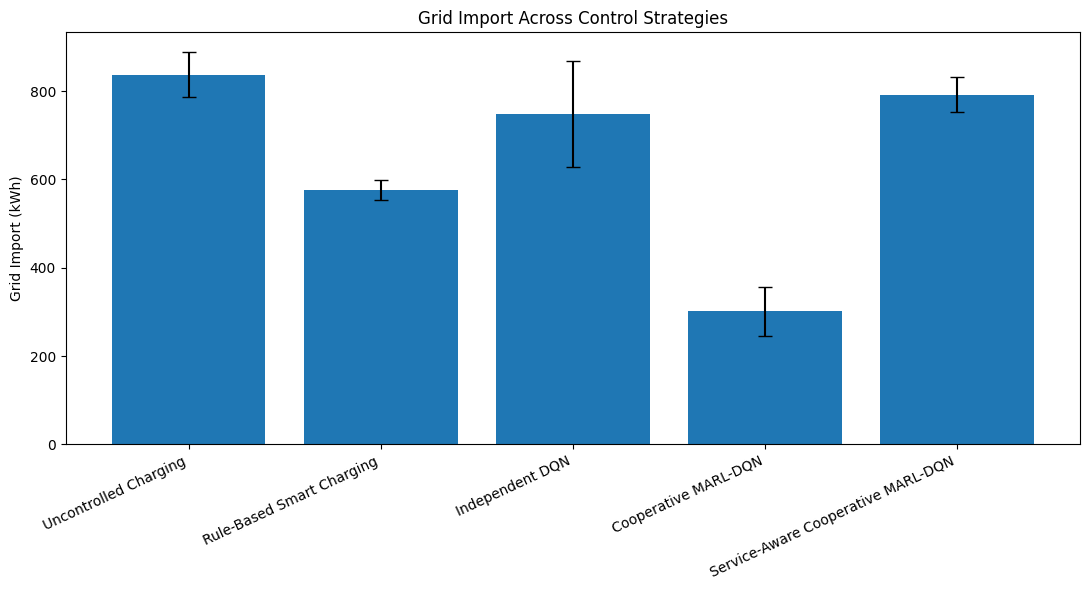

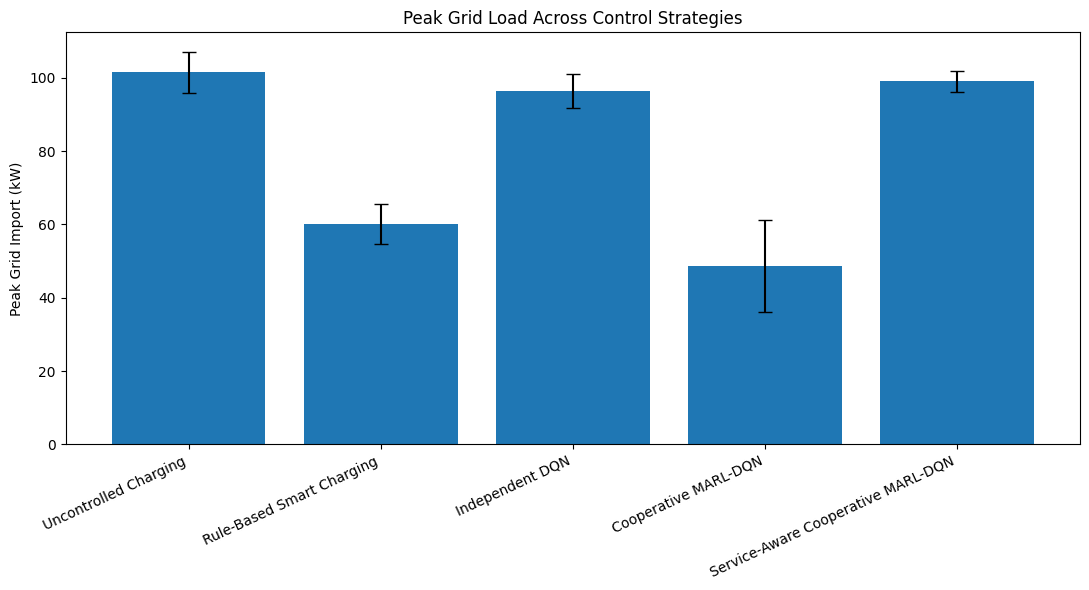

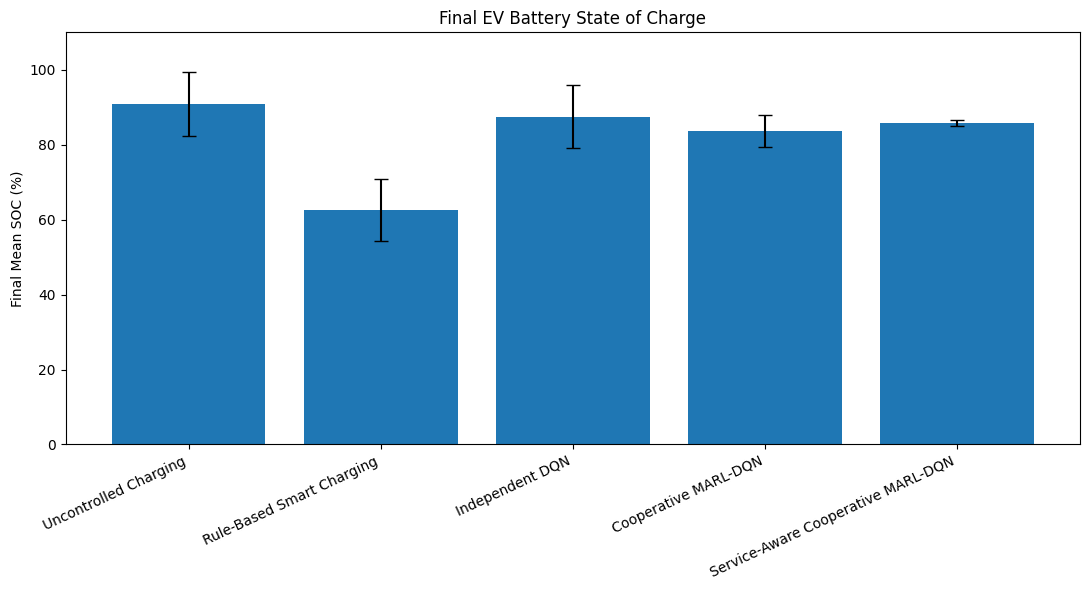

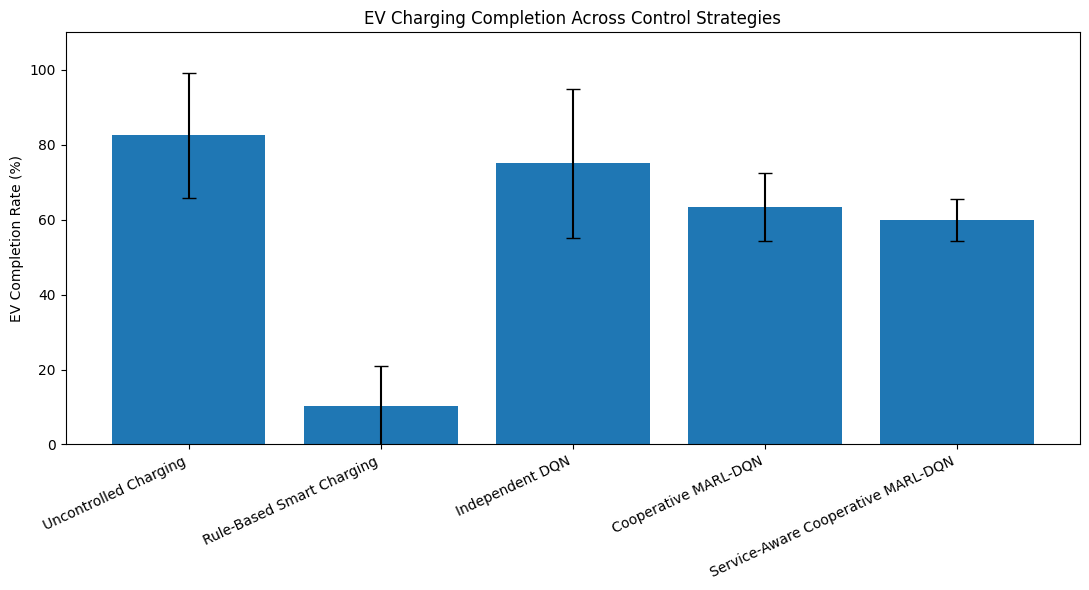

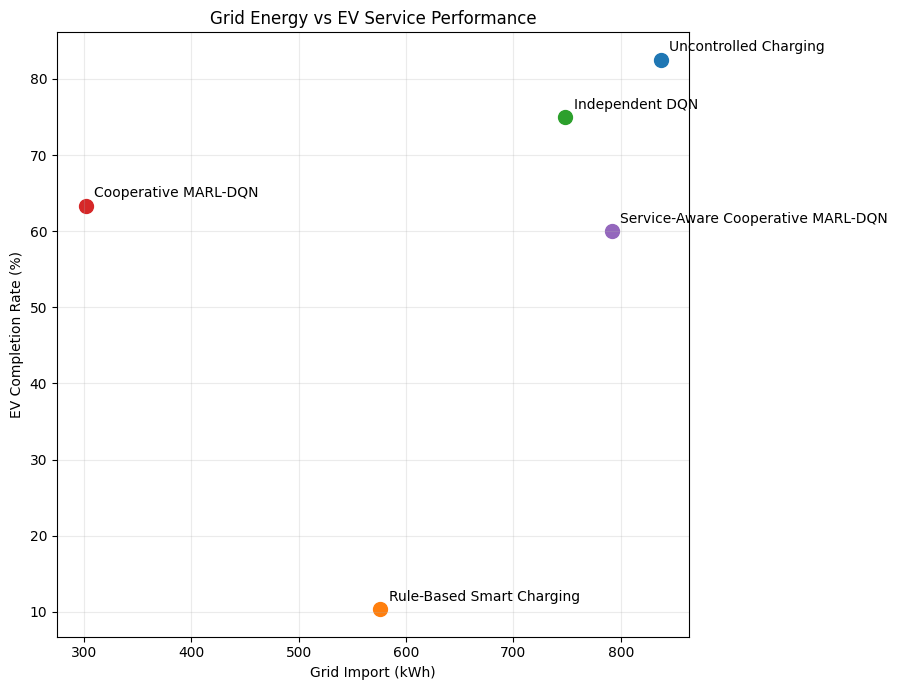

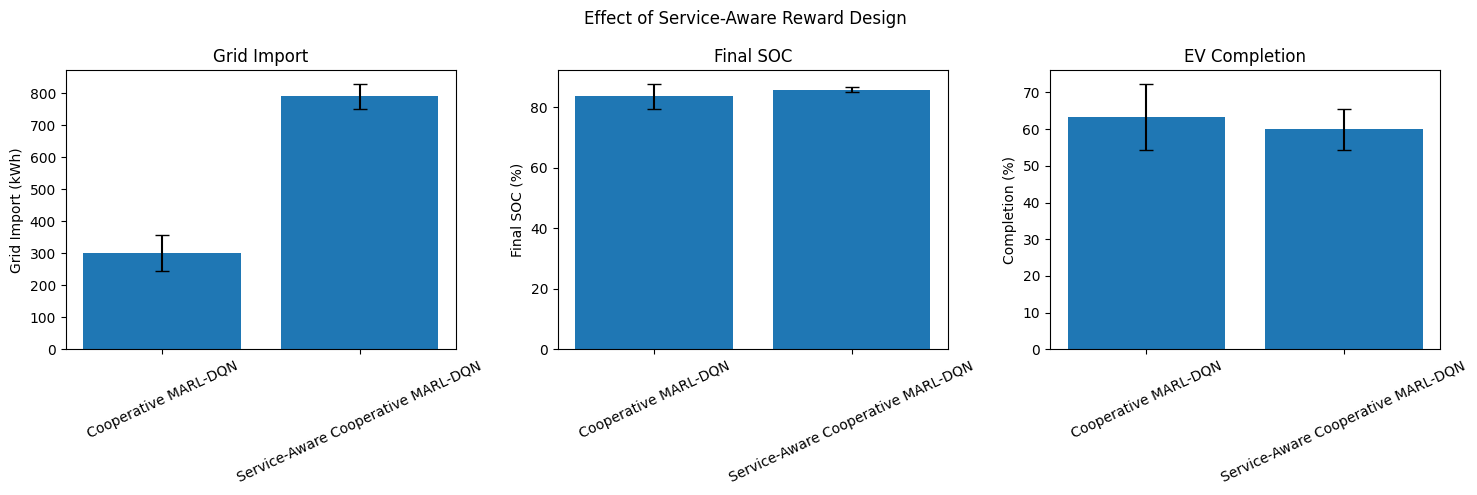


FINAL RESULTS FILES

Results:
/content/EV_MARL_Project/05_results/FINAL_RESULTS_MEAN_STD.csv
/content/EV_MARL_Project/05_results/FINAL_PAPER_TABLE.csv
/content/EV_MARL_Project/05_results/FINAL_PAPER_TABLE.tsv

Figures:
/content/EV_MARL_Project/06_figures/fig1_grid_import.png
/content/EV_MARL_Project/06_figures/fig2_peak_grid_load.png
/content/EV_MARL_Project/06_figures/fig3_final_soc.png
/content/EV_MARL_Project/06_figures/fig4_ev_completion.png
/content/EV_MARL_Project/06_figures/fig5_grid_vs_ev_service.png
/content/EV_MARL_Project/06_figures/fig6_reward_design_effect.png

BLOCK G COMPLETE


In [124]:
# ================================================================
# BLOCK G — FINAL FIGURES + PAPER-READY RESULTS PACKAGE
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

print("=" * 75)
print("BLOCK G — FINAL FIGURES + RESULTS PACKAGE")
print("=" * 75)

# Redefine project directory locally to prevent NameError if runtime restarted
PROJECT_DIR = "/content/EV_MARL_Project"

RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "05_results"
)

FIGURES_DIR = os.path.join(
    PROJECT_DIR,
    "06_figures"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

os.makedirs(
    FIGURES_DIR,
    exist_ok=True
)

csv_path = os.path.join(RESULTS_DIR, "final_multiseed_all_methods.csv")

# ----------------------------------------------------------------
# 0. RE-RUN EVALUATION IF RAW DATA IS MISSING
# ----------------------------------------------------------------
if not os.path.exists(csv_path):
    print("\n[INFO] 'final_multiseed_all_methods.csv' not found. Re-generating evaluation data...")

    # Fallback to local workspace check first before trying global __main__
    required_vars = [
        'uncontrolled_policy',
        'rule_based_policy',
        'independent_dqn_policy',
        'cooperative_marl_dqn_policy',
        'service_aware_marl_policy',
        'evaluate_multiseed_policy'
    ]

    missing_vars = [v for v in required_vars if v not in globals()]

    if missing_vars:
        print(f"Missing local variables: {missing_vars}. Attempting global import...")
        try:
            from __main__ import uncontrolled_policy, rule_based_policy, independent_dqn_policy, cooperative_marl_dqn_policy, service_aware_marl_policy, evaluate_multiseed_policy
        except ImportError:
            raise NameError("Please execute all preceding cells (specifically Blocks D, E, F1, and F2) first to register the models and policies in the current runtime namespace before running Block G.")

    F2_SEEDS = [0, 42, 123, 777, 2026]

    policies_to_run = [
        ("Uncontrolled Charging", uncontrolled_policy),
        ("Rule-Based Smart Charging", rule_based_policy),
        ("Independent DQN", independent_dqn_policy),
        ("Cooperative MARL-DQN", cooperative_marl_dqn_policy),
        ("Service-Aware Cooperative MARL-DQN", service_aware_marl_policy)
    ]

    all_validation_results = []
    for method_name, policy in policies_to_run:
        print(f"Evaluating {method_name} across seeds...")
        for seed in F2_SEEDS:
            result = evaluate_multiseed_policy(policy, seed, method_name)
            all_validation_results.append(result)

    final_raw = pd.DataFrame(all_validation_results)
    final_raw.to_csv(csv_path, index=False)
    print("\n[INFO] Evaluation completed and saved successfully!")
else:
    # ================================================================
    # 1. LOAD FINAL MULTI-SEED RESULTS
    # ================================================================
    final_raw = pd.read_csv(csv_path)
    print("\nLoaded existing raw data from:", csv_path)

print("\nMethods available for plotting:")
for method in final_raw["Method"].unique():
    print(" -", method)

# ================================================================
# 2. ORDER METHODS
# ================================================================

method_order = [
    "Uncontrolled Charging",
    "Rule-Based Smart Charging",
    "Independent DQN",
    "Cooperative MARL-DQN",
    "Service-Aware Cooperative MARL-DQN"
]

final_raw["Method"] = pd.Categorical(
    final_raw["Method"],
    categories=method_order,
    ordered=True
)

final_raw = final_raw.sort_values(
    ["Method", "Seed"]
)

# ================================================================
# 3. AGGREGATED FINAL TABLE
# ================================================================

metrics = [
    "Grid Import (kWh)",
    "Grid Export (kWh)",
    "Peak Grid Import (kW)",
    "PAR",
    "Charging Energy (kWh)",
    "Discharging Energy (kWh)",
    "Final Mean SOC",
    "EV Completion Rate",
    "Mean Connected EVs",
    "Mean SOC",
    "Total Reward"
]

summary = []

for method in method_order:
    subset = final_raw[final_raw["Method"] == method]
    if len(subset) == 0:
        continue

    row = {"Method": method}
    for metric in metrics:
        row[metric + " Mean"] = subset[metric].mean()
        row[metric + " Std"] = subset[metric].std(ddof=1)
    summary.append(row)

final_summary = pd.DataFrame(summary)

# ================================================================
# 4. PAPER TABLE
# ================================================================

paper_rows = []

for method in method_order:
    subset = final_raw[final_raw["Method"] == method]
    if len(subset) == 0:
        continue

    def fmt(column, multiplier=1.0, decimals=2):
        mean = subset[column].mean() * multiplier
        std = subset[column].std(ddof=1) * multiplier
        return f"{mean:.{decimals}f} ± {std:.{decimals}f}"

    paper_rows.append({
        "Method": method,
        "Grid Import (kWh)": fmt("Grid Import (kWh)"),
        "Peak Grid Load (kW)": fmt("Peak Grid Import (kW)"),
        "PAR": fmt("PAR", decimals=3),
        "Charging Energy (kWh)": fmt("Charging Energy (kWh)"),
        "Final SOC (%)": fmt("Final Mean SOC", multiplier=100),
        "EV Completion (%)": fmt("EV Completion Rate", multiplier=100)
    })

paper_results = pd.DataFrame(paper_rows)

print("\n" + "=" * 75)
print("FINAL PAPER TABLE")
print("=" * 75)
display(paper_results)

# ================================================================
# 5. FIGURE 1 — GRID IMPORT
# ================================================================

plot_df = final_summary.copy()
plt.figure(figsize=(11, 6))

x = np.arange(len(plot_df))
means = plot_df["Grid Import (kWh) Mean"].values
stds = plot_df["Grid Import (kWh) Std"].values

plt.bar(x, means, yerr=stds, capsize=5)
plt.xticks(x, plot_df["Method"], rotation=25, ha="right")
plt.ylabel("Grid Import (kWh)")
plt.title("Grid Import Across Control Strategies")
plt.tight_layout()

grid_import_fig = os.path.join(FIGURES_DIR, "fig1_grid_import.png")
plt.savefig(grid_import_fig, dpi=300, bbox_inches="tight")
plt.show()

# ================================================================
# 6. FIGURE 2 — PEAK GRID LOAD
# ================================================================

plt.figure(figsize=(11, 6))
means = plot_df["Peak Grid Import (kW) Mean"].values
stds = plot_df["Peak Grid Import (kW) Std"].values

plt.bar(x, means, yerr=stds, capsize=5)
plt.xticks(x, plot_df["Method"], rotation=25, ha="right")
plt.ylabel("Peak Grid Import (kW)")
plt.title("Peak Grid Load Across Control Strategies")
plt.tight_layout()

peak_fig = os.path.join(FIGURES_DIR, "fig2_peak_grid_load.png")
plt.savefig(peak_fig, dpi=300, bbox_inches="tight")
plt.show()

# ================================================================
# 7. FIGURE 3 — FINAL SOC
# ================================================================

plt.figure(figsize=(11, 6))
means = plot_df["Final Mean SOC Mean"].values * 100
stds = plot_df["Final Mean SOC Std"].values * 100

plt.bar(x, means, yerr=stds, capsize=5)
plt.xticks(x, plot_df["Method"], rotation=25, ha="right")
plt.ylabel("Final Mean SOC (%)")
plt.title("Final EV Battery State of Charge")
plt.ylim(0, 110)
plt.tight_layout()

soc_fig = os.path.join(FIGURES_DIR, "fig3_final_soc.png")
plt.savefig(soc_fig, dpi=300, bbox_inches="tight")
plt.show()

# ================================================================
# 8. FIGURE 4 — EV COMPLETION
# ================================================================

plt.figure(figsize=(11, 6))
means = plot_df["EV Completion Rate Mean"].values * 100
stds = plot_df["EV Completion Rate Std"].values * 100

plt.bar(x, means, yerr=stds, capsize=5)
plt.xticks(x, plot_df["Method"], rotation=25, ha="right")
plt.ylabel("EV Completion Rate (%)")
plt.title("EV Charging Completion Across Control Strategies")
plt.ylim(0, 110)
plt.tight_layout()

completion_fig = os.path.join(FIGURES_DIR, "fig4_ev_completion.png")
plt.savefig(completion_fig, dpi=300, bbox_inches="tight")
plt.show()

# ================================================================
# 9. FIGURE 5 — GRID IMPORT VS EV SERVICE
# ================================================================

plt.figure(figsize=(9, 7))
for _, row in plot_df.iterrows():
    x_value = row["Grid Import (kWh) Mean"]
    y_value = row["EV Completion Rate Mean"] * 100
    plt.scatter(x_value, y_value, s=100)
    plt.annotate(
        row["Method"],
        (x_value, y_value),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xlabel("Grid Import (kWh)")
plt.ylabel("EV Completion Rate (%)")
plt.title("Grid Energy vs EV Service Performance")
plt.grid(alpha=0.25)
plt.tight_layout()

tradeoff_fig = os.path.join(FIGURES_DIR, "fig5_grid_vs_ev_service.png")
plt.savefig(tradeoff_fig, dpi=300, bbox_inches="tight")
plt.show()

# ================================================================
# 10. FIGURE 6 — ORIGINAL VS SERVICE-AWARE MARL
# ================================================================

marl_methods = [
    "Cooperative MARL-DQN",
    "Service-Aware Cooperative MARL-DQN"
]
marl_df = final_summary[final_summary["Method"].isin(marl_methods)].copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Grid import
axes[0].bar(
    marl_df["Method"],
    marl_df["Grid Import (kWh) Mean"],
    yerr=marl_df["Grid Import (kWh) Std"],
    capsize=5
)
axes[0].set_ylabel("Grid Import (kWh)")
axes[0].set_title("Grid Import")
axes[0].tick_params(axis="x", rotation=25)

# SOC
axes[1].bar(
    marl_df["Method"],
    marl_df["Final Mean SOC Mean"] * 100,
    yerr=marl_df["Final Mean SOC Std"] * 100,
    capsize=5
)
axes[1].set_ylabel("Final SOC (%)")
axes[1].set_title("Final SOC")
axes[1].tick_params(axis="x", rotation=25)

# Completion
axes[2].bar(
    marl_df["Method"],
    marl_df["EV Completion Rate Mean"] * 100,
    yerr=marl_df["EV Completion Rate Std"] * 100,
    capsize=5
)
axes[2].set_ylabel("Completion (%)")
axes[2].set_title("EV Completion")
axes[2].tick_params(axis="x", rotation=25)

plt.suptitle("Effect of Service-Aware Reward Design")
plt.tight_layout()

reward_design_fig = os.path.join(FIGURES_DIR, "fig6_reward_design_effect.png")
plt.savefig(reward_design_fig, dpi=300, bbox_inches="tight")
plt.show()

# ================================================================
# 11. SAVE FINAL RESULTS
# ================================================================

final_summary.to_csv(
    os.path.join(RESULTS_DIR, "FINAL_RESULTS_MEAN_STD.csv"),
    index=False
)

paper_results.to_csv(
    os.path.join(RESULTS_DIR, "FINAL_PAPER_TABLE.csv"),
    index=False
)

paper_results.to_csv(
    os.path.join(RESULTS_DIR, "FINAL_PAPER_TABLE.tsv"),
    index=False,
    sep="\t"
)

# ================================================================
# 12. SAVE FIGURE INDEX
# ================================================================

figure_index = pd.DataFrame({
    "Figure": [
        "Figure 1",
        "Figure 2",
        "Figure 3",
        "Figure 4",
        "Figure 5",
        "Figure 6"
    ],
    "Description": [
        "Grid import comparison",
        "Peak grid load comparison",
        "Final EV SOC comparison",
        "EV charging completion comparison",
        "Grid import versus EV service performance",
        "Effect of service-aware reward design"
    ],
    "File": [
        grid_import_fig,
        peak_fig,
        soc_fig,
        completion_fig,
        tradeoff_fig,
        reward_design_fig
    ]
})

figure_index.to_csv(
    os.path.join(RESULTS_DIR, "FIGURE_INDEX.csv"),
    index=False
)

# ================================================================
# 13. FINAL FILE LIST
# ================================================================

print("\n" + "=" * 75)
print("FINAL RESULTS FILES")
print("=" * 75)

print("\nResults:")
print(os.path.join(RESULTS_DIR, "FINAL_RESULTS_MEAN_STD.csv"))
print(os.path.join(RESULTS_DIR, "FINAL_PAPER_TABLE.csv"))
print(os.path.join(RESULTS_DIR, "FINAL_PAPER_TABLE.tsv"))

print("\nFigures:")
for path in [
    grid_import_fig,
    peak_fig,
    soc_fig,
    completion_fig,
    tradeoff_fig,
    reward_design_fig
]:
    print(path)

print("\n" + "=" * 75)
print("BLOCK G COMPLETE")
print("=" * 75)